In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU available. Check Colab runtime settings.")

PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q transformers datasets peft trl bitsandbytes accelerate sentencepiece

In [ ]:
!nvidia-smi

Mon Nov 16 04:38:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P0             28W /   70W |    2245MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os

file_path = "/content/retrieval_corpus_initial.jsonl"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

File exists: True
File size: 2784.65 KB


In [ ]:
import json

file_path = "/content/retrieval_corpus_initial.jsonl"

records = []

with open(file_path, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

print("Total records:", len(records))

print("\nAvailable fields:")
print(records[0].keys())

print("\nFirst record:")
print(json.dumps(records[0], indent=2, ensure_ascii=False))

print("\nSubject distribution:")
from collections import Counter

subjects = Counter(record.get("subject") for record in records)
print(subjects)

Total records: 2632

Available fields:
dict_keys(['id', 'subject', 'grade', 'curriculum', 'source_file', 'page', 'chunk_index', 'text'])

First record:
{
  "id": "math_p002_c01",
  "subject": "Mathematics",
  "grade": 8,
  "curriculum": "Telangana State Board",
  "source_file": "Math.pdf",
  "page": 2,
  "chunk_index": 1,
  "text": "CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\nFor each and every conceptual understanding, a real life context with appropriate\nillustrations are given in the textbook. Try to understand the concept through keen\nreading of context along with observation of illustration.\n♦\nWhile understanding the concepts through activities, some doubts may arise.\nClarify those doubts by through discussion with your friends and teachers,\nunderstand the mathematical concepts without any doubts.\n♦\n''Do this/Do these\" exercises are given to test yourself, how far the concept has\nbeen understood. If you are facing any difficulty in solving problems in these\nexercises,

In [ ]:
from collections import Counter
import random

# Analyze text lengths
lengths = [len(record["text"]) for record in records]

print("Total chunks:", len(records))
print("Average characters:", round(sum(lengths) / len(lengths)))
print("Shortest chunk:", min(lengths))
print("Longest chunk:", max(lengths))

# Check empty or very short chunks
short_chunks = [
    r for r in records
    if len(r["text"].strip()) < 100
]

print("\nShort chunks:", len(short_chunks))

# Display 2 sample chunks from each subject
for subject in subjects:
    samples = [
        r for r in records
        if r["subject"] == subject
    ]

    print(f"\n{'='*50}")
    print("SUBJECT:", subject)

    for sample in random.sample(samples, min(2, len(samples))):
        print("\nPage:", sample["page"])
        print("Text:", sample["text"][:700])

Total chunks: 2632
Average characters: 870
Shortest chunk: 81
Longest chunk: 1100

Short chunks: 2

SUBJECT: Mathematics

Page: 143
Text: Square roots and Cube Roots
131
Free Distribution by T.S. Government 2018-19
6.5
Finding the Square root through subtraction of successive odd numbers:
We know that, every square number can be expressed as a sum of successive odd natural
numbers starting from 1.
Consider,
1 + 3
=
4
=
22
1 + 3 + 5
=
9
=
32
1 + 3 + 5 + 7
=
16 =
42
1 + 3 + 5 + 7 + 9
=
25 =
52
Finding square root is the reverse order of this pattern.
For example, find
49
Step 1:
49 – 1 = 48
(Subtracting of first odd number)
Step 2:
48 – 3 = 45
(Subtracting of 2nd odd number)
Step 3:
45 – 5 = 40
(Subtracting of 3rd odd number)
Step 4:
40 – 7 = 33
Step 5:
33 – 9 = 24
Step 6:
24 – 11 = 13
Step 7:
13 – 13 = 0
From 49, we have subtra

Page: 203
Text: A = 2
1 = 2 is called scale factor.
Do This
1.
Draw a triangle on a graph sheet and draw its dilation with scale factor 3. Are
those two figures

In [ ]:
import re
from collections import Counter

question_chunks = []

for record in records:
    text = record["text"].strip()

    if "?" in text:
        question_chunks.append(record)

print("Chunks containing question marks:", len(question_chunks))

print("\nSubject distribution:")
print(Counter(r["subject"] for r in question_chunks))

print("\nSample question-containing chunks:\n")

for record in question_chunks[:10]:
    print("=" * 70)
    print("Subject:", record["subject"])
    print("Page:", record["page"])
    print(record["text"][:700])
    print()

Chunks containing question marks: 1406

Subject distribution:
Counter({'Mathematics': 336, 'Social Studies': 328, 'Physical Sciences': 326, 'Biology': 272, 'English': 144})

Sample question-containing chunks:

Subject: Mathematics
Page: 10
(viii)
George Polya (1887 - 1985)
Over the years, many have thought about the question whether the art of
problem solving can be taught or is it a talent possessed by only a few?
An effective and definite answer was given by the late George Polya.
He maintained that the skill of problem solving can be taught.
Polya was born in Hungary in 1887 and received his Ph.D. in mathematics
from the University of Budapest. He taught for many years at the Swiss
Federal Institute of Technology in Zurich.
Among the numerous books that he wrote he seemed most proud of
‘How to Solve It’ (1945) which has sold nearly one million copies and
has been translated into 17 languages.
Polya’s Four principles of Prob

Subject: Mathematics
Page: 10
even in part.
Teachers shoul

In [ ]:
import re
from collections import Counter

question_candidates = []

for record in records:
    text = record["text"]

    # Extract sentences ending in question marks
    questions = re.findall(
        r'[^?]*\?',
        text
    )

    for q in questions:
        q = " ".join(q.split()).strip()

        if len(q) >= 15:
            question_candidates.append({
                "subject": record["subject"],
                "page": record["page"],
                "question": q,
                "context": text
            })

print("Extracted question candidates:", len(question_candidates))

print("\nSubject distribution:")
print(Counter(q["subject"] for q in question_candidates))

print("\nSample questions:")

for item in question_candidates[:25]:
    print("-" * 60)
    print("Subject:", item["subject"])
    print("Page:", item["page"])
    print("Question:", item["question"][:300])

Extracted question candidates: 3852

Subject distribution:
Counter({'Physical Sciences': 1034, 'Social Studies': 821, 'Biology': 798, 'Mathematics': 761, 'English': 438})

Sample questions:
------------------------------------------------------------
Subject: Mathematics
Page: 10
Question: (viii) George Polya (1887 - 1985) Over the years, many have thought about the question whether the art of problem solving can be taught or is it a talent possessed by only a few?
------------------------------------------------------------
Subject: Mathematics
Page: 10
Question: An effective and definite answer was given by the late George Polya. He maintained that the skill of problem solving can be taught. Polya was born in Hungary in 1887 and received his Ph.D. in mathematics from the University of Budapest. He taught for many years at the Swiss Federal Institute of Tech
------------------------------------------------------------
Subject: Mathematics
Page: 10
Question: even in part. Teachers shou

In [ ]:
import re
from collections import Counter

clean_candidates = []

for record in records:
    text = record["text"]

    # Find each question mark
    positions = [m.start() for m in re.finditer(r"\?", text)]

    for pos in positions:
        # Keep nearby text as context
        start = max(0, pos - 300)
        end = min(len(text), pos + 1)

        snippet = text[start:end].strip()
        snippet = " ".join(snippet.split())

        clean_candidates.append({
            "subject": record["subject"],
            "page": record["page"],
            "question_context": snippet,
            "full_text": text
        })

print("Question candidates:", len(clean_candidates))
print("\nSubject distribution:")
print(Counter(x["subject"] for x in clean_candidates))

print("\nSample candidates:")

for item in clean_candidates[:20]:
    print("-" * 60)
    print("Subject:", item["subject"])
    print("Page:", item["page"])
    print("Context:", item["question_context"])

Question candidates: 4025

Subject distribution:
Counter({'Physical Sciences': 1093, 'Social Studies': 852, 'Biology': 834, 'Mathematics': 785, 'English': 461})

Sample candidates:
------------------------------------------------------------
Subject: Mathematics
Page: 10
Context: (viii) George Polya (1887 - 1985) Over the years, many have thought about the question whether the art of problem solving can be taught or is it a talent possessed by only a few?
------------------------------------------------------------
Subject: Mathematics
Page: 10
Context: This principle seems so obvious that it need not be mentioned. However students are often stymied in their efforts to solve a problem because they don’t understand it fully or even in part. Teachers should ask students such questions as G Do you understand all the words used in stating the problems?
------------------------------------------------------------
Subject: Mathematics
Page: 10
Context: even in part. Teachers should ask stude

In [ ]:
import re
from collections import Counter

line_candidates = []

for record in records:
    lines = record["text"].splitlines()

    for line in lines:
        line = " ".join(line.split()).strip()

        if (
            line.endswith("?")
            and 15 <= len(line) <= 250
        ):
            line_candidates.append({
                "subject": record["subject"],
                "page": record["page"],
                "question": line,
                "context": record["text"]
            })

print("Clean line candidates:", len(line_candidates))

print("\nSubject distribution:")
print(Counter(x["subject"] for x in line_candidates))

print("\nSample candidates:")

for item in line_candidates[:30]:
    print("-" * 60)
    print("Subject:", item["subject"])
    print("Page:", item["page"])
    print("Question:", item["question"])

Clean line candidates: 2025

Subject distribution:
Counter({'Physical Sciences': 495, 'Mathematics': 479, 'Social Studies': 459, 'Biology': 337, 'English': 255})

Sample candidates:
------------------------------------------------------------
Subject: Mathematics
Page: 10
Question: problem solving can be taught or is it a talent possessed by only a few?
------------------------------------------------------------
Subject: Mathematics
Page: 13
Question: represent this?
------------------------------------------------------------
Subject: Mathematics
Page: 13
Question: In each case what is the change in temperature per hour?
------------------------------------------------------------
Subject: Mathematics
Page: 14
Question: Would you leave out any of the given numbers from rational numbers?
------------------------------------------------------------
Subject: Mathematics
Page: 14
Question: Is every natural number, whole number and integer a rational number ?
-----------------------------

In [ ]:
keywords = [
    "photosynthesis",
    "ecosystem",
    "cell",
    "microorganisms",
    "friction",
    "vibration",
    "sound",
    "force"
]

for keyword in keywords:
    matches = [
        r for r in records
        if keyword.lower() in r["text"].lower()
    ]

    print("\n" + "=" * 60)
    print("KEYWORD:", keyword)
    print("Matching chunks:", len(matches))

    for r in matches[:2]:
        print("\nSubject:", r["subject"])
        print("Page:", r["page"])
        print("Text:", r["text"][:600])


KEYWORD: photosynthesis
Matching chunks: 8

Subject: Biology
Page: 32
Text: Cell - The Basic Unit of Life
20
Fig-9(b) : Amoeba
Fig-9 : Unicellular organisms
Fig-9(c) : Escherichia coli (Bacteria)
Nucleus
Pseudopodia
Fig-10 : Cells in a grass blade
Fig-11 : Transverse Section of Dicot Stem
(Tridax)
Observe the given diagram of a section
of the stem of Tridax/Spinach. Note the
different types of cells that you observe in
the section. Fig-11 shows 4 different
groups of cells as described below:
Group A cells form the outermost
layer of the stem and they give shape to the
stem as well as protection.
Major portion of stem is made up of
group B cells. In a green stem this p

Subject: Biology
Page: 44
Text: water or water from
the tanks with a bit of greenish scraping.
To observe some of the microalgae
growing in water, let us do the following
activity.
Activity-4
Select a few strands (green string like
bodies) from water sample collected and
put them on a slide. Cover it with a cover
slip a

In [ ]:
# Find relevant Physical Sciences passages

keywords = [
    "vibration",
    "vibrating",
    "mean position",
    "amplitude"
]

for record in records:
    if record["subject"] != "Physical Sciences":
        continue

    text = record["text"]
    lower_text = text.lower()

    if any(word in lower_text for word in keywords):
        if "index" not in lower_text[:100]:
            print("\n" + "=" * 70)
            print("Page:", record["page"])
            print(text)


Page: 78
66
Sound
Table 2
S.No. Sound heard
way of producing Sound
1.
Gala Gala
A few stones rattling in a metal box
2.
Eela (whistling sound)
A student has produced the sound
from her/his mouth
3
Some one striking the table tab with a
scale
4
Someone thumping the ground with
shoes
5
6
z Is there any change in the sound
produced in the two situations?
How do you feel when you touch the
ringing bell? Remove your hand and ring
it again. Do you hear a different sound?
Why?
Fig-1: Observing vibrations of bell when it
is producing sound
z How does the student at the black board
guess the source of sound without
actually seeing the source?
You might have observed many other
sources of sound in your daily life. Try to
listen and identify some more sources of
sound and prepare a list.
z How do objects produce sound?
z What happens when objects made of
metals are hit by a hammer or fall down
from a height on a concrete floor?
z How does a flute or a whistle produce
sound?
z What would you feel

In [ ]:
import json

training_data = [
    {
        "subject": "Physical Sciences",
        "marks": 2,
        "source_page": 88,
        "instruction": "Answer the following question for 2 marks.",
        "input": "What is one vibration?",
        "output": "The to and fro motion of a body from its mean position is known as one vibration."
    },
    {
        "subject": "Physical Sciences",
        "marks": 2,
        "source_page": 88,
        "instruction": "Answer the following question for 2 marks.",
        "input": "Define amplitude.",
        "output": "The maximum displacement of a vibrating body from its mean position is called amplitude."
    },
    {
        "subject": "Physical Sciences",
        "marks": 2,
        "source_page": 90,
        "instruction": "Answer the following question for 2 marks.",
        "input": "What is frequency?",
        "output": "The number of vibrations per second is called frequency."
    },
    {
        "subject": "Physical Sciences",
        "marks": 2,
        "source_page": 90,
        "instruction": "Answer the following question for 2 marks.",
        "input": "What is pitch?",
        "output": "The shrillness of a sound is known as pitch."
    },
    {
        "subject": "Physical Sciences",
        "marks": 2,
        "source_page": 89,
        "instruction": "Answer the following question for 2 marks.",
        "input": "What is the unit used to measure sound intensity?",
        "output": "Decibel is the unit used to measure the intensity of sound. It is denoted as dB."
    },
    {
        "subject": "Physical Sciences",
        "marks": 4,
        "source_page": 79,
        "instruction": "Answer the following question for 4 marks.",
        "input": "Explain how a vibrating body produces sound.",
        "output": "Objects vibrate while producing sound. This can be observed by plucking a rubber band, striking a plate with a spoon, or vibrating a hacksaw blade. The vibrations can be felt by touching the objects. These observations show that a vibrating body produces sound."
    }
]

with open("/content/grade8_training_pilot.jsonl", "w", encoding="utf-8") as f:
    for item in training_data:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Examples:", len(training_data))
print("Subjects:", set(x["subject"] for x in training_data))
print("Mark distribution:")

from collections import Counter
print(Counter(x["marks"] for x in training_data))


Examples: 6
Subjects: {'Physical Sciences'}
Mark distribution:
Counter({2: 5, 4: 1})


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 2,
    "source_page": 88,
    "instruction": "Answer the student's question using only the supplied Telangana Class 8 textbook context.",
    "question": "What is amplitude?",
    "context": """
The initial position of the scale at rest along the surface
of the table is called mean position.

The maximum displacement of vibrating body from its
mean position is called amplitude.

In the picture, the maximum displacement is A to B or A to C.
""",
    "answer": "Amplitude is the maximum displacement of a vibrating body from its mean position."
}

with open("/content/grade8_context_pilot.jsonl", "w", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Training example created successfully!")
print("Subject:", example["subject"])
print("Marks:", example["marks"])
print("Source page:", example["source_page"])

Training example created successfully!
Subject: Physical Sciences
Marks: 2
Source page: 88


In [ ]:
import json

with open("/content/grade8_context_pilot.jsonl", "r", encoding="utf-8") as f:
    data = json.loads(f.readline())

print(json.dumps(data, indent=2, ensure_ascii=False))

{
  "subject": "Physical Sciences",
  "marks": 2,
  "source_page": 88,
  "instruction": "Answer the student's question using only the supplied Telangana Class 8 textbook context.",
  "question": "What is amplitude?",
  "context": "\nThe initial position of the scale at rest along the surface\nof the table is called mean position.\n\nThe maximum displacement of vibrating body from its\nmean position is called amplitude.\n\nIn the picture, the maximum displacement is A to B or A to C.\n",
  "answer": "Amplitude is the maximum displacement of a vibrating body from its mean position."
}


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 4,
    "source_page": 88,
    "instruction": "Answer the student's question using only the supplied Telangana Class 8 textbook context. Give a clear, well-explained 4-mark answer without repeating points.",
    "question": "Explain amplitude in a vibrating body.",
    "context": """
The initial position of the scale at rest along the surface
of the table is called mean position.

The maximum displacement of vibrating body from its
mean position is called amplitude.

In the picture, the maximum displacement is A to B or A to C.
""",
    "answer": """Amplitude is the maximum displacement of a vibrating body from its mean position.

When a body vibrates, it moves to and fro from its mean position. The greatest distance it moves from the mean position is called amplitude. In the given example, the maximum displacement is from A to B or from A to C."""
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("4-mark example added successfully!")

4-mark example added successfully!


In [ ]:
import json
from collections import Counter

file_path = "/content/grade8_context_pilot.jsonl"

with open(file_path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subjects:", Counter(x["subject"] for x in examples))

Total examples: 2
Mark distribution: Counter({2: 1, 4: 1})
Subjects: Counter({'Physical Sciences': 2})


In [ ]:
import json

path = "/content/retrieval_corpus_initial.jsonl"

keywords = ["sound", "vibration", "amplitude", "frequency"]

with open(path, "r", encoding="utf-8") as f:
    for line in f:
        item = json.loads(line)
        if item.get("subject") == "Physical Sciences":
            text = item.get("text", "")
            if any(word in text.lower() for word in keywords):
                print("\nPAGE:", item.get("page"))
                print(text)
                print("-" * 60)


PAGE: 11
ix
Telangana Government Free Distribution 2020-21
12 Graphs of motion
1
INDEX
INDEX
INDEX
INDEX
INDEX
2
3
4
5
6
7
8
9
10
Page No.
Periods
Month
Force
Friction
Synthetic fibres and plastics
Metals and non-metals
Reflection of light at plane surfaces
Coal and petroleum
Combustion, fuels and flame
Electric conductivity of liquids
Some natural phenomena
Sound
11 Stars and solar system
Revision
8
June
1
8
July
19
11
July
32
12
August
52
12
August
65
6
September
83
12
October
93
10
November
107
11
November
119
11
December
131
13
January
147
4
February
171
March
SCERT TELANGANA
------------------------------------------------------------

PAGE: 46
34
Synthetic Fibres and Plastics
a days Nylon replaced silk in most hosiery
articles such as stockings.
How is nylon made?
Nylon is a polymer made of chemical
units called polyamides. Polyamides are
made with monomers, hexamethylene
diamine and adipic acid. Solid chips of
these polyamides are melted and forced
through a heated spinneret wh

In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 8,
    "source_page": "86-87",
    "instruction": "Answer the student's question using only the supplied Telangana Class 8 textbook context. Give a detailed, well-organized 8-mark answer. Avoid repetition.",
    "question": "Explain how we hear sound.",
    "context": """
Our ear consists of three sections: the outer ear,
the middle ear and the inner ear.

The pinna of the external ear collects sound vibrations.
These vibrations enter the ear canal and strike the
tympanum (ear-drum), making it vibrate.

The vibrations from the tympanic membrane reach
the middle ear (ear ossicles), which contains three
small bones: malleus (hammer shaped), incus
(anvil shaped) and stapes (stirrup shaped).
They magnify the sound vibrations.

The stapes transmits the vibrations to the membrane
of the oval window. The vibrations from the oval
window travel to the cochlea, which is the inner
part of the ear. The cochlea is filled with thick fluids
which transmit the vibrations.

The motion of vibrations in the cochlea is detected
by tiny hairs connected to nerves. The vibrations
are transformed into electrical signals and carried
by the nerves to the brain, where the sensation of
sound is realized.
""",
    "answer": """We hear sounds produced in our surroundings with the help of our ears. Our ear consists of three sections: the outer ear, the middle ear and the inner ear.

The process of hearing takes place as follows:

1. The pinna of the external ear collects sound vibrations.
2. These vibrations enter the ear canal and strike the tympanum (ear-drum), making it vibrate.
3. The vibrations reach the middle ear, which contains three small bones called ear ossicles: malleus, incus and stapes.
4. These three bones magnify the sound vibrations.
5. The stapes transmits the vibrations to the membrane of the oval window.
6. The vibrations then travel to the cochlea, which is the inner part of the ear and is filled with thick fluids.
7. Tiny hairs connected to nerves detect the motion of vibrations in the cochlea.
8. These vibrations are transformed into electrical signals and carried by nerves to the brain, where the sensation of sound is realized.

Thus, our ears receive sound vibrations and transmit signals to the brain, enabling us to hear sounds."""
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("8-mark example added successfully!")

8-mark example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subjects:", Counter(x["subject"] for x in examples))

for i, x in enumerate(examples, 1):
    print(f"\nExample {i}")
    print("Question:", x["question"])
    print("Marks:", x["marks"])
    print("Answer length:", len(x["answer"].split()), "words")

Total examples: 3
Mark distribution: Counter({2: 1, 4: 1, 8: 1})
Subjects: Counter({'Physical Sciences': 3})

Example 1
Question: What is amplitude?
Marks: 2
Answer length: 13 words

Example 2
Question: Explain amplitude in a vibrating body.
Marks: 4
Answer length: 55 words

Example 3
Question: Explain how we hear sound.
Marks: 8
Answer length: 177 words


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 4,
    "source_page": "84-86",
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a clear 4-mark answer without repetition.",
    "question": "Explain how sound travels through different media.",
    "context": """
Sound needs a medium to propagate.

Sound travels through the air present between
the source of sound and our ears.

Activities demonstrate that sound travels through
solid materials such as wood, metal and thread.

Sound also propagates through liquids.

Thus, sound propagates through matter in all
three states: solid, liquid and gas.

Sound does not propagate through vacuum.
""",
    "answer": """Sound needs a medium to propagate from one place to another.

1. **Through gases:** Sound travels through air, which acts as a medium between the source and our ears.
2. **Through solids:** Sound travels through solid materials such as wood, metal and thread.
3. **Through liquids:** Sound can also travel through liquids, as demonstrated by striking two stones under water.

Thus, sound travels through all three states of matter: solids, liquids and gases. However, sound cannot travel through vacuum."""
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("New 4-mark example added successfully!")

New 4-mark example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))

print("\nQuestions:")
for i, item in enumerate(examples, 1):
    print(f"{i}. [{item['marks']} marks] {item['question']}")

Total examples: 4
Mark distribution: Counter({4: 2, 2: 1, 8: 1})

Questions:
1. [2 marks] What is amplitude?
2. [4 marks] Explain amplitude in a vibrating body.
3. [8 marks] Explain how we hear sound.
4. [4 marks] Explain how sound travels through different media.


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 2,
    "source_page": 90,
    "instruction": "Answer the student's question using only the supplied Telangana Class 8 textbook context. Give a concise 2-mark answer.",
    "question": "What is frequency?",
    "context": """
The number of vibrations per second (vib/sec)
is called frequency.

The pitch of the sound depends upon its frequency.
""",
    "answer": "Frequency is the number of vibrations produced per second. It is expressed in vibrations per second (vib/sec)."
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Frequency example added successfully!")

Frequency example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subjects:", Counter(x["subject"] for x in examples))

print("\nLatest example:")
print("Question:", examples[-1]["question"])
print("Answer:", examples[-1]["answer"])

Total examples: 5
Mark distribution: Counter({2: 2, 4: 2, 8: 1})
Subjects: Counter({'Physical Sciences': 5})

Latest example:
Question: What is frequency?
Answer: Frequency is the number of vibrations produced per second. It is expressed in vibrations per second (vib/sec).


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 2,
    "source_page": 90,
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a concise 2-mark answer.",
    "question": "What is pitch?",
    "context": """
The shrillness of a sound is known as pitch.
The pitch of the sound depends upon its frequency.
""",
    "answer": "Pitch is the shrillness of a sound. It depends upon the frequency of the sound."
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Pitch example added successfully!")

Pitch example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subject distribution:", Counter(x["subject"] for x in examples))

print("\nAll questions:")
for i, item in enumerate(examples, 1):
    print(f"{i}. [{item['marks']} marks] {item['question']}")

Total examples: 6
Mark distribution: Counter({2: 3, 4: 2, 8: 1})
Subject distribution: Counter({'Physical Sciences': 6})

All questions:
1. [2 marks] What is amplitude?
2. [4 marks] Explain amplitude in a vibrating body.
3. [8 marks] Explain how we hear sound.
4. [4 marks] Explain how sound travels through different media.
5. [2 marks] What is frequency?
6. [2 marks] What is pitch?


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 4,
    "source_page": 91,
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a clear 4-mark answer without repetition.",
    "question": "Differentiate between noise and music.",
    "context": """
The sounds which are pleasant to hear are called music.
The sounds which are not pleasant to hear are called noise.

Noise is an irregular combination of sounds which are
unpleasant to hear.

Music is a combination of sounds that are produced
in an order and pleasant to hear.
""",
    "answer": """Noise and music are two types of sounds.

1. **Noise:** Noise is an irregular combination of sounds that are unpleasant to hear. Example: The sound produced when a steel plate is dropped on the floor.
2. **Music:** Music is a combination of sounds produced in an order and pleasant to hear. Example: Songs played at a music concert.

Thus, noise is unpleasant to hear, whereas music is pleasant to hear."""
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Noise and Music example added successfully!")

Noise and Music example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subject distribution:", Counter(x["subject"] for x in examples))

print("\nAll questions:")
for i, item in enumerate(examples, 1):
    print(f"{i}. [{item['marks']} marks] {item['question']}")

Total examples: 7
Mark distribution: Counter({2: 3, 4: 3, 8: 1})
Subject distribution: Counter({'Physical Sciences': 7})

All questions:
1. [2 marks] What is amplitude?
2. [4 marks] Explain amplitude in a vibrating body.
3. [8 marks] Explain how we hear sound.
4. [4 marks] Explain how sound travels through different media.
5. [2 marks] What is frequency?
6. [2 marks] What is pitch?
7. [4 marks] Differentiate between noise and music.


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 2,
    "source_page": 89,
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a concise 2-mark answer.",
    "question": "What is a decibel?",
    "context": """
The unit used to measure the intensity of sound is decibel.
It is denoted by dB.
""",
    "answer": "Decibel is the unit used to measure the intensity of sound. It is denoted by dB."
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Decibel example added successfully!")

Decibel example added successfully!


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 8,
    "source_page": "79, 84-86",
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a well-organised 8-mark answer without repetition.",
    "question": "Explain how sound is produced and propagated through a medium.",
    "context": """
Objects vibrate while they are producing sound. A vibrating body produces sound.

Sound needs a medium to travel. It can travel through solids, liquids and gases.
Sound cannot travel through vacuum.
""",
    "answer": """Sound is produced by vibrating bodies. When an object vibrates, it produces sound.

Sound travels from one place to another through a medium. The medium may be a solid, liquid or gas.

1. **Solids:** Sound can travel through solid materials.
2. **Liquids:** Sound can also travel through liquids.
3. **Gases:** Sound travels through gases such as air.
4. **Vacuum:** Sound cannot travel through vacuum because it needs a medium.

Thus, a vibrating body produces sound, and sound can travel through solids, liquids and gases, but not through vacuum."""
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("8-mark example added successfully!")

8-mark example added successfully!


In [ ]:
import json
from collections import Counter

path = "/content/grade8_context_pilot.jsonl"

with open(path, "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f if line.strip()]

print("Total examples:", len(examples))
print("Mark distribution:", Counter(x["marks"] for x in examples))
print("Subject distribution:", Counter(x["subject"] for x in examples))

Total examples: 9
Mark distribution: Counter({2: 4, 4: 3, 8: 2})
Subject distribution: Counter({'Physical Sciences': 9})


In [ ]:
import json

example = {
    "subject": "Physical Sciences",
    "marks": 2,
    "source_page": 93,
    "instruction": "Answer using only the supplied Telangana Class 8 textbook context. Give a concise 2-mark answer.",
    "question": "What determines the loudness and feebleness of a sound?",
    "context": """
Loudness and feebleness of a sound are determined by
the amplitude of vibration.
""",
    "answer": "The loudness and feebleness of a sound are determined by the amplitude of vibration."
}

with open("/content/grade8_context_pilot.jsonl", "a", encoding="utf-8") as f:
    f.write(json.dumps(example, ensure_ascii=False) + "\n")

print("Example added successfully!")

Example added successfully!


In [ ]:
import torch
import transformers
import datasets
import peft
import bitsandbytes
import trl

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Datasets: 4.8.5
PEFT: 0.21.2
TRL: 1.18.0
GPU: Tesla T4
CUDA available: True


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# 4-bit quantization configuration
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

# Load quantized model
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    dtype=torch.float16,
    device_map={"": 0}
)

model.config.use_cache = False

print("Model loaded successfully!")
print("Model:", MODEL_ID)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory used:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Model loaded successfully!
Model: Qwen/Qwen2.5-1.5B-Instruct
GPU: Tesla T4
GPU memory used: 1.72 GB


In [ ]:
from peft import prepare_model_for_kbit_training

model.gradient_checkpointing_enable()

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

print("Model prepared for QLoRA training!")

Model prepared for QLoRA training!


In [ ]:
from peft import LoraConfig, get_peft_model, TaskType

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ],
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "json",
    data_files="/content/grade8_context_pilot.jsonl",
    split="train"
)

print(dataset)
print("\nFirst training example:")
print(dataset[0])

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['subject', 'marks', 'source_page', 'instruction', 'question', 'context', 'answer'],
    num_rows: 10
})

First training example:
{'subject': 'Physical Sciences', 'marks': 2, 'source_page': 88, 'instruction': "Answer the student's question using only the supplied Telangana Class 8 textbook context.", 'question': 'What is amplitude?', 'context': '\nThe initial position of the scale at rest along the surface\nof the table is called mean position.\n\nThe maximum displacement of vibrating body from its\nmean position is called amplitude.\n\nIn the picture, the maximum displacement is A to B or A to C.\n', 'answer': 'Amplitude is the maximum displacement of a vibrating body from its mean position.'}


In [ ]:
def format_example(example):
    messages = [
        {
            "role": "system",
            "content": (
                "You are a Telangana Class 8 textbook AI tutor. "
                "Answer using only the supplied textbook context. "
                "Do not invent facts or repeat information."
            )
        },
        {
            "role": "user",
            "content": (
                f"Subject: {example['subject']}\n"
                f"Marks: {example['marks']}\n"
                f"Question: {example['question']}\n"
                f"Textbook context:\n{example['context']}\n"
                f"Instruction: {example['instruction']}"
            )
        },
        {
            "role": "assistant",
            "content": example["answer"]
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

formatted_text = format_example(dataset[0])

print(formatted_text)

<|im_start|>system
You are a Telangana Class 8 textbook AI tutor. Answer using only the supplied textbook context. Do not invent facts or repeat information.<|im_end|>
<|im_start|>user
Subject: Physical Sciences
Marks: 2
Question: What is amplitude?
Textbook context:

The initial position of the scale at rest along the surface
of the table is called mean position.

The maximum displacement of vibrating body from its
mean position is called amplitude.

In the picture, the maximum displacement is A to B or A to C.

Instruction: Answer the student's question using only the supplied Telangana Class 8 textbook context.<|im_end|>
<|im_start|>assistant
Amplitude is the maximum displacement of a vibrating body from its mean position.<|im_end|>



In [ ]:
import json
import torch
import random

corpus_path = "/content/retrieval_corpus_initial.jsonl"

with open(corpus_path, "r", encoding="utf-8") as f:
    corpus = [json.loads(line) for line in f if line.strip()]

# Select 5 chunks from different subjects
subjects = list(set(x["subject"] for x in corpus))
selected = []

for subject in subjects:
    matches = [x for x in corpus if x["subject"] == subject]
    if matches and len(selected) < 5:
        selected.append(random.choice(matches))

print("Selected textbook chunks:", len(selected))
print("Subjects:", [x["subject"] for x in selected])

Selected textbook chunks: 5
Subjects: ['Physical Sciences', 'English', 'Biology', 'Mathematics', 'Social Studies']


In [ ]:
import json
import torch

generated_candidates = []

for i, item in enumerate(selected, 1):

    subject = item["subject"]
    context = item["text"]

    prompt = f"""
You are an expert Telangana Class 8 textbook question setter.

Use ONLY the textbook passage below.

SUBJECT: {subject}

TEXTBOOK PASSAGE:
{context}

Generate up to three exam questions:
1. One 2-mark question with a concise answer.
2. One 4-mark question with an explained answer.
3. One 8-mark question with a detailed answer.

Rules:
- Use only facts supported by the passage.
- Do not invent information.
- Do not repeat points.
- Skip questions that cannot be answered from the passage.
- Preserve textbook terminology.
- Return valid JSON only:

{{
  "questions": [
    {{
      "marks": 2,
      "question": "...",
      "answer": "..."
    }}
  ]
}}
"""

    messages = [{"role": "user", "content": prompt}]

    # Create chat prompt
    chat_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # Convert prompt into PyTorch tensors
    inputs = tokenizer(
        chat_text,
        return_tensors="pt"
    ).to("cuda")

    input_length = inputs["input_ids"].shape[-1]

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=700,
            do_sample=True,
            temperature=0.3,
            top_p=0.85,
            pad_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

    generated_candidates.append({
        "subject": subject,
        "source_page": item.get("page"),
        "context": context,
        "raw_response": response
    })

    print(f"\nSubject {i}/5: {subject}")
    print(response)

print("\nTotal generated:", len(generated_candidates))


Subject 1/5: Physical Sciences
```json
{
  "questions": [
    {
      "marks": 2,
      "question": "What are the names of the states mentioned in the Pledge?",
      "answer": ["Punjab", "Sindh", "Gujarat", "Maratha"]
    },
    {
      "marks": 4,
      "question": "List the rivers mentioned in the Anthem and explain what they represent.",
      "answer": [
        "The rivers mentioned in the Anthem are Vindhya, Himachala, Yamuna, and Ganga.",
        "These rivers symbolize India's geographical diversity and cultural richness."
      ]
    },
    {
      "marks": 8,
      "question": "Describe the meaning and significance of the Anthem verses 'Jana-gana-mangala-dayaka jaya he' and 'Tava shubha name jage'.",
      "answer": [
        "The verse 'Jana-gana-mangala-dayaka jaya he' means 'May Jaya (the victorious one) reign forever', emphasizing India's sovereignty and glory.",
        "The verse 'Tava shubha name jage' means 'Let your noble name be known', encouraging individuals to 

#maths

In [ ]:

!pip install -q pymupdf

import pymupdf
import json
import os

PDF_PATH = "/content/Math.pdf"
OUTPUT_PATH = "/content/mathematics_raw.jsonl"

# Open the textbook
doc = pymupdf.open(PDF_PATH)

records = []

for page_num, page in enumerate(doc, start=1):
    text = page.get_text("text").strip()

    if not text:
        continue

    records.append({
        "subject": "Mathematics",
        "grade": 8,
        "source_file": "Math(1).pdf",
        "page": page_num,
        "text": text
    })

# Save page-wise extracted content
with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Total PDF pages:", len(doc))
print("Pages with extracted text:", len(records))
print("Output saved:", OUTPUT_PATH)


Total PDF pages: 370
Pages with extracted text: 370
Output saved: /content/mathematics_raw.jsonl


In [ ]:

with open("/content/mathematics_raw.jsonl", "r", encoding="utf-8") as f:
    data = [json.loads(line) for line in f]

for item in data:
    if item["page"] in [11, 21, 51, 101]:
        print(f"\n{'='*50}")
        print("PAGE:", item["page"])
        print(item["text"][:2000])



PAGE: 11
Free Distribution by T.S. Government 2018-19
Mathematics
VIII Class
 Chapter
Contents
Syllabus to be
Page No.
  No.
Covered during
1
Rational Numbers
June
1-33
2
Linear Equations in One Variable
June, July
34-58
3
Construction of Quadrilaterals
July
59-80
 4
Exponents and Powers
July
81-95
5
Comparing Quantities using
August
96-121
Proportion
6
Square Roots and Cube Roots
August
122-147
7
Frequency Distribution Tables
September
148-180
and Graphs
8
Exploring Geometrical Figures
September, October
181-198
9
Area of  Plane Figures
October
199-230
10
Direct and Inverse Proportions
November
231-247
11
Algebraic Expressions
December
248-266
12
Factorisation
December
267-281
13
Visualizing 3-D in 2-D
January
282-296
14
Surface Area and Volume
January, Febrauary
297-310
(Cube-Cuboid)
15
Playing with Numbers
Febrauary
311-336
16.
Revision
March
(ix)
Contents
SCERT TELANGANA

PAGE: 21
Free Distribution by T.S. Government  2018-19
Rational Numbers
9
Do This
Complete the following table

In [ ]:
import json
import pandas as pd

input_file = "/content/mathematics_raw.jsonl"

records = []

with open(input_file, "r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, start=1):
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError as e:
            print(f"Error at line {line_number}: {e}")

df = pd.DataFrame(records)

print("Total records:", len(df))
print("Unique pages:", df["page"].nunique())
print("Columns:", df.columns.tolist())
print("Empty pages:", df["text"].isna().sum())
print("Duplicate pages:", df["page"].duplicated().sum())

display(df.head(5))

Total records: 370
Unique pages: 370
Columns: ['subject', 'grade', 'source_file', 'page', 'text']
Empty pages: 0
Duplicate pages: 0


,subject,grade,source_file,page,text
0,Mathematics,8,Math(1).pdf,1,SCERT TELANGANA
1,Mathematics,8,Math(1).pdf,2,CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\n...
2,Mathematics,8,Math(1).pdf,3,Free Distribution by T.S. Government 2018-19\n...
3,Mathematics,8,Math(1).pdf,4,"© Government of Telangana, Hyderabad.\nFirst P..."
4,Mathematics,8,Math(1).pdf,5,Free Distribution by T.S. Government 2018-19\n...


In [ ]:
# Inspect selected pages
pages_to_check = [11, 21, 51, 101, 150]

for page_no in pages_to_check:
    row = df[df["page"] == page_no]

    if not row.empty:
        print("\n" + "=" * 60)
        print("PDF PAGE:", page_no)
        print("=" * 60)
        print(row.iloc[0]["text"][:2500])


PDF PAGE: 11
Free Distribution by T.S. Government 2018-19
Mathematics
VIII Class
 Chapter
Contents
Syllabus to be
Page No.
  No.
Covered during
1
Rational Numbers
June
1-33
2
Linear Equations in One Variable
June, July
34-58
3
Construction of Quadrilaterals
July
59-80
 4
Exponents and Powers
July
81-95
5
Comparing Quantities using
August
96-121
Proportion
6
Square Roots and Cube Roots
August
122-147
7
Frequency Distribution Tables
September
148-180
and Graphs
8
Exploring Geometrical Figures
September, October
181-198
9
Area of  Plane Figures
October
199-230
10
Direct and Inverse Proportions
November
231-247
11
Algebraic Expressions
December
248-266
12
Factorisation
December
267-281
13
Visualizing 3-D in 2-D
January
282-296
14
Surface Area and Volume
January, Febrauary
297-310
(Cube-Cuboid)
15
Playing with Numbers
Febrauary
311-336
16.
Revision
March
(ix)
Contents
SCERT TELANGANA

PDF PAGE: 21
Free Distribution by T.S. Government  2018-19
Rational Numbers
9
Do This
Complete the followi

In [ ]:

import re
import unicodedata

def clean_text(text):

    if not isinstance(text, str):
        return ""

    # Preserve mathematical Unicode characters
    text = unicodedata.normalize("NFC", text)

    # Normalize line endings
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    # Normalize non-breaking spaces
    text = text.replace("\u00a0", " ")

    # Remove unnecessary horizontal whitespace
    lines = []

    for line in text.split("\n"):
        line = re.sub(r"[ \t]+", " ", line)
        lines.append(line.strip())

    # Remove excessive blank lines
    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


# Keep original data unchanged
df["original_text"] = df["text"].copy()

# Create cleaned version
df["cleaned_text"] = df["text"].apply(clean_text)

print("Cleaning completed!")
print("Original records:", len(df))
print("Cleaned records:", len(df))
print("Original characters:", df["original_text"].str.len().sum())
print("Cleaned characters:", df["cleaned_text"].str.len().sum())


Cleaning completed!
Original records: 370
Cleaned records: 370
Original characters: 487401
Cleaned characters: 474722


In [ ]:

for page_no in [21, 51, 101, 150]:

    row = df[df["page"] == page_no].iloc[0]

    print("\n" + "=" * 60)
    print("PAGE:", page_no)
    print("=" * 60)

    print("\n--- ORIGINAL ---\n")
    print(row["original_text"][:1500])

    print("\n--- CLEANED ---\n")
    print(row["cleaned_text"][:1500])



PAGE: 21

--- ORIGINAL ---

Free Distribution by T.S. Government  2018-19
Rational Numbers
9
Do This
Complete the following table.
Numbers
commutative with respect to
Addition
Subtraction
Multiplication
Division
Natural numbers
Yes
No
Yes
— — —
Whole numbers
— — —
— — —
— — —
No
Integers
— — —
— — —
— — —
— — —
Rational numbers
— — —
— — —
— — —
No
1.2.3 Associative Property
Recall the associative property of
whole numbers with respect to four
operations, i.e. addition, subtraction,
multiplication & division.
(i) Whole numbers
Complete the table with necessary illustrations and remarks.
Operation
Examples with whole numbers
Remark
Addition
Is 2 + (3 + 0) = (2 + 3) + 0 ?
2 + (3 + 0) = 2 + 3 = 5
(2 + 3) + 0 = 5 + 0 = 5
—  —  —
⇒ 2 + (3 + 0) = (2 + 3) + 0
—  —  —
a + (b + c) = (a + b) + c
for any three whole numbers a, b, c
Subtraction
(2−3) – 2 = ?  2−(3−2) = ?
Subtraction is not
Is  (2−3) −2   =  2−(3−2) ?
associative
Multiplication
—   —   —   —   —   —
Multiplication is
—   —   —   —

PyMuPDF's text extraction already lost some mathematical formatting.

In [ ]:

import re
import unicodedata

def normalize_for_comparison(text):
    text = unicodedata.normalize("NFC", str(text))
    return re.sub(r"\s+", "", text)

df["content_unchanged"] = df.apply(
    lambda row: normalize_for_comparison(
        row["original_text"]
    ) == normalize_for_comparison(
        row["cleaned_text"]
    ),
    axis=1
)

print("Total pages:", len(df))
print("Pages with unchanged non-whitespace content:",
      df["content_unchanged"].sum())

print("Pages requiring investigation:",
      (~df["content_unchanged"]).sum())

display(
    df.loc[
        ~df["content_unchanged"],
        ["page", "original_text", "cleaned_text"]
    ].head(10)
)


Total pages: 370
Pages with unchanged non-whitespace content: 370
Pages requiring investigation: 0


,page,original_text,cleaned_text


All 370 records are preserved.



No non-whitespace content was changed by our cleaning function.



No accidental mathematical text deletion occurred during cleaning.



Original and cleaned text are identical apart from whitespace normalization.

In [ ]:
import re

math_patterns = [
    r"√",
    r"∛",
    r"÷",
    r"×",
    r"\^",
    r"=\s*\d+",
    r"\d+\s*/\s*\d+",
    r"\d+\s+\d+"
]

def needs_math_review(text):
    return any(
        re.search(pattern, text)
        for pattern in math_patterns
    )

df["math_review"] = df["cleaned_text"].apply(
    needs_math_review
)

review_df = df[df["math_review"]]

print("Pages flagged for mathematical review:",
      len(review_df))

print("Pages not flagged:",
      len(df) - len(review_df))

display(review_df[["page", "cleaned_text"]].head(10))

Pages flagged for mathematical review: 337
Pages not flagged: 33


,page,cleaned_text
10,11,Free Distribution by T.S. Government 2018-19\n...
12,13,Free Distribution by T.S. Government 2018-19\n...
13,14,Mathematics VIII\n2\nFree Distribution by T.S....
14,15,Free Distribution by T.S. Government 2018-19\n...
15,16,Mathematics VIII\n4\nFree Distribution by T.S....
16,17,Free Distribution by T.S. Government 2018-19\n...
17,18,Mathematics VIII\n6\nFree Distribution by T.S....
18,19,Free Distribution by T.S. Government 2018-19\n...
19,20,Mathematics VIII\n8\nFree Distribution by T.S....
20,21,Free Distribution by T.S. Government 2018-19\n...


It flags ordinary page numbers, chapter numbers, and numbers appearing on separate lines. Also, our screening cannot detect a missing square-root symbol if √ was already lost during PDF extraction.

 so these 337 pages as not errors. We need to improve the review process before moving to chunking or embeddings.

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'grade8_context_pilot.jsonl', 'grade8_training_pilot.jsonl', 'Math.pdf', 'mathematics_raw.jsonl', 'retrieval_corpus_initial.jsonl', 'sample_data']


Total PDF pages: 370


/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(



PDF Page 21


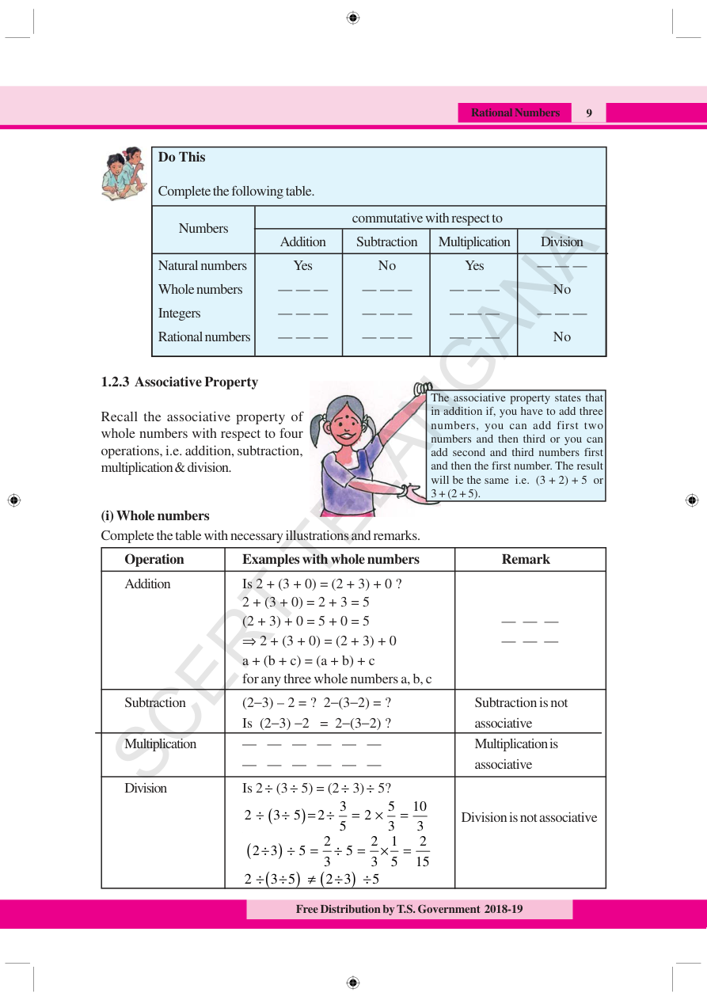


PDF Page 51


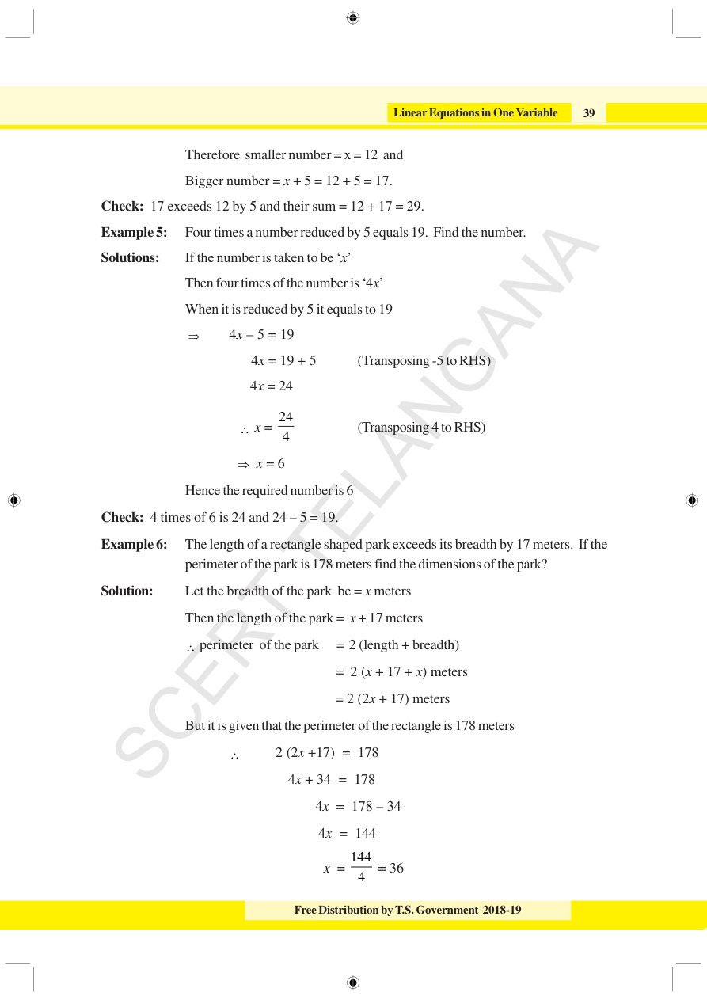


PDF Page 101


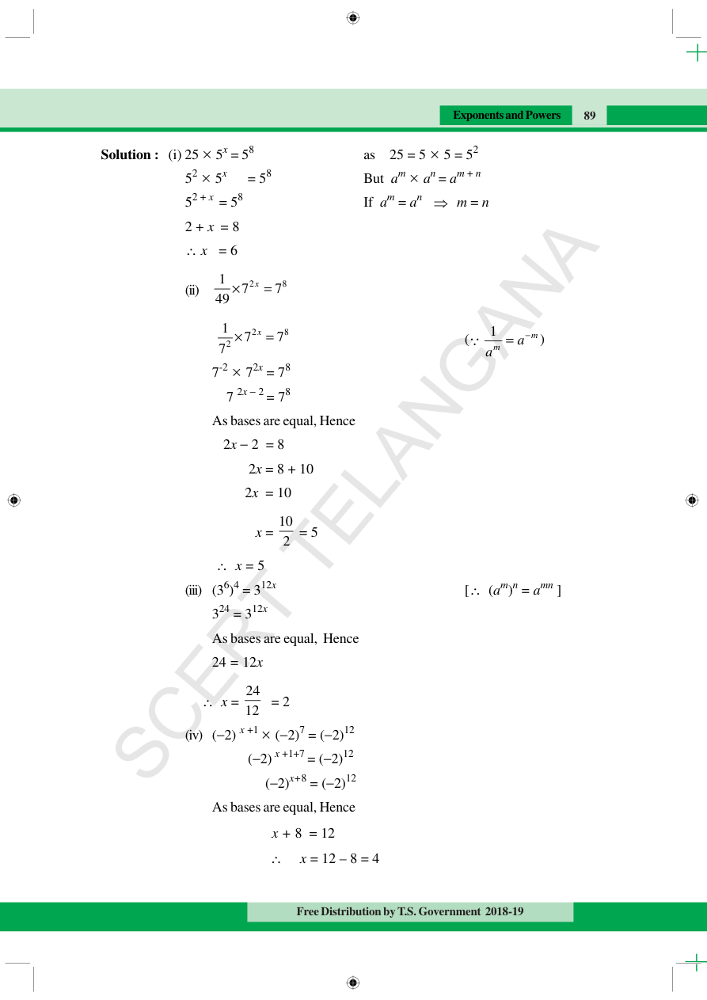


PDF Page 150


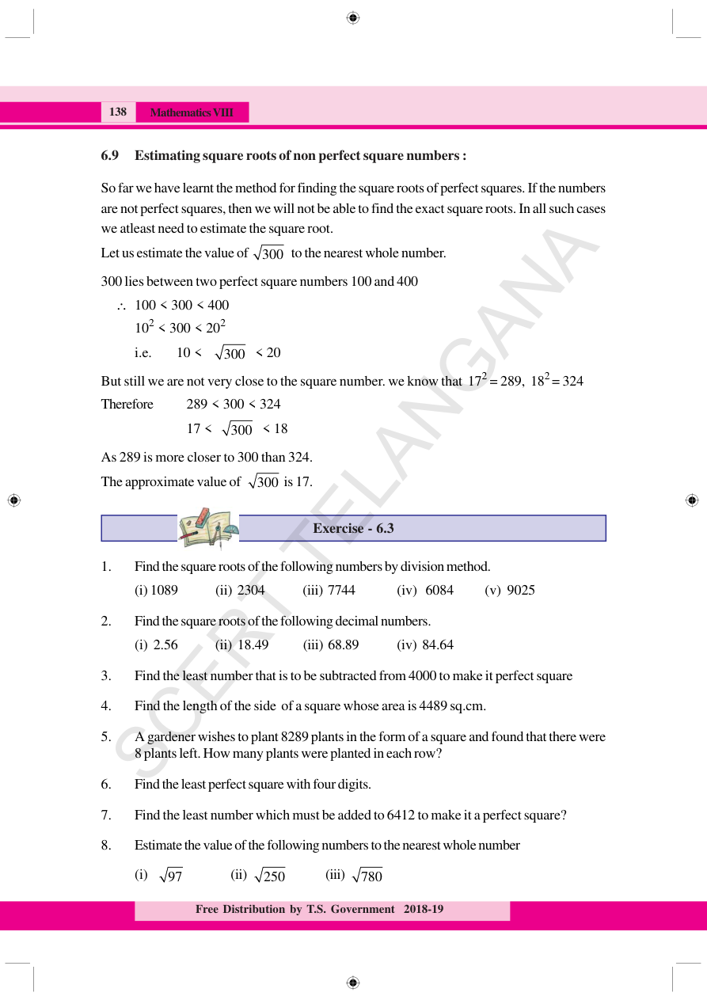

In [ ]:
import fitz
from IPython.display import display, Image

pdf_path = "/content/Math.pdf"
doc = fitz.open(pdf_path)

pages_to_check = [21, 51, 101, 150]

print("Total PDF pages:", len(doc))

for page_no in pages_to_check:
    page = doc[page_no - 1]  # Convert to zero-based index
    pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))

    print(f"\nPDF Page {page_no}")
    display(Image(data=pix.tobytes("png")))

MATHEMATICS PDF EXTRACTION — MANUAL REVIEW NOTES

PDF Page 21
Textbook content: Commutative and associative property tables.
Extraction concern: Table columns and rows can lose their relationships.
Note: Blank lines in the table are intended for students to complete. They are not extraction errors.

PDF Page 51
Textbook content: Equations containing fractions, such as x = 24/4.
Extraction concern: Fraction layout may be split across multiple lines.

PDF Page 101
Textbook content: Exponents such as 5^(2+x) = 5^8.
Extraction concern: Superscripts can become ordinary text during extraction.

PDF Page 150
Textbook content: Square roots such as √300.
Extraction concern: Radical symbols and radical bars can be lost.

CONCLUSION
The current PDF text extraction may not preserve mathematical formatting and table structure correctly. These pages require verification against the original PDF before using the extracted text for AI Tutor retrieval.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")

for page_no in [51, 101, 150]:
    page = doc[page_no - 1]

    print(f"\n{'='*60}")
    print(f"PDF PAGE {page_no} — RAW PYMUPDF TEXT")
    print('='*60)

    print(page.get_text("text", sort=True))


PDF PAGE 51 — RAW PYMUPDF TEXT
                                                      Linear Equations in One Variable    39

                Therefore smaller number = x = 12 and
               Bigger number = x + 5 = 12 + 5 = 17.
  Check: 17 exceeds 12 by 5 and their sum = 12 + 17 = 29.
  Example 5:   Four times a number reduced by 5 equals 19. Find the number.
  Solutions:     If the number is taken to be ‘x’
              Then four times of the number is ‘4x’
           When it is reduced by 5 it equals to 19
         ⇒    4x – 5 = 19
                        4x = 19 + 5       (Transposing -5 to RHS)
                        4x = 24

                           24
               ∴ x =              (Transposing 4 to RHS)                            4
             ⇒ x = 6
              Hence the required number is 6
  Check: 4 times of 6 is 24 and 24 – 5 = 19.
  Example 6:  The length of a rectangle shaped park exceeds its breadth by 17 meters. If the
                perimeter of the par

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")

for page_no in [101, 150]:
    page = doc[page_no - 1]
    data = page.get_text("dict")

    print(f"\n{'='*60}")
    print(f"PAGE {page_no} — TEXT SPANS")
    print('='*60)

    for block in data["blocks"]:
        for line in block.get("lines", []):
            for span in line["spans"]:
                print(
                    f"Text: {span['text']!r} | "
                    f"Font size: {span['size']} | "
                    f"BBox: {span['bbox']}"
                )


PAGE 101 — TEXT SPANS
Text: 'Exponents and Powers' | Font size: 10.0 | BBox: (381.4364929199219, 89.46636962890625, 472.1725158691406, 103.31637573242188)
Text: '89' | Font size: 10.0 | BBox: (491.73260498046875, 90.1182861328125, 501.6256103515625, 103.96829223632812)
Text: 'Free Distribution by T.S. Government  2018-19' | Font size: 10.0 | BBox: (249.74261474609375, 760.1983032226562, 441.00677490234375, 774.0482788085938)
Text: 'Solution :' | Font size: 12.0 | BBox: (84.98930358886719, 121.22407531738281, 133.8292999267578, 137.8440704345703)
Text: '   (i) 25 ' | Font size: 12.0 | BBox: (133.85330200195312, 121.11607360839844, 170.42935180664062, 137.1240692138672)
Text: '×' | Font size: 11.701299667358398 | BBox: (171.16259765625, 121.33836364746094, 177.58660888671875, 136.5851593017578)
Text: ' 5' | Font size: 12.0 | BBox: (179.09959411621094, 121.11607360839844, 187.68798828125, 137.1240692138672)
Text: 'x' | Font size: 9.0 | BBox: (187.6885986328125, 119.80721282958984, 191.68

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]  # PDF page 150

print("DRAWING OBJECTS:", len(page.get_drawings()))

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]

    # Focus on the section containing √300
    if 190 < rect.y0 < 420 and 70 < rect.x0 < 400:
        print(
            "Drawing:", i,
            "Rectangle:", rect,
            "Items:", drawing["items"][:5]
        )

DRAWING OBJECTS: 74
Drawing: 9 Rectangle: Rect(213.19700622558594, 206.20599365234375, 239.04800415039062, 218.8759765625) Items: [('l', Point(213.19700622558594, 214.7659912109375), Point(214.4149932861328, 214.08599853515625)), ('l', Point(214.4149932861328, 214.08599853515625), Point(217.3350067138672, 218.8759765625)), ('l', Point(217.3350067138672, 218.8759765625), Point(220.50999450683594, 206.20599365234375)), ('l', Point(220.50999450683594, 206.20599365234375), Point(239.04800415039062, 206.20599365234375))]
Drawing: 10 Rectangle: Rect(213.11099243164062, 205.9219970703125, 239.04800415039062, 218.8759765625) Items: [('l', Point(213.11099243164062, 214.6240234375), Point(214.75599670410156, 213.71697998046875)), ('l', Point(214.75599670410156, 213.71697998046875), Point(217.36300659179688, 217.6290283203125)), ('l', Point(217.36300659179688, 217.6290283203125), Point(220.2830047607422, 205.9219970703125)), ('l', Point(220.2830047607422, 205.9219970703125), Point(239.04800415039

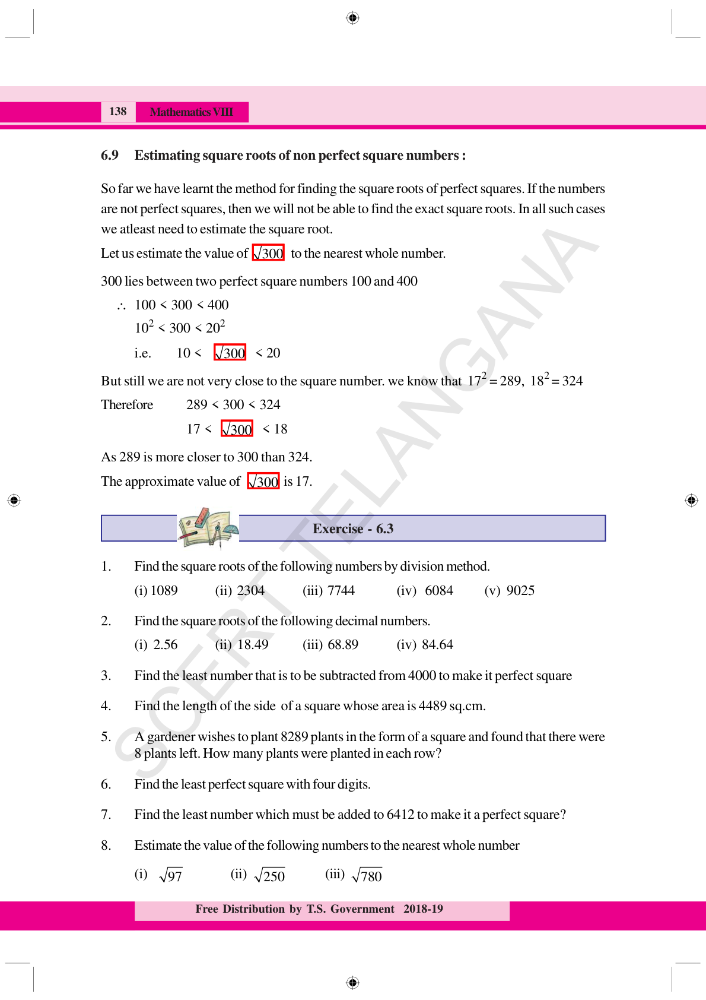

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")
page = doc[149]

# Render original page
pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))
img = pix.tobytes("png")

# Create an annotated copy
annotated = fitz.open()
annotated.insert_pdf(doc, from_page=149, to_page=149)

p = annotated[0]

for i in [9, 10, 12, 13, 15, 16, 18, 19]:
    rect = p.get_drawings()[i]["rect"]
    p.draw_rect(rect, color=(1, 0, 0), width=1.5)

pix = p.get_pixmap(matrix=fitz.Matrix(2, 2))
display(Image(data=pix.tobytes("png")))

This confirms that the radical signs are stored as vector drawings, not ordinary text. PyMuPDF's drawing information can help us detect them.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]

raw = page.get_text("rawdict")

# Extract individual character positions
characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span.get("chars", []):
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

# Inspect the detected radical locations
radical_ids = [9, 12, 15, 18]

for drawing_id in radical_ids:
    rect = page.get_drawings()[drawing_id]["rect"]

    nearby = [
        c["char"]
        for c in characters
        if c["bbox"].x1 > rect.x0
        and c["bbox"].x0 < rect.x1 + 15
        and abs(c["bbox"].y0 - rect.y0) < 20
    ]

    print(f"Drawing {drawing_id}")
    print("Drawing rectangle:", rect)
    print("Nearby characters:", "".join(nearby))
    print("-" * 40)

Drawing 9
Drawing rectangle: Rect(213.19700622558594, 206.20599365234375, 239.04800415039062, 218.8759765625)
Nearby characters: 300  to
----------------------------------------
Drawing 12
Drawing rectangle: Rect(180.93800354003906, 290.16802978515625, 206.7899932861328, 302.8389892578125)
Nearby characters: 300  < 
----------------------------------------
Drawing 15
Drawing rectangle: Rect(186.86300659179688, 354.2590026855469, 212.68600463867188, 366.92999267578125)
Nearby characters: 300  < 
----------------------------------------
Drawing 18
Drawing rectangle: Rect(209.11500549316406, 398.50799560546875, 234.93800354003906, 411.1789855957031)
Nearby characters: 300 is 1E
----------------------------------------


In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]

raw = page.get_text("rawdict")

characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

for drawing_id in [9, 12, 15, 18]:
    rect = page.get_drawings()[drawing_id]["rect"]

    print(f"\nDrawing {drawing_id}: {rect}")

    for c in characters:
        bbox = c["bbox"]

        if (
            bbox.x0 >= rect.x0
            and bbox.x0 <= rect.x1 + 20
            and abs(bbox.y0 - rect.y0) < 20
        ):
            print(
                repr(c["char"]),
                "x:", round(bbox.x0, 2),
                "y:", round(bbox.y0, 2),
                "width:", round(bbox.width, 2)
            )


Drawing 9: Rect(213.19700622558594, 206.20599365234375, 239.04800415039062, 218.8759765625)
'3' x: 220.68 y: 205.11 width: 6.0
'0' x: 226.68 y: 205.11 width: 6.0
'0' x: 232.67 y: 205.11 width: 6.0
' ' x: 241.0 y: 204.26 width: 3.0
' ' x: 243.1 y: 204.26 width: 3.0
't' x: 245.2 y: 204.26 width: 3.34
'o' x: 248.36 y: 204.26 width: 6.0
' ' x: 254.19 y: 204.26 width: 3.0
't' x: 256.29 y: 204.26 width: 3.34

Drawing 12: Rect(180.93800354003906, 290.16802978515625, 206.7899932861328, 302.8389892578125)
'3' x: 188.42 y: 289.07 width: 6.0
'0' x: 194.42 y: 289.07 width: 6.0
'0' x: 200.41 y: 289.07 width: 6.0
' ' x: 208.86 y: 288.22 width: 3.0
' ' x: 211.82 y: 288.22 width: 3.0
'<' x: 214.77 y: 288.22 width: 6.77
' ' x: 221.48 y: 288.22 width: 3.0
'2' x: 224.43 y: 288.22 width: 6.0

Drawing 15: Rect(186.86300659179688, 354.2590026855469, 212.68600463867188, 366.92999267578125)
'3' x: 194.32 y: 353.16 width: 6.0
'0' x: 200.31 y: 353.16 width: 6.0
'0' x: 206.31 y: 353.16 width: 6.0
' ' x: 214.76 

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]

drawings = page.get_drawings()
raw = page.get_text("rawdict")

# Extract individual text characters and positions
characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

# Identify radical-shaped vector drawings
candidates = []

for i, drawing in enumerate(drawings):
    rect = drawing["rect"]

    if 190 < rect.y0 < 420 and 150 < rect.x0 < 250:
        candidates.append((i, rect))

# Remove overlapping duplicate drawings
unique_radicals = []

for drawing_id, rect in candidates:
    duplicate = any(
        abs(rect.x0 - existing.x0) < 1.5
        and abs(rect.y0 - existing.y0) < 1.5
        and abs(rect.x1 - existing.x1) < 1.5
        and abs(rect.y1 - existing.y1) < 1.5
        for existing in unique_radicals
    )

    if not duplicate:
        unique_radicals.append(rect)

print("Unique candidate radicals:", len(unique_radicals))

# Associate nearby characters with each radical
for i, rect in enumerate(unique_radicals, start=1):

    radicand = "".join(
        c["char"]
        for c in sorted(
            characters,
            key=lambda c: c["bbox"].x0
        )
        if c["bbox"].x0 >= rect.x0 + 7
        and c["bbox"].x1 <= rect.x1 + 1
        and abs(c["bbox"].y0 - rect.y0) < 3
        and c["char"].strip()
    )

    print(f"Radical {i}: √{radicand}")

Unique candidate radicals: 8
Radical 1: √300
Radical 2: √
Radical 3: √300
Radical 4: √
Radical 5: √300
Radical 6: √
Radical 7: √300
Radical 8: √


The detector found four correct √300 expressions, but it also counted four extra candidates that returned only √.

This means our current duplicate-removal logic is not sufficient. We should not automatically add these results to the textbook corpus yet.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]

drawings = page.get_drawings()

for i, drawing in enumerate(drawings):
    rect = drawing["rect"]

    if (
        190 < rect.y0 < 420
        and 150 < rect.x0 < 250
    ):
        print(
            f"Drawing ID: {i}",
            f"| x0: {rect.x0:.2f}",
            f"| y0: {rect.y0:.2f}",
            f"| x1: {rect.x1:.2f}",
            f"| y1: {rect.y1:.2f}",
            f"| Width: {rect.width:.2f}",
            f"| Height: {rect.height:.2f}"
        )

Drawing ID: 9 | x0: 213.20 | y0: 206.21 | x1: 239.05 | y1: 218.88 | Width: 25.85 | Height: 12.67
Drawing ID: 10 | x0: 213.11 | y0: 205.92 | x1: 239.05 | y1: 218.88 | Width: 25.94 | Height: 12.95
Drawing ID: 11 | x0: 211.10 | y0: 203.74 | x1: 211.10 | y1: 203.74 | Width: 0.00 | Height: 0.00
Drawing ID: 12 | x0: 180.94 | y0: 290.17 | x1: 206.79 | y1: 302.84 | Width: 25.85 | Height: 12.67
Drawing ID: 13 | x0: 180.85 | y0: 289.88 | x1: 206.79 | y1: 302.84 | Width: 25.94 | Height: 12.96
Drawing ID: 14 | x0: 178.84 | y0: 287.70 | x1: 178.84 | y1: 287.70 | Width: 0.00 | Height: 0.00
Drawing ID: 15 | x0: 186.86 | y0: 354.26 | x1: 212.69 | y1: 366.93 | Width: 25.82 | Height: 12.67
Drawing ID: 16 | x0: 186.78 | y0: 353.98 | x1: 212.69 | y1: 366.93 | Width: 25.91 | Height: 12.95
Drawing ID: 17 | x0: 184.76 | y0: 351.79 | x1: 184.76 | y1: 351.79 | Width: 0.00 | Height: 0.00
Drawing ID: 18 | x0: 209.12 | y0: 398.51 | x1: 234.94 | y1: 411.18 | Width: 25.82 | Height: 12.67
Drawing ID: 19 | x0: 209.03

Each actual radical sign is represented by two overlapping vector drawings, while a third zero-sized drawing is just an artifact.


For example:
- Drawings 9 and 10 = one radical sign.
- Drawing 11 = zero-sized artifact.
- Drawings 12 and 13 = one radical sign.
- Drawing 14 = zero-sized artifact.
The same pattern repeats for all four radicals.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]

drawings = page.get_drawings()
candidates = []

# Step 1: Filter likely radical drawings
for i, drawing in enumerate(drawings):
    rect = drawing["rect"]

    if (
        rect.width > 15
        and rect.height > 5
        and 190 < rect.y0 < 420
        and 150 < rect.x0 < 250
    ):
        candidates.append((i, rect))

# Step 2: Group overlapping duplicate drawings
groups = []

for drawing_id, rect in candidates:
    matched = False

    for group in groups:
        existing = group[0][1]

        if (
            abs(rect.x0 - existing.x0) < 1
            and abs(rect.y0 - existing.y0) < 1
            and abs(rect.x1 - existing.x1) < 1
            and abs(rect.y1 - existing.y1) < 1
        ):
            group.append((drawing_id, rect))
            matched = True
            break

    if not matched:
        groups.append([(drawing_id, rect)])

print("Detected radical groups:", len(groups))

# Step 3: Extract text characters
raw = page.get_text("rawdict")
characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

# Step 4: Associate digits with each radical
for number, group in enumerate(groups, start=1):
    rect = group[0][1]

    radicand_chars = [
        c for c in characters
        if c["bbox"].x0 >= rect.x0 + 7
        and c["bbox"].x1 <= rect.x1 + 1
        and abs(c["bbox"].y0 - rect.y0) < 3
        and c["char"].strip()
    ]

    radicand_chars.sort(key=lambda c: c["bbox"].x0)

    radicand = "".join(c["char"] for c in radicand_chars)

    print(
        f"Radical {number}: √{radicand} "
        f"| Duplicate drawings: {len(group)}"
    )

Detected radical groups: 4
Radical 1: √300 | Duplicate drawings: 2
Radical 2: √300 | Duplicate drawings: 2
Radical 3: √300 | Duplicate drawings: 2
Radical 4: √300 | Duplicate drawings: 2


identified all four square-root expressions on PDF page 150

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")

for page_no in range(151, 161):
    page = doc[page_no - 1]
    candidates = []

    for i, drawing in enumerate(page.get_drawings()):
        rect = drawing["rect"]

        if (
            rect.width > 15
            and rect.height > 5
        ):
            candidates.append(rect)

    groups = []

    for rect in candidates:
        matched = False

        for group in groups:
            existing = group[0]

            if (
                abs(rect.x0 - existing.x0) < 1
                and abs(rect.y0 - existing.y0) < 1
                and abs(rect.x1 - existing.x1) < 1
                and abs(rect.y1 - existing.y1) < 1
            ):
                group.append(rect)
                matched = True
                break

        if not matched:
            groups.append([rect])

    print(
        f"PDF Page {page_no}: "
        f"{len(groups)} candidate drawing groups"
    )

PDF Page 151: 15 candidate drawing groups
PDF Page 152: 13 candidate drawing groups
PDF Page 153: 13 candidate drawing groups
PDF Page 154: 10 candidate drawing groups
PDF Page 155: 14 candidate drawing groups
PDF Page 156: 246 candidate drawing groups
PDF Page 157: 20 candidate drawing groups
PDF Page 158: 11 candidate drawing groups
PDF Page 159: 14 candidate drawing groups
PDF Page 160: 18 candidate drawing groups


Page 156 has 246 candidate drawing groups, compared with 10–20 on most other pages. This could be a diagram-heavy page, so we must not assume every drawing represents a radical.

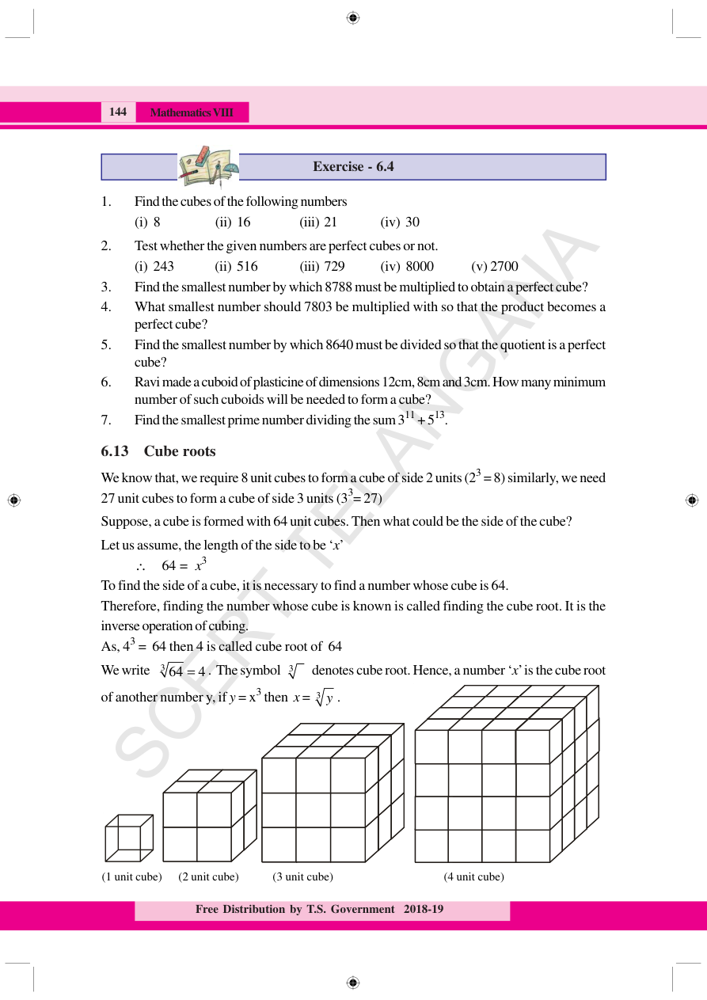

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")

page_no = 156
page = doc[page_no - 1]

pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))

display(Image(data=pix.tobytes("png")))

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]  # PDF page 156

text = page.get_text("text", sort=True)

print("Extracted text from PDF page 156:\n")
print(text)

print("\nCube-root symbol detected:", "∛" in text)
print("Square-root symbol detected:", "√" in text)

Extracted text from PDF page 156:

    144    Mathematics VIII


                                   Exercise - 6.4

  1.    Find the cubes of the following numbers
          (i) 8             (ii) 16            (iii) 21        (iv) 30
  2.    Test whether the given numbers are perfect cubes or not.
           (i) 243         (ii) 516          (iii) 729       (iv) 8000       (v) 2700
  3.    Find the smallest number by which 8788 must be multiplied to obtain a perfect cube?
  4.   What smallest number should 7803 be multiplied with so that the product becomes a
        perfect cube?
  5.    Find the smallest number by which 8640 must be divided so that the quotient is a perfect
       cube?
  6.    Ravi made a cuboid of plasticine of dimensions 12cm, 8cm and 3cm. How many minimum
       number of such cuboids will be needed to form a cube?
  7.    Find the smallest prime number dividing the sum 311 + 513.

  6.13  Cube roots
 We know that, we require 8 unit cubes to form a cube of side 

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

print("Page dimensions:", page.rect)
print("Total drawing objects:", len(page.get_drawings()))
print("\nSmall drawing candidates:\n")

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]

    if (
        4 < rect.width < 40
        and 3 < rect.height < 30
    ):
        print(
            f"ID: {i} | "
            f"x0={rect.x0:.2f}, y0={rect.y0:.2f}, "
            f"x1={rect.x1:.2f}, y1={rect.y1:.2f}, "
            f"width={rect.width:.2f}, height={rect.height:.2f}, "
            f"items={len(drawing['items'])}"
        )

Page dimensions: Rect(0.0, 0.0, 595.0, 842.0)
Total drawing objects: 1677

Small drawing candidates:

ID: 7 | x0=86.00, y0=86.70, x1=113.70, y1=102.35, width=27.70, height=15.65, items=1
ID: 9 | x0=134.62, y0=557.67, x1=154.55, y1=570.34, width=19.93, height=12.67, items=4
ID: 10 | x0=134.54, y0=557.39, x1=154.55, y1=570.34, width=20.01, height=12.95, items=10
ID: 12 | x0=242.65, y0=558.95, x1=256.20, y1=571.59, width=13.55, height=12.64, items=4
ID: 13 | x0=242.56, y0=558.67, x1=256.20, y1=571.59, width=13.63, height=12.93, items=10
ID: 15 | x0=265.67, y0=579.58, x1=281.03, y1=594.89, width=15.36, height=15.31, items=4
ID: 16 | x0=265.58, y0=579.30, x1=281.03, y1=594.89, width=15.45, height=15.59, items=10
ID: 18 | x0=391.75, y0=688.07, x1=420.04, y1=716.47, width=28.29, height=28.40, items=1
ID: 19 | x0=391.75, y0=688.07, x1=420.04, y1=716.47, width=28.29, height=28.40, items=1
ID: 20 | x0=381.21, y0=688.07, x1=420.04, y1=697.68, width=38.83, height=9.61, items=4
ID: 21 | x0=381.21, 

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

drawings = page.get_drawings()

candidate_ids = [9, 10, 12, 13, 15, 16]

for drawing_id in candidate_ids:
    drawing = drawings[drawing_id]

    print(f"\nDrawing ID: {drawing_id}")
    print("Bounding box:", drawing["rect"])
    print("Drawing items:")

    for item in drawing["items"]:
        print(item)


Drawing ID: 9
Bounding box: Rect(134.6199951171875, 557.6729736328125, 154.54800415039062, 570.343994140625)
Drawing items:
('l', Point(134.6199951171875, 566.2340087890625), Point(135.83900451660156, 565.552978515625))
('l', Point(135.83900451660156, 565.552978515625), Point(138.72999572753906, 570.343994140625))
('l', Point(138.72999572753906, 570.343994140625), Point(141.90499877929688, 557.6729736328125))
('l', Point(141.90499877929688, 557.6729736328125), Point(154.54800415039062, 557.6729736328125))

Drawing ID: 10
Bounding box: Rect(134.53500366210938, 557.3900146484375, 154.54800415039062, 570.343994140625)
Drawing items:
('l', Point(134.53500366210938, 566.092041015625), Point(136.1790008544922, 565.1849975585938))
('l', Point(136.1790008544922, 565.1849975585938), Point(138.75900268554688, 569.0969848632812))
('l', Point(138.75900268554688, 569.0969848632812), Point(141.67799377441406, 557.3900146484375))
('l', Point(141.67799377441406, 557.3900146484375), Point(154.54800415

We can detect the radical sign from its vector geometry. But we must also identify its index (3 for cube root) and the number underneath the bar.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

candidate_rects = [
    drawings_id for drawings_id in [9, 12, 15]
]

drawings = page.get_drawings()
raw = page.get_text("rawdict")

characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

for drawing_id in candidate_rects:
    rect = drawings[drawing_id]["rect"]

    print(f"\nDrawing {drawing_id}, position: {rect}")

    nearby = [
        c for c in characters
        if (
            rect.x0 - 12 <= c["bbox"].x0 <= rect.x1 + 35
            and rect.y0 - 15 <= c["bbox"].y0 <= rect.y1 + 15
        )
    ]

    nearby.sort(key=lambda c: (round(c["bbox"].y0, 1), c["bbox"].x0))

    for c in nearby:
        print(
            repr(c["char"]),
            "x:", round(c["bbox"].x0, 2),
            "y:", round(c["bbox"].y0, 2)
        )


Drawing 9, position: Rect(134.6199951171875, 557.6729736328125, 154.54800415039062, 570.343994140625)
' ' x: 139.08 y: 551.76
' ' x: 126.15 y: 555.3
' ' x: 128.31 y: 555.3
' ' x: 130.28 y: 555.3
'.' x: 175.16 y: 555.3
' ' x: 177.96 y: 555.3
' ' x: 180.02 y: 555.3
'T' x: 182.0 y: 555.3
'h' x: 189.14 y: 555.3
'3' x: 135.19 y: 556.2
'6' x: 142.25 y: 556.57
'4' x: 148.2 y: 556.57
'4' x: 167.05 y: 556.57
'=' x: 157.72 y: 557.09
'e' x: 123.45 y: 577.98
'r' x: 128.71 y: 577.98
' ' x: 132.65 y: 577.98
'n' x: 134.86 y: 577.98
'u' x: 140.8 y: 577.98
'm' x: 146.74 y: 577.98
'b' x: 156.01 y: 577.98
'e' x: 161.95 y: 577.98
'r' x: 167.21 y: 577.98
' ' x: 171.14 y: 577.98
'y' x: 173.36 y: 577.98
',' x: 178.59 y: 577.98
' ' x: 181.53 y: 577.98
'i' x: 183.74 y: 577.98
'f' x: 187.02 y: 577.98

Drawing 12, position: Rect(242.6490020751953, 558.948974609375, 256.197998046875, 571.5910034179688)
'l' x: 233.17 y: 555.3
' ' x: 236.32 y: 555.3
' ' x: 238.5 y: 555.3
' ' x: 258.47 y: 555.3
' ' x: 260.55 y: 555

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

raw = page.get_text("rawdict")
characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                bbox = fitz.Rect(char["bbox"])
                if 125 <= bbox.x0 <= 175 and 550 <= bbox.y0 <= 565:
                    characters.append(
                        (char["c"], round(bbox.x0, 2),
                         round(bbox.y0, 2), round(bbox.x1, 2))
                    )

for item in sorted(characters, key=lambda x: x[1]):
    print(item)

(' ', 126.15, 555.3, 129.15)
(' ', 128.31, 555.3, 131.31)
(' ', 130.28, 555.3, 133.28)
('3', 135.19, 556.2, 139.08)
(' ', 139.08, 551.76, 142.25)
('6', 142.25, 556.57, 148.25)
('4', 148.2, 556.57, 154.2)
('=', 157.72, 557.09, 164.31)
('4', 167.05, 556.57, 173.05)


In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

drawings = page.get_drawings()
raw = page.get_text("rawdict")

characters = []

for block in raw["blocks"]:
    for line in block.get("lines", []):
        for span in line["spans"]:
            for char in span["chars"]:
                characters.append({
                    "char": char["c"],
                    "bbox": fitz.Rect(char["bbox"])
                })

for drawing_id in [12, 15]:
    rect = drawings[drawing_id]["rect"]

    print(f"\n--- Drawing {drawing_id} ---")

    nearby = [
        c for c in characters
        if (
            rect.x0 - 5 <= c["bbox"].x0 <= rect.x1 + 35
            and rect.y0 - 5 <= c["bbox"].y0 <= rect.y1 + 5
            and c["char"].strip()
        )
    ]

    nearby.sort(key=lambda c: (round(c["bbox"].y0, 1), c["bbox"].x0))

    for c in nearby:
        print(
            repr(c["char"]),
            "x:", round(c["bbox"].x0, 2),
            "y:", round(c["bbox"].y0, 2)
        )


--- Drawing 12 ---
'd' x: 262.63 y: 555.3
'e' x: 268.46 y: 555.3
'n' x: 273.61 y: 555.3
'o' x: 279.43 y: 555.3
't' x: 285.25 y: 555.3
'e' x: 288.41 y: 555.3
'3' x: 243.22 y: 557.33

--- Drawing 15 ---
'.' x: 283.81 y: 577.98
'3' x: 266.2 y: 579.59
'y' x: 274.77 y: 579.73


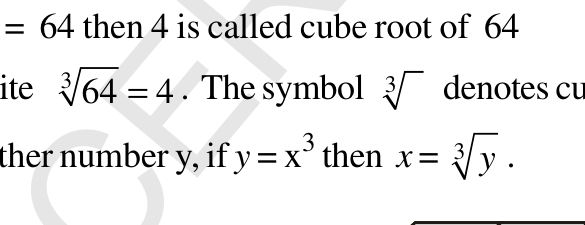

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")
page = doc[155]

# Crop the mathematical explanation area
clip = fitz.Rect(115, 535, 310, 610)

pix = page.get_pixmap(
    matrix=fitz.Matrix(3, 3),
    clip=clip
)

display(Image(data=pix.tobytes("png")))

A radical drawing does not always have a number underneath it. Drawing 12 is a standalone symbol, so our detector must support both cases.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[155]

candidates = []

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]
    items = drawing["items"]

    # Consider small drawings only
    if not (10 <= rect.width <= 35 and 8 <= rect.height <= 22):
        continue

    # Radical symbols are composed of line segments
    if len(items) < 4:
        continue

    if not all(item[0] == "l" for item in items):
        continue

    # Check whether the final segment is horizontal
    last_item = items[-1]
    p1, p2 = last_item[1], last_item[2]

    horizontal_bar = abs(p1.y - p2.y) < 1

    # Check for both downward and upward strokes
    downward = any(
        item[2].y > item[1].y + 2
        for item in items[:-1]
    )

    upward = any(
        item[2].y < item[1].y - 2
        for item in items[:-1]
    )

    if horizontal_bar and downward and upward:
        candidates.append((i, rect, len(items)))

print("Possible radical-shaped drawings:", len(candidates))

for candidate in candidates:
    print(candidate)

Possible radical-shaped drawings: 6
(9, Rect(134.6199951171875, 557.6729736328125, 154.54800415039062, 570.343994140625), 4)
(10, Rect(134.53500366210938, 557.3900146484375, 154.54800415039062, 570.343994140625), 10)
(12, Rect(242.6490020751953, 558.948974609375, 256.197998046875, 571.5910034179688), 4)
(13, Rect(242.56300354003906, 558.6650390625, 256.197998046875, 571.5910034179688), 10)
(15, Rect(265.6659851074219, 579.5849609375, 281.0299987792969, 594.8919677734375), 4)
(16, Rect(265.58099365234375, 579.302001953125, 281.0299987792969, 594.8919677734375), 10)


In [ ]:
unique_radicals = []

for drawing_id, rect, item_count in candidates:
    duplicate = any(
        abs(rect.x0 - existing[1].x0) < 1
        and abs(rect.y0 - existing[1].y0) < 1
        and abs(rect.x1 - existing[1].x1) < 1
        and abs(rect.y1 - existing[1].y1) < 1
        for existing in unique_radicals
    )

    if not duplicate:
        unique_radicals.append((drawing_id, rect, item_count))

print("Unique radical symbols:", len(unique_radicals))

for number, (drawing_id, rect, _) in enumerate(unique_radicals, start=1):
    print(
        f"Radical {number}: Drawing ID {drawing_id}, "
        f"position={rect}"
    )

Unique radical symbols: 3
Radical 1: Drawing ID 9, position=Rect(134.6199951171875, 557.6729736328125, 154.54800415039062, 570.343994140625)
Radical 2: Drawing ID 12, position=Rect(242.6490020751953, 558.948974609375, 256.197998046875, 571.5910034179688)
Radical 3: Drawing ID 15, position=Rect(265.6659851074219, 579.5849609375, 281.0299987792969, 594.8919677734375)


We have now validated:
- 6 vector drawings detected.
- 3 actual radical symbols identified.
- Duplicate pairs correctly grouped.
- The three symbols visually match the textbook.
This is a successful page-level test, but we still need to test other pages to measure false positives and missed radicals.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[149]  # PDF page 150

candidates = []

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]
    items = drawing["items"]

    if not (10 <= rect.width <= 35 and 8 <= rect.height <= 22):
        continue

    if len(items) < 4:
        continue

    if not all(item[0] == "l" for item in items):
        continue

    p1, p2 = items[-1][1], items[-1][2]

    horizontal_bar = abs(p1.y - p2.y) < 1

    downward = any(
        item[2].y > item[1].y + 2
        for item in items[:-1]
    )

    upward = any(
        item[2].y < item[1].y - 2
        for item in items[:-1]
    )

    if horizontal_bar and downward and upward:
        candidates.append((i, rect))

unique_radicals = []

for drawing_id, rect in candidates:
    duplicate = any(
        abs(rect.x0 - existing[1].x0) < 1
        and abs(rect.y0 - existing[1].y0) < 1
        and abs(rect.x1 - existing[1].x1) < 1
        and abs(rect.y1 - existing[1].y1) < 1
        for existing in unique_radicals
    )

    if not duplicate:
        unique_radicals.append((drawing_id, rect))

print("Candidate drawings:", len(candidates))
print("Unique radical symbols:", len(unique_radicals))

for drawing_id, rect in unique_radicals:
    print(f"Drawing ID {drawing_id}: {rect}")

Candidate drawings: 14
Unique radical symbols: 7
Drawing ID 9: Rect(213.19700622558594, 206.20599365234375, 239.04800415039062, 218.8759765625)
Drawing ID 12: Rect(180.93800354003906, 290.16802978515625, 206.7899932861328, 302.8389892578125)
Drawing ID 15: Rect(186.86300659179688, 354.2590026855469, 212.68600463867188, 366.92999267578125)
Drawing ID 18: Rect(209.11500549316406, 398.50799560546875, 234.93800354003906, 411.1789855957031)
Drawing ID 21: Rect(134.16700744628906, 730.218017578125, 154.00900268554688, 742.8889770507812)
Drawing ID 24: Rect(214.2169952392578, 730.218017578125, 240.23899841308594, 742.8889770507812)
Drawing ID 27: Rect(296.364990234375, 730.218017578125, 322.1889953613281, 742.8889770507812)


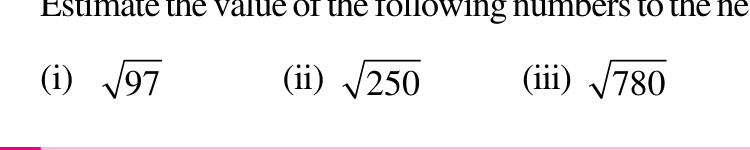

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")
page = doc[149]

clip = fitz.Rect(100, 710, 350, 760)

pix = page.get_pixmap(
    matrix=fitz.Matrix(3, 3),
    clip=clip
)

display(Image(data=pix.tobytes("png")))

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")

def detect_radicals(page):
    candidates = []

    for i, drawing in enumerate(page.get_drawings()):
        rect = drawing["rect"]
        items = drawing["items"]

        if not (10 <= rect.width <= 35 and 8 <= rect.height <= 22):
            continue

        if len(items) < 4:
            continue

        if not all(item[0] == "l" for item in items):
            continue

        p1, p2 = items[-1][1], items[-1][2]

        horizontal_bar = abs(p1.y - p2.y) < 1

        downward = any(
            item[2].y > item[1].y + 2
            for item in items[:-1]
        )

        upward = any(
            item[2].y < item[1].y - 2
            for item in items[:-1]
        )

        if horizontal_bar and downward and upward:
            candidates.append((i, rect))

    unique = []

    for drawing_id, rect in candidates:
        duplicate = any(
            abs(rect.x0 - existing[1].x0) < 1
            and abs(rect.y0 - existing[1].y0) < 1
            and abs(rect.x1 - existing[1].x1) < 1
            and abs(rect.y1 - existing[1].y1) < 1
            for existing in unique
        )

        if not duplicate:
            unique.append((drawing_id, rect))

    return len(candidates), unique


total_symbols = 0
pages_with_candidates = []

for page_no, page in enumerate(doc, start=1):
    candidate_count, unique = detect_radicals(page)

    if unique:
        total_symbols += len(unique)
        pages_with_candidates.append((page_no, len(unique)))

print("Total PDF pages:", len(doc))
print("Pages with candidate radicals:", len(pages_with_candidates))
print("Total unique candidate symbols:", total_symbols)

print("\nPage-wise results:")
for page_no, count in pages_with_candidates:
    print(f"Page {page_no}: {count} candidates")

Total PDF pages: 370
Pages with candidate radicals: 29
Total unique candidate symbols: 161

Page-wise results:
Page 75: 1 candidates
Page 76: 19 candidates
Page 107: 1 candidates
Page 142: 20 candidates
Page 143: 2 candidates
Page 144: 6 candidates
Page 145: 1 candidates
Page 147: 2 candidates
Page 148: 2 candidates
Page 149: 3 candidates
Page 150: 7 candidates
Page 156: 3 candidates
Page 157: 12 candidates
Page 158: 1 candidates
Page 233: 1 candidates
Page 237: 1 candidates
Page 241: 1 candidates
Page 245: 33 candidates
Page 299: 10 candidates
Page 300: 2 candidates
Page 302: 3 candidates
Page 303: 2 candidates
Page 305: 7 candidates
Page 306: 14 candidates
Page 309: 1 candidates
Page 310: 1 candidates
Page 312: 1 candidates
Page 316: 3 candidates
Page 317: 1 candidates


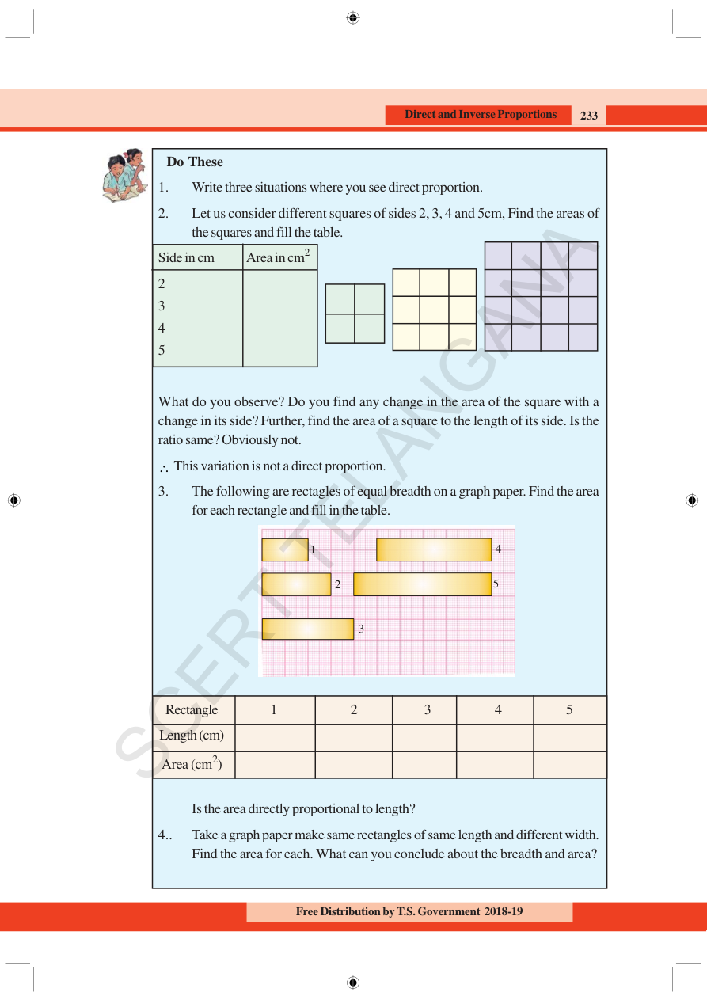

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")

page_no = 245
page = doc[page_no - 1]

pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))

display(Image(data=pix.tobytes("png")))

The page contains square grids, rectangles and graph-paper lines, but no visible square-root or cube-root symbols. Our current detector is incorrectly classifying some diagram paths as radicals.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")

def is_radical_shape(drawing):
    items = drawing["items"]

    if len(items) < 4:
        return False

    first_four = items[:4]

    if not all(item[0] == "l" for item in first_four):
        return False

    segments = []

    for item in first_four:
        p1, p2 = item[1], item[2]
        dx = p2.x - p1.x
        dy = p2.y - p1.y

        segments.append((dx, dy))

    (dx1, dy1), (dx2, dy2), (dx3, dy3), (dx4, dy4) = segments

    # Ordered radical stroke pattern
    return (
        0.5 <= dx1 <= 2.5 and -2 <= dy1 < 0
        and 2 <= dx2 <= 4 and 2 <= dy2 <= 6
        and 2 <= dx3 <= 4 and -15 <= dy3 <= -8
        and dx4 >= 4.5 and abs(dy4) <= 1
    )


def detect_radicals(page):
    candidates = []

    for i, drawing in enumerate(page.get_drawings()):
        rect = drawing["rect"]

        if not (10 <= rect.width <= 35 and 8 <= rect.height <= 22):
            continue

        if is_radical_shape(drawing):
            candidates.append((i, rect))

    unique = []

    for drawing_id, rect in candidates:
        duplicate = any(
            abs(rect.x0 - existing[1].x0) < 1
            and abs(rect.y0 - existing[1].y0) < 1
            and abs(rect.x1 - existing[1].x1) < 1
            and abs(rect.y1 - existing[1].y1) < 1
            for existing in unique
        )

        if not duplicate:
            unique.append((drawing_id, rect))

    return len(candidates), unique


# Test on two known radical pages and one diagram-heavy page
for page_no in [150, 156, 245]:
    candidate_count, unique = detect_radicals(doc[page_no - 1])

    print(f"\nPDF Page {page_no}")
    print("Candidate drawings:", candidate_count)
    print("Unique candidates:", len(unique))

    for drawing_id, rect in unique:
        print("Drawing:", drawing_id, "| Position:", rect)


PDF Page 150
Candidate drawings: 14
Unique candidates: 7
Drawing: 9 | Position: Rect(213.19700622558594, 206.20599365234375, 239.04800415039062, 218.8759765625)
Drawing: 12 | Position: Rect(180.93800354003906, 290.16802978515625, 206.7899932861328, 302.8389892578125)
Drawing: 15 | Position: Rect(186.86300659179688, 354.2590026855469, 212.68600463867188, 366.92999267578125)
Drawing: 18 | Position: Rect(209.11500549316406, 398.50799560546875, 234.93800354003906, 411.1789855957031)
Drawing: 21 | Position: Rect(134.16700744628906, 730.218017578125, 154.00900268554688, 742.8889770507812)
Drawing: 24 | Position: Rect(214.2169952392578, 730.218017578125, 240.23899841308594, 742.8889770507812)
Drawing: 27 | Position: Rect(296.364990234375, 730.218017578125, 322.1889953613281, 742.8889770507812)

PDF Page 156
Candidate drawings: 5
Unique candidates: 3
Drawing: 9 | Position: Rect(134.6199951171875, 557.6729736328125, 154.54800415039062, 570.343994140625)
Drawing: 12 | Position: Rect(242.6490020

handles overlapping duplicate drawings correctly.

In [ ]:
total_symbols = 0
pages_with_radicals = []

for page_no, page in enumerate(doc, start=1):
    candidate_count, unique = detect_radicals(page)

    if unique:
        total_symbols += len(unique)
        pages_with_radicals.append((page_no, len(unique)))

print("Total PDF pages:", len(doc))
print("Pages with detected radicals:", len(pages_with_radicals))
print("Total unique radical candidates:", total_symbols)

print("\nPage-wise results:")
for page_no, count in pages_with_radicals:
    print(f"Page {page_no}: {count}")

Total PDF pages: 370
Pages with detected radicals: 13
Total unique radical candidates: 61

Page-wise results:
Page 107: 1
Page 142: 20
Page 143: 2
Page 144: 6
Page 145: 1
Page 147: 2
Page 148: 2
Page 149: 3
Page 150: 7
Page 156: 3
Page 157: 12
Page 158: 1
Page 241: 1


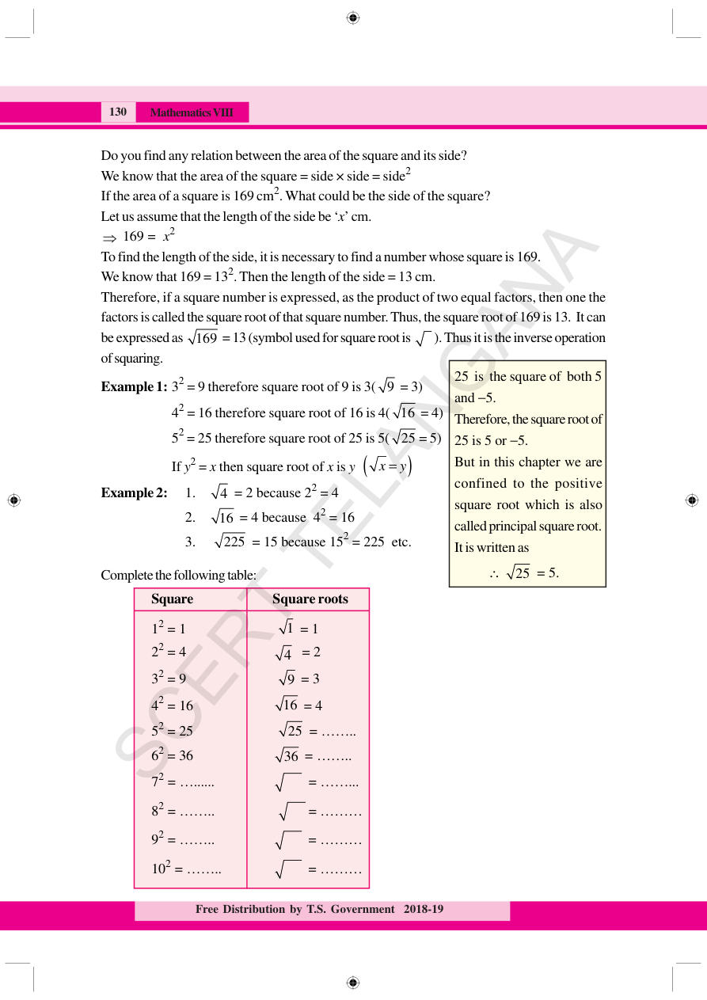

In [ ]:
import fitz
from IPython.display import display, Image

doc = fitz.open("/content/Math.pdf")

page_no = 142
page = doc[page_no - 1]

pix = page.get_pixmap(matrix=fitz.Matrix(1.5, 1.5))

display(Image(data=pix.tobytes("png")))

we visually identify approximately 20 radical symbols, while our detector found 19.

That means we may have a false negative: at least one symbol could have been missed.

In [ ]:
page_no = 142
page = doc[page_no - 1]

candidate_count, unique = detect_radicals(page)

print("Detected unique symbols:", len(unique))

for number, (drawing_id, rect) in enumerate(unique, start=1):
    print(
        f"{number}. Drawing ID: {drawing_id} | "
        f"x={rect.x0:.2f}, y={rect.y0:.2f}"
    )

Detected unique symbols: 20
1. Drawing ID: 11 | x=158.12, y=277.35
2. Drawing ID: 14 | x=349.91, y=279.06
3. Drawing ID: 17 | x=318.59, y=318.00
4. Drawing ID: 20 | x=330.64, y=339.60
5. Drawing ID: 23 | x=330.13, y=361.32
6. Drawing ID: 26 | x=310.96, y=384.31
7. Drawing ID: 29 | x=177.76, y=407.44
8. Drawing ID: 32 | x=177.82, y=428.16
9. Drawing ID: 35 | x=180.71, y=448.65
10. Drawing ID: 38 | x=234.68, y=521.19
11. Drawing ID: 41 | x=231.62, y=543.56
12. Drawing ID: 44 | x=234.65, y=564.31
13. Drawing ID: 47 | x=231.68, y=585.91
14. Drawing ID: 50 | x=234.77, y=607.51
15. Drawing ID: 53 | x=231.65, y=629.22
16. Drawing ID: 57 | x=231.57, y=650.85
17. Drawing ID: 60 | x=234.82, y=675.25
18. Drawing ID: 63 | x=231.57, y=699.66
19. Drawing ID: 66 | x=231.57, y=724.07
20. Drawing ID: 69 | x=426.42, y=475.07


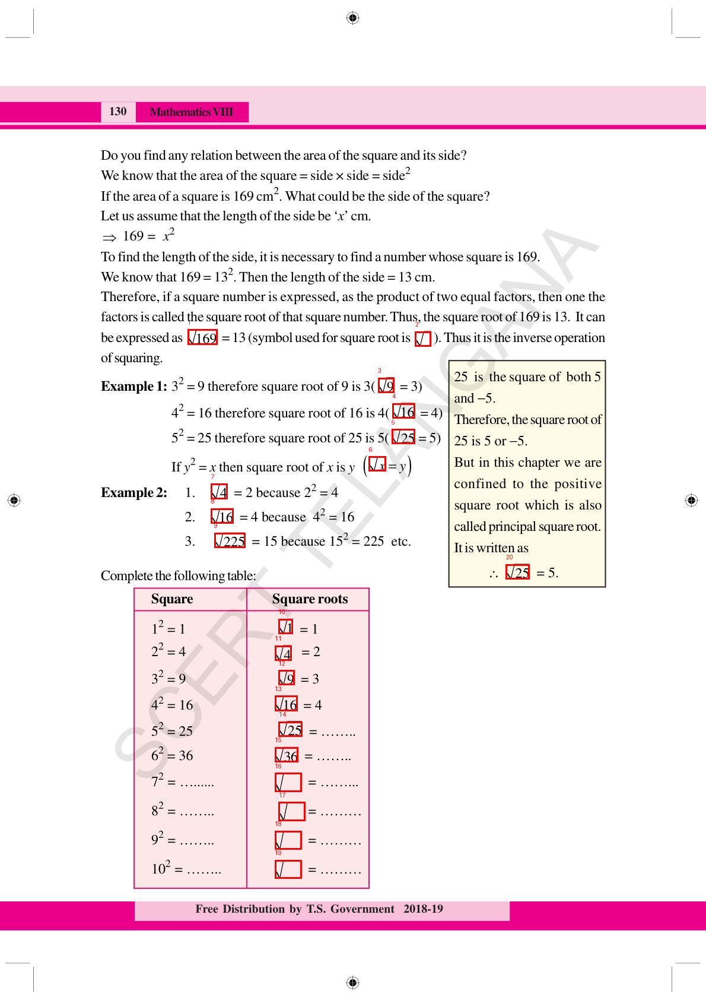

In [ ]:
import fitz
from PIL import Image, ImageDraw
from IPython.display import display

doc = fitz.open("/content/Math.pdf")
page = doc[141]  # PDF page 142

candidate_count, unique = detect_radicals(page)

scale = 2
pix = page.get_pixmap(matrix=fitz.Matrix(scale, scale))

image = Image.frombytes(
    "RGB",
    [pix.width, pix.height],
    pix.samples
)

draw = ImageDraw.Draw(image)

for number, (drawing_id, rect) in enumerate(unique, start=1):
    x0 = rect.x0 * scale
    y0 = rect.y0 * scale
    x1 = rect.x1 * scale
    y1 = rect.y1 * scale

    draw.rectangle(
        [x0, y0, x1, y1],
        outline="red",
        width=3
    )

    draw.text(
        (x0, y0 - 18),
        str(number),
        fill="red"
    )

display(image)

The missed symbol is the first entry in the table:
\[
\sqrt{1}=1
\]

It is not boxed in red, unlike the other radical symbols. This suggests that this particular symbol may be represented differently in the PDF—possibly as a text glyph rather than a vector drawing.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[141]  # PDF page 142

text = page.get_text("text", sort=True)

print("Square-root character present:", "√" in text)
print("\nText around the first table entry:\n")

for line in text.splitlines():
    if "1" in line or "Square roots" in line:
        print(repr(line))

Square-root character present: False

Text around the first table entry:

'    130    Mathematics VIII'
'   If the area of a square is 169 cm2. What could be the side of the square?'
' ⇒ 169 = x2'
'  To find the length of the side, it is necessary to find a number whose square is 169.'
' We know that 169 = 132. Then the length of the side = 13 cm.'
'  factors is called the square root of that square number. Thus, the square root of 169 is 13. It can'
'  be expressed as  169 = 13 (symbol used for square root is      ). Thus it is the inverse operation'
'                                                    25 is the square of both 5  Example 1: 32 = 9 therefore square root of 9 is 3(  9 = 3)'
'             42 = 16 therefore square root of 16 is 4( 16 = 4)                                                                 Therefore, the square root of'
'                                                        confined to the positive  Example 2:   1.   4 = 2 because 22 = 4'
'                  

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[141]  # PDF page 142

print("Drawings near the missing √1 symbol:\n")

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]

    if (
        185 <= rect.x0 <= 230
        and 435 <= rect.y0 <= 470
        and rect.width < 35
        and rect.height < 25
    ):
        print(
            f"\nDrawing ID: {i}"
            f"\nBounding box: {rect}"
            f"\nItems: {drawing['items']}"
        )

Drawings near the missing √1 symbol:



The output is empty because our inspection window was incorrect. The missing √1 is in the first row of the square-roots table, not in the region we searched.

In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[141]

print("Drawing objects near the first square-root table row:\n")

for i, drawing in enumerate(page.get_drawings()):
    rect = drawing["rect"]

    if (
        210 <= rect.x0 <= 270
        and 505 <= rect.y0 <= 545
        and 5 <= rect.width <= 35
        and 3 <= rect.height <= 25
    ):
        print(
            f"Drawing ID: {i}",
            f"| Bounding box: {rect}",
            f"| Items: {len(drawing['items'])}"
        )

Drawing objects near the first square-root table row:

Drawing ID: 38 | Bounding box: Rect(234.68299865722656, 521.1910400390625, 246.81500244140625, 533.8619995117188) | Items: 4
Drawing ID: 39 | Bounding box: Rect(234.59800720214844, 520.907958984375, 246.81500244140625, 533.8619995117188) | Items: 10
Drawing ID: 41 | Bounding box: Rect(231.6219940185547, 543.5570068359375, 245.6529998779297, 556.198974609375) | Items: 4
Drawing ID: 42 | Bounding box: Rect(231.53700256347656, 543.2730102539062, 245.6529998779297, 556.198974609375) | Items: 10


In [ ]:
import fitz

doc = fitz.open("/content/Math.pdf")
page = doc[141]

for drawing_id in [38, 39, 41, 42]:
    drawing = page.get_drawings()[drawing_id]

    print(f"\nDrawing ID: {drawing_id}")
    print("Bounding box:", drawing["rect"])

    for item in drawing["items"]:
        print(item)


Drawing ID: 38
Bounding box: Rect(234.68299865722656, 521.1910400390625, 246.81500244140625, 533.8619995117188)
('l', Point(234.68299865722656, 529.780029296875), Point(235.95899963378906, 529.0999755859375))
('l', Point(235.95899963378906, 529.0999755859375), Point(238.85000610351562, 533.8619995117188))
('l', Point(238.85000610351562, 533.8619995117188), Point(242.08200073242188, 521.1910400390625))
('l', Point(242.08200073242188, 521.1910400390625), Point(246.81500244140625, 521.1910400390625))

Drawing ID: 39
Bounding box: Rect(234.59800720214844, 520.907958984375, 246.81500244140625, 533.8619995117188)
('l', Point(234.59800720214844, 529.6099853515625), Point(236.27099609375, 528.7030029296875))
('l', Point(236.27099609375, 528.7030029296875), Point(238.90699768066406, 532.5870361328125))
('l', Point(238.90699768066406, 532.5870361328125), Point(241.88299560546875, 520.907958984375))
('l', Point(241.88299560546875, 520.907958984375), Point(246.81500244140625, 520.907958984375))
(

We've found exactly why the detector missed \(\sqrt{1}\).

Compare the horizontal bar lengths:
- Drawing 38: 4.73 points
- Drawing 39: 4.93 points
Our strict detector requires the horizontal bar to be at least 5 points long

In [ ]:
candidate_count, unique = detect_radicals(doc[141])

print("PDF Page 142")
print("Candidate drawings:", candidate_count)
print("Unique candidates:", len(unique))

for drawing_id, rect in unique:
    print("Drawing:", drawing_id, "| Position:", rect)

PDF Page 142
Candidate drawings: 36
Unique candidates: 20
Drawing: 11 | Position: Rect(158.11900329589844, 277.35498046875, 183.23399353027344, 290.0260009765625)
Drawing: 14 | Position: Rect(349.9110107421875, 279.0560302734375, 363.46099853515625, 291.697998046875)
Drawing: 17 | Position: Rect(318.5889892578125, 318.0040283203125, 332.4219970703125, 330.67498779296875)
Drawing: 20 | Position: Rect(330.635986328125, 339.60400390625, 349.7409973144531, 352.2749938964844)
Drawing: 23 | Position: Rect(330.1260070800781, 361.3169860839844, 349.9679870605469, 373.9880065917969)
Drawing: 26 | Position: Rect(310.9630126953125, 384.3059997558594, 325.3630065917969, 396.97698974609375)
Drawing: 29 | Position: Rect(177.76300048828125, 407.43701171875, 191.7949981689453, 420.1080017089844)
Drawing: 32 | Position: Rect(177.82000732421875, 428.1579895019531, 196.95399475097656, 440.8290100097656)
Drawing: 35 | Position: Rect(180.71200561523438, 448.65301513671875, 206.53500366210938, 461.324005126

In [ ]:
all_radicals = {}

total_radicals = 0
pages_with_radicals = 0

for page_no in range(1, len(doc) + 1):
    candidate_count, unique = detect_radicals(doc[page_no - 1])

    if unique:
        all_radicals[page_no] = unique
        total_radicals += len(unique)
        pages_with_radicals += 1

print("Total PDF pages:", len(doc))
print("Pages with detected radicals:", pages_with_radicals)
print("Total unique radical symbols:", total_radicals)

print("\nPage-wise results:")
for page_no, symbols in all_radicals.items():
    print(f"Page {page_no}: {len(symbols)} radicals")

Total PDF pages: 370
Pages with detected radicals: 13
Total unique radical symbols: 61

Page-wise results:
Page 107: 1 radicals
Page 142: 20 radicals
Page 143: 2 radicals
Page 144: 6 radicals
Page 145: 1 radicals
Page 147: 2 radicals
Page 148: 2 radicals
Page 149: 3 radicals
Page 150: 7 radicals
Page 156: 3 radicals
Page 157: 12 radicals
Page 158: 1 radicals
Page 241: 1 radicals


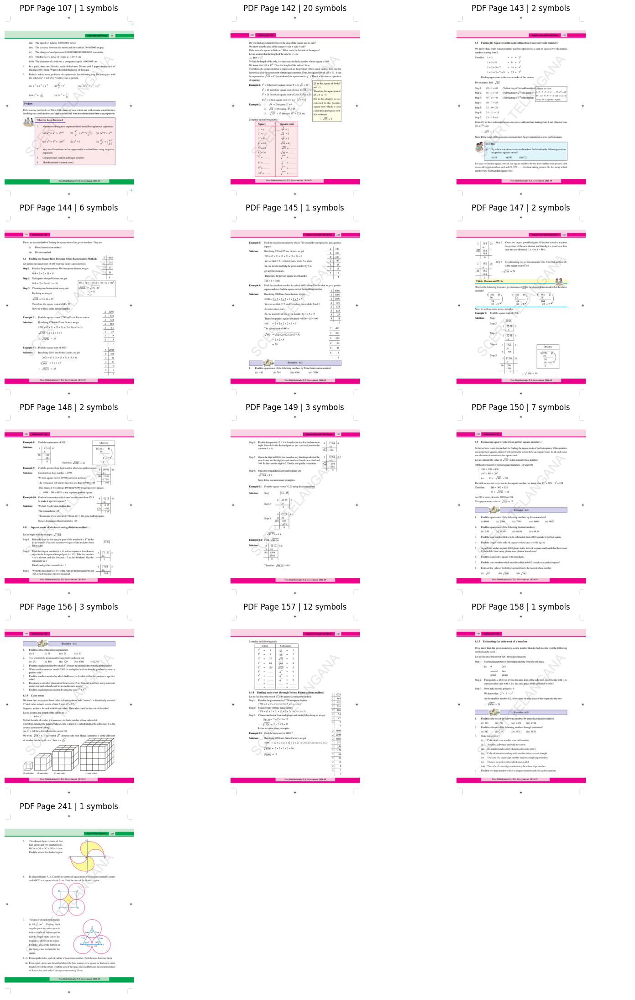

In [ ]:
import matplotlib.pyplot as plt
import fitz

from PIL import Image
from io import BytesIO

pages = list(all_radicals.keys())

fig, axes = plt.subplots(5, 3, figsize=(15, 22))
axes = axes.flatten()

for i, page_no in enumerate(pages):
    page = doc[page_no - 1]

    pix = page.get_pixmap(
        matrix=fitz.Matrix(0.7, 0.7),
        alpha=False
    )

    img = Image.open(BytesIO(pix.tobytes("png")))

    axes[i].imshow(img)
    axes[i].set_title(
        f"PDF Page {page_no} | {len(all_radicals[page_no])} symbols"
    )
    axes[i].axis("off")

for j in range(len(pages), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

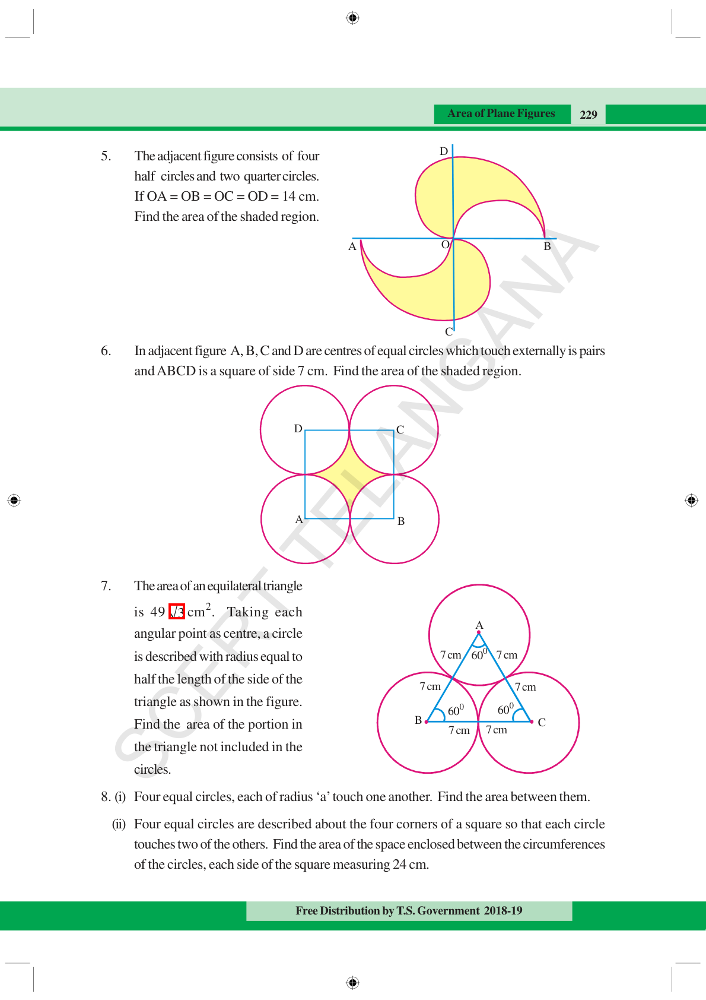

In [ ]:
import fitz
from PIL import Image, ImageDraw
from IPython.display import display

page_no = 241
page = doc[page_no - 1]

pix = page.get_pixmap(
    matrix=fitz.Matrix(2, 2),
    alpha=False
)

img = Image.open(
    __import__("io").BytesIO(pix.tobytes("png"))
)

draw = ImageDraw.Draw(img)

scale = 2

for drawing_id, rect in all_radicals[page_no]:
    box = (
        rect.x0 * scale,
        rect.y0 * scale,
        rect.x1 * scale,
        rect.y1 * scale
    )

    draw.rectangle(box, outline="red", width=4)

display(img)

In [ ]:
import fitz

def extract_radicands(page, detected_symbols):
    raw = page.get_text("rawdict")
    characters = []

    for block in raw["blocks"]:
        for line in block.get("lines", []):
            for span in line["spans"]:
                for char in span["chars"]:
                    characters.append({
                        "char": char["c"],
                        "bbox": fitz.Rect(char["bbox"])
                    })

    results = []

    for drawing_id, rect in detected_symbols:
        nearby_chars = [
            c for c in characters
            if c["bbox"].x0 >= rect.x0 + 5
            and c["bbox"].x1 <= rect.x1 + 2
            and abs(c["bbox"].y0 - rect.y0) < 5
            and c["char"].strip()
        ]

        nearby_chars.sort(key=lambda c: c["bbox"].x0)

        radicand = "".join(c["char"] for c in nearby_chars)

        results.append({
            "drawing_id": drawing_id,
            "radical_box": rect,
            "radicand_candidate": radicand
        })

    return results


for page_no in [150, 156, 241]:
    results = extract_radicands(
        doc[page_no - 1],
        all_radicals[page_no]
    )

    print(f"\n{'=' * 45}")
    print(f"PDF PAGE {page_no}")
    print("=" * 45)

    for item in results:
        print(
            f"Drawing {item['drawing_id']} "
            f"-> √{item['radicand_candidate']}"
        )


PDF PAGE 150
Drawing 9 -> √300
Drawing 12 -> √300
Drawing 15 -> √300
Drawing 18 -> √300
Drawing 21 -> √97
Drawing 24 -> √250
Drawing 27 -> √780

PDF PAGE 156
Drawing 9 -> √64
Drawing 12 -> √
Drawing 16 -> √y

PDF PAGE 241
Drawing 8 -> √3


The association method is finding characters positioned under the radical bar. It does not yet understand the mathematical meaning of the expression. For example, √ without a radicand may be intentional if the expression continues elsewhere.

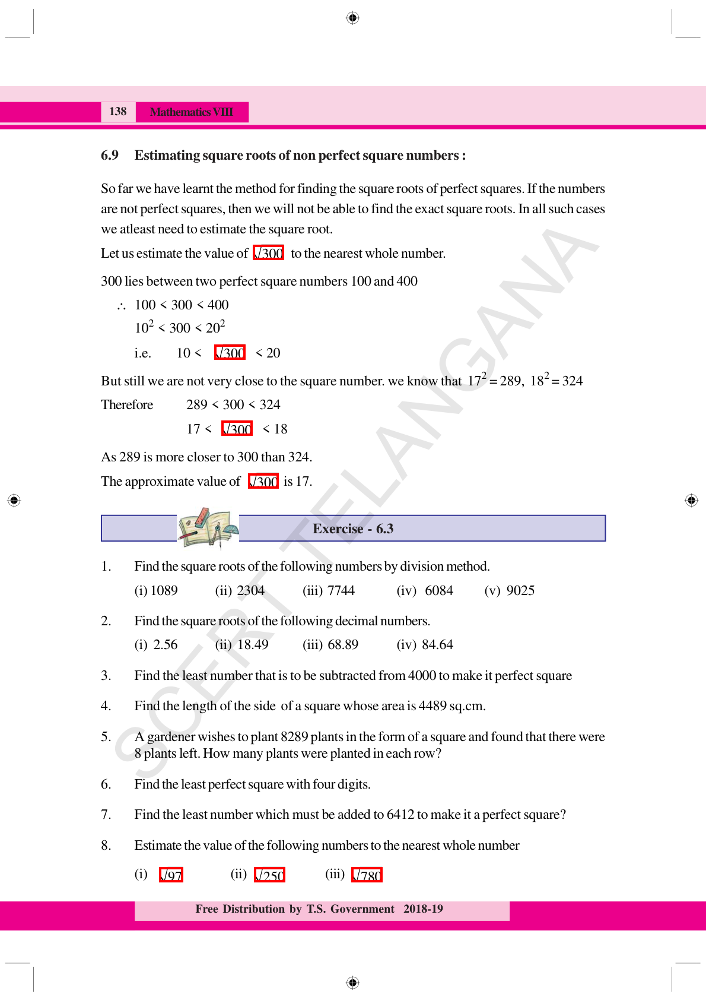

In [ ]:
import fitz
from PIL import Image, ImageDraw
from IPython.display import display
from io import BytesIO

page_no = 150
page = doc[page_no - 1]

pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))
img = Image.open(BytesIO(pix.tobytes("png")))

draw = ImageDraw.Draw(img)

for drawing_id, rect in all_radicals[page_no]:
    box = (
        rect.x0 * 2,
        rect.y0 * 2,
        rect.x1 * 2,
        rect.y1 * 2
    )
    draw.rectangle(box, outline="red", width=4)

display(img)

In [ ]:
page_no = 142

results = extract_radicands(
    doc[page_no - 1],
    all_radicals[page_no]
)

for item in results:
    print(
        f"Drawing {item['drawing_id']} "
        f"-> √{item['radicand_candidate']}"
    )

Drawing 11 -> √169
Drawing 14 -> √
Drawing 17 -> √9
Drawing 20 -> √16
Drawing 23 -> √25
Drawing 26 -> √x
Drawing 29 -> √4
Drawing 32 -> √16
Drawing 35 -> √225
Drawing 38 -> √1
Drawing 41 -> √4
Drawing 44 -> √9
Drawing 47 -> √16
Drawing 50 -> √25
Drawing 53 -> √36
Drawing 57 -> √
Drawing 60 -> √
Drawing 63 -> √
Drawing 66 -> √
Drawing 69 -> √25


The results show that the detector is finding the radical symbols, but some radicands are incomplete or missing.

In [ ]:
page = doc[141]
raw = page.get_text("rawdict")

for drawing_id, rect in all_radicals[142]:
    print(f"\nDrawing {drawing_id} | {rect}")

    for block in raw["blocks"]:
        for line in block.get("lines", []):
            for span in line["spans"]:
                for char in span["chars"]:
                    bbox = fitz.Rect(char["bbox"])

                    if (
                        bbox.x0 >= rect.x0 - 5
                        and bbox.x0 <= rect.x1 + 5
                        and abs(bbox.y0 - rect.y0) < 5
                        and char["c"].strip()
                    ):
                        print(
                            repr(char["c"]),
                            "x0:", round(bbox.x0, 2),
                            "x1:", round(bbox.x1, 2),
                            "y0:", round(bbox.y0, 2)
                        )


Drawing 11 | Rect(158.11900329589844, 277.35498046875, 183.23399353027344, 290.0260009765625)
'1' x0: 164.7 x1: 170.7 y0: 276.26
'6' x0: 170.75 x1: 176.75 y0: 276.26
'9' x0: 176.8 x1: 182.8 y0: 276.26
'=' x0: 187.12 x1: 193.89 y0: 275.41

Drawing 14 | Rect(349.9110107421875, 279.0560302734375, 363.46099853515625, 291.697998046875)
')' x0: 365.56 x1: 369.55 y0: 275.41

Drawing 17 | Rect(318.5889892578125, 318.0040283203125, 332.4219970703125, 330.67498779296875)
'9' x0: 326.04 x1: 332.04 y0: 316.91
'=' x0: 337.01 x1: 343.78 y0: 316.42

Drawing 20 | Rect(330.635986328125, 339.60400390625, 349.7409973144531, 352.2749938964844)
'1' x0: 337.24 x1: 343.24 y0: 338.5
'6' x0: 343.28 x1: 349.28 y0: 338.5
'=' x0: 354.21 x1: 360.98 y0: 338.76

Drawing 23 | Rect(330.1260070800781, 361.3169860839844, 349.9679870605469, 373.9880065917969)
'2' x0: 337.89 x1: 343.89 y0: 360.22
'5' x0: 343.85 x1: 349.85 y0: 360.22
'=' x0: 352.8 x1: 359.57 y0: 359.71

Drawing 26 | Rect(310.9630126953125, 384.30599975585

In [ ]:
results = extract_radicands(
    doc[141],
    all_radicals[142]
)

for item in results:
    print(
        f"Drawing {item['drawing_id']} "
        f"-> √{item['radicand_candidate']}"
    )

Drawing 11 -> √169
Drawing 14 -> √
Drawing 17 -> √9
Drawing 20 -> √16
Drawing 23 -> √25
Drawing 26 -> √x
Drawing 29 -> √4
Drawing 32 -> √16
Drawing 35 -> √225
Drawing 38 -> √1
Drawing 41 -> √4
Drawing 44 -> √9
Drawing 47 -> √16
Drawing 50 -> √25
Drawing 53 -> √36
Drawing 57 -> √
Drawing 60 -> √
Drawing 63 -> √
Drawing 66 -> √
Drawing 69 -> √25


In [ ]:
for page_no in [150, 156, 241]:
    results = extract_radicands(
        doc[page_no - 1],
        all_radicals[page_no]
    )

    print(f"\nPDF PAGE {page_no}")

    for item in results:
        print(
            f"Drawing {item['drawing_id']} "
            f"-> √{item['radicand_candidate']}"
        )


PDF PAGE 150
Drawing 9 -> √300
Drawing 12 -> √300
Drawing 15 -> √300
Drawing 18 -> √300
Drawing 21 -> √97
Drawing 24 -> √250
Drawing 27 -> √780

PDF PAGE 156
Drawing 9 -> √64
Drawing 12 -> √
Drawing 16 -> √y

PDF PAGE 241
Drawing 8 -> √3



Drawing 14: Rect(349.9110107421875, 279.0560302734375, 363.46099853515625, 291.697998046875)


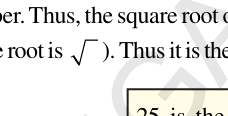


Drawing 57: Rect(231.56500244140625, 650.8480224609375, 254.12899780273438, 666.636962890625)


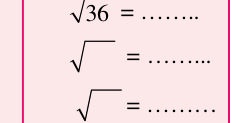


Drawing 60: Rect(234.8249969482422, 675.2540283203125, 257.3599853515625, 691.04296875)


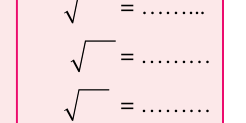


Drawing 63: Rect(231.56500244140625, 699.6610107421875, 254.12899780273438, 715.4210205078125)


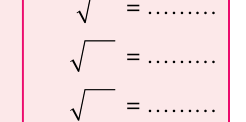


Drawing 66: Rect(231.56500244140625, 724.0670166015625, 254.12899780273438, 739.8270263671875)


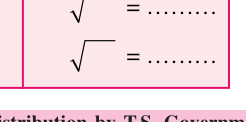

In [ ]:
page_no = 142

empty_ids = [14, 57, 60, 63, 66]

for drawing_id in empty_ids:
    rect = next(
        rect for did, rect in all_radicals[page_no]
        if did == drawing_id
    )

    print(f"\nDrawing {drawing_id}: {rect}")

    pix = doc[page_no - 1].get_pixmap(
        matrix=fitz.Matrix(2, 2),
        clip=fitz.Rect(
            rect.x0 - 35,
            rect.y0 - 20,
            rect.x1 + 65,
            rect.y1 + 25
        )
    )

    from IPython.display import display, Image
    display(Image(data=pix.tobytes("png")))

In [ ]:
import json
import re

CHUNK_SIZE = 1200
CHUNK_OVERLAP = 150

math_chunks = []

def create_chunks(text, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    text = re.sub(r'\n+', '\n', text).strip()

    paragraphs = [
        p.strip() for p in text.split('\n')
        if p.strip()
    ]

    chunks = []
    current_chunk = ""

    for paragraph in paragraphs:
        if len(current_chunk) + len(paragraph) <= chunk_size:
            current_chunk += paragraph + "\n"
        else:
            if current_chunk.strip():
                chunks.append(current_chunk.strip())

            current_chunk = current_chunk[-overlap:] + paragraph + "\n"

    if current_chunk.strip():
        chunks.append(current_chunk.strip())

    return chunks


for _, row in df.iterrows():
    page_chunks = create_chunks(row["text"])

    for chunk_index, chunk_text in enumerate(page_chunks):
        math_chunks.append({
            "subject": "Mathematics",
            "grade": 8,
            "source_file": row["source_file"],
            "page": int(row["page"]),
            "chunk_index": chunk_index,
            "text": chunk_text
        })


OUTPUT_PATH = "/content/mathematics_chunks.jsonl"

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    for chunk in math_chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

print("Total Mathematics chunks:", len(math_chunks))
print("Output saved:", OUTPUT_PATH)

print("\nSample original chunk:")
print(json.dumps(math_chunks[0], indent=2, ensure_ascii=False))

Total Mathematics chunks: 589
Output saved: /content/mathematics_chunks.jsonl

Sample original chunk:
{
  "subject": "Mathematics",
  "grade": 8,
  "source_file": "Math(1).pdf",
  "page": 1,
  "chunk_index": 0,
  "text": "SCERT TELANGANA"
}


In [ ]:
import pandas as pd

chunk_df = pd.DataFrame(math_chunks)

chunk_df["char_count"] = chunk_df["text"].str.len()

print("Total chunks:", len(chunk_df))
print("\nChunk length statistics:")
print(chunk_df["char_count"].describe())

print("\nChunks shorter than 100 characters:")
print(
    chunk_df[chunk_df["char_count"] < 100][
        ["page", "chunk_index", "text", "char_count"]
    ].head(20).to_string(index=False)
)

print("\nFive longer sample chunks:")
for i, row in chunk_df.nlargest(5, "char_count").iterrows():
    print(f"\nPage {row['page']} | {row['char_count']} characters")
    print(row["text"][:500])

Total chunks: 589

Chunk length statistics:
count     589.000000
mean      871.803056
std       337.137765
min        15.000000
25%       572.000000
50%      1013.000000
75%      1171.000000
max      1200.000000
Name: char_count, dtype: float64

Chunks shorter than 100 characters:
 page  chunk_index            text  char_count
    1            0 SCERT TELANGANA          15

Five longer sample chunks:

Page 23 | 1200 characters
Free Distribution by T.S. Government  2018-19
Rational Numbers
11
Find
1
3
4
2
7
3


+
+




and
1
3
4
2
7
3




+
+ 







Are the two sums equal?
Take some more rational numbers and verify the associativity.
We find rational numbers satisfy associative property under addition.
a + (b + c)  =  (a + b) + c for any three rational numbers a, b and c.
i.e., ∀ a, b, c ∈ Q,   a + (b + c) = (a + b) + c
(b)
Subtraction
Let us take  any three rational numbers 1
3
,
2
4 and 5
4
−
Verif

Page 28 | 1200 characters
Mathematics VIII
16
Free Distribution by 

1. Unnecessary content: Page 1 contains only SCERT TELANGANA. This is not a useful learning chunk.
2. Mathematical notation: Some fractions, exponents and equations are broken into separate lines during PDF extraction. For example, the samples from pages 23 and 28 show this problem.
We should preserve the original extracted text and correct the mathematical notation using the original PDF before training.

In [ ]:
# Identify chunks that may need correction

review_chunks = []

for chunk in math_chunks:
    text = chunk["text"].strip()

    issues = []

    if len(text) < 100:
        issues.append("Very short content")

    if any(symbol in text for symbol in ["", "", "", "", "", ""]):
        issues.append("Broken mathematical formatting")

    if text.count("\n") > 20:
        issues.append("Excessive line breaks")

    if issues:
        review_chunks.append({
            "page": chunk["page"],
            "chunk_index": chunk["chunk_index"],
            "issues": issues,
            "text": text
        })

print("Chunks requiring review:", len(review_chunks))

for item in review_chunks[:10]:
    print("\nPage:", item["page"])
    print("Issues:", item["issues"])
    print("Text:", item["text"][:500])

Chunks requiring review: 461

Page: 1
Issues: ['Very short content']
Text: SCERT TELANGANA

Page: 2
Issues: ['Excessive line breaks']
Text: CHILDREN! THESE DIINSTRUCTIONS FOR YOU...
♦
For each and every conceptual understanding, a real life context with appropriate
illustrations are given in the textbook. Try to understand the concept through keen
reading of context along with observation of illustration.
♦
While understanding the concepts through activities, some doubts may arise.
Clarify those doubts by through discussion with your friends and teachers,
understand the mathematical concepts without any doubts.
♦
''Do this/Do these"

Page: 2
Issues: ['Excessive line breaks']
Text: nsive understanding of the concept by thinking critically. These activities should
be solved by discussions with your fellow students and teachers.
♦
Different typs of problems with different concepts discussed in the chapter are
given in an "Exercise" given at the end of the concept/chapter. Try to solve the

In [ ]:
from collections import Counter

issue_counts = Counter()

for item in review_chunks:
    for issue in item["issues"]:
        issue_counts[issue] += 1

print("Review reasons:")
for issue, count in issue_counts.items():
    print(f"{issue}: {count}")

print("\nChunks per page (first 30 pages):")

for page in range(1, 31):
    page_items = [
        item for item in review_chunks
        if item["page"] == page
    ]

    if page_items:
        print(f"Page {page}: {len(page_items)} flagged chunks")

print("\nTotal chunks:", len(math_chunks))
print("Total flagged:", len(review_chunks))

Review reasons:
Very short content: 1
Excessive line breaks: 460
Broken mathematical formatting: 9

Chunks per page (first 30 pages):
Page 1: 1 flagged chunks
Page 2: 2 flagged chunks
Page 3: 1 flagged chunks
Page 4: 1 flagged chunks
Page 5: 2 flagged chunks
Page 11: 1 flagged chunks
Page 12: 1 flagged chunks
Page 13: 2 flagged chunks
Page 14: 1 flagged chunks
Page 15: 2 flagged chunks
Page 16: 2 flagged chunks
Page 17: 1 flagged chunks
Page 18: 1 flagged chunks
Page 19: 1 flagged chunks
Page 20: 1 flagged chunks
Page 21: 2 flagged chunks
Page 22: 2 flagged chunks
Page 23: 2 flagged chunks
Page 24: 2 flagged chunks
Page 25: 1 flagged chunks
Page 26: 1 flagged chunks
Page 27: 2 flagged chunks
Page 28: 2 flagged chunks
Page 29: 1 flagged chunks
Page 30: 1 flagged chunks

Total chunks: 589
Total flagged: 461


In [ ]:
for item in review_chunks:
    if "Broken mathematical formatting" in item["issues"]:
        print("\n" + "=" * 70)
        print("Page:", item["page"])
        print("Chunk:", item["chunk_index"])
        print("Text:")
        print(item["text"])


Page: 22
Chunk: 0
Text:
Mathematics VIII
10
Free Distribution by T.S. Government  2018-19
(ii)
Integers
Recall associativity for integers under four operations.
Complete  the following table with necessary remarks.
Operation
Integers with example
Remark
Addition
Is 2 + [(−3) + 5)] = [(2 + (−3)] + 5 ?
(
)
[
]
2
3
5
2
3
5
2
2
4
+ −
+ =
+ −+
=
+
=


—  —  — —  —
(
)
[
]
2
3
5
2
3
5
1 5
4
+ −
+
=
−
+
= −+
=




For any three integers a, b and c
a + (b + c) = (a + b) + c
Subtraction
Is 6 − (9 − 5) = (6 − 9)  − 5  ?
—  —  — —  —
Multiplication
Is 2×[7×( −3)] = (2×7) × (−3)  ?
—  —  — —  —
Division
(
)
(
)
10
2
5
[10
2]
5
÷ ÷ −
=
÷
÷ −


?
(
)
2
5
10
2
5
10
10
25
5
2
−
−
÷
÷ −
=
÷
=
×
= −




—  —  — —  —
Now
(
)
(
)
(
)
(
)
10
5
10 2
5
5
5
5
1
2
5
÷
÷ −
=
÷ −
=
÷ −
=
=−
−
Thus
(
)
[
]
(
)
10
2
5
10
2
5
÷
÷ −
≠
÷
÷ −




(iii)
Rational numbers
(a)
Addition
Let us consider three rational numbers 2
1
, 5,
7
2 and verify whether
2
1
2
1
5
5
7
2
7
2










+
+
=


They occur on textbook pages 22, 23, 102, 103, 104, 215 and 237. They contain fractions, powers, brackets, equations and mathematical symbols that PDF text extraction has not preserved correctly.


Original PDF page: 22


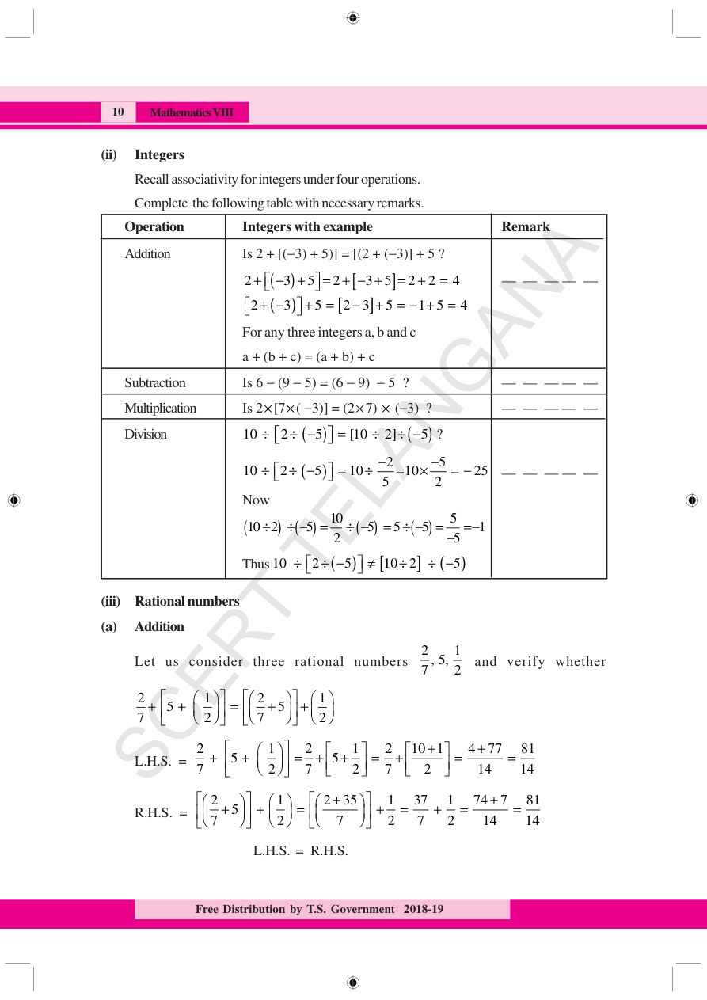


Original PDF page: 23


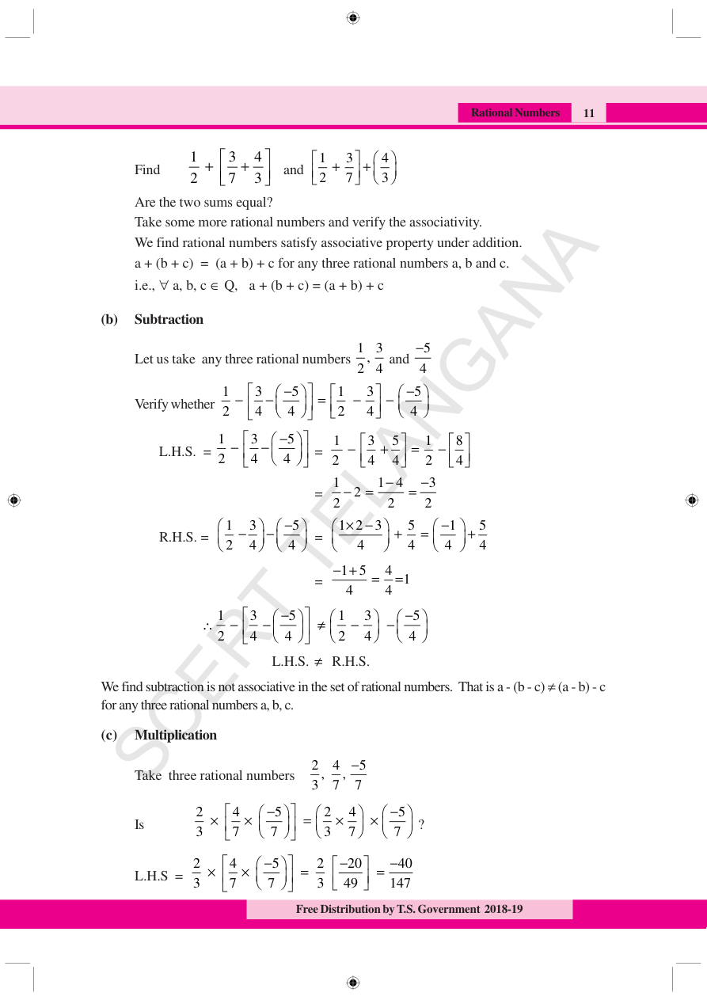


Original PDF page: 102


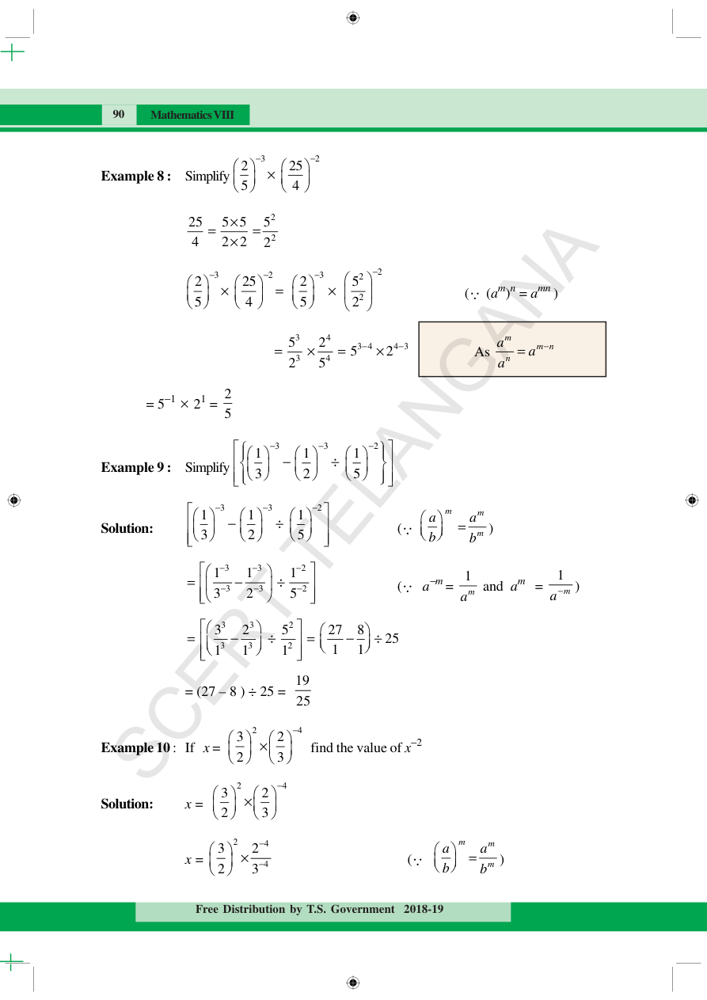


Original PDF page: 103


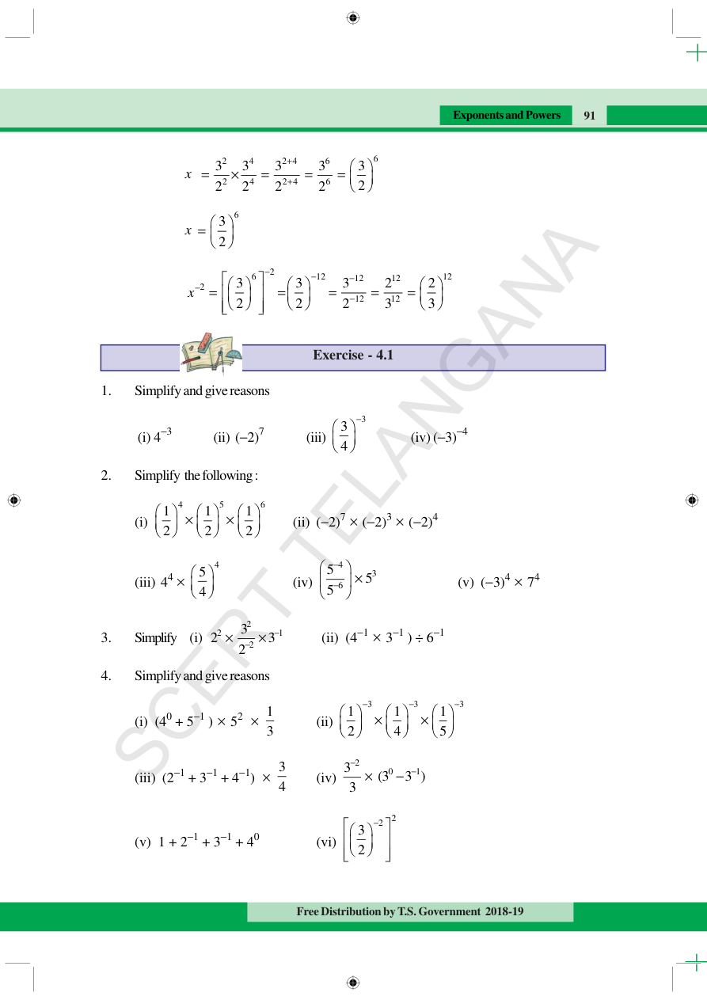


Original PDF page: 104


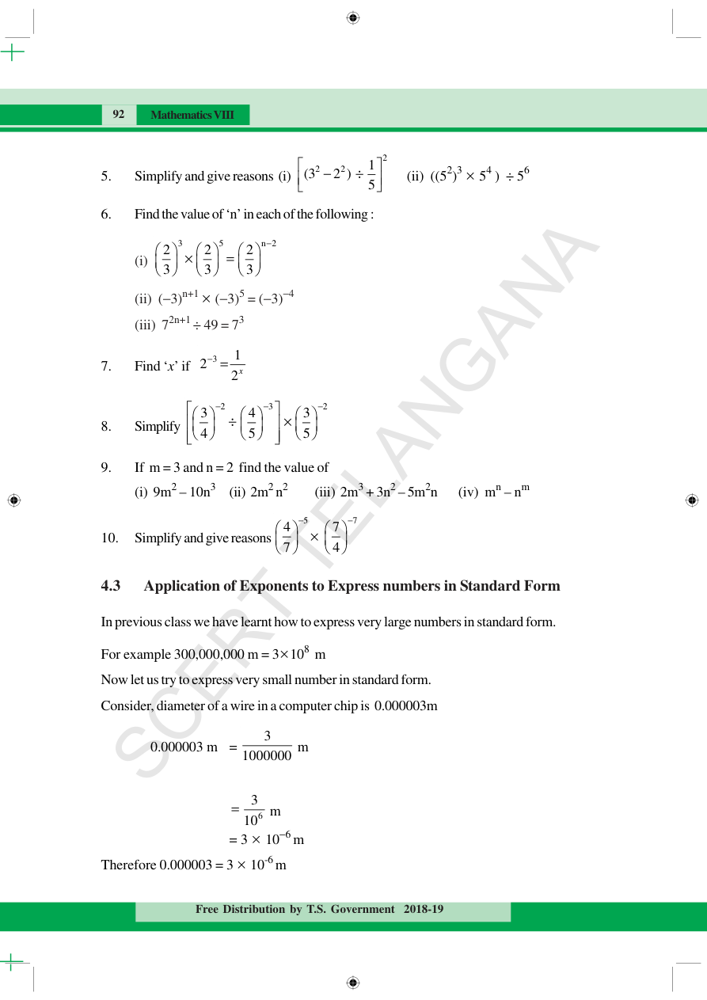


Original PDF page: 215


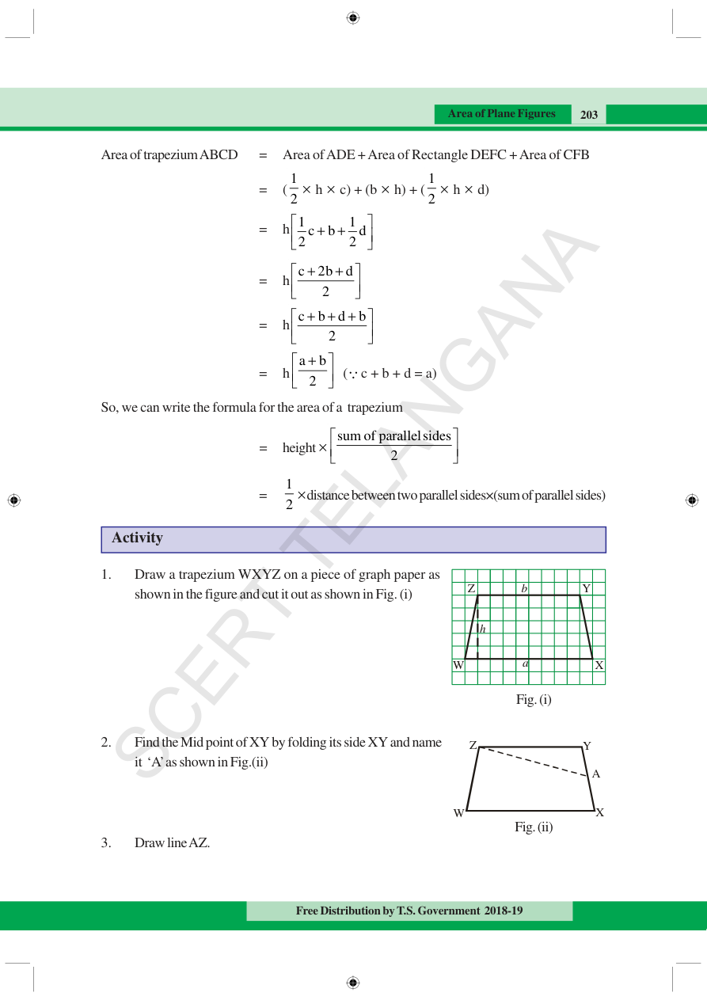


Original PDF page: 237


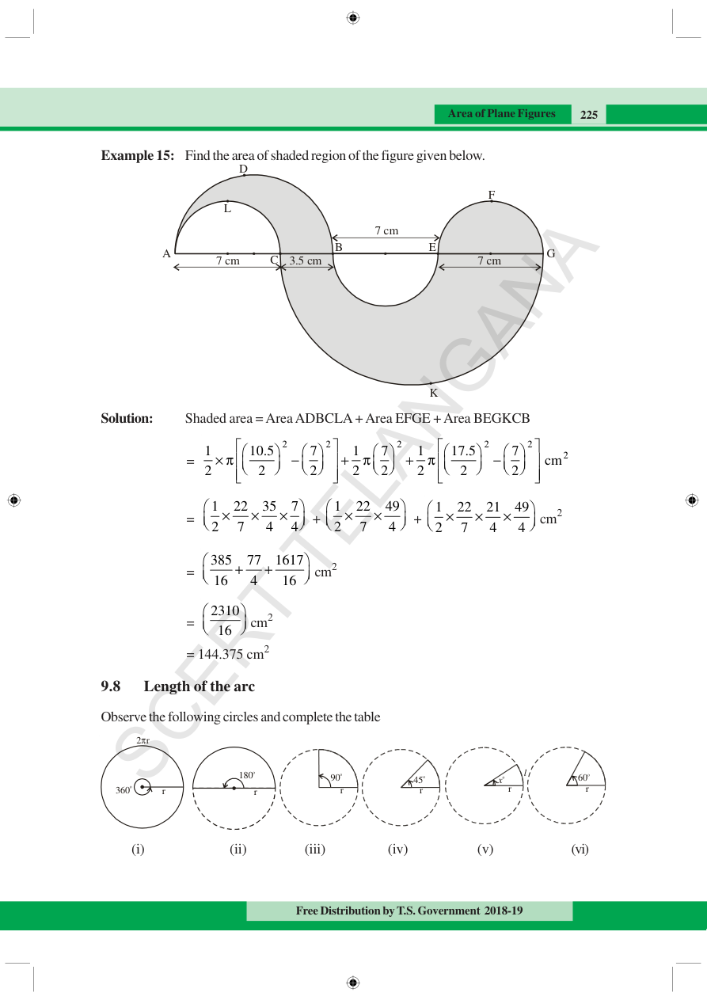

In [ ]:
import pymupdf
from IPython.display import display, Image
from pathlib import Path

pdf_path = "/content/Math.pdf"
doc = pymupdf.open(pdf_path)

pages_to_check = [22, 23, 102, 103, 104, 215, 237]

output_dir = Path("/content/math_review_pages")
output_dir.mkdir(exist_ok=True)

for page_num in pages_to_check:
    page = doc[page_num - 1]

    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(1.5, 1.5),
        alpha=False
    )

    image_path = output_dir / f"page_{page_num}.png"
    pix.save(str(image_path))

    print(f"\nOriginal PDF page: {page_num}")
    display(Image(filename=str(image_path)))

doc.close()

PDF page 22: Fractions, brackets and division expressions are split into separate lines.



PDF page 23: Rational-number fractions and subtraction expressions are broken apart.



PDF pages 102–104: Superscripts, negative powers, fractions and exercise expressions need reconstruction.



PDF page 215: The trapezium area derivation contains fractions and bracketed expressions.



PDF page 237: The shaded-area solution contains complex expressions involving π, fractions and squared terms.

original_text — untouched PDF extraction for traceability.



verified_text — corrected mathematical notation checked against the original page.

In [ ]:
import json

correction_dataset = []

for item in review_chunks:
    if "Broken mathematical formatting" in item["issues"]:
        original_chunk = next(
            chunk for chunk in math_chunks
            if chunk["page"] == item["page"]
            and chunk["chunk_index"] == item["chunk_index"]
        )

        correction_dataset.append({
            "subject": original_chunk["subject"],
            "grade": original_chunk["grade"],
            "source_file": original_chunk["source_file"],
            "page": original_chunk["page"],
            "chunk_index": original_chunk["chunk_index"],
            "original_text": original_chunk["text"],
            "verified_text": "",
            "status": "needs_review"
        })

OUTPUT_PATH = "/content/mathematics_corrections.jsonl"

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    for item in correction_dataset:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Correction records:", len(correction_dataset))
print("Saved to:", OUTPUT_PATH)
print("\nFirst record:")
print(json.dumps(correction_dataset[0], indent=2, ensure_ascii=False))

Correction records: 9
Saved to: /content/mathematics_corrections.jsonl

First record:
{
  "subject": "Mathematics",
  "grade": 8,
  "source_file": "Math(1).pdf",
  "page": 22,
  "chunk_index": 0,
  "original_text": "Mathematics VIII\n10\nFree Distribution by T.S. Government  2018-19\n(ii)\nIntegers\nRecall associativity for integers under four operations.\nComplete  the following table with necessary remarks.\nOperation\nIntegers with example\nRemark\nAddition\nIs 2 + [(−3) + 5)] = [(2 + (−3)] + 5 ?\n(\n)\n[\n]\n2\n3\n5\n2\n3\n5\n2\n2\n4\n+ −\n+ =\n+ −+\n=\n+\n=\n\n\n—  —  — —  —\n(\n)\n[\n]\n2\n3\n5\n2\n3\n5\n1 5\n4\n+ −\n+\n=\n−\n+\n= −+\n=\n\n\n\n\nFor any three integers a, b and c\na + (b + c) = (a + b) + c\nSubtraction\nIs 6 − (9 − 5) = (6 − 9)  − 5  ?\n—  —  — —  —\nMultiplication\nIs 2×[7×( −3)] = (2×7) × (−3)  ?\n—  —  — —  —\nDivision\n(\n)\n(\n)\n10\n2\n5\n[10\n2]\n5\n÷ ÷ −\n=\n÷\n÷ −\n\n\n?\n(\n)\n2\n5\n10\n2\n5\n10\n10\n25\n5\n2\n−\n−\n÷\n÷ −\n=\n÷\n=\n×\n= −\n

In [ ]:
for i, item in enumerate(correction_dataset, start=1):
    print("\n" + "=" * 60)
    print(f"Record: {i}")
    print("Page:", item["page"])
    print("Chunk:", item["chunk_index"])
    print("Characters:", len(item["original_text"]))
    print("Status:", item["status"])
    print("Preview:")
    print(item["original_text"][:350])


Record: 1
Page: 22
Chunk: 0
Characters: 1199
Status: needs_review
Preview:
Mathematics VIII
10
Free Distribution by T.S. Government  2018-19
(ii)
Integers
Recall associativity for integers under four operations.
Complete  the following table with necessary remarks.
Operation
Integers with example
Remark
Addition
Is 2 + [(−3) + 5)] = [(2 + (−3)] + 5 ?
(
)
[
]
2
3
5
2
3
5
2
2
4
+ −
+ =
+ −+
=
+
=


—  —  — —  —
(
)
[
]


Record: 2
Page: 22
Chunk: 1
Characters: 261
Status: needs_review
Preview:
1
5
5
7
2
7
2
7
2
14
14


+
+






+
+
=
+
+
=
+
=
=
















R.H.S.  =
2
1
2
35
1
37
1
74
7
81
5
7
2
7
2
7
2
14
14



+

+






+
+
=
+
=
+
=
=




















L.H.S.  =  R.H.S.
SCERT TELANGANA

Record: 3
Page: 23
Chunk: 0
Characters: 1200
Status: needs_review
Preview:
Free Distribution by T.S. Government  2018-19
Rational Numbers
11
Find
1
3
4
2
7
3


+
+




and
1
3
4
2
7
3




+
+ 







Are the two sums 

In [ ]:
from collections import defaultdict

page_groups = defaultdict(list)

for item in correction_dataset:
    page_groups[item["page"]].append(item)

page_correction_workspace = []

for page, records in sorted(page_groups.items()):
    records = sorted(records, key=lambda x: x["chunk_index"])

    page_correction_workspace.append({
        "subject": "Mathematics",
        "grade": 8,
        "source_file": records[0]["source_file"],
        "page": page,
        "original_chunks": [
            {
                "chunk_index": r["chunk_index"],
                "text": r["original_text"]
            }
            for r in records
        ],
        "verified_text": "",
        "status": "needs_review"
    })

print("Pages requiring correction:", len(page_correction_workspace))

for item in page_correction_workspace:
    print(
        f"Page {item['page']}: "
        f"{len(item['original_chunks'])} original chunks"
    )

Pages requiring correction: 7
Page 22: 2 original chunks
Page 23: 2 original chunks
Page 102: 1 original chunks
Page 103: 1 original chunks
Page 104: 1 original chunks
Page 215: 1 original chunks
Page 237: 1 original chunks


In [ ]:
page_22_text = """
(ii) Integers

Recall associativity for integers under four operations.
Complete the following table with necessary remarks.

Addition

Is 2 + [(-3) + 5] = [2 + (-3)] + 5?

2 + [(-3) + 5] = 2 + [-3 + 5] = 2 + 2 = 4

[2 + (-3)] + 5 = [2 - 3] + 5 = -1 + 5 = 4

For any three integers a, b and c:

a + (b + c) = (a + b) + c

Subtraction

Is 6 - (9 - 5) = (6 - 9) - 5?

Multiplication

Is 2 × [7 × (-3)] = (2 × 7) × (-3)?

Division

10 ÷ [2 ÷ (-5)] = [10 ÷ 2] ÷ (-5)?

10 ÷ [2 ÷ (-5)] = 10 ÷ (-2/5)
= 10 × (-5/2) = -25

(10 ÷ 2) ÷ (-5) = 5 ÷ (-5) = -1

Thus,

10 ÷ [2 ÷ (-5)] ≠ [10 ÷ 2] ÷ (-5)

(iii) Rational numbers

(a) Addition

Let us consider three rational numbers 2/7, 5, 1/2
and verify whether:

2/7 + [5 + (1/2)] = [(2/7 + 5) + (1/2)]

L.H.S. = 2/7 + [5 + (1/2)]
= 2/7 + [(10 + 1)/2]
= 2/7 + 11/2
= (4 + 77)/14
= 81/14

R.H.S. = [(2/7 + 5) + (1/2)]
= [(2 + 35)/7] + 1/2
= 37/7 + 1/2
= (74 + 7)/14
= 81/14

L.H.S. = R.H.S.
"""

page_22 = next(
    item for item in page_correction_workspace
    if item["page"] == 22
)

page_22["verified_text"] = page_22_text
page_22["status"] = "transcribed_needs_validation"

print("Page:", page_22["page"])
print("Status:", page_22["status"])
print("Verified text characters:", len(page_22["verified_text"]))

Page: 22
Status: transcribed_needs_validation
Verified text characters: 929


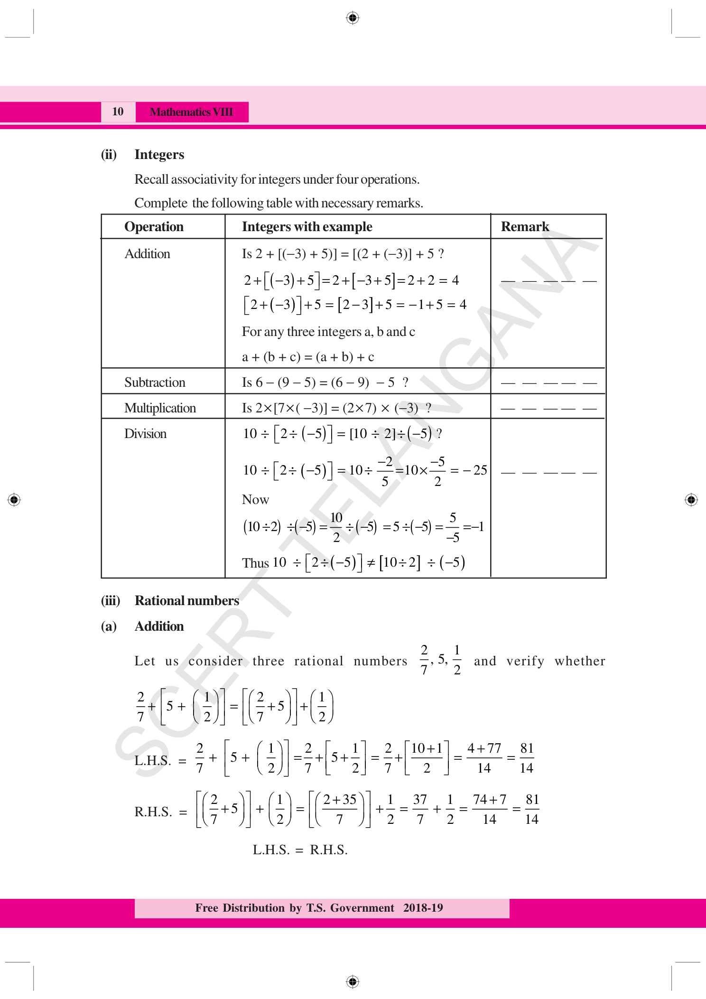

In [ ]:
import pymupdf
from IPython.display import display, Image

doc = pymupdf.open("/content/Math.pdf")

page = doc[21]  # PDF page 22

pix = page.get_pixmap(
    matrix=pymupdf.Matrix(2.5, 2.5),
    alpha=False
)

pix.save("/content/page_22_verification.png")

display(Image(filename="/content/page_22_verification.png"))

doc.close()

In [ ]:
page_22["status"] = "verified_against_original_pdf"

print("Page:", page_22["page"])
print("Status:", page_22["status"])
print("Verified text characters:", len(page_22["verified_text"]))

Page: 22
Status: verified_against_original_pdf
Verified text characters: 929


In [ ]:
page_23_text = """
Rational Numbers

(a) Addition

Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.

We find rational numbers satisfy associative property under addition.

a + (b + c) = (a + b) + c

for any three rational numbers a, b and c.

i.e., ∀ a, b, c ∈ Q,

a + (b + c) = (a + b) + c

(b) Subtraction

Let us take any three rational numbers 1/2, 3/4 and -5/4.

Verify whether:

1/2 - [3/4 - (-5/4)]
=
[1/2 - 3/4] - (-5/4)

L.H.S. = 1/2 - [3/4 - (-5/4)]
= 1/2 - [3/4 + 5/4]
= 1/2 - 8/4
= 1/2 - 2
= (1 - 4)/2
= -3/2

R.H.S. = (1/2 - 3/4) - (-5/4)
= ((1 × 2 - 3)/4) + 5/4
= (-1/4) + 5/4
= (-1 + 5)/4
= 4/4 = 1

Therefore,

1/2 - [3/4 - (-5/4)]
≠ (1/2 - 3/4) - (-5/4)

L.H.S. ≠ R.H.S.

We find subtraction is not associative in the set of rational numbers.

That is, a - (b - c) ≠ (a - b) - c
for any three rational numbers a, b, c.

(c) Multiplication

Take three rational numbers 2/3, 4/7, -5/7.

Is

2/3 × [4/7 × (-5/7)]
=
(2/3 × 4/7) × (-5/7)?

L.H.S. = 2/3 × [4/7 × (-5/7)]
= 2/3 × (-20/49)
= -40/147
"""

page_23 = next(
    item for item in page_correction_workspace
    if item["page"] == 23
)

page_23["verified_text"] = page_23_text
page_23["status"] = "transcribed_needs_validation"

print("Page:", page_23["page"])
print("Status:", page_23["status"])
print("Verified text characters:", len(page_23["verified_text"]))

Page: 23
Status: transcribed_needs_validation
Verified text characters: 1081


In [ ]:
addition_intro = """
Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.
"""

page_23["verified_text"] = page_23_text.replace(
    "(a) Addition",
    "(a) Addition\n" + addition_intro
)

print(page_23["verified_text"][:500])


Rational Numbers

(a) Addition

Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.


Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.

We find rational numbers satisfy associative property under addition.

a + (b + c) = (a + b) + c

for any three rational numbers a, b and c.

i.e., ∀ a, b, c ∈ Q,

a + (b + c) = (a + b) 


In [ ]:
import json

# Save page-level correction workspace
with open(
    "/content/mathematics_page_corrections.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        page_correction_workspace,
        f,
        ensure_ascii=False,
        indent=2
    )

# Save original chunks unchanged
with open(
    "/content/mathematics_chunks.jsonl",
    "w",
    encoding="utf-8"
) as f:
    for chunk in math_chunks:
        f.write(json.dumps(chunk, ensure_ascii=False) + "\n")

print("Original chunks:", len(math_chunks))
print("Page correction records:", len(page_correction_workspace))
print("Page 22 status:", page_22["status"])
print("Page 23 status:", page_23["status"])
print("Backup completed.")

Original chunks: 589
Page correction records: 7
Page 22 status: verified_against_original_pdf
Page 23 status: transcribed_needs_validation
Backup completed.


In [ ]:
import re
import hashlib
import pandas as pd
from collections import Counter

quality_report = []
seen_hashes = {}

for chunk in math_chunks:
    text = chunk["text"]
    cleaned = text.strip()
    issues = []

    # 1. Empty or very short chunks
    if not cleaned:
        issues.append("Empty chunk")
    elif len(cleaned) < 80:
        issues.append("Very short chunk")

    # 2. Broken mathematical layout characters
    broken_symbols = ["", "", "", "", "", ""]

    if any(symbol in cleaned for symbol in broken_symbols):
        issues.append("Broken mathematical symbols")

    # 3. Replacement or private-use characters
    if "\ufffd" in cleaned:
        issues.append("Replacement character")

    if re.search(r"[\ue000-\uf8ff]", cleaned):
        issues.append("Private-use character")

    # 4. Detect suspiciously repeated mathematical symbols
    if re.search(r"[=+\-×÷]{3,}", cleaned):
        issues.append("Repeated mathematical operators")

    # 5. Detect exact duplicate chunks
    content_hash = hashlib.sha256(
        cleaned.encode("utf-8")
    ).hexdigest()

    if content_hash in seen_hashes:
        issues.append("Duplicate chunk")
    else:
        seen_hashes[content_hash] = (
            chunk["page"],
            chunk["chunk_index"]
        )

    # 6. Record line-break count as information only
    line_count = cleaned.count("\n")

    quality_report.append({
        "page": chunk["page"],
        "chunk_index": chunk["chunk_index"],
        "characters": len(cleaned),
        "line_breaks": line_count,
        "issues": issues,
        "status": "needs_review" if issues else "passed"
    })

# Create report
quality_df = pd.DataFrame(quality_report)

print("TOTAL CHUNKS:", len(quality_df))
print("PASSED:", (quality_df["status"] == "passed").sum())
print("NEEDS REVIEW:", (quality_df["status"] == "needs_review").sum())

print("\nISSUE SUMMARY:")

issue_counts = Counter(
    issue
    for issues in quality_df["issues"]
    for issue in issues
)

for issue, count in issue_counts.items():
    print(f"{issue}: {count}")

print("\nFIRST 15 FLAGGED CHUNKS:")

display(
    quality_df[quality_df["status"] == "needs_review"].head(15)
)

TOTAL CHUNKS: 589
PASSED: 521
NEEDS REVIEW: 68

ISSUE SUMMARY:
Very short chunk: 1
Private-use character: 58
Repeated mathematical operators: 10
Broken mathematical symbols: 9

FIRST 15 FLAGGED CHUNKS:


,page,chunk_index,characters,line_breaks,issues,status
0,1,0,15,0,[Very short chunk],needs_review
32,16,0,1170,114,[Private-use character],needs_review
33,16,1,524,22,[Private-use character],needs_review
36,18,0,1124,69,[Repeated mathematical operators],needs_review
37,19,0,1062,159,"[Private-use character, Repeated mathematical ...",needs_review
38,20,0,1116,208,[Private-use character],needs_review
41,22,0,1199,288,"[Broken mathematical symbols, Private-use char...",needs_review
42,22,1,261,107,"[Broken mathematical symbols, Private-use char...",needs_review
43,23,0,1200,277,"[Broken mathematical symbols, Private-use char...",needs_review
44,23,1,319,96,"[Broken mathematical symbols, Private-use char...",needs_review


In [ ]:
from collections import Counter, defaultdict

private_char_counts = Counter()
private_char_examples = defaultdict(list)

for chunk in math_chunks:
    for char in chunk["text"]:
        if "\ue000" <= char <= "\uf8ff":
            private_char_counts[char] += 1

            if len(private_char_examples[char]) < 3:
                private_char_examples[char].append({
                    "page": chunk["page"],
                    "chunk_index": chunk["chunk_index"],
                    "context": chunk["text"][
                        max(0, chunk["text"].find(char)-40):
                        chunk["text"].find(char)+60
                    ]
                })

print("UNIQUE PRIVATE-USE CHARACTERS:", len(private_char_counts))

for char, count in private_char_counts.most_common():
    print("\nCharacter:", repr(char))
    print("Unicode:", hex(ord(char)))
    print("Occurrences:", count)

    for example in private_char_examples[char]:
        print("Page:", example["page"])
        print("Context:", example["context"])

UNIQUE PRIVATE-USE CHARACTERS: 20

Character: '\uf8ec'
Unicode: 0xf8ec
Occurrences: 268
Page: 16
Context:  again a rational number
19
8
2
−


+ 


 = ______ Is it a rational number?
2
2
7
7
−
+
= ____
Page: 16
Context:  again a rational number
19
8
2
−


+ 


 = ______ Is it a rational number?
2
2
7
7
−
+
= ____
Page: 16
Context: 11
9
18

−
=




_______________  Is it a rational number?
We find th

Character: '\uf8eb'
Unicode: 0xf8eb
Occurrences: 267
Page: 16
Context: 
56 is again a rational number
19
8
2
−


+ 


 = ______ Is it a rational number?
2
2
7
7
−
+

Page: 16
Context: 
56 is again a rational number
19
8
2
−


+ 


 = ______ Is it a rational number?
2
2
7
7
−
+

Page: 16
Context: 11
9
18

−
=




_______________  Is it a rational number?
We 

Character: '\uf8f6'
Unicode: 0xf8f6
Occurrences: 267
Page: 16
Context: 6 is again a rational number
19
8
2
−


+ 


 = ______ Is it a rational number?
2
2
7
7
−
+
= 
Page: 16
Context: 6 is again

In [ ]:
import pymupdf
from collections import Counter

doc = pymupdf.open("/content/Math.pdf")

for page_num in [16, 22, 28, 102, 201]:
    page = doc[page_num - 1]
    data = page.get_text("dict")

    print("\n" + "=" * 60)
    print("PDF PAGE:", page_num)

    font_counts = Counter()

    for block in data["blocks"]:
        if "lines" not in block:
            continue

        for line in block["lines"]:
            for span in line["spans"]:
                font_counts[span["font"]] += len(span["text"])

    print("Fonts detected:")

    for font, count in font_counts.most_common():
        print(f"{font}: {count} characters")

doc.close()


PDF PAGE: 16
Fonts detected:
Times-Roman: 1203 characters
Times-Bold: 150 characters
Symbol: 41 characters
Arial: 15 characters
Times-Italic: 8 characters
TT6CE3o00: 7 characters
TT6CF2o00: 6 characters

PDF PAGE: 22
Fonts detected:
Times-Roman: 590 characters
Times-Bold: 143 characters
Symbol: 140 characters
TT6D73o00: 30 characters
TT6D77o00: 30 characters
TT6D75o00: 24 characters
Arial: 15 characters
TT6D5Do00: 6 characters
TT6D66o00: 5 characters
TT6D61o00: 4 characters
TT6D69o00: 4 characters
TT6D70o00: 4 characters

PDF PAGE: 28
Fonts detected:
Times-Roman: 743 characters
Times-Bold: 126 characters
Symbol: 40 characters
TT6DF3o00: 30 characters
TT6DF5o00: 18 characters
TT6DF8o00: 18 characters
Arial: 15 characters
TT6DEFo00: 12 characters
TT6DF1o00: 12 characters
TT6DFBo00: 12 characters

PDF PAGE: 102
Fonts detected:
Times-Roman: 299 characters
Times-Bold: 113 characters
Symbol: 61 characters
Times-Italic: 42 characters
TT77E6o00: 36 characters
TT77EAo00: 26 characters
TT77CFo0

In [ ]:
import pymupdf

doc = pymupdf.open("/content/Math.pdf")

pages_to_check = [16, 22, 28, 102, 201]

for page_num in pages_to_check:
    page = doc[page_num - 1]

    print("\n" + "=" * 65)
    print("PDF PAGE:", page_num)

    fonts = page.get_fonts(full=True)

    for font in fonts:
        xref = font[0]

        try:
            extracted = doc.extract_font(xref)

            print({
                "xref": xref,
                "base_font": font[3],
                "font_type": font[2],
                "extracted_name": extracted[0],
                "extension": extracted[1],
                "font_bytes": len(extracted[3])
            })

        except Exception as e:
            print("Could not extract font:", xref, str(e))

doc.close()


PDF PAGE: 16
{'xref': 1647, 'base_font': 'Times-Bold', 'font_type': 'Type1', 'extracted_name': 'Times-Bold', 'extension': 'n/a', 'font_bytes': 0}
{'xref': 1648, 'base_font': 'Times-Roman', 'font_type': 'Type1', 'extracted_name': 'Times-Roman', 'extension': 'n/a', 'font_bytes': 0}
{'xref': 1663, 'base_font': 'Symbol', 'font_type': 'Type1', 'extracted_name': 'Symbol', 'extension': 'n/a', 'font_bytes': 0}
{'xref': 1673, 'base_font': 'NFIILJ+TT6CE3o00', 'font_type': 'Type1', 'extracted_name': 'NFIILJ+TT6CE3o00', 'extension': 'cff', 'font_bytes': 534}
{'xref': 1651, 'base_font': 'Times-Italic', 'font_type': 'Type1', 'extracted_name': 'Times-Italic', 'extension': 'n/a', 'font_bytes': 0}
{'xref': 1674, 'base_font': 'NFIIMK+TT6CF2o00', 'font_type': 'Type1', 'extracted_name': 'NFIIMK+TT6CF2o00', 'extension': 'cff', 'font_bytes': 534}
{'xref': 1641, 'base_font': 'Arial', 'font_type': 'TrueType', 'extracted_name': 'Arial', 'extension': 'ttf', 'font_bytes': 767825}

PDF PAGE: 22
{'xref': 1681, 'b

In [ ]:
import pymupdf

doc = pymupdf.open("/content/Math.pdf")

for page_num in [16, 22, 28, 102]:
    page = doc[page_num - 1]

    print("\n" + "=" * 65)
    print("PDF PAGE:", page_num)

    for font in page.get_fonts(full=True):
        xref = font[0]

        if "TT" not in font[3]:
            continue

        print("\nFONT:", font[3], "| XREF:", xref)

        try:
            references = doc.xref_get_keys(xref)
            print("Font object keys:", references)

            for key in ["ToUnicode", "Encoding", "DescendantFonts"]:
                if key in references:
                    print(key, ":", doc.xref_get_key(xref, key))

        except Exception as e:
            print("Mapping inspection error:", e)

doc.close()


PDF PAGE: 16

FONT: NFIILJ+TT6CE3o00 | XREF: 1673
Font object keys: ['Subtype', 'FontDescriptor', 'LastChar', 'Widths', 'BaseFont', 'FirstChar', 'ToUnicode', 'Encoding', 'Type']
ToUnicode : ('xref', '53 0 R')
Encoding : ('xref', '1672 0 R')

FONT: NFIIMK+TT6CF2o00 | XREF: 1674
Font object keys: ['Subtype', 'FontDescriptor', 'LastChar', 'Widths', 'BaseFont', 'FirstChar', 'ToUnicode', 'Encoding', 'Type']
ToUnicode : ('xref', '56 0 R')
Encoding : ('xref', '1672 0 R')

PDF PAGE: 22

FONT: NFIMAC+TT6D77o00 | XREF: 1681
Font object keys: ['Subtype', 'FontDescriptor', 'LastChar', 'Widths', 'BaseFont', 'FirstChar', 'ToUnicode', 'Encoding', 'Type']
ToUnicode : ('xref', '81 0 R')
Encoding : ('xref', '1679 0 R')

FONT: NFILOL+TT6D5Do00 | XREF: 1682
Font object keys: ['Subtype', 'FontDescriptor', 'LastChar', 'Widths', 'BaseFont', 'FirstChar', 'ToUnicode', 'Encoding', 'Type']
ToUnicode : ('xref', '84 0 R')
Encoding : ('xref', '85 0 R')

FONT: NFILOM+TT6D61o00 | XREF: 1680
Font object keys: ['Subty

In [ ]:
import pymupdf

doc = pymupdf.open("/content/Math.pdf")

for page_num in [16, 22, 28, 102]:
    page = doc[page_num - 1]

    print("\n" + "=" * 70)
    print("PDF PAGE:", page_num)

    for font in page.get_fonts(full=True):
        xref = font[0]
        font_name = font[3]

        if "TT" not in font_name:
            continue

        try:
            cmap_ref = doc.xref_get_key(xref, "ToUnicode")

            if cmap_ref[0] != "xref":
                print("No ToUnicode stream:", font_name)
                continue

            cmap_xref = int(cmap_ref[1].split()[0])
            cmap_bytes = doc.xref_stream(cmap_xref)

            cmap_text = cmap_bytes.decode("latin-1")

            print(f"\nFONT: {font_name} | CMap xref: {cmap_xref}")
            print(cmap_text[:2500])

        except Exception as e:
            print("Error:", font_name, str(e))

doc.close()


PDF PAGE: 16

FONT: NFIILJ+TT6CE3o00 | CMap xref: 53
/CIDInit /ProcSet findresource begin 12 dict begin begincmap /CIDSystemInfo <<
/Registry (F6+0) /Ordering (T1UV) /Supplement 0 >> def
/CMapName /F6+0 def
/CMapType 2 def
1 begincodespacerange <01> <06> endcodespacerange
6 beginbfchar
<01> <F8EB>
<02> <F8F6>
<03> <F8EC>
<04> <F8F7>
<05> <F8ED>
<06> <F8F8>
endbfchar
endcmap CMapName currentdict /CMap defineresource pop end end


FONT: NFIIMK+TT6CF2o00 | CMap xref: 56
/CIDInit /ProcSet findresource begin 12 dict begin begincmap /CIDSystemInfo <<
/Registry (F7+0) /Ordering (T1UV) /Supplement 0 >> def
/CMapName /F7+0 def
/CMapType 2 def
1 begincodespacerange <01> <06> endcodespacerange
6 beginbfchar
<01> <F8EB>
<02> <F8F6>
<03> <F8EC>
<04> <F8F7>
<05> <F8ED>
<06> <F8F8>
endbfchar
endcmap CMapName currentdict /CMap defineresource pop end end


PDF PAGE: 22

FONT: NFIMAC+TT6D77o00 | CMap xref: 81
/CIDInit /ProcSet findresource begin 12 dict begin begincmap /CIDSystemInfo <<
/Registry (F18+

In [ ]:
import pymupdf

doc = pymupdf.open("/content/Math.pdf")

for page_num in [16, 22, 28, 102]:
    page = doc[page_num - 1]

    print("\n" + "=" * 65)
    print("PDF PAGE:", page_num)

    seen = set()

    for font in page.get_fonts(full=True):
        xref = font[0]
        font_name = font[3]

        if "TT" not in font_name:
            continue

        encoding = doc.xref_get_key(xref, "Encoding")

        if encoding[0] != "xref":
            print(font_name, "Encoding:", encoding)
            continue

        encoding_xref = int(encoding[1].split()[0])

        if encoding_xref in seen:
            continue

        seen.add(encoding_xref)

        print("\nFONT:", font_name)
        print("ENCODING XREF:", encoding_xref)
        print(doc.xref_object(encoding_xref, compressed=False))

doc.close()


PDF PAGE: 16

FONT: NFIILJ+TT6CE3o00
ENCODING XREF: 1672
<<
  /Differences [ 1 /parenlefttp /parenrighttp /parenleftex /parenrightex
      /parenleftbt /parenrightbt ]
  /Type /Encoding
>>

PDF PAGE: 22

FONT: NFIMAC+TT6D77o00
ENCODING XREF: 1679
<<
  /Differences [ 1 /bracketlefttp /bracketrighttp /parenlefttp
      /parenrighttp /parenleftex /parenrightex /bracketleftex
      /bracketrightex /parenleftbt /parenrightbt /bracketleftbt
      /bracketrightbt ]
  /Type /Encoding
>>

FONT: NFILOL+TT6D5Do00
ENCODING XREF: 85
<<
  /Differences [ 1 /bracketlefttp /bracketrighttp /bracketleftbt
      /bracketrightbt ]
  /Type /Encoding
>>

PDF PAGE: 28

FONT: NFJAAF+TT6DEFo00
ENCODING XREF: 1672
<<
  /Differences [ 1 /parenlefttp /parenrighttp /parenleftex /parenrightex
      /parenleftbt /parenrightbt ]
  /Type /Encoding
>>

FONT: NFJABI+TT6DF8o00
ENCODING XREF: 213
<<
  /Differences [ 1 /bracelefttp /bracerighttp /parenlefttp /parenrighttp
      /braceleftmid /bracerightmid /parenleftex /pa

In [ ]:
import pymupdf
import unicodedata

doc = pymupdf.open("/content/Math.pdf")

for page_num in [16, 22, 28, 102, 201]:
    page = doc[page_num - 1]
    data = page.get_text("dict")

    print("\n" + "=" * 70)
    print("PDF PAGE:", page_num)

    for block in data["blocks"]:
        if "lines" not in block:
            continue

        for line in block["lines"]:
            for span in line["spans"]:
                text = span["text"]

                if any(0xE000 <= ord(ch) <= 0xF8FF for ch in text):
                    print(
                        "FONT:", span["font"],
                        "| TEXT:", repr(text),
                        "| CHARACTERS:",
                        [f"U+{ord(ch):04X}" for ch in text],
                        "| POSITION:", span["bbox"]
                    )

doc.close()


PDF PAGE: 16
FONT: TT6CE3o00 | TEXT: '\uf8eb' | CHARACTERS: ['U+F8EB'] | POSITION: (130.64569091796875, 251.1609649658203, 135.20932006835938, 263.0764465332031)
FONT: TT6CE3o00 | TEXT: '\uf8f6' | CHARACTERS: ['U+F8F6'] | POSITION: (158.37066650390625, 251.1609649658203, 162.93429565429688, 263.0764465332031)
FONT: TT6CE3o00 | TEXT: ' \uf8ec' | CHARACTERS: ['U+0020', 'U+F8EC'] | POSITION: (128.7987823486328, 257.73828125, 135.20932006835938, 272.8232727050781)
FONT: TT6CE3o00 | TEXT: '\uf8f7' | CHARACTERS: ['U+F8F7'] | POSITION: (158.37066650390625, 260.90777587890625, 162.93429565429688, 272.8232727050781)
FONT: TT6CE3o00 | TEXT: '\uf8ed' | CHARACTERS: ['U+F8ED'] | POSITION: (130.64569091796875, 268.39068603515625, 135.20932006835938, 280.3061828613281)
FONT: TT6CE3o00 | TEXT: '\uf8f8' | CHARACTERS: ['U+F8F8'] | POSITION: (158.37066650390625, 268.39068603515625, 162.93429565429688, 280.3061828613281)
FONT: TT6CF2o00 | TEXT: '\uf8eb' | CHARACTERS: ['U+F8EB'] | POSITION: (158.337799072

Original PDF page: 16


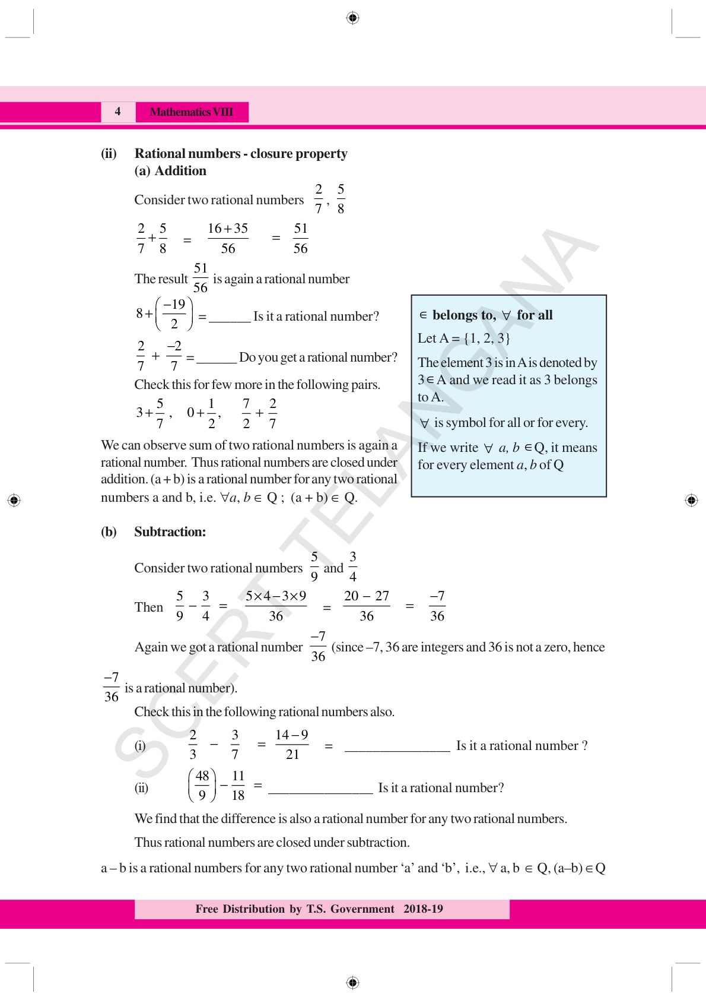

Original PDF page: 22


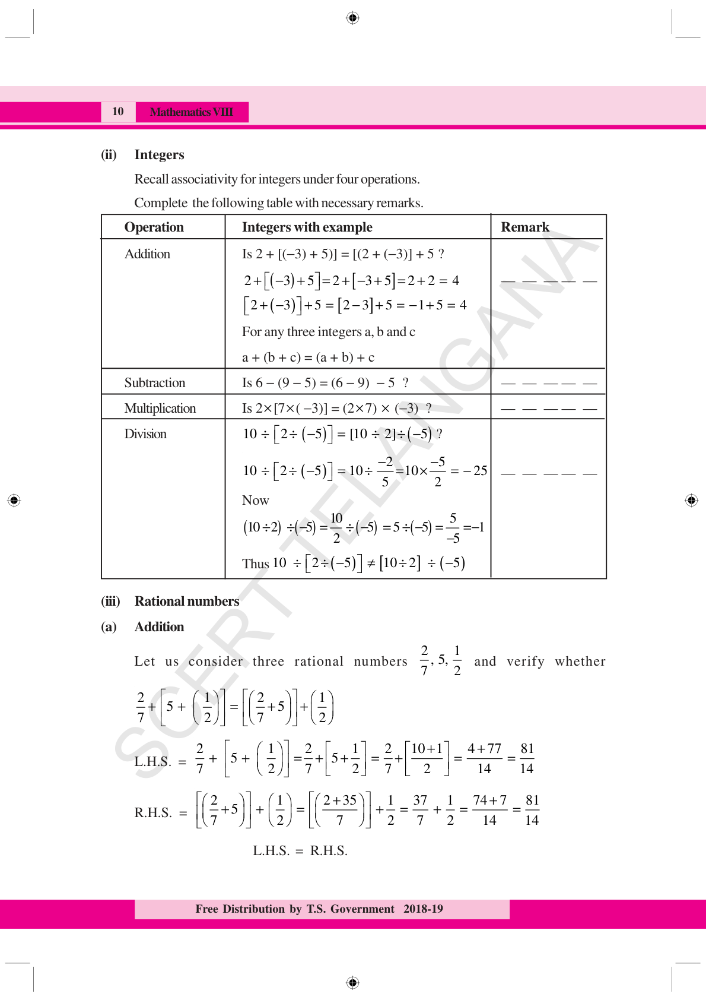

Original PDF page: 28


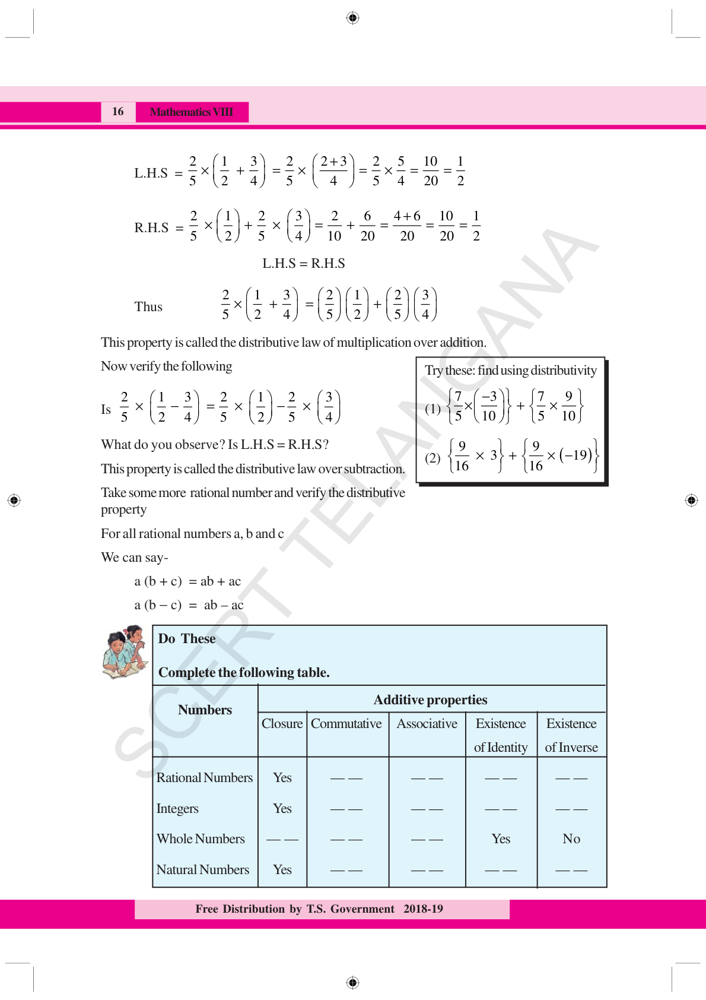

Original PDF page: 102


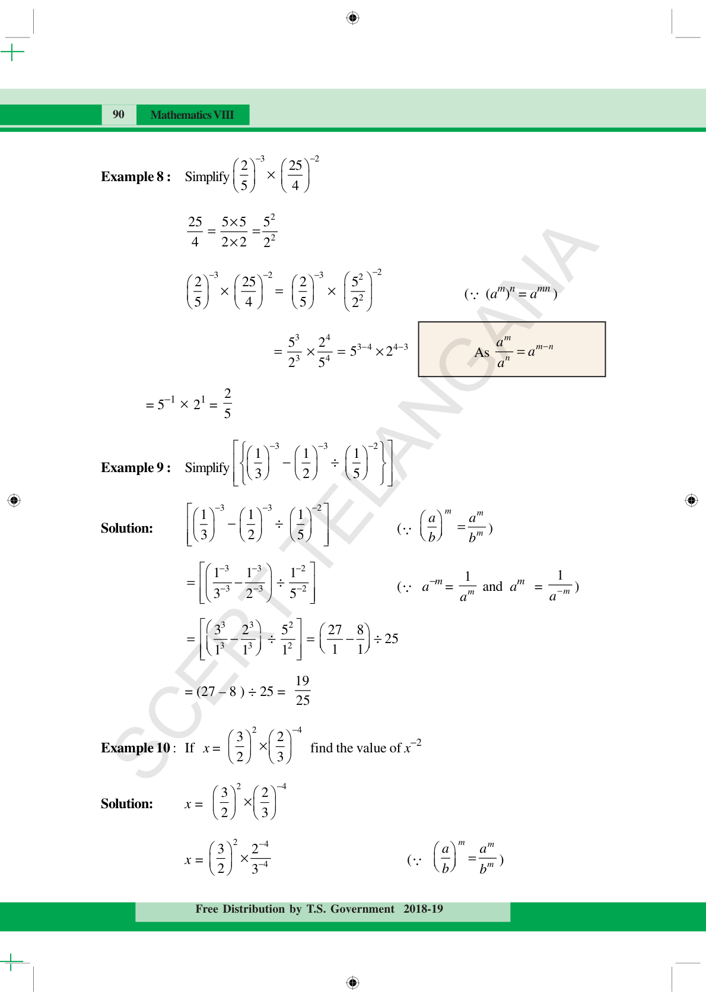

In [ ]:
import pymupdf
from PIL import Image
from IPython.display import display

pdf = pymupdf.open("/content/Math.pdf")

pages_to_check = [16, 22, 28, 102]

for page_num in pages_to_check:
    page = pdf[page_num - 1]

    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(2, 2),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    print(f"Original PDF page: {page_num}")
    display(image)

page_num refers to the PDF page index, not the printed page number shown in the textbook.

In [ ]:
import os

files_to_check = [
    "/content/Math.pdf",
    "/content/mathematics_raw.jsonl",
    "/content/mathematics_chunks.jsonl",
    "/content/mathematics_corrections.jsonl",
    "/content/mathematics_page_corrections.json"
]

print("EXISTING PROJECT FILES")
print("-" * 45)

for file_path in files_to_check:
    status = "FOUND" if os.path.exists(file_path) else "NOT FOUND"
    print(f"{os.path.basename(file_path):40} {status}")

EXISTING PROJECT FILES
---------------------------------------------
Math.pdf                                 FOUND
mathematics_raw.jsonl                    FOUND
mathematics_chunks.jsonl                 FOUND
mathematics_corrections.jsonl            FOUND
mathematics_page_corrections.json        FOUND


In [ ]:
import os
import json

base = "/content"

files = {
    "PDF": "Math.pdf",
    "Raw extraction": "mathematics_raw.jsonl",
    "Chunks": "mathematics_chunks.jsonl",
    "Corrections": "mathematics_corrections.jsonl",
    "Page corrections": "mathematics_page_corrections.json"
}

print("AI TUTOR - PROJECT AUDIT")
print("=" * 55)

for label, filename in files.items():
    path = os.path.join(base, filename)

    print(f"\n{label}: {filename}")
    print(f"Size: {os.path.getsize(path):,} bytes")

    try:
        if filename.endswith(".jsonl"):
            with open(path, "r", encoding="utf-8") as f:
                records = [json.loads(line) for line in f if line.strip()]
            print(f"Records: {len(records)}")

        elif filename.endswith(".json"):
            with open(path, "r", encoding="utf-8") as f:
                data = json.load(f)
            print(f"JSON structure: {type(data).__name__}")
            if isinstance(data, list):
                print(f"Records: {len(data)}")
            elif isinstance(data, dict):
                print(f"Keys: {list(data.keys())[:15]}")

        else:
            print("File exists")

    except Exception as e:
        print("Validation error:", str(e))

print("\n" + "=" * 55)
print("AUDIT COMPLETED - NO FILES MODIFIED")

AI TUTOR - PROJECT AUDIT

PDF: Math.pdf
Size: 8,799,329 bytes
File exists

Raw extraction: mathematics_raw.jsonl
Size: 562,684 bytes
Records: 370

Chunks: mathematics_chunks.jsonl
Size: 622,290 bytes
Records: 589

Corrections: mathematics_corrections.jsonl
Size: 12,880 bytes
Records: 9

Page corrections: mathematics_page_corrections.json
Size: 15,639 bytes
JSON structure: list
Records: 7

AUDIT COMPLETED - NO FILES MODIFIED


In [ ]:
import json
import os

PROJECT = "/content"

with open(f"{PROJECT}/mathematics_raw.jsonl", encoding="utf-8") as f:
    raw_records = [json.loads(line) for line in f if line.strip()]

with open(f"{PROJECT}/mathematics_chunks.jsonl", encoding="utf-8") as f:
    chunks = [json.loads(line) for line in f if line.strip()]

with open(f"{PROJECT}/mathematics_corrections.jsonl", encoding="utf-8") as f:
    corrections = [json.loads(line) for line in f if line.strip()]

with open(f"{PROJECT}/mathematics_page_corrections.json", encoding="utf-8") as f:
    page_corrections = json.load(f)

agent_state = {
    "project": "Telangana Grade 8 AI Tutor",
    "subject": "Mathematics",
    "stages": {
        "pdf_available": True,
        "raw_extraction": len(raw_records),
        "preliminary_chunks": len(chunks),
        "correction_records": len(corrections),
        "page_correction_records": len(page_corrections),
        "math_validation": "pending",
        "final_chunking": "pending",
        "embeddings": "pending",
        "rag": "pending",
        "fine_tuning": "pending"
    }
}

print(json.dumps(agent_state, indent=4))

{
    "project": "Telangana Grade 8 AI Tutor",
    "subject": "Mathematics",
    "stages": {
        "pdf_available": true,
        "raw_extraction": 370,
        "preliminary_chunks": 589,
        "correction_records": 9,
        "page_correction_records": 7,
        "math_validation": "pending",
        "final_chunking": "pending",
        "embeddings": "pending",
        "rag": "pending",
        "fine_tuning": "pending"
    }
}


In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

print("MATHEMATICS CORRECTION STATUS")
print("=" * 55)

for page in pages:
    print(f"\nPDF Page: {page.get('page_number', 'Unknown')}")
    print("Status:", page.get("status", "Not specified"))
    print("Original chunks:", len(page.get("original_chunks", [])))
    print("Verified text available:", bool(page.get("verified_text", "").strip()))

print("\n" + "=" * 55)
print("Correction inspection completed.")

MATHEMATICS CORRECTION STATUS

PDF Page: Unknown
Status: verified_against_original_pdf
Original chunks: 2
Verified text available: True

PDF Page: Unknown
Status: transcribed_needs_validation
Original chunks: 2
Verified text available: True

PDF Page: Unknown
Status: needs_review
Original chunks: 1
Verified text available: False

PDF Page: Unknown
Status: needs_review
Original chunks: 1
Verified text available: False

PDF Page: Unknown
Status: needs_review
Original chunks: 1
Verified text available: False

PDF Page: Unknown
Status: needs_review
Original chunks: 1
Verified text available: False

PDF Page: Unknown
Status: needs_review
Original chunks: 1
Verified text available: False

Correction inspection completed.


In [ ]:
import json
from pprint import pprint

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

print("FIRST CORRECTION RECORD")
print("=" * 50)

pprint(pages[0])

print("\nALL RECORD FIELD NAMES")
for i, page in enumerate(pages):
    print(f"Record {i + 1}: {list(page.keys())}")

FIRST CORRECTION RECORD
{'grade': 8,
 'original_chunks': [{'chunk_index': 0,
                      'text': 'Mathematics VIII\n'
                              '10\n'
                              'Free Distribution by T.S. Government  2018-19\n'
                              '(ii)\n'
                              'Integers\n'
                              'Recall associativity for integers under four '
                              'operations.\n'
                              'Complete  the following table with necessary '
                              'remarks.\n'
                              'Operation\n'
                              'Integers with example\n'
                              'Remark\n'
                              'Addition\n'
                              'Is 2 + [(−3) + 5)] = [(2 + (−3)] + 5 ?\n'
                              '(\n'
                              ')\n'
                              '[\n'
                              ']\n'
                           

In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

correction_tracker = []

for record in pages:
    correction_tracker.append({
        "page": record["page"],
        "status": record["status"],
        "verified_text_available": bool(record.get("verified_text", "").strip()),
        "original_chunks": len(record.get("original_chunks", []))
    })

print("AGENT CORRECTION TRACKER")
print("=" * 50)

for item in correction_tracker:
    print(
        f"Page {item['page']} | "
        f"{item['status']} | "
        f"Chunks: {item['original_chunks']}"
    )

print("\nTotal pages:", len(correction_tracker))
print("Verified:", sum(x["status"] == "verified_against_original_pdf" for x in correction_tracker))
print("Pending:", sum(x["status"] != "verified_against_original_pdf" for x in correction_tracker))

AGENT CORRECTION TRACKER
Page 22 | verified_against_original_pdf | Chunks: 2
Page 23 | transcribed_needs_validation | Chunks: 2
Page 102 | needs_review | Chunks: 1
Page 103 | needs_review | Chunks: 1
Page 104 | needs_review | Chunks: 1
Page 215 | needs_review | Chunks: 1
Page 237 | needs_review | Chunks: 1

Total pages: 7
Verified: 1
Pending: 6


PDF Page: 23

EXTRACTED TEXT
----------------------------------------
Free Distribution by T.S. Government  2018-19
Rational Numbers
11
Find
1
3
4
2
7
3


+
+




and 
1
3
4
2
7
3




+
+ 







Are the two sums equal?
Take some more rational numbers and verify the associativity.
We find rational numbers satisfy associative property under addition.
a + (b + c)  =  (a + b) + c for any three rational numbers a, b and c.
i.e., ∀ a, b, c ∈ Q,   a + (b + c) = (a + b) + c
(b)
Subtraction
Let us take  any three rational numbers 1
3
,
2
4 and 5
4
−
Verify whether  
1
3
5
1
3
5
2
4
4
2
4
4

−

−






−
−
=
−
−
















       L.H.S.  = 
1
3
5
2
4
4

−



−
−






= 1
3
5
1
8
2
4
4
2
4



−
+
=
−






=  1
1
4
3
2
2
2
2
−
−
−
=
=
       R.H.S. =  
1
3
5
2
4
4
−




−
−







=  
1 2
3
5
1
5
4
4
4
4
×
−
−




+
=
+








=  1 5
4 1
4
4
−+
=
=
    
1
3
5
1
3
5
2
4
4
2
4
4

−

−






∴
−

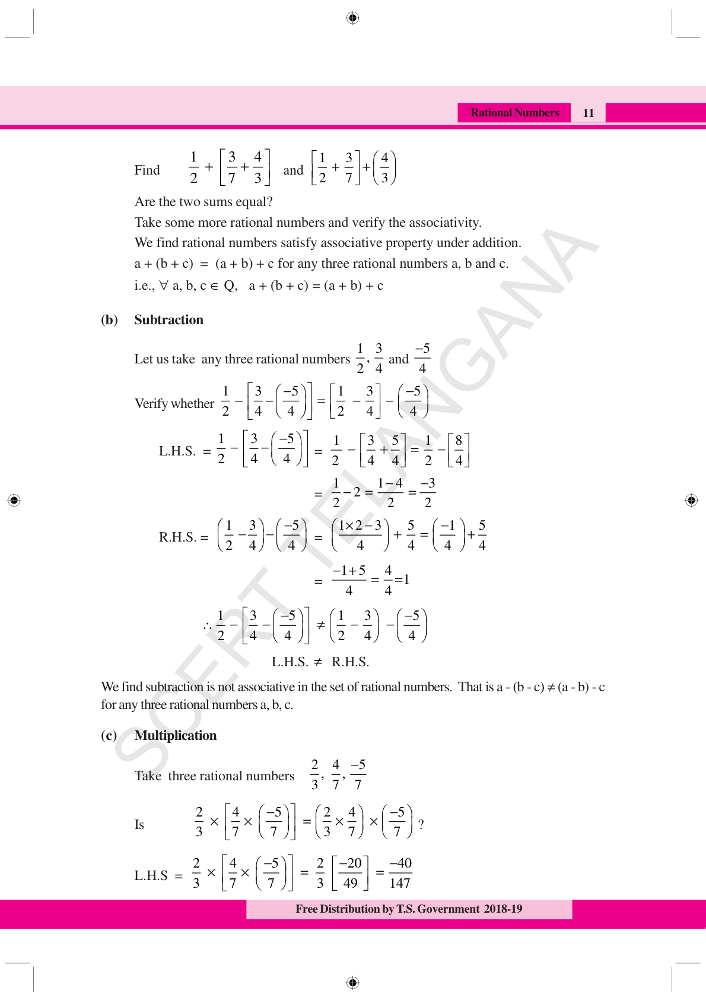

In [ ]:
import pymupdf
from PIL import Image
from IPython.display import display

pdf = pymupdf.open("/content/Math.pdf")

def inspect_textbook_page(page_number, zoom=2):
    page = pdf[page_number - 1]

    pix = page.get_pixmap(
        matrix=pymupdf.Matrix(zoom, zoom),
        alpha=False
    )

    image = Image.frombytes(
        "RGB",
        [pix.width, pix.height],
        pix.samples
    )

    print(f"PDF Page: {page_number}")
    print("\nEXTRACTED TEXT")
    print("-" * 40)
    print(page.get_text("text"))

    print("\nORIGINAL PDF IMAGE")
    display(image)

# Test on the next unverified page
inspect_textbook_page(23)

In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page23 = next(p for p in pages if p["page"] == 23)

print("CURRENT TRANSCRIPTION — PAGE 23")
print("=" * 60)
print(page23["verified_text"])

print("\nCURRENT STATUS:", page23["status"])

CURRENT TRANSCRIPTION — PAGE 23

Rational Numbers

(a) Addition

Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.


Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.

We find rational numbers satisfy associative property under addition.

a + (b + c) = (a + b) + c

for any three rational numbers a, b and c.

i.e., ∀ a, b, c ∈ Q,

a + (b + c) = (a + b) + c

(b) Subtraction

Let us take any three rational numbers 1/2, 3/4 and -5/4.

Verify whether:

1/2 - [3/4 - (-5/4)]
=
[1/2 - 3/4] - (-5/4)

L.H.S. = 1/2 - [3/4 - (-5/4)]
= 1/2 - [3/4 + 5/4]
= 1/2 - 8/4
= 1/2 - 2
= (1 - 4)/2
= -3/2

R.H.S. = (1/2 - 3/4) - (-5/4)
= ((1 × 2 - 3)/4) + 5/4
= (-1/4) + 5/4
= (-1 + 5)/4
= 4/4 = 1

Therefore,

1/2 - [3/4 - (-5/4)]
≠ (1/2 - 3/4) - (-5/4)

L.H.S. ≠ R.H.S.

We find subtraction is not associative in the set of rational numb

In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page23.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page23 = next(p for p in pages if p["page"] == 23)

duplicate = """Find:

1/2 + [3/7 + 4/3]

and

[1/2 + 3/7] + (4/3)

Are the two sums equal?

Take some more rational numbers and verify the associativity.


"""

if page23["verified_text"].count(duplicate) == 2:
    page23["verified_text"] = page23["verified_text"].replace(
        duplicate + duplicate,
        duplicate,
        1
    )
    page23["status"] = "verified_against_original_pdf"
else:
    raise ValueError("Unexpected text structure. No correction applied.")

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 23:", page23["status"])
print("Duplicate removed: Yes")
print("Backup created:", backup)

ValueError: Unexpected text structure. No correction applied.

In [ ]:
import json

path = "/content/mathematics_page_corrections.json"

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page23 = next(p for p in pages if p["page"] == 23)

text = page23["verified_text"]

target = "Find:"
positions = []
start = 0

while True:
    pos = text.find(target, start)
    if pos == -1:
        break
    positions.append(pos)
    start = pos + len(target)

print("Page 23 status:", page23["status"])
print("Number of 'Find:' occurrences:", len(positions))

for i, pos in enumerate(positions, 1):
    print(f"\nOccurrence {i}:")
    print(repr(text[pos:pos + 220]))

Page 23 status: transcribed_needs_validation
Number of 'Find:' occurrences: 2

Occurrence 1:
'Find:\n\n1/2 + [3/7 + 4/3]\n\nand\n\n[1/2 + 3/7] + (4/3)\n\nAre the two sums equal?\n\nTake some more rational numbers and verify the associativity.\n\n\nFind:\n\n1/2 + [3/7 + 4/3]\n\nand\n\n[1/2 + 3/7] + (4/3)\n\nAre the two sums equal?\n\nTa'

Occurrence 2:
'Find:\n\n1/2 + [3/7 + 4/3]\n\nand\n\n[1/2 + 3/7] + (4/3)\n\nAre the two sums equal?\n\nTake some more rational numbers and verify the associativity.\n\nWe find rational numbers satisfy associative property under addition.\n\na + (b + '


In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page23_fix.json"

# Create backup
shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page23 = next(p for p in pages if p["page"] == 23)

text = page23["verified_text"]

first = text.find("Find:")
second = text.find("Find:", first + len("Find:"))

if first == -1 or second == -1:
    raise ValueError("Expected duplicate not found.")

# Remove only the second duplicated exercise
text = text[:second] + text[second:].replace(
    text[second:text.find("We find rational numbers", second)],
    "",
    1
)

page23["verified_text"] = text
page23["status"] = "verified_against_original_pdf"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 23 updated.")
print("Find occurrences:", text.count("Find:"))
print("Status:", page23["status"])
print("Backup:", backup)

Page 23 updated.
Find occurrences: 1
Status: verified_against_original_pdf
Backup: /content/mathematics_page_corrections_before_page23_fix.json


PDF Page: 102

EXTRACTED TEXT
----------------------------------------
Mathematics VIII
90
Free Distribution by T.S. Government  2018-19
Example 8 :
Simplify 
3
2
2
25
5
4
−
−




×








2
2
25
5 5
5
4
2 2
2
×
=
=
×
2
3
2
3
2
2
2
25
2
5
5
4
5
2
−
−
−
−








×
=
× 















(∵ (am)n = amn )
                 
3
4
3 4
4 3
3
4
5
2
5
2
2
5
−
−
=
×
=
×
                  As 
m
m n
n
a
a
a
−
=
             = 5−1 × 21 = 2
5
Example 9 :
Simplify 
3
3
2
1
1
1
3
2
5
−
−
−












−
÷
























Solution:
3
3
2
1
1
1
3
2
5
−
−
−







−
÷
















(∵ 
m
m
m
a
a
b
b


=




)
3
3
2
3
3
2
1
1
1
3
2
5
−
−
−
−
−
−




=
−
÷










(∵  a−m = 1
m
a
 and  am   = 1
m
a−
)
3
3
2
3
3
2
3
2
5
27
8
25
1
1
1
1
1






=
−
÷
=
−
÷














= (27 – 8 ) ÷ 25 =  19
25
Example 10 : If   x =  
2
4
3
2
2
3
−




×








  fi

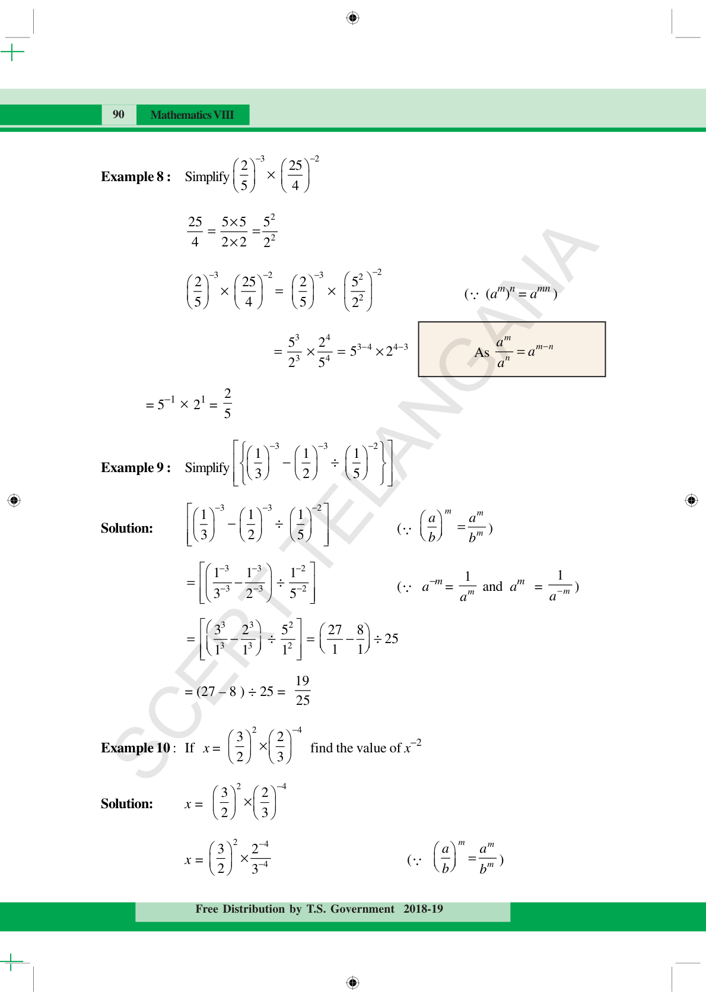

In [ ]:
inspect_textbook_page(102)

In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

print("PAGE:", page102["page"])
print("STATUS:", page102["status"])
print("\nEXISTING TRANSCRIPTION:")
print(page102["verified_text"])

print("\nORIGINAL CHUNK:")
for chunk in page102["original_chunks"]:
    print(chunk["text"])

PAGE: 102
STATUS: needs_review

EXISTING TRANSCRIPTION:


ORIGINAL CHUNK:
Mathematics VIII
90
Free Distribution by T.S. Government  2018-19
Example 8 :
Simplify
3
2
2
25
5
4
−
−




×








2
2
25
5 5
5
4
2 2
2
×
=
=
×
2
3
2
3
2
2
2
25
2
5
5
4
5
2
−
−
−
−








×
=
× 















(∵ (am)n = amn )
3
4
3 4
4 3
3
4
5
2
5
2
2
5
−
−
=
×
=
×
As
m
m n
n
a
a
a
−
=
= 5−1 × 21 = 2
5
Example 9 :
Simplify
3
3
2
1
1
1
3
2
5
−
−
−












−
÷
























Solution:
3
3
2
1
1
1
3
2
5
−
−
−







−
÷
















(∵
m
m
m
a
a
b
b


=




)
3
3
2
3
3
2
1
1
1
3
2
5
−
−
−
−
−
−




=
−
÷










(∵  a−m = 1
m
a
and  am   = 1
m
a−
)
3
3
2
3
3
2
3
2
5
27
8
25
1
1
1
1
1






=
−
÷
=
−
÷














= (27 – 8 ) ÷ 25 =  19
25
Example 10 : If   x =
2
4
3
2
2
3
−




×








find the value of x−2
Solution:
x =
2
4
3
2
2
3
−





In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page102.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

verified_text = r"""
Example 8: Simplify

(2/5)^(-3) × (25/4)^(-2)

25/4 = (5 × 5)/(2 × 2) = 5²/2²

(2/5)^(-3) × (5²/2²)^(-2)

= (5³/2³) × (2⁴/5⁴)

= 5^(3-4) × 2^(4-3)

= 5^(-1) × 2¹ = 2/5


Example 9: Simplify

[(1/3)^(-3) - (1/2)^(-3) ÷ (1/5)^(-2)]

Solution:

= [3³/1³ - 2³/1³ ÷ 5²/1²]

= [(27/1 - 8/1) ÷ 25]

= (27 - 8) ÷ 25 = 19/25


Example 10: If

x = (3/2)² × (2/3)^(-4)

Find the value of x^(-2).

Solution:

x = (3/2)² × (2/3)^(-4)

x = (3/2)² × (2^(-4)/3^(-4))

[Solution continues beyond this page.]
"""

page102["verified_text"] = verified_text.strip()
page102["status"] = "transcribed_needs_validation"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 102 transcription saved.")
print("Status:", page102["status"])
print("Backup:", backup)

Page 102 transcription saved.
Status: transcribed_needs_validation
Backup: /content/mathematics_page_corrections_before_page102.json


In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

print("PAGE 102 — SAVED TRANSCRIPTION")
print("=" * 55)
print(page102["verified_text"])
print("\nSTATUS:", page102["status"])

PAGE 102 — SAVED TRANSCRIPTION
Example 8: Simplify

(2/5)^(-3) × (25/4)^(-2)

25/4 = (5 × 5)/(2 × 2) = 5²/2²

(2/5)^(-3) × (5²/2²)^(-2)

= (5³/2³) × (2⁴/5⁴)

= 5^(3-4) × 2^(4-3)

= 5^(-1) × 2¹ = 2/5


Example 9: Simplify

[(1/3)^(-3) - (1/2)^(-3) ÷ (1/5)^(-2)]

Solution:

= [3³/1³ - 2³/1³ ÷ 5²/1²]

= [(27/1 - 8/1) ÷ 25]

= (27 - 8) ÷ 25 = 19/25


Example 10: If

x = (3/2)² × (2/3)^(-4)

Find the value of x^(-2).

Solution:

x = (3/2)² × (2/3)^(-4)

x = (3/2)² × (2^(-4)/3^(-4))

[Solution continues beyond this page.]

STATUS: transcribed_needs_validation


In [ ]:
import json

path = "/content/mathematics_page_corrections.json"

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

old = "= [3³/1³ - 2³/1³ ÷ 5²/1²]"
new = "= [(3³/1³ - 2³/1³) ÷ (5²/1²)]"

if old not in page102["verified_text"]:
    raise ValueError("Expected expression not found. No changes made.")

page102["verified_text"] = page102["verified_text"].replace(old, new, 1)

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Example 9 grouping corrected.")
print("Status:", page102["status"])

Example 9 grouping corrected.
Status: transcribed_needs_validation


In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

start = page102["verified_text"].find("Example 9")
end = page102["verified_text"].find("Example 10")

print(page102["verified_text"][start:end])
print("Status:", page102["status"])

Example 9: Simplify

[(1/3)^(-3) - (1/2)^(-3) ÷ (1/5)^(-2)]

Solution:

= [(3³/1³ - 2³/1³) ÷ (5²/1²)]

= [(27/1 - 8/1) ÷ 25]

= (27 - 8) ÷ 25 = 19/25



Status: transcribed_needs_validation


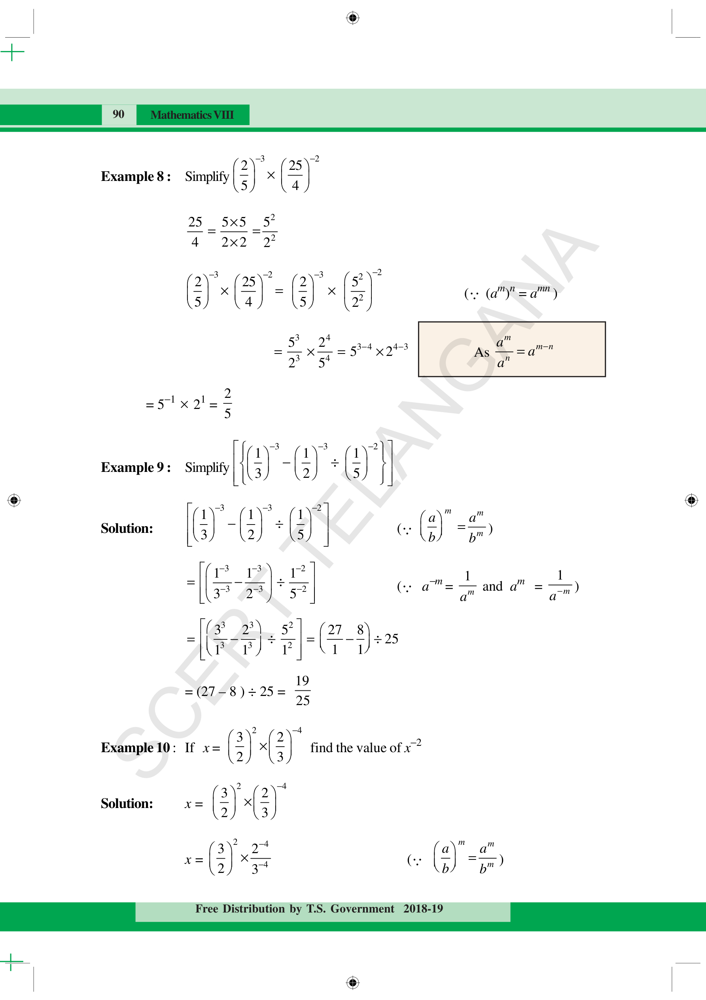


EXTRACTED TEXT:
Mathematics VIII
90
Free Distribution by T.S. Government  2018-19
Example 8 :
Simplify 
3
2
2
25
5
4
−
−




×








2
2
25
5 5
5
4
2 2
2
×
=
=
×
2
3
2
3
2
2
2
25
2
5
5
4
5
2
−
−
−
−








×
=
× 















(∵ (am)n = amn )
                 
3
4
3 4
4 3
3
4
5
2
5
2
2
5
−
−
=
×
=
×
                  As 
m
m n
n
a
a
a
−
=
             = 5−1 × 21 = 2
5
Example 9 :
Simplify 
3
3
2
1
1
1
3
2
5
−
−
−












−
÷
























Solution:
3
3
2
1
1
1
3
2
5
−
−
−







−
÷
















(∵ 
m
m
m
a
a
b
b


=




)
3
3
2
3
3
2
1
1
1
3
2
5
−
−
−
−
−
−




=
−
÷










(∵  a−m = 1
m
a
 and  am   = 1
m
a−
)
3
3
2
3
3
2
3
2
5
27
8
25
1
1
1
1
1






=
−
÷
=
−
÷














= (27 – 8 ) ÷ 25 =  19
25
Example 10 : If   x =  
2
4
3
2
2
3
−




×








  find the value of x−2
Solution:
x =  
2
4
3
2
2
3
−




In [ ]:
import pymupdf
from PIL import Image
from IPython.display import display

pdf = pymupdf.open("/content/Math.pdf")
page = pdf[101]

pix = page.get_pixmap(
    matrix=pymupdf.Matrix(3, 3),
    alpha=False
)

display(Image.frombytes("RGB", [pix.width, pix.height], pix.samples))

print("\nEXTRACTED TEXT:")
print(page.get_text("text"))

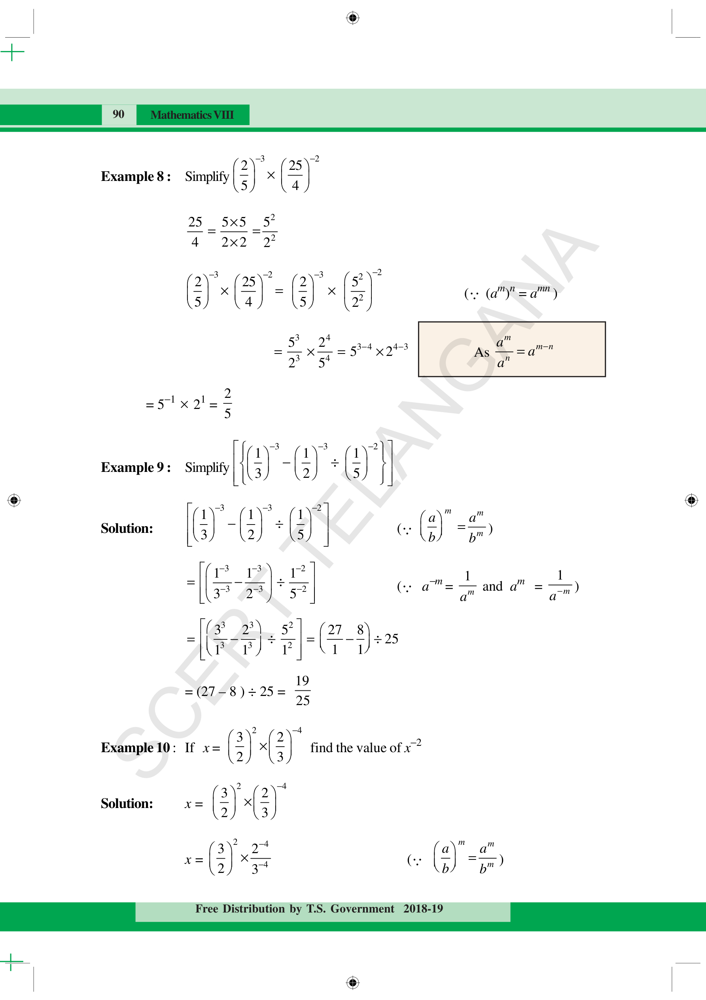

In [ ]:
from IPython.display import display
display(Image.frombytes(
    "RGB",
    [pix.width, pix.height],
    pix.samples
))

In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page102_verification.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page102 = next(p for p in pages if p["page"] == 102)

page102["status"] = "verified_against_original_pdf"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 102:", page102["status"])
print("Backup created:", backup)

Page 102: verified_against_original_pdf
Backup created: /content/mathematics_page_corrections_before_page102_verification.json


PDF Page: 103

EXTRACTED TEXT
----------------------------------------
Exponents and Powers
91
Free Distribution by T.S. Government  2018-19
x  
6
2
4
2 4
6
2
4
2 4
6
3
3
3
3
3
2
2
2
2
2
+
+


=
×
=
=
= 



x 
6
3
2


= 



2
6
12
12
12
12
2
12
12
3
3
3
2
2
2
2
3
2
3
−
−
−
−
−








=
=
=
=
=


















x
Exercise - 4.1
1.
Simplify and give reasons
 (i) 4−3
(ii)  (−2)7
(iii)  
3
3
4
−






(iv) (−3)−4
2.
Simplify  the following :
(i)  
4
5
6
1
1
1
2
2
2






×
×












(ii)  (−2)7 × (−2)3 × (−2)4
(iii)  44 × 
4
5
4






(iv)  
4
3
6
5
5
5
−
−

×




(v)  (−3)4 × 74
3.
Simplify (i)  
2
2
1
2
3
2
3
2
−
−
×
×
  (ii)  (4−1 × 3−1 ) ÷ 6−1
4.
Simplify and give reasons
(i)  (40 + 5−1 ) × 52  × 1
3
(ii)  
3
3
3
1
1
1
2
4
5
−
−
−






×
×












(iii)  (2−1 + 3−1 + 4−1)  × 3
4
(iv)  
2
0
1
3
(3
3 )
3
−
−
×
−
(v)  1 + 2−1 + 3−1 + 40
(vi)  
2
2
3
2
−














SCERT 

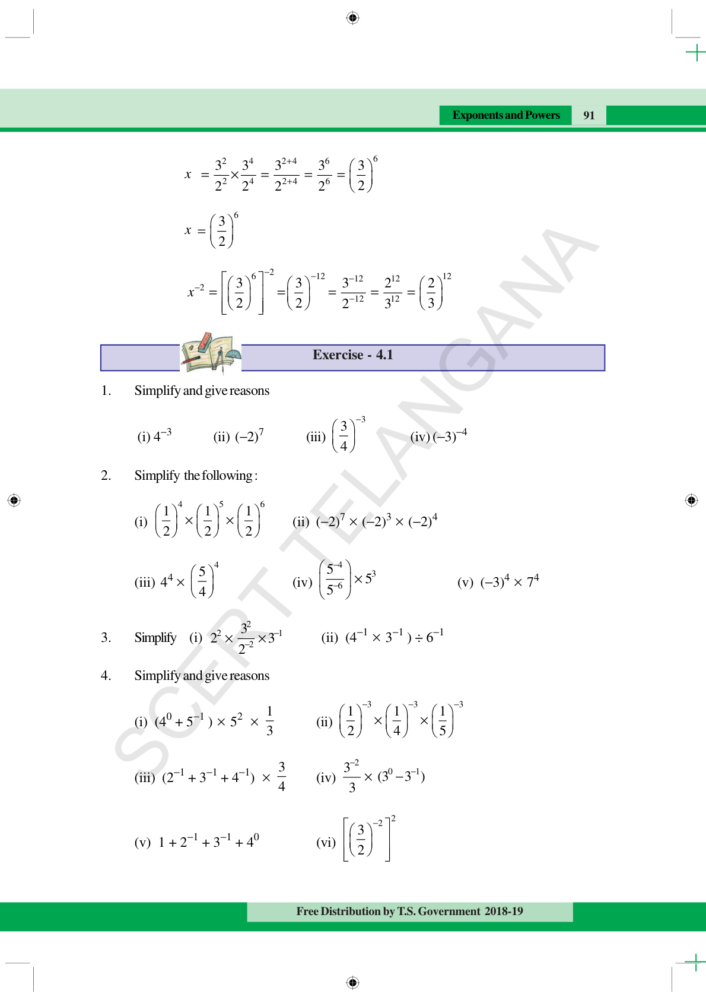

In [ ]:
inspect_textbook_page(103)

In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page103.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page103 = next(p for p in pages if p["page"] == 103)

verified_text = r"""
Continuation of Example 10:

x = (3²/2²) × (3⁴/2⁴)
  = 3^(2+4)/2^(2+4)
  = 3⁶/2⁶
  = (3/2)⁶

x = (3/2)⁶

x^(-2) = [(3/2)⁶]^(-2)
       = (3/2)^(-12)
       = 3^(-12)/2^(-12)
       = 2¹²/3¹²
       = (2/3)¹²


Exercise - 4.1

1. Simplify and give reasons:

(i) 4^(-3)
(ii) (-2)^7
(iii) (3/4)^(-3)
(iv) (-3)^(-4)


2. Simplify the following:

(i) (1/2)^4 × (1/2)^5 × (1/2)^6

(ii) (-2)^7 × (-2)^3 × (-2)^4

(iii) 4^4 × (5/4)^4

(iv) (5^(-4)/5^(-6)) × 5^(-3)

(v) (-3)^4 × 7^4


3. Simplify:

(i) 2² × (3²/2^(-2)) × 3^(-1)

(ii) (4^(-1) × 3^(-1)) ÷ 6^(-1)


4. Simplify and give reasons:

(i) (4⁰ + 5^(-1)) × 5² × 1/3

(ii) (1/2)^(-3) × (1/4)^(-3) × (1/5)^(-3)

(iii) (2^(-1) + 3^(-1) + 4^(-1)) × 3/4

(iv) (3^(-2)/3) × (3⁰ - 3^(-1))

(v) 1 + 2^(-1) + 3^(-1) + 4⁰

(vi) [(3/2)^(-2)]²
"""

page103["verified_text"] = verified_text.strip()
page103["status"] = "transcribed_needs_validation"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 103 transcription saved.")
print("Status:", page103["status"])
print("Original chunks preserved:", len(page103["original_chunks"]))
print("Backup:", backup)

Page 103 transcription saved.
Status: transcribed_needs_validation
Original chunks preserved: 1
Backup: /content/mathematics_page_corrections_before_page103.json


In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page103 = next(p for p in pages if p["page"] == 103)

print("PAGE 103 TRANSCRIPTION")
print("=" * 55)
print(page103["verified_text"])
print("\nSTATUS:", page103["status"])

PAGE 103 TRANSCRIPTION
Continuation of Example 10:

x = (3²/2²) × (3⁴/2⁴)
  = 3^(2+4)/2^(2+4)
  = 3⁶/2⁶
  = (3/2)⁶

x = (3/2)⁶

x^(-2) = [(3/2)⁶]^(-2)
       = (3/2)^(-12)
       = 3^(-12)/2^(-12)
       = 2¹²/3¹²
       = (2/3)¹²


Exercise - 4.1

1. Simplify and give reasons:

(i) 4^(-3)
(ii) (-2)^7
(iii) (3/4)^(-3)
(iv) (-3)^(-4)


2. Simplify the following:

(i) (1/2)^4 × (1/2)^5 × (1/2)^6

(ii) (-2)^7 × (-2)^3 × (-2)^4

(iii) 4^4 × (5/4)^4

(iv) (5^(-4)/5^(-6)) × 5^(-3)

(v) (-3)^4 × 7^4


3. Simplify:

(i) 2² × (3²/2^(-2)) × 3^(-1)

(ii) (4^(-1) × 3^(-1)) ÷ 6^(-1)


4. Simplify and give reasons:

(i) (4⁰ + 5^(-1)) × 5² × 1/3

(ii) (1/2)^(-3) × (1/4)^(-3) × (1/5)^(-3)

(iii) (2^(-1) + 3^(-1) + 4^(-1)) × 3/4

(iv) (3^(-2)/3) × (3⁰ - 3^(-1))

(v) 1 + 2^(-1) + 3^(-1) + 4⁰

(vi) [(3/2)^(-2)]²

STATUS: transcribed_needs_validation


In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page103_verification.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page103 = next(p for p in pages if p["page"] == 103)

page103["status"] = "verified_against_original_pdf"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 103:", page103["status"])
print("Backup created:", backup)

Page 103: verified_against_original_pdf
Backup created: /content/mathematics_page_corrections_before_page103_verification.json


PDF Page: 104

EXTRACTED TEXT
----------------------------------------
Mathematics VIII
92
Free Distribution by T.S. Government  2018-19
5.
Simplify and give reasons  (i)  
2
2
2
1
(3
2 )
5


−
÷




  (ii)  ((52)3 × 54 )  ÷ 56
6.
Find the value of ‘n’ in each of the following :
(i)  
3
5
n 2
2
2
2
3
3
3
−






×
=












(ii)  (−3)n+1 × (−3)5 = (−3)−4
(iii)  72n+1 ÷ 49 = 73
7.
Find ‘x’ if   
3
1
2
2
−=
x
8.
Simplify  
2
3
2
3
4
3
4
5
5
−
−
−








÷
×


















9.
If  m = 3 and n = 2  find the value of
(i)  9m2 – 10n3
(ii)  2m2 n2
(iii)  2m3 + 3n2 – 5m2n     (iv)  mn – nm
10.
Simplify and give reasons 
5
7
4
7
7
4
−
−




×








4.3
Application of Exponents to Express numbers in Standard Form
In previous class we have learnt how to express very large numbers in standard form.
For example 300,000,000 m = 3×108 m
Now let us try to express very small number in standard form.
Consider, diameter of a wire in a

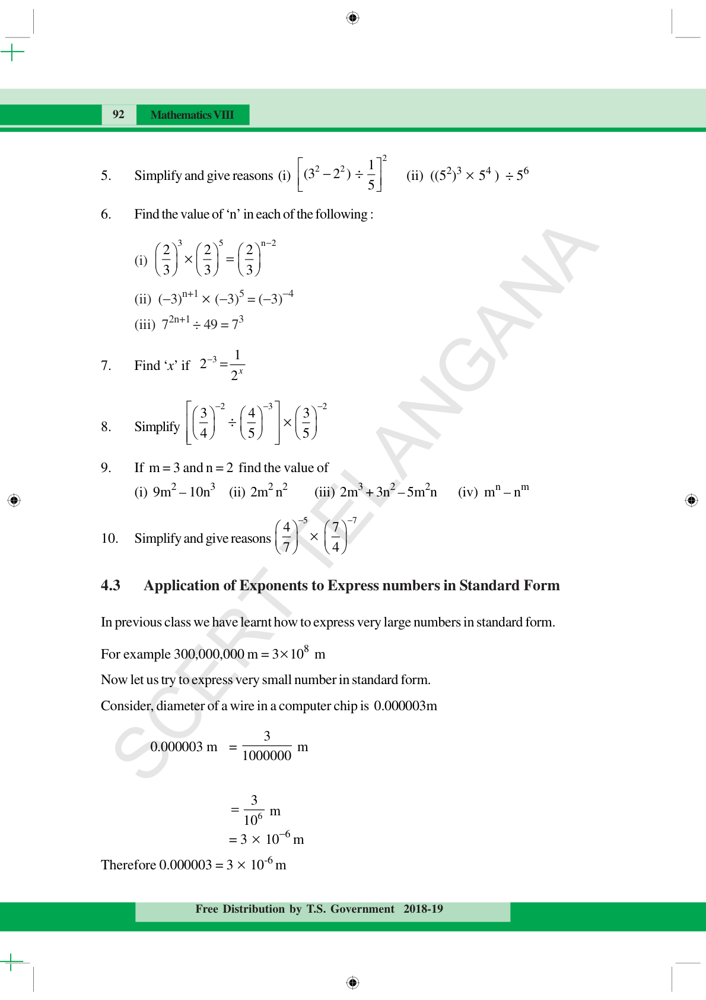

In [ ]:
inspect_textbook_page(104)

In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page104.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page104 = next(p for p in pages if p["page"] == 104)

verified_text = r"""
5. Simplify and give reasons:

(i) [(3² - 2²) ÷ (1/5)]²

(ii) ((5²)³ × 5⁴) ÷ 5⁶


6. Find the value of n in each of the following:

(i) (2/3)³ × (2/3)⁵ = (2/3)^(n-2)

(ii) (-3)^(n+1) × (-3)⁵ = (-3)^(-4)

(iii) 7^(2n+1) ÷ 49 = 7³


7. Find x if:

2^(-3) = 1/(2^x)


8. Simplify:

[(3/4)^(-2) ÷ (4/5)^(-3)] × (3/5)^(-2)


9. If m = 3 and n = 2, find the value of:

(i) 9m² - 10n³

(ii) 2m²n²

(iii) 2m³ + 3n² - 5m²n

(iv) m^n - n^m


10. Simplify and give reasons:

(4/7)^(-5) × (7/4)^(-7)


4.3 Application of Exponents to Express Numbers in Standard Form

In previous class we have learnt how to express very large numbers in standard form.

For example:
300,000,000 m = 3 × 10⁸ m

Now let us try to express very small number in standard form.

Consider, diameter of a wire in a computer chip is 0.000003 m.

0.000003 m = 3/1000000 m
             = 3/10⁶ m
             = 3 × 10⁻⁶ m

Therefore 0.000003 = 3 × 10⁻⁶ m.
"""

page104["verified_text"] = verified_text.strip()
page104["status"] = "transcribed_needs_validation"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 104 transcription saved.")
print("Status:", page104["status"])
print("Original chunks preserved:", len(page104["original_chunks"]))
print("Backup:", backup)

Page 104 transcription saved.
Status: transcribed_needs_validation
Original chunks preserved: 1
Backup: /content/mathematics_page_corrections_before_page104.json


In [ ]:
import json

with open("/content/mathematics_page_corrections.json", encoding="utf-8") as f:
    pages = json.load(f)

page104 = next(p for p in pages if p["page"] == 104)

print("PAGE 104 TRANSCRIPTION")
print("=" * 55)
print(page104["verified_text"])
print("\nSTATUS:", page104["status"])

PAGE 104 TRANSCRIPTION
5. Simplify and give reasons:

(i) [(3² - 2²) ÷ (1/5)]²

(ii) ((5²)³ × 5⁴) ÷ 5⁶


6. Find the value of n in each of the following:

(i) (2/3)³ × (2/3)⁵ = (2/3)^(n-2)

(ii) (-3)^(n+1) × (-3)⁵ = (-3)^(-4)

(iii) 7^(2n+1) ÷ 49 = 7³


7. Find x if:

2^(-3) = 1/(2^x)


8. Simplify:

[(3/4)^(-2) ÷ (4/5)^(-3)] × (3/5)^(-2)


9. If m = 3 and n = 2, find the value of:

(i) 9m² - 10n³

(ii) 2m²n²

(iii) 2m³ + 3n² - 5m²n

(iv) m^n - n^m


10. Simplify and give reasons:

(4/7)^(-5) × (7/4)^(-7)


4.3 Application of Exponents to Express Numbers in Standard Form

In previous class we have learnt how to express very large numbers in standard form.

For example:
300,000,000 m = 3 × 10⁸ m

Now let us try to express very small number in standard form.

Consider, diameter of a wire in a computer chip is 0.000003 m.

0.000003 m = 3/1000000 m
             = 3/10⁶ m
             = 3 × 10⁻⁶ m

Therefore 0.000003 = 3 × 10⁻⁶ m.

STATUS: transcribed_needs_validation


In [ ]:
import json
import shutil

path = "/content/mathematics_page_corrections.json"
backup = "/content/mathematics_page_corrections_before_page104_verification.json"

shutil.copy2(path, backup)

with open(path, "r", encoding="utf-8") as f:
    pages = json.load(f)

page104 = next(p for p in pages if p["page"] == 104)

page104["status"] = "verified_against_original_pdf"

with open(path, "w", encoding="utf-8") as f:
    json.dump(pages, f, indent=2, ensure_ascii=False)

print("Page 104:", page104["status"])
print("Backup created:", backup)

Page 104: verified_against_original_pdf
Backup created: /content/mathematics_page_corrections_before_page104_verification.json


PDF Page: 215

EXTRACTED TEXT
----------------------------------------
Area of Plane Figures
203
Free Distribution by T.S. Government  2018-19
Area of trapezium ABCD
=
Area of ADE + Area of Rectangle DEFC + Area of CFB
=
( 1
2 × h × c) + (b × h) + ( 1
2 × h × d)
=
h 1
1
c
b
d
2
2


+
+




=
h c
2b
d
2
+
+






=
h c
b
d
b
2
+
+
+






=
h
a
b
2
+





  (∵c + b + d = a)
So, we can write the formula for the area of a  trapezium
=
height × 





sum of parallelsides
2
=
1
2 ×distance between two parallel sides×(sum of parallel sides)
   Activity
1.
Draw a trapezium WXYZ on a piece of graph paper as
shown in the figure and cut it out as shown in Fig. (i)
2.
Find the Mid point of XY by folding its side XY and name
it  ‘A’ as shown in Fig.(ii)
3.
Draw line AZ.
a
b
W
X
Y
Z
h
Fig. (i)
W
X
Y
Z
A
Fig. (ii)
SCERT TELANGANA


ORIGINAL PDF IMAGE


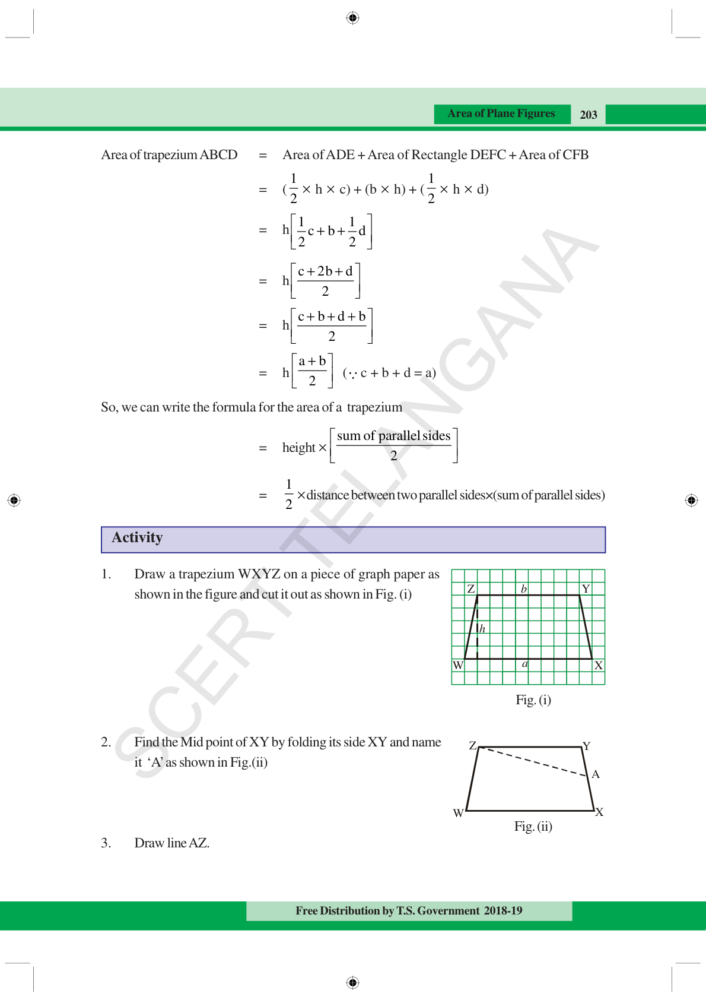

In [ ]:
inspect_textbook_page(215)

In [ ]:

# CELL 1: Initialize the AI Agent's project workspace
# Safe setup: reads existing files; does not modify or overwrite them.

import os
import json
import hashlib
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path("/content")
AGENT_DIR = PROJECT_DIR / "math_tutor_agent"
AGENT_DIR.mkdir(exist_ok=True)

STATE_FILE = AGENT_DIR / "agent_state.json"

PROJECT_FILES = {
    "original_pdf": "Math.pdf",
    "raw_extraction": "mathematics_raw.jsonl",
    "preliminary_chunks": "mathematics_chunks.jsonl",
    "corrections": "mathematics_corrections.jsonl",
    "page_corrections": "mathematics_page_corrections.json"
}

def audit_project():
    """Inspect existing project files without changing them."""
    report = {}

    for name, filename in PROJECT_FILES.items():
        path = PROJECT_DIR / filename
        report[name] = {
            "path": str(path),
            "exists": path.exists(),
            "size_bytes": path.stat().st_size if path.exists() else None,
            "sha256": (
                hashlib.sha256(path.read_bytes()).hexdigest()
                if path.exists() else None
            )
        }

    return report


def read_correction_status():
    """Read verified and pending page corrections."""
    path = PROJECT_DIR / PROJECT_FILES["page_corrections"]

    if not path.exists():
        return {"error": "Page corrections file not found."}

    records = json.loads(path.read_text(encoding="utf-8"))

    return {
        "total": len(records),
        "verified": [
            r["page"] for r in records
            if r.get("status") == "verified_against_original_pdf"
        ],
        "pending": [
            r["page"] for r in records
            if r.get("status") != "verified_against_original_pdf"
        ]
    }


def inspect_jsonl(filename):
    """Inspect JSONL record count and basic structure."""
    path = PROJECT_DIR / filename

    if not path.exists():
        return {"error": f"{filename} not found"}

    records = []
    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    return {
        "filename": filename,
        "records": len(records),
        "first_record_keys": list(records[0].keys()) if records else [],
        "last_record_keys": list(records[-1].keys()) if records else []
    }


# Agent tool registry: functions the reasoning agent can call.
AGENT_TOOLS = {
    "audit_project": audit_project,
    "read_correction_status": read_correction_status,
    "inspect_raw_extraction": lambda: inspect_jsonl(
        "mathematics_raw.jsonl"
    ),
    "inspect_chunks": lambda: inspect_jsonl(
        "mathematics_chunks.jsonl"
    )
}

# Preserve previous agent state if it already exists.
if STATE_FILE.exists():
    agent_state = json.loads(STATE_FILE.read_text(encoding="utf-8"))
else:
    agent_state = {
        "project": "Telangana Grade 8 AI Tutor",
        "subject": "Mathematics",
        "stage": "existing_data_audit",
        "completed_tasks": [
            "PDF extraction",
            "Preliminary chunking",
            "Correction workspace creation",
            "Verification of five pages"
        ],
        "pending_tasks": [
            "Review pending corrections",
            "Finalize chunks",
            "Generate embeddings",
            "Connect Supabase",
            "Build RAG",
            "Prepare fine-tuning dataset",
            "Train and evaluate",
            "Deploy with Ollama"
        ],
        "created_at": datetime.now().isoformat()
    }

agent_state["last_audit"] = datetime.now().isoformat()
agent_state["project_files"] = audit_project()
STATE_FILE.write_text(json.dumps(agent_state, indent=2), encoding="utf-8")

print("AGENT WORKSPACE INITIALIZED")
print("=" * 45)

for name, details in agent_state["project_files"].items():
    status = "FOUND" if details["exists"] else "MISSING"
    print(f"{name}: {status}")

print("\nCorrection status:")
print(read_correction_status())

print("\nAvailable agent tools:")
for tool_name in AGENT_TOOLS:
    print("-", tool_name)

print("\nAgent state saved at:", STATE_FILE)


AGENT WORKSPACE INITIALIZED
original_pdf: FOUND
raw_extraction: FOUND
preliminary_chunks: FOUND
corrections: FOUND
page_corrections: FOUND

Correction status:
{'total': 7, 'verified': [22, 23, 102, 103, 104], 'pending': [215, 237]}

Available agent tools:
- audit_project
- read_correction_status
- inspect_raw_extraction
- inspect_chunks

Agent state saved at: /content/math_tutor_agent/agent_state.json


In [ ]:

# CELL 2: Install dependencies and load the agent's reasoning model

!pip -q install -U transformers accelerate

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-0.6B"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

print("Loading model...")
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("\nAGENT MODEL LOADED SUCCESSFULLY")
print("Model:", MODEL_ID)
print("Device:", model.device)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Loading tokenizer...


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]


AGENT MODEL LOADED SUCCESSFULLY
Model: Qwen/Qwen3-0.6B
Device: cuda:0
GPU available: True
GPU: Tesla T4


In [ ]:

# ============================================================
# TELANGANA GRADE 8 AI TUTOR
# LANGGRAPH + HUGGING FACE AUTONOMOUS AGENT
# ============================================================

!pip -q install -U langgraph langchain-core

import os
import json
import re
import hashlib
import statistics
from pathlib import Path
from datetime import datetime
from typing import TypedDict, Any

from langgraph.graph import StateGraph, END

# ------------------------------------------------------------
# 1. REUSE OR LOAD THE REASONING MODEL
# ------------------------------------------------------------

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen3-0.6B"

if "model" not in globals() or "tokenizer" not in globals():
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype="auto",
        device_map="auto"
    )

model.eval()

# ------------------------------------------------------------
# 2. PROJECT CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/content")
AGENT_DIR = ROOT / "math_tutor_agent"
AGENT_DIR.mkdir(exist_ok=True)

STATE_FILE = AGENT_DIR / "agent_state.json"
REPORT_FILE = AGENT_DIR / "latest_agent_report.json"

FILES = {
    "pdf": "Math.pdf",
    "raw": "mathematics_raw.jsonl",
    "chunks": "mathematics_chunks.jsonl",
    "corrections": "mathematics_corrections.jsonl",
    "page_corrections": "mathematics_page_corrections.json"
}

# ------------------------------------------------------------
# 3. AGENT TOOLS
# ------------------------------------------------------------

def audit_project():
    report = {}

    for name, filename in FILES.items():
        path = ROOT / filename

        report[name] = {
            "exists": path.exists(),
            "size_bytes": path.stat().st_size if path.exists() else 0
        }

    return report


def correction_status():
    path = ROOT / FILES["page_corrections"]

    if not path.exists():
        return {"error": "Correction file missing"}

    records = json.loads(path.read_text(encoding="utf-8"))

    verified = [
        r["page"] for r in records
        if r.get("status") == "verified_against_original_pdf"
    ]

    pending = [
        r["page"] for r in records
        if r.get("status") != "verified_against_original_pdf"
    ]

    return {
        "total": len(records),
        "verified": verified,
        "pending": pending
    }


def inspect_jsonl(filename):
    path = ROOT / filename

    if not path.exists():
        return {"error": f"{filename} not found"}

    records = []

    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    return {
        "filename": filename,
        "record_count": len(records),
        "sample_keys": list(records[0].keys()) if records else []
    }


def check_chunk_quality():
    path = ROOT / FILES["chunks"]

    if not path.exists():
        return {"error": "Chunk file missing"}

    lengths = []
    empty = 0
    suspicious = []

    with path.open(encoding="utf-8") as f:
        for index, line in enumerate(f):
            if not line.strip():
                continue

            record = json.loads(line)

            # Handle common chunk text field names.
            content = next(
                (
                    record[k] for k in
                    ["text", "content", "chunk", "page_content"]
                    if isinstance(record.get(k), str)
                ),
                ""
            )

            if not content.strip():
                empty += 1

            lengths.append(len(content))

            if any("\uf8e7" <= ch <= "\uf8ff" for ch in content):
                suspicious.append(index)

    return {
        "total_chunks": len(lengths),
        "empty_chunks": empty,
        "private_use_glyph_chunks": len(suspicious),
        "private_use_glyph_indices": suspicious[:30],
        "min_length": min(lengths) if lengths else 0,
        "max_length": max(lengths) if lengths else 0,
        "average_length": round(statistics.mean(lengths), 2)
            if lengths else 0
    }


TOOLS = {
    "audit_project": audit_project,
    "correction_status": correction_status,
    "inspect_raw": lambda: inspect_jsonl(FILES["raw"]),
    "inspect_chunks": lambda: inspect_jsonl(FILES["chunks"]),
    "check_chunk_quality": check_chunk_quality
}

TOOL_GUIDE = """
Available tools:
1. audit_project: inspect all existing project files.
2. correction_status: inspect verified and pending pages.
3. inspect_raw: inspect extracted textbook records.
4. inspect_chunks: inspect existing chunks.
5. check_chunk_quality: detect empty chunks, unusual glyphs and lengths.

Choose one tool at a time.
Never invent tool results.
Do not modify or delete original files.
Do not claim that unimplemented stages are completed.

Respond ONLY with JSON:
{"tool":"tool_name","reason":"short reason"}

When enough information is collected:
{"tool":"finish","reason":"summary of findings"}
"""

# ------------------------------------------------------------
# 4. PERSISTENT AGENT CHECKPOINT
# ------------------------------------------------------------

if STATE_FILE.exists():
    agent_state = json.loads(
        STATE_FILE.read_text(encoding="utf-8")
    )
else:
    agent_state = {
        "project": "Telangana Grade 8 AI Tutor",
        "completed_tasks": [
            "PDF extraction",
            "Preliminary chunking",
            "Correction workspace creation",
            "Five page verifications"
        ],
        "pending_tasks": [
            "Finalize chunks",
            "Embeddings",
            "Supabase",
            "RAG",
            "Fine-tuning dataset",
            "QLoRA training",
            "Evaluation",
            "Ollama deployment"
        ]
    }

# ------------------------------------------------------------
# 5. LANGGRAPH STATE
# ------------------------------------------------------------

class AgentState(TypedDict):
    task: str
    history: list
    selected_tool: str
    done: bool
    steps: int
    final_answer: str


# ------------------------------------------------------------
# 6. MODEL REASONING NODE
# ------------------------------------------------------------

def agent_node(state: AgentState):

    prompt = f"""
You are the project orchestration agent for:
Telangana Grade 8 AI Tutor.

Your task:
{state['task']}

Previous observations:
{json.dumps(state['history'], ensure_ascii=False)}

{TOOL_GUIDE}

Select the most useful next tool.
"""

    messages = [
        {"role": "system", "content": "You are a careful AI project agent."},
        {"role": "user", "content": prompt}
    ]

    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    match = re.search(r"\{.*?\}", generated, re.DOTALL)

    if match:
        try:
            decision = json.loads(match.group())
            selected = decision.get("tool", "finish")
        except Exception:
            selected = "finish"
    else:
        selected = "finish"

    if selected not in TOOLS and selected != "finish":
        selected = "audit_project"

    reason = (
        decision.get("reason", "")
        if match and "decision" in locals()
        else generated
    )

    return {
        "selected_tool": selected,
        "history": state["history"] + [{
            "agent_decision": selected,
            "reason": str(reason)[:500]
        }],
        "done": selected == "finish",
        "steps": state["steps"] + 1
    }


# ------------------------------------------------------------
# 7. TOOL EXECUTION NODE
# ------------------------------------------------------------

def tool_node(state: AgentState):

    selected = state["selected_tool"]

    if selected not in TOOLS:
        return {
            "history": state["history"] + [{
                "error": "Unknown tool selected"
            }]
        }

    try:
        result = TOOLS[selected]()

        observation = {
            "tool": selected,
            "result": result
        }

    except Exception as e:
        observation = {
            "tool": selected,
            "error": str(e)
        }

    return {
        "history": state["history"] + [observation]
    }


# ------------------------------------------------------------
# 8. BUILD LANGGRAPH WORKFLOW
# ------------------------------------------------------------

workflow = StateGraph(AgentState)

workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node)

workflow.set_entry_point("agent")

def route_agent(state):
    if state["done"] or state["steps"] >= 6:
        return END
    return "tools"

workflow.add_conditional_edges(
    "agent",
    route_agent,
    {
        "tools": "tools",
        END: END
    }
)

workflow.add_edge("tools", "agent")

agent_app = workflow.compile()

# ------------------------------------------------------------
# 9. RUN THE AGENT
# ------------------------------------------------------------

task = """
Audit the existing mathematics textbook project.
Inspect its files, correction status and chunk quality.
Identify the next safest useful task.
Do not modify original data.
"""

initial_state = {
    "task": task,
    "history": [],
    "selected_tool": "",
    "done": False,
    "steps": 0,
    "final_answer": ""
}

print("\n" + "=" * 60)
print("TELANGANA GRADE 8 AI TUTOR - AGENT STARTED")
print("=" * 60)

result = agent_app.invoke(initial_state)

# ------------------------------------------------------------
# 10. SAVE RESULTS AND CHECKPOINT
# ------------------------------------------------------------

report = {
    "timestamp": datetime.now().isoformat(),
    "model": MODEL_ID,
    "framework": "LangGraph",
    "steps": result["steps"],
    "observations": result["history"],
    "status": "audit_completed"
}

REPORT_FILE.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

agent_state["last_agent_run"] = datetime.now().isoformat()
agent_state["last_report"] = str(REPORT_FILE)
agent_state["last_audit_results"] = result["history"]

STATE_FILE.write_text(
    json.dumps(agent_state, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nAGENT EXECUTION RESULTS")
print("-" * 60)

for item in result["history"]:
    print(json.dumps(item, indent=2, ensure_ascii=False))

print("\nSteps executed:", result["steps"])
print("Report saved:", REPORT_FILE)
print("Checkpoint saved:", STATE_FILE)
print("\nAGENT RUN FINISHED")



TELANGANA GRADE 8 AI TUTOR - AGENT STARTED

AGENT EXECUTION RESULTS
------------------------------------------------------------
{
  "agent_decision": "inspect_raw",
  "reason": "Inspection of extracted textbook records to identify potential issues in the content."
}
{
  "tool": "inspect_raw",
  "result": {
    "filename": "mathematics_raw.jsonl",
    "record_count": 370,
    "sample_keys": [
      "subject",
      "grade",
      "source_file",
      "page",
      "text"
    ]
  }
}
{
  "agent_decision": "inspect_raw",
  "reason": "Inspection of extracted textbook records to identify potential issues in the content."
}
{
  "tool": "inspect_raw",
  "result": {
    "filename": "mathematics_raw.jsonl",
    "record_count": 370,
    "sample_keys": [
      "subject",
      "grade",
      "source_file",
      "page",
      "text"
    ]
  }
}
{
  "agent_decision": "inspect_raw",
  "reason": "Inspection of extracted textbook records to identify potential issues in the content."
}
{
  "tool": "

In [ ]:

# FIXED LANGGRAPH AGENT: PREVENT REPEATED TOOL CALLS

from typing import TypedDict
from langgraph.graph import StateGraph, END
import json, re
from datetime import datetime

class AgentState(TypedDict):
    task: str
    history: list
    executed_tools: list
    selected_tool: str
    done: bool
    steps: int

TOOL_NAMES = list(TOOLS.keys())

def agent_node(state):
    remaining = [
        name for name in TOOL_NAMES
        if name not in state["executed_tools"]
    ]

    if not remaining:
        return {"selected_tool": "finish", "done": True}

    prompt = f"""
You are an orchestration agent for a Grade 8 textbook project.

Task: {state['task']}

Tools already executed: {state['executed_tools']}
Tools still available: {remaining}

Previous results:
{json.dumps(state['history'], ensure_ascii=False)[:5000]}

Choose exactly one tool from the available tools.
Do not repeat an executed tool.
Return only JSON:
{{"tool": "tool_name", "reason": "short reason"}}
"""

    messages = [
        {"role": "system", "content": "You are a careful project agent."},
        {"role": "user", "content": prompt}
    ]

    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = tokenizer.decode(
        output[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    selected = None
    reason = generated[:300]

    match = re.search(r"\{.*?\}", generated, re.DOTALL)

    if match:
        try:
            decision = json.loads(match.group())
            candidate = decision.get("tool")
            if candidate in remaining:
                selected = candidate
            reason = decision.get("reason", reason)
        except Exception:
            pass

    # Guardrail: if the small model repeats or invents a tool,
    # choose the next unexecuted tool instead.
    if selected is None:
        selected = remaining[0]
        reason = "Fallback: selected next unexecuted tool."

    return {
        "selected_tool": selected,
        "done": False,
        "steps": state["steps"] + 1,
        "history": state["history"] + [{
            "agent_decision": selected,
            "reason": reason
        }]
    }


def tool_node(state):
    name = state["selected_tool"]

    try:
        result = TOOLS[name]()
        observation = {"tool": name, "result": result}
    except Exception as e:
        observation = {"tool": name, "error": str(e)}

    return {
        "history": state["history"] + [observation],
        "executed_tools": state["executed_tools"] + [name]
    }


def route_agent(state):
    if state["done"] or len(state["executed_tools"]) >= len(TOOL_NAMES):
        return END
    return "tools"


graph = StateGraph(AgentState)
graph.add_node("agent", agent_node)
graph.add_node("tools", tool_node)
graph.set_entry_point("agent")

graph.add_conditional_edges(
    "agent",
    route_agent,
    {"tools": "tools", END: END}
)
graph.add_edge("tools", "agent")

agent_app = graph.compile()

# Run all available audit tools once.
initial_state = {
    "task": (
        "Audit the existing mathematics textbook project. "
        "Inspect all files, corrections, extracted records and chunks. "
        "Identify the next safe processing task. Do not modify source files."
    ),
    "history": [],
    "executed_tools": [],
    "selected_tool": "",
    "done": False,
    "steps": 0
}

print("=" * 60)
print("FIXED AGENT RUN")
print("=" * 60)

result = agent_app.invoke(initial_state)

# Save the complete audit.
report = {
    "timestamp": datetime.now().isoformat(),
    "framework": "LangGraph",
    "model": MODEL_ID,
    "executed_tools": result["executed_tools"],
    "steps": result["steps"],
    "observations": result["history"]
}

REPORT_FILE.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

agent_state["last_agent_run"] = datetime.now().isoformat()
agent_state["last_report"] = str(REPORT_FILE)
agent_state["last_audit_results"] = result["history"]

STATE_FILE.write_text(
    json.dumps(agent_state, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\nTOOLS EXECUTED:")
for name in result["executed_tools"]:
    print("✓", name)

print("\nFULL RESULTS:")
print(json.dumps(result["history"], indent=2, ensure_ascii=False))

print("\nReport:", REPORT_FILE)
print("Checkpoint:", STATE_FILE)
print("\nAUDIT FINISHED")


FIXED AGENT RUN

TOOLS EXECUTED:
✓ inspect_chunks
✓ audit_project
✓ correction_status
✓ check_chunk_quality
✓ inspect_raw

FULL RESULTS:
[
  {
    "agent_decision": "inspect_chunks",
    "reason": "Inspecting chunks to identify potential issues or areas for further processing."
  },
  {
    "tool": "inspect_chunks",
    "result": {
      "filename": "mathematics_chunks.jsonl",
      "record_count": 589,
      "sample_keys": [
        "subject",
        "grade",
        "source_file",
        "page",
        "chunk_index",
        "text"
      ]
    }
  },
  {
    "agent_decision": "audit_project",
    "reason": "Audit the entire project to identify any potential issues or areas for further processing."
  },
  {
    "tool": "audit_project",
    "result": {
      "pdf": {
        "exists": true,
        "size_bytes": 8799329
      },
      "raw": {
        "exists": true,
        "size_bytes": 562684
      },
      "chunks": {
        "exists": true,
        "size_bytes": 622290
      },

In [ ]:

# ============================================================
# TELANGANA GRADE 8 AI TUTOR
# MULTI-SUBJECT TEXTBOOK PROCESSING AGENT
# LangGraph + PyMuPDF
#
# Preserves all existing source files.
# Reuses existing Mathematics extraction and chunks.
# ============================================================

!pip -q install -U pymupdf langgraph

import os
import re
import json
import hashlib
from pathlib import Path
from datetime import datetime
from collections import Counter

import pymupdf
from langgraph.graph import StateGraph, END
from typing import TypedDict

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

ROOT = Path("/content")
OUTPUT_ROOT = ROOT / "grade8_subjects"
OUTPUT_ROOT.mkdir(exist_ok=True)

CHUNK_SIZE = 1200
CHUNK_OVERLAP = 150

SUBJECT_ALIASES = {
    "mathematics": ["math", "mathematics", "maths"],
    "science": ["science", "general science"],
    "social_studies": [
        "social studies", "social", "social science",
        "social_science"
    ],
    "english": ["english"],
    "telugu": ["telugu"],
    "hindi": ["hindi"]
}

# ------------------------------------------------------------
# 2. SUBJECT IDENTIFICATION
# ------------------------------------------------------------

def identify_subject(pdf_path):
    filename = pdf_path.stem.lower().replace("_", " ")

    for subject, aliases in SUBJECT_ALIASES.items():
        for alias in aliases:
            if alias in filename:
                return subject, "identified"

    slug = re.sub(r"[^a-z0-9]+", "_", filename).strip("_")
    return slug or "unknown_subject", "needs_subject_confirmation"


# ------------------------------------------------------------
# 3. DISCOVER TEXTBOOK PDFs
# ------------------------------------------------------------

def discover_textbooks():
    discovered = []

    for path in ROOT.rglob("*"):
        if not path.is_file() or path.suffix.lower() != ".pdf":
            continue

        # Ignore generated agent/output folders.
        if any(part.startswith(".") for part in path.relative_to(ROOT).parts):
            continue

        if OUTPUT_ROOT in path.parents:
            continue

        if "math_tutor_agent" in path.parts:
            continue

        subject, identification = identify_subject(path)

        discovered.append({
            "path": str(path),
            "filename": path.name,
            "subject": subject,
            "identification": identification,
            "size_bytes": path.stat().st_size
        })

    return discovered


# ------------------------------------------------------------
# 4. SAFE TEXT CLEANING
# ------------------------------------------------------------

def clean_page_text(text):
    # Normalize line endings and repeated whitespace.
    # Preserve mathematical and language-specific characters.
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


# ------------------------------------------------------------
# 5. CHUNKING
# ------------------------------------------------------------

def create_chunks(text, page, subject, source_file):
    chunks = []
    start = 0
    index = 0

    while start < len(text):
        end = min(start + CHUNK_SIZE, len(text))

        if end < len(text):
            # Prefer a whitespace boundary to avoid cutting words.
            boundary = text.rfind(" ", start, end)
            if boundary > start + CHUNK_SIZE // 2:
                end = boundary

        content = text[start:end].strip()

        if content:
            chunks.append({
                "subject": subject,
                "grade": 8,
                "source_file": source_file,
                "page": page,
                "chunk_index": index,
                "text": content
            })
            index += 1

        if end >= len(text):
            break

        start = max(start + 1, end - CHUNK_OVERLAP)

    return chunks


# ------------------------------------------------------------
# 6. PROCESS ONE TEXTBOOK
# ------------------------------------------------------------

def process_textbook(item):
    pdf_path = Path(item["path"])
    subject = item["subject"]

    subject_dir = OUTPUT_ROOT / subject
    subject_dir.mkdir(parents=True, exist_ok=True)

    raw_path = subject_dir / f"{subject}_raw.jsonl"
    chunks_path = subject_dir / f"{subject}_chunks.jsonl"
    report_path = subject_dir / f"{subject}_quality_report.json"

    # Reuse existing Mathematics work.
    if (
        pdf_path.name.lower() == "math.pdf"
        and (ROOT / "mathematics_raw.jsonl").exists()
        and (ROOT / "mathematics_chunks.jsonl").exists()
    ):
        return {
            "subject": subject,
            "status": "existing_work_reused",
            "raw_file": str(ROOT / "mathematics_raw.jsonl"),
            "chunks_file": str(ROOT / "mathematics_chunks.jsonl"),
            "message": "Existing Mathematics extraction and chunks preserved."
        }

    # Never overwrite an earlier output.
    if raw_path.exists() or chunks_path.exists():
        return {
            "subject": subject,
            "status": "skipped_existing_output",
            "raw_file": str(raw_path),
            "chunks_file": str(chunks_path),
            "message": "Output already exists; no overwrite performed."
        }

    document = pymupdf.open(str(pdf_path))

    raw_records = []
    chunk_records = []
    empty_pages = []
    page_lengths = []

    for page_index, page in enumerate(document):
        page_number = page_index + 1

        original_text = page.get_text("text")
        cleaned_text = clean_page_text(original_text)

        page_lengths.append(len(cleaned_text))

        if not cleaned_text:
            empty_pages.append(page_number)

        raw_records.append({
            "subject": subject,
            "grade": 8,
            "source_file": pdf_path.name,
            "page": page_number,
            "text": cleaned_text
        })

        chunk_records.extend(
            create_chunks(
                cleaned_text,
                page_number,
                subject,
                pdf_path.name
            )
        )

    document.close()

    # Write only to new subject-specific output paths.
    with raw_path.open("w", encoding="utf-8") as f:
        for record in raw_records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    with chunks_path.open("w", encoding="utf-8") as f:
        for record in chunk_records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    report = {
        "subject": subject,
        "source_file": pdf_path.name,
        "pages": len(raw_records),
        "empty_pages": empty_pages,
        "raw_records": len(raw_records),
        "chunks": len(chunk_records),
        "average_page_characters": (
            round(sum(page_lengths) / len(page_lengths), 2)
            if page_lengths else 0
        ),
        "chunk_size": CHUNK_SIZE,
        "chunk_overlap": CHUNK_OVERLAP,
        "status": "extracted_preliminary_chunks_created",
        "created_at": datetime.now().isoformat()
    }

    report_path.write_text(
        json.dumps(report, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )

    return {
        **report,
        "raw_file": str(raw_path),
        "chunks_file": str(chunks_path),
        "report_file": str(report_path)
    }


# ------------------------------------------------------------
# 7. LANGGRAPH MULTI-SUBJECT WORKFLOW
# ------------------------------------------------------------

class PipelineState(TypedDict):
    textbooks: list
    results: list
    current_index: int
    finished: bool


def discover_node(state):
    textbooks = discover_textbooks()

    return {
        "textbooks": textbooks,
        "results": [],
        "current_index": 0,
        "finished": len(textbooks) == 0
    }


def process_node(state):
    index = state["current_index"]
    item = state["textbooks"][index]

    try:
        result = process_textbook(item)
    except Exception as error:
        result = {
            "subject": item["subject"],
            "source_file": item["filename"],
            "status": "failed",
            "error": str(error)
        }

    return {
        "results": state["results"] + [result],
        "current_index": index + 1,
        "finished": index + 1 >= len(state["textbooks"])
    }


def route_pipeline(state):
    if state["finished"]:
        return END
    return "process"


pipeline = StateGraph(PipelineState)

pipeline.add_node("discover", discover_node)
pipeline.add_node("process", process_node)

pipeline.set_entry_point("discover")
pipeline.add_conditional_edges(
    "discover",
    lambda s: END if s["finished"] else "process",
    {"process": "process", END: END}
)

pipeline.add_conditional_edges(
    "process",
    route_pipeline,
    {"process": "process", END: END}
)

multi_subject_agent = pipeline.compile()

# ------------------------------------------------------------
# 8. EXECUTE
# ------------------------------------------------------------

print("=" * 65)
print("GRADE 8 MULTI-SUBJECT TEXTBOOK AGENT")
print("=" * 65)

pipeline_result = multi_subject_agent.invoke({
    "textbooks": [],
    "results": [],
    "current_index": 0,
    "finished": False
})

# ------------------------------------------------------------
# 9. SAVE MASTER MANIFEST
# ------------------------------------------------------------

manifest = {
    "project": "Telangana Grade 8 AI Tutor",
    "updated_at": datetime.now().isoformat(),
    "discovered_textbooks": pipeline_result["textbooks"],
    "subject_results": pipeline_result["results"],
    "next_stages": [
        "Review extraction quality",
        "Validate subject-specific content",
        "Finalize chunks",
        "Generate embeddings",
        "Upload to Supabase pgvector",
        "Build RAG",
        "Prepare curated fine-tuning datasets",
        "QLoRA training",
        "Evaluate tutor",
        "Ollama deployment"
    ]
}

manifest_path = OUTPUT_ROOT / "master_manifest.json"

manifest_path.write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. SUMMARY
# ------------------------------------------------------------

print("\nDISCOVERED TEXTBOOKS:", len(pipeline_result["textbooks"]))

for book in pipeline_result["textbooks"]:
    print(
        "PDF:", book["filename"],
        "| Subject:", book["subject"],
        "| Identification:", book["identification"]
    )

print("\nPROCESSING RESULTS:")

for result in pipeline_result["results"]:
    print(
        result.get("subject"),
        "| Status:", result.get("status"),
        "| Pages:", result.get("pages", "reused/unknown"),
        "| Chunks:", result.get("chunks", "reused/unknown")
    )

print("\nMASTER MANIFEST:", manifest_path)
print("SUBJECT OUTPUT DIRECTORY:", OUTPUT_ROOT)
print("\nMULTI-SUBJECT PIPELINE FINISHED")


GRADE 8 MULTI-SUBJECT TEXTBOOK AGENT

DISCOVERED TEXTBOOKS: 7
PDF: hindhi.pdf | Subject: hindhi | Identification: needs_subject_confirmation
PDF: bio.pdf | Subject: bio | Identification: needs_subject_confirmation
PDF: Math.pdf | Subject: mathematics | Identification: identified
PDF: physics.pdf | Subject: physics | Identification: needs_subject_confirmation
PDF: English.pdf | Subject: english | Identification: identified
PDF: social.pdf | Subject: social_studies | Identification: identified
PDF: telugu.pdf | Subject: telugu | Identification: identified

PROCESSING RESULTS:
hindhi | Status: extracted_preliminary_chunks_created | Pages: 82 | Chunks: 122
bio | Status: extracted_preliminary_chunks_created | Pages: 202 | Chunks: 441
mathematics | Status: existing_work_reused | Pages: reused/unknown | Chunks: reused/unknown
physics | Status: extracted_preliminary_chunks_created | Pages: 194 | Chunks: 420
english | Status: extracted_preliminary_chunks_created | Pages: 162 | Chunks: 287
socia

all-subject quality audit

In [ ]:

# ============================================================
# GRADE 8 MULTI-SUBJECT QUALITY AUDIT
# Read-only: does not modify textbook data
# ============================================================

import json
import re
import hashlib
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime

ROOT = Path("/content")
SUBJECT_ROOT = ROOT / "grade8_subjects"
REPORT_DIR = SUBJECT_ROOT / "quality_reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Normalize subject names without renaming or moving files.
SUBJECT_NORMALIZATION = {
    "hindhi": "hindi",
    "hindi": "hindi",
    "bio": "science_biology",
    "biology": "science_biology",
    "physics": "science_physics",
    "mathematics": "mathematics",
    "english": "english",
    "social_studies": "social_studies",
    "telugu": "telugu"
}

def read_jsonl(path):
    records = []
    with path.open(encoding="utf-8") as f:
        for line_number, line in enumerate(f, 1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except Exception as e:
                records.append({
                    "_parse_error": str(e),
                    "_line": line_number
                })
    return records


def audit_subject(subject, raw_path, chunks_path):
    raw = read_jsonl(raw_path) if raw_path.exists() else []
    chunks = read_jsonl(chunks_path) if chunks_path.exists() else []

    page_text = {}
    for record in raw:
        if "_parse_error" not in record:
            page = record.get("page")
            if page is not None:
                page_text[page] = record.get("text", "")

    chunk_lengths = []
    empty_chunks = []
    short_chunks = []
    pua_chunks = []
    replacement_chunks = []
    duplicate_groups = defaultdict(list)
    chunk_pages = Counter()
    parse_errors = []

    for i, record in enumerate(chunks):
        if "_parse_error" in record:
            parse_errors.append(record)
            continue

        text = record.get("text", "")
        page = record.get("page")

        if not isinstance(text, str):
            text = str(text)

        length = len(text.strip())
        chunk_lengths.append(length)

        if not text.strip():
            empty_chunks.append(i)

        if 0 < length < 100:
            short_chunks.append({
                "chunk_index": i,
                "page": page,
                "length": length
            })

        if any("\uf8e7" <= ch <= "\uf8ff" for ch in text):
            pua_chunks.append({
                "chunk_index": i,
                "page": page
            })

        if "\ufffd" in text:
            replacement_chunks.append({
                "chunk_index": i,
                "page": page
            })

        normalized = re.sub(r"\s+", " ", text).strip().casefold()
        if normalized:
            fingerprint = hashlib.sha256(
                normalized.encode("utf-8")
            ).hexdigest()
            duplicate_groups[fingerprint].append(i)

        if page is not None:
            chunk_pages[page] += 1

    duplicates = [
        indices for indices in duplicate_groups.values()
        if len(indices) > 1
    ]

    raw_pages = sorted(page_text.keys())
    empty_pages = [
        page for page, text in page_text.items()
        if not str(text).strip()
    ]

    expected_pages = (
        list(range(1, max(raw_pages) + 1)) if raw_pages else []
    )
    missing_pages = sorted(set(expected_pages) - set(raw_pages))

    # Detect pages with extracted text but no associated chunks.
    pages_without_chunks = sorted(
        set(raw_pages) - set(chunk_pages.keys())
    )

    return {
        "subject": subject,
        "raw_file_exists": raw_path.exists(),
        "chunks_file_exists": chunks_path.exists(),
        "raw_records": len(raw),
        "chunk_records": len(chunks),
        "unique_pages": len(raw_pages),
        "expected_pages": len(expected_pages),
        "missing_pages": missing_pages,
        "empty_pages": empty_pages,
        "pages_without_chunks": pages_without_chunks,
        "empty_chunks": empty_chunks,
        "short_chunks_under_100_chars": short_chunks,
        "exact_duplicate_groups": duplicates,
        "private_use_glyph_chunks": pua_chunks,
        "replacement_character_chunks": replacement_chunks,
        "parse_errors": parse_errors,
        "chunk_length_statistics": {
            "minimum": min(chunk_lengths) if chunk_lengths else 0,
            "maximum": max(chunk_lengths) if chunk_lengths else 0,
            "average": round(
                sum(chunk_lengths) / len(chunk_lengths), 2
            ) if chunk_lengths else 0
        },
        "audit_status": "needs_review" if (
            empty_pages or missing_pages or empty_chunks
            or duplicates or pua_chunks or replacement_chunks
            or parse_errors
        ) else "basic_checks_passed"
    }


# ------------------------------------------------------------
# Locate the existing files
# ------------------------------------------------------------

subjects = {}

# Existing Mathematics files.
subjects["mathematics"] = (
    ROOT / "mathematics_raw.jsonl",
    ROOT / "mathematics_chunks.jsonl"
)

# Other subject folders generated by the previous pipeline.
if SUBJECT_ROOT.exists():
    for folder in SUBJECT_ROOT.iterdir():
        if not folder.is_dir() or folder == REPORT_DIR:
            continue

        subject = SUBJECT_NORMALIZATION.get(
            folder.name.lower(), folder.name.lower()
        )

        raw_path = folder / f"{folder.name}_raw.jsonl"
        chunks_path = folder / f"{folder.name}_chunks.jsonl"

        if raw_path.exists() or chunks_path.exists():
            subjects[subject] = (raw_path, chunks_path)


# ------------------------------------------------------------
# Run all audits
# ------------------------------------------------------------

print("=" * 65)
print("GRADE 8 - ALL SUBJECTS QUALITY AUDIT")
print("=" * 65)

audit_results = []

for subject, (raw_path, chunks_path) in subjects.items():
    report = audit_subject(subject, raw_path, chunks_path)
    audit_results.append(report)

    print(f"\nSUBJECT: {subject.upper()}")
    print("Pages:", report["unique_pages"])
    print("Chunks:", report["chunk_records"])
    print("Empty pages:", len(report["empty_pages"]))
    print("Missing pages:", len(report["missing_pages"]))
    print("Empty chunks:", len(report["empty_chunks"]))
    print("Duplicate groups:", len(report["exact_duplicate_groups"]))
    print("Private-use glyph chunks:",
          len(report["private_use_glyph_chunks"]))
    print("Replacement-character chunks:",
          len(report["replacement_character_chunks"]))
    print("Status:", report["audit_status"])


# ------------------------------------------------------------
# Master report
# ------------------------------------------------------------

master_report = {
    "project": "Telangana Grade 8 AI Tutor",
    "audit_date": datetime.now().isoformat(),
    "subjects_audited": len(audit_results),
    "total_pages": sum(r["unique_pages"] for r in audit_results),
    "total_chunks": sum(r["chunk_records"] for r in audit_results),
    "subject_reports": audit_results,
    "limitations": [
        "A short chunk is a warning, not automatically an error.",
        "Private-use glyphs require visual and font-aware review.",
        "Exact duplicate detection does not detect semantic duplicates.",
        "Text extraction checks do not prove textbook correctness.",
        "A page without a chunk may contain only images or blank content."
    ]
}

master_path = REPORT_DIR / "all_subjects_quality_audit.json"

master_path.write_text(
    json.dumps(master_report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("AUDIT COMPLETE")
print("Subjects audited:", len(audit_results))
print("Total pages:", master_report["total_pages"])
print("Total chunks:", master_report["total_chunks"])
print("Master report:", master_path)
print("=" * 65)


GRADE 8 - ALL SUBJECTS QUALITY AUDIT

SUBJECT: MATHEMATICS
Pages: 370
Chunks: 589
Empty pages: 0
Missing pages: 0
Empty chunks: 0
Duplicate groups: 0
Private-use glyph chunks: 58
Replacement-character chunks: 0
Status: needs_review

SUBJECT: HINDI
Pages: 82
Chunks: 122
Empty pages: 0
Missing pages: 0
Empty chunks: 0
Duplicate groups: 0
Private-use glyph chunks: 0
Replacement-character chunks: 0
Status: basic_checks_passed

SUBJECT: SOCIAL_STUDIES
Pages: 282
Chunks: 699
Empty pages: 0
Missing pages: 0
Empty chunks: 0
Duplicate groups: 0
Private-use glyph chunks: 0
Replacement-character chunks: 0
Status: basic_checks_passed

SUBJECT: SCIENCE_BIOLOGY
Pages: 202
Chunks: 441
Empty pages: 0
Missing pages: 0
Empty chunks: 0
Duplicate groups: 0
Private-use glyph chunks: 0
Replacement-character chunks: 0
Status: basic_checks_passed

SUBJECT: ENGLISH
Pages: 162
Chunks: 287
Empty pages: 0
Missing pages: 0
Empty chunks: 0
Duplicate groups: 1
Private-use glyph chunks: 0
Replacement-character chunks

targeted anomaly investigation across all subjects

In [ ]:

# ============================================================
# MULTI-SUBJECT ANOMALY INVESTIGATION
# Read-only diagnostic; no source files are modified.
# ============================================================

import json
import re
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime

ROOT = Path("/content")
SUBJECT_ROOT = ROOT / "grade8_subjects"
REPORT_DIR = SUBJECT_ROOT / "quality_reports"

REPORT_DIR.mkdir(exist_ok=True)

SUBJECT_FILES = {
    "mathematics": (
        ROOT / "mathematics_chunks.jsonl"
    ),
    "hindi": (
        SUBJECT_ROOT / "hindhi" / "hindhi_chunks.jsonl"
    ),
    "social_studies": (
        SUBJECT_ROOT / "social_studies" /
        "social_studies_chunks.jsonl"
    ),
    "science_biology": (
        SUBJECT_ROOT / "bio" / "bio_chunks.jsonl"
    ),
    "english": (
        SUBJECT_ROOT / "english" / "english_chunks.jsonl"
    ),
    "telugu": (
        SUBJECT_ROOT / "telugu" / "telugu_chunks.jsonl"
    ),
    "science_physics": (
        SUBJECT_ROOT / "physics" / "physics_chunks.jsonl"
    )
}

diagnostic = {}

for subject, path in SUBJECT_FILES.items():

    if not path.exists():
        diagnostic[subject] = {"error": f"Missing: {path}"}
        continue

    records = []

    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    pua_counter = Counter()
    affected_pages = defaultdict(list)
    duplicate_groups = defaultdict(list)

    for index, record in enumerate(records):
        text = record.get("text", "")
        page = record.get("page")

        for position, char in enumerate(text):
            code = ord(char)

            if 0xE000 <= code <= 0xF8FF:
                pua_counter[f"U+{code:04X}"] += 1

                affected_pages[page].append({
                    "chunk_index": index,
                    "position": position,
                    "codepoint": f"U+{code:04X}",
                    "context": text[
                        max(0, position - 35):
                        min(len(text), position + 36)
                    ]
                })

        normalized = re.sub(r"\s+", " ", text).strip().casefold()

        if normalized:
            duplicate_groups[normalized].append({
                "chunk_index": index,
                "page": page,
                "text": text
            })

    duplicates = [
        group for group in duplicate_groups.values()
        if len(group) > 1
    ]

    diagnostic[subject] = {
        "file": str(path),
        "total_chunks": len(records),
        "private_use_character_counts": dict(pua_counter),
        "affected_pages": {
            str(page): entries
            for page, entries in affected_pages.items()
        },
        "duplicate_groups": [
            {
                "chunks": [
                    {
                        "chunk_index": item["chunk_index"],
                        "page": item["page"]
                    }
                    for item in group
                ],
                "sample_text": group[0]["text"][:500]
            }
            for group in duplicates
        ]
    }

    print("\n" + "=" * 60)
    print("SUBJECT:", subject.upper())
    print("Total chunks:", len(records))
    print("Private-use characters:", sum(pua_counter.values()))
    print("Unique private-use codes:", len(pua_counter))
    print("Affected pages:", len(affected_pages))
    print("Exact duplicate groups:", len(duplicates))

    if pua_counter:
        print("Character frequencies:", dict(pua_counter))

    for group in duplicates:
        print("\nDUPLICATE GROUP:")
        print([
            (item["chunk_index"], item["page"])
            for item in group
        ])
        print("Sample:", group[0]["text"][:300])


report_path = REPORT_DIR / "anomaly_investigation.json"

report_path.write_text(
    json.dumps(diagnostic, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 60)
print("INVESTIGATION COMPLETE")
print("Report:", report_path)
print("Original textbook files unchanged.")



SUBJECT: MATHEMATICS
Total chunks: 589
Private-use characters: 1922
Unique private-use codes: 20
Affected pages: 47
Exact duplicate groups: 0
Character frequencies: {'U+F8EB': 267, 'U+F8F6': 267, 'U+F8EC': 268, 'U+F8F7': 267, 'U+F8ED': 263, 'U+F8F8': 263, 'U+F8EE': 42, 'U+F8F9': 41, 'U+F8F0': 41, 'U+F8FB': 41, 'U+F8EF': 45, 'U+F8FA': 45, 'U+F8F1': 7, 'U+F8FC': 7, 'U+F8F2': 7, 'U+F8FD': 7, 'U+F8F3': 7, 'U+F8FE': 7, 'U+F8F4': 4, 'U+F8E7': 26}

SUBJECT: HINDI
Total chunks: 122
Private-use characters: 6
Unique private-use codes: 1
Affected pages: 1
Exact duplicate groups: 0
Character frequencies: {'U+F0F0': 6}

SUBJECT: SOCIAL_STUDIES
Total chunks: 699
Private-use characters: 0
Unique private-use codes: 0
Affected pages: 0
Exact duplicate groups: 0

SUBJECT: SCIENCE_BIOLOGY
Total chunks: 441
Private-use characters: 0
Unique private-use codes: 0
Affected pages: 0
Exact duplicate groups: 0

SUBJECT: ENGLISH
Total chunks: 287
Private-use characters: 0
Unique private-use codes: 0
Affected pag

In [ ]:

# ============================================================
# GRADE 8 MULTI-SUBJECT RAG CORPUS PREPARATION
# Original files remain untouched.
# ============================================================

import json
import re
from pathlib import Path
from datetime import datetime
from collections import defaultdict

ROOT = Path("/content")
SUBJECT_ROOT = ROOT / "grade8_subjects"

# New output folder for this run; never overwrite previous runs.
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT = SUBJECT_ROOT / "rag_candidate_corpus" / RUN_ID
OUTPUT.mkdir(parents=True, exist_ok=True)

SUBJECT_FILES = {
    "mathematics": ROOT / "mathematics_chunks.jsonl",
    "hindi": SUBJECT_ROOT / "hindhi" / "hindhi_chunks.jsonl",
    "science_biology": SUBJECT_ROOT / "bio" / "bio_chunks.jsonl",
    "science_physics": SUBJECT_ROOT / "physics" / "physics_chunks.jsonl",
    "english": SUBJECT_ROOT / "english" / "english_chunks.jsonl",
    "social_studies": SUBJECT_ROOT / "social_studies" / "social_studies_chunks.jsonl",
    "telugu": SUBJECT_ROOT / "telugu" / "telugu_chunks.jsonl"
}

def normalize_text(text):
    return re.sub(r"\s+", " ", text).strip().casefold()

def has_private_use_character(text):
    return any(
        0xE000 <= ord(char) <= 0xF8FF
        for char in text
    )

master = {
    "project": "Telangana Grade 8 AI Tutor",
    "created_at": datetime.now().isoformat(),
    "run_id": RUN_ID,
    "subjects": {},
    "totals": {
        "ready": 0,
        "quarantined": 0,
        "boilerplate": 0,
        "missing_subject_files": 0
    }
}

for subject, path in SUBJECT_FILES.items():

    ready = []
    quarantine = []
    boilerplate = []

    if not path.exists():
        print(f"MISSING: {subject} -> {path}")
        master["totals"]["missing_subject_files"] += 1
        master["subjects"][subject] = {
            "status": "missing_file",
            "source": str(path)
        }
        continue

    with path.open(encoding="utf-8") as f:
        for line_number, line in enumerate(f, 1):

            if not line.strip():
                continue

            record = json.loads(line)
            text = record.get("text", "")

            # Preserve all original fields and add classification metadata.
            item = dict(record)
            item["subject"] = subject
            item["grade"] = 8

            normalized = normalize_text(text)

            # Exact title-only boilerplate; do not remove headers
            # attached to actual educational content.
            if normalized in {
                "scert telangana",
                "scert telangana."
            }:
                item["review_reason"] = "title_only_boilerplate"
                boilerplate.append(item)

            elif has_private_use_character(text):
                item["review_reason"] = "private_use_glyph_requires_review"
                quarantine.append(item)

            elif not text.strip():
                item["review_reason"] = "empty_content"
                quarantine.append(item)

            else:
                item["corpus_status"] = "candidate_ready"
                ready.append(item)

    # Write three separate subject-specific JSONL files.
    outputs = {
        "ready": ready,
        "quarantine": quarantine,
        "boilerplate": boilerplate
    }

    for category, records in outputs.items():
        output_path = OUTPUT / f"{subject}_{category}.jsonl"

        with output_path.open("w", encoding="utf-8") as f:
            for record in records:
                f.write(
                    json.dumps(record, ensure_ascii=False) + "\n"
                )

    subject_report = {
        "source_file": str(path),
        "total_chunks": len(ready) + len(quarantine) + len(boilerplate),
        "ready_chunks": len(ready),
        "quarantined_chunks": len(quarantine),
        "boilerplate_chunks": len(boilerplate),
        "status": "candidate_corpus_created"
    }

    master["subjects"][subject] = subject_report

    master["totals"]["ready"] += len(ready)
    master["totals"]["quarantined"] += len(quarantine)
    master["totals"]["boilerplate"] += len(boilerplate)

    print(
        f"{subject:20} | "
        f"Ready: {len(ready):4} | "
        f"Review: {len(quarantine):4} | "
        f"Boilerplate: {len(boilerplate):3}"
    )

# Save master manifest.
manifest_path = OUTPUT / "corpus_manifest.json"

manifest_path.write_text(
    json.dumps(master, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("RAG CANDIDATE CORPUS PREPARATION COMPLETE")
print("=" * 65)
print("Ready chunks:", master["totals"]["ready"])
print("Quarantined chunks:", master["totals"]["quarantined"])
print("Boilerplate chunks:", master["totals"]["boilerplate"])
print("Missing subject files:", master["totals"]["missing_subject_files"])
print("Output directory:", OUTPUT)
print("Manifest:", manifest_path)
print("\nOriginal PDFs, raw extractions and preliminary chunks unchanged.")


mathematics          | Ready:  530 | Review:   58 | Boilerplate:   1
hindi                | Ready:  119 | Review:    2 | Boilerplate:   1
science_biology      | Ready:  441 | Review:    0 | Boilerplate:   0
science_physics      | Ready:  419 | Review:    0 | Boilerplate:   1
english              | Ready:  285 | Review:    0 | Boilerplate:   2
social_studies       | Ready:  699 | Review:    0 | Boilerplate:   0
telugu               | Ready:  189 | Review:  149 | Boilerplate:   0

RAG CANDIDATE CORPUS PREPARATION COMPLETE
Ready chunks: 2682
Quarantined chunks: 209
Boilerplate chunks: 5
Missing subject files: 0
Output directory: /content/grade8_subjects/rag_candidate_corpus/20261116_064318
Manifest: /content/grade8_subjects/rag_candidate_corpus/20261116_064318/corpus_manifest.json

Original PDFs, raw extractions and preliminary chunks unchanged.


multilingual embeddings

In [ ]:

# ============================================================
# GRADE 8 MULTI-SUBJECT EMBEDDING GENERATION
# Model: multilingual-e5-small
# Processes all ready subject chunks.
# ============================================================

!pip -q install -U sentence-transformers

import json
import torch
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer
from datetime import datetime

# ------------------------------------------------------------
# 1. Locate the latest corpus manifest
# ------------------------------------------------------------

ROOT = Path("/content/grade8_subjects/rag_candidate_corpus")

runs = sorted(
    [p for p in ROOT.iterdir() if p.is_dir()],
    key=lambda p: p.name,
    reverse=True
)

assert runs, "No candidate corpus run found."

CORPUS_DIR = runs[0]
MANIFEST = json.loads(
    (CORPUS_DIR / "corpus_manifest.json").read_text(
        encoding="utf-8"
    )
)

print("Using corpus:", CORPUS_DIR)

# ------------------------------------------------------------
# 2. Load all ready chunks
# ------------------------------------------------------------

records = []

for subject, report in MANIFEST["subjects"].items():

    if report.get("status") != "candidate_corpus_created":
        continue

    path = CORPUS_DIR / f"{subject}_ready.jsonl"

    if not path.exists():
        continue

    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                text = record.get("text", "").strip()

                if text:
                    record["subject"] = subject
                    record["grade"] = 8
                    records.append(record)

print("Total records:", len(records))

assert len(records) > 0, "No ready chunks found."

# ------------------------------------------------------------
# 3. Load multilingual embedding model
# ------------------------------------------------------------

EMBED_MODEL = "intfloat/multilingual-e5-small"

device = "cuda" if torch.cuda.is_available() else "cpu"

embedding_model = SentenceTransformer(
    EMBED_MODEL,
    device=device
)

print("Embedding model:", EMBED_MODEL)
print("Device:", device)

# ------------------------------------------------------------
# 4. Generate embeddings
# ------------------------------------------------------------

texts = [
    "passage: " + record["text"]
    for record in records
]

embeddings = embedding_model.encode(
    texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embeddings = embeddings.astype(np.float32)

# ------------------------------------------------------------
# 5. Save embeddings and corresponding metadata
# ------------------------------------------------------------

EMBED_DIR = CORPUS_DIR / "embeddings"
EMBED_DIR.mkdir(exist_ok=True)

np.save(
    EMBED_DIR / "grade8_embeddings.npy",
    embeddings
)

with (EMBED_DIR / "grade8_metadata.jsonl").open(
    "w", encoding="utf-8"
) as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

embedding_manifest = {
    "model": EMBED_MODEL,
    "dimension": int(embeddings.shape[1]),
    "records": len(records),
    "subjects": sorted(set(r["subject"] for r in records)),
    "normalized": True,
    "created_at": datetime.now().isoformat(),
    "embeddings_file": str(EMBED_DIR / "grade8_embeddings.npy"),
    "metadata_file": str(EMBED_DIR / "grade8_metadata.jsonl")
}

(EMBED_DIR / "embedding_manifest.json").write_text(
    json.dumps(embedding_manifest, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. Validate
# ------------------------------------------------------------

assert embeddings.shape[0] == len(records)
assert embeddings.shape[1] == 384
assert np.isfinite(embeddings).all()

print("\n" + "=" * 60)
print("EMBEDDING GENERATION COMPLETE")
print("=" * 60)
print("Total embeddings:", embeddings.shape[0])
print("Vector dimensions:", embeddings.shape[1])
print("Subjects:", embedding_manifest["subjects"])
print("Output directory:", EMBED_DIR)
print("GPU:", torch.cuda.is_available())


ImportError: cannot import name 'is_torchcodec_usable' from 'transformers.utils' (/usr/local/lib/python3.13/dist-packages/transformers/utils/__init__.py)

In [ ]:

# FIX: Repair Hugging Face package compatibility in Colab

import sys
import subprocess

print("Repairing Transformers installation...")

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--no-cache-dir",
    "--force-reinstall",
    "transformers==4.51.3",
    "tokenizers>=0.21,<0.22",
    "huggingface-hub>=0.30,<1.0"
])

print("\nInstallation repaired.")
print("IMPORTANT: Restart the Colab runtime now.")
print("Go to Runtime > Restart session.")


Repairing Transformers installation...

Installation repaired.
IMPORTANT: Restart the Colab runtime now.
Go to Runtime > Restart session.


In [ ]:

# ============================================================
# GRADE 8 MULTI-SUBJECT EMBEDDINGS
# Direct Hugging Face implementation
# No sentence-transformers dependency
# ============================================================

import json
import torch
import numpy as np
from pathlib import Path
from datetime import datetime
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM

# ------------------------------------------------------------
# 1. RECONNECT SAVED CORPUS
# ------------------------------------------------------------

ROOT = Path("/content")
PROJECT = ROOT / "grade8_subjects"
CORPUS_ROOT = PROJECT / "rag_candidate_corpus"

runs = sorted(
    [p for p in CORPUS_ROOT.iterdir() if p.is_dir()],
    key=lambda p: p.name,
    reverse=True
)

assert runs, "Saved corpus not found."

CORPUS_DIR = runs[0]

manifest = json.loads(
    (CORPUS_DIR / "corpus_manifest.json").read_text(
        encoding="utf-8"
    )
)

records = []

for subject, details in manifest["subjects"].items():
    if details.get("status") != "candidate_corpus_created":
        continue

    file_path = CORPUS_DIR / f"{subject}_ready.jsonl"

    if not file_path.exists():
        continue

    with file_path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                if record.get("text", "").strip():
                    record["subject"] = subject
                    record["grade"] = 8
                    records.append(record)

assert len(records) == manifest["totals"]["ready"]

print("Corpus loaded:", len(records))
print("Corpus directory:", CORPUS_DIR)

# ------------------------------------------------------------
# 2. RELOAD QWEN AGENT MODEL
# ------------------------------------------------------------

MODEL_ID = "Qwen/Qwen3-0.6B"

print("\nLoading Qwen agent...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Qwen agent ready:", model.device)

# ------------------------------------------------------------
# 3. LOAD MULTILINGUAL E5 DIRECTLY
# ------------------------------------------------------------

EMBED_MODEL = "intfloat/multilingual-e5-small"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nLoading multilingual E5 model...")

embed_tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)

embed_model = AutoModel.from_pretrained(
    EMBED_MODEL,
    torch_dtype=torch.float16 if device.type == "cuda"
    else torch.float32
).to(device)

embed_model.eval()

# ------------------------------------------------------------
# 4. MEAN POOLING + NORMALIZATION
# ------------------------------------------------------------

def generate_embeddings(texts, batch_size=16):

    all_embeddings = []

    for start in range(0, len(texts), batch_size):

        batch = texts[start:start + batch_size]

        encoded = embed_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        with torch.inference_mode():
            output = embed_model(**encoded)

            token_embeddings = output.last_hidden_state

            attention_mask = encoded["attention_mask"]
            mask = attention_mask.unsqueeze(-1).to(
                token_embeddings.dtype
            )

            summed = torch.sum(
                token_embeddings * mask,
                dim=1
            )

            counts = torch.clamp(
                mask.sum(dim=1),
                min=1e-9
            )

            sentence_embeddings = summed / counts

            sentence_embeddings = torch.nn.functional.normalize(
                sentence_embeddings.float(),
                p=2,
                dim=1
            )

        all_embeddings.append(
            sentence_embeddings.cpu().numpy()
        )

        if (start // batch_size) % 20 == 0:
            print(
                f"Processed {min(start + batch_size, len(texts))}"
                f" / {len(texts)}"
            )

    return np.concatenate(all_embeddings, axis=0)


# E5 passage prefix is important for document embeddings.
texts = [
    "passage: " + record["text"]
    for record in records
]

print("\nGenerating embeddings...")

embeddings = generate_embeddings(
    texts,
    batch_size=16
).astype(np.float32)

# ------------------------------------------------------------
# 5. VALIDATE EMBEDDINGS
# ------------------------------------------------------------

assert embeddings.shape == (len(records), 384)
assert np.isfinite(embeddings).all()

norms = np.linalg.norm(embeddings, axis=1)

assert np.allclose(norms, 1.0, atol=1e-3)

# ------------------------------------------------------------
# 6. SAVE EMBEDDINGS AND METADATA
# ------------------------------------------------------------

EMBED_DIR = CORPUS_DIR / "embeddings"
EMBED_DIR.mkdir(exist_ok=True)

EMBED_FILE = EMBED_DIR / "grade8_embeddings.npy"
METADATA_FILE = EMBED_DIR / "grade8_metadata.jsonl"
MANIFEST_FILE = EMBED_DIR / "embedding_manifest.json"

np.save(EMBED_FILE, embeddings)

with METADATA_FILE.open("w", encoding="utf-8") as f:
    for record in records:
        f.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

embedding_manifest = {
    "model": EMBED_MODEL,
    "method": "transformers_mean_pooling",
    "dimension": 384,
    "total_vectors": len(records),
    "subjects": sorted(
        set(record["subject"] for record in records)
    ),
    "normalized": True,
    "created_at": datetime.now().isoformat(),
    "embedding_file": str(EMBED_FILE),
    "metadata_file": str(METADATA_FILE)
}

MANIFEST_FILE.write_text(
    json.dumps(embedding_manifest, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

saved = np.load(EMBED_FILE, mmap_mode="r")

assert saved.shape == (len(records), 384)
assert METADATA_FILE.exists()

print("\n" + "=" * 60)
print("EMBEDDINGS GENERATED SUCCESSFULLY")
print("=" * 60)
print("Vectors:", saved.shape[0])
print("Dimensions:", saved.shape[1])
print("Subjects:", embedding_manifest["subjects"])
print("GPU:", torch.cuda.is_available())
print("Saved:", EMBED_DIR)


Corpus loaded: 2682
Corpus directory: /content/grade8_subjects/rag_candidate_corpus/20261116_064318

Loading Qwen agent...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Qwen agent ready: cuda:0

Loading multilingual E5 model...


tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.1M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/471M [00:00<?, ?B/s]


Generating embeddings...
Processed 16 / 2682
Processed 336 / 2682
Processed 656 / 2682
Processed 976 / 2682
Processed 1296 / 2682
Processed 1616 / 2682
Processed 1936 / 2682
Processed 2256 / 2682
Processed 2576 / 2682

EMBEDDINGS GENERATED SUCCESSFULLY
Vectors: 2682
Dimensions: 384
Subjects: ['english', 'hindi', 'mathematics', 'science_biology', 'science_physics', 'social_studies', 'telugu']
GPU: True
Saved: /content/grade8_subjects/rag_candidate_corpus/20261116_064318/embeddings


In [ ]:

# GRADE 8 AI TUTOR — SUPABASE UPLOAD

import json
import time
import numpy as np
import requests
from pathlib import Path
from google.colab import userdata

# 1. Load embeddings and metadata
BASE = Path(
    "/content/grade8_subjects/rag_candidate_corpus/20261116_064318"
)
EMBED_DIR = BASE / "embeddings"

embeddings = np.load(EMBED_DIR / "grade8_embeddings.npy")

with open(EMBED_DIR / "grade8_metadata.jsonl", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

assert len(embeddings) == len(records)
assert embeddings.shape[1] == 384
assert np.isfinite(embeddings).all()

print("Loaded:", len(records), "textbook chunks")

# 2. Get credentials from Colab Secrets
SUPABASE_URL = userdata.get("SUPABASE_URL").rstrip("/")
SUPABASE_KEY = userdata.get("SUPABASE_SERVICE_ROLE_KEY")

assert SUPABASE_URL and SUPABASE_KEY

TABLE_URL = SUPABASE_URL + "/rest/v1/grade8_textbook_chunks"


headers = {
    "apikey": SUPABASE_KEY,
    "Content-Type": "application/json",
    "Prefer": "return=minimal"
}

# 3. Check table before upload
check = requests.get(
    TABLE_URL,
    headers={**headers, "Prefer": "count=exact"},
    params={"select": "id", "limit": "1"},
    timeout=30
)
check.raise_for_status()

count_text = check.headers.get("Content-Range", "").split("/")[-1]
if count_text.isdigit() and int(count_text) > 0:
    raise RuntimeError(
        f"Table already has {count_text} records. "
        "Stopping to prevent duplicate uploads."
    )

# 4. Prepare and validate records
def pick(record, keys, default=None):
    for key in keys:
        if record.get(key) is not None:
            return record[key]
    return default

payload = []

for i, r in enumerate(records):
    subject = pick(r, ["subject", "subject_name"])
    content = pick(r, ["content", "text", "chunk_text", "chunk"])

    if not subject or not content:
        raise ValueError(
            f"Missing subject/content at record {i}. "
            f"Available fields: {list(r.keys())}"
        )

    page = pick(r, ["page", "page_number"])
    chunk_index = pick(r, ["chunk_index", "chunk_id", "index"], i)
    source = pick(r, ["source_file", "filename", "file", "source"])

    payload.append({
        "subject": str(subject),
        "grade": 8,
        "source_file": str(source) if source is not None else None,
        "page": int(page) if page is not None else None,
        "chunk_index": int(chunk_index),
        "content": str(content),
        "embedding": embeddings[i].astype(float).tolist(),
        "metadata": r
    })

# 5. Upload in batches
BATCH_SIZE = 50
uploaded = 0

for start in range(0, len(payload), BATCH_SIZE):
    batch = payload[start:start + BATCH_SIZE]

    response = requests.post(
        TABLE_URL,
        headers=headers,
        json=batch,
        timeout=120
    )

    if not response.ok:
        raise RuntimeError(
            f"Batch failed at {start}: "
            f"{response.status_code} - {response.text}"
        )

    uploaded += len(batch)
    print(f"Uploaded {uploaded}/{len(payload)}")
    time.sleep(0.1)

# 6. Verify uploaded count
verify = requests.get(
    TABLE_URL,
    headers={**headers, "Prefer": "count=exact"},
    params={"select": "id", "limit": "1"},
    timeout=30
)
verify.raise_for_status()

final_count = verify.headers.get("Content-Range", "").split("/")[-1]

print("\nUPLOAD COMPLETED")
print("Uploaded:", uploaded)
print("Supabase row count:", final_count)
print("Embedding dimensions:", embeddings.shape[1])
print("Subjects:", sorted(set(r["subject"] for r in payload)))


Loaded: 2682 textbook chunks
Uploaded 50/2682
Uploaded 100/2682
Uploaded 150/2682
Uploaded 200/2682
Uploaded 250/2682
Uploaded 300/2682
Uploaded 350/2682
Uploaded 400/2682
Uploaded 450/2682
Uploaded 500/2682
Uploaded 550/2682
Uploaded 600/2682
Uploaded 650/2682
Uploaded 700/2682
Uploaded 750/2682
Uploaded 800/2682
Uploaded 850/2682
Uploaded 900/2682
Uploaded 950/2682
Uploaded 1000/2682
Uploaded 1050/2682
Uploaded 1100/2682
Uploaded 1150/2682
Uploaded 1200/2682
Uploaded 1250/2682
Uploaded 1300/2682
Uploaded 1350/2682
Uploaded 1400/2682
Uploaded 1450/2682
Uploaded 1500/2682
Uploaded 1550/2682
Uploaded 1600/2682
Uploaded 1650/2682
Uploaded 1700/2682
Uploaded 1750/2682
Uploaded 1800/2682
Uploaded 1850/2682
Uploaded 1900/2682
Uploaded 1950/2682
Uploaded 2000/2682
Uploaded 2050/2682
Uploaded 2100/2682
Uploaded 2150/2682
Uploaded 2200/2682
Uploaded 2250/2682
Uploaded 2300/2682
Uploaded 2350/2682
Uploaded 2400/2682
Uploaded 2450/2682
Uploaded 2500/2682
Uploaded 2550/2682
Uploaded 2600/2682
Upl

In [ ]:

import requests
from google.colab import userdata

url = userdata.get("SUPABASE_URL").strip().rstrip("/")
key = userdata.get("SUPABASE_SERVICE_ROLE_KEY").strip()

print("URL format:", url.split("/")[2] if url.startswith("https://") else "INVALID URL")
print("Secret key format:", "sb_secret_..." if key.startswith("sb_secret_") else "Other key format")

endpoint = url + "/rest/v1/grade8_textbook_chunks"

# Test GET
try:
    r = requests.get(
        endpoint,
        headers={"apikey": key},
        params={"select": "id", "limit": "1"},
        timeout=30
    )
    print("\nGET status:", r.status_code)
    print("GET response:", r.text[:1000])
    print("GET content type:", r.headers.get("content-type"))
except Exception as e:
    print("GET error:", str(e))

# Test OPTIONS
try:
    r = requests.options(endpoint, timeout=30)
    print("\nOPTIONS status:", r.status_code)
    print("Allowed methods:", r.headers.get("allow"))
    print("OPTIONS response:", r.text[:500])
except Exception as e:
    print("OPTIONS error:", str(e))


URL format: viwxnnlawveqtukswsty.supabase.co
Secret key format: sb_secret_...

GET status: 200
GET response: [{"id":1}]
GET content type: application/json; charset=utf-8

OPTIONS status: 200
Allowed methods: GET, HEAD, POST, OPTIONS
OPTIONS response: 


In [ ]:

# GRADE 8 AI TUTOR — RAG RETRIEVAL TEST

import torch
import numpy as np
import requests
from transformers import AutoTokenizer, AutoModel
from google.colab import userdata

# 1. Test question
QUESTION = "What is the function of chloroplasts in plant cells?"
SUBJECT = "science_biology"
TOP_K = 10

# 2. Load embedding model
EMBED_MODEL = "intfloat/multilingual-e5-small"

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(EMBED_MODEL)
embedding_model = AutoModel.from_pretrained(EMBED_MODEL)
embedding_model.to(device)
embedding_model.eval()

# 3. Generate query embedding
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    mask = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * mask, dim=1) / torch.clamp(mask.sum(dim=1), min=1e-9)

encoded = tokenizer(
    ["query: " + QUESTION],
    padding=True,
    truncation=True,
    max_length=512,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    output = embedding_model(**encoded)
    query_vector = mean_pooling(output, encoded["attention_mask"])
    query_vector = torch.nn.functional.normalize(query_vector, p=2, dim=1)

query_vector = query_vector[0].cpu().numpy().astype(float)

assert query_vector.shape == (384,)
print("Question embedding generated:", query_vector.shape)

# 4. Connect to Supabase
SUPABASE_URL = userdata.get("SUPABASE_URL").strip().rstrip("/")
SUPABASE_URL = SUPABASE_URL.split("/rest/v1")[0]

SUPABASE_KEY = userdata.get("SUPABASE_SERVICE_ROLE_KEY").strip()

RPC_URL = SUPABASE_URL + "/rest/v1/rpc/match_grade8_chunks"

headers = {
    "apikey": SUPABASE_KEY,
    "Content-Type": "application/json"
}

# 5. Search textbook chunks
payload = {
    "query_embedding": "[" + ",".join(map(str, query_vector.tolist())) + "]",
    "match_count": TOP_K,
    "filter_subject": SUBJECT
}

response = requests.post(
    RPC_URL,
    headers=headers,
    json=payload,
    timeout=60
)

if not response.ok:
    raise RuntimeError(
        f"RAG search failed: {response.status_code}\n{response.text}"
    )

results = response.json()

# 6. Display retrieved passages
print("\n" + "=" * 65)
print("RAG RETRIEVAL RESULTS")
print("=" * 65)
print("Question:", QUESTION)
print("Subject:", SUBJECT)
print("Retrieved chunks:", len(results))

for i, item in enumerate(results, 1):
    print(f"\n--- RESULT {i} ---")
    print("Subject:", item["subject"])
    print("Page:", item["page"])
    print("Similarity:", round(item["similarity"], 4))
    print("Content:", item["content"][:1200])

print("\nRAG RETRIEVAL TEST COMPLETED")


Question embedding generated: (384,)

RAG RETRIEVAL RESULTS
Question: What is the function of chloroplasts in plant cells?
Subject: science_biology
Retrieved chunks: 10

--- RESULT 1 ---
Subject: science_biology
Page: 31
Similarity: 0.8349
Content: mbrane is called cytoplasm.
It is a heterogeneous material. Ask your
teacher why it is called as heterogeneous. It
contains membrane bound structures, called
cell organelles, as well as more complex
chemicals. Cell organelles help to carry out
several functions within the cell and you will
study them in class IX. You shall also study
why cells are considered to be, ‘The basic
structural and functional units of the
living body’.
DIVERSITY IN CELLS
In onion peel cells you have seen that
nearly all cells are similar
in structure and shape. If
you repeat this experiment
with peels of onions of
different size, what do you
think your observations
would be? Does bigger
onions have bigger cells?
There are millions of living organisms
in nature. They

In [ ]:

# ============================================================
# GRADE 8 AI TUTOR — DATASET GENERATION PILOT
# Reuses existing corpus and Qwen3 agent
# One source chunk per subject; resumable
# ============================================================

import os, json, re, hashlib, torch
from pathlib import Path
from datetime import datetime, timezone

# 1. Locate the existing candidate corpus
PROJECT = Path("/content/grade8_subjects")
CORPUS_ROOT = PROJECT / "rag_candidate_corpus"

runs = sorted(
    [p for p in CORPUS_ROOT.iterdir() if p.is_dir()],
    key=lambda p: p.name,
    reverse=True
)
assert runs, "Existing candidate corpus not found."
CORPUS_DIR = runs[0]

OUTPUT_DIR = PROJECT / "training_data_pilot"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_FILE = OUTPUT_DIR / "generated_candidates.jsonl"
REJECTED_FILE = OUTPUT_DIR / "generation_errors.jsonl"
CHECKPOINT_FILE = OUTPUT_DIR / "generation_checkpoint.json"

# 2. Reuse the existing Qwen3 model if loaded; otherwise load it
MODEL_ID = "Qwen/Qwen3-0.6B"

if "model" not in globals() or "tokenizer" not in globals():
    from transformers import AutoTokenizer, AutoModelForCausalLM

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype="auto",
        device_map="auto"
    )

model.eval()
print("Agent model ready:", MODEL_ID)

# 3. Load one usable source chunk from each subject
subjects = [
    "mathematics",
    "hindi",
    "science_biology",
    "science_physics",
    "english",
    "social_studies",
    "telugu"
]

selected = []

for subject in subjects:
    path = CORPUS_DIR / f"{subject}_ready.jsonl"
    assert path.exists(), f"Missing existing corpus file: {path}"

    best_record = None

    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            text = str(record.get("text", "")).strip()

            # Avoid tiny fragments and obvious boilerplate
            if len(text) < 250:
                continue
            if text.lower() in {"scert telangana", "contents"}:
                continue

            best_record = record
            break

    assert best_record is not None, f"No usable chunk found for {subject}"

    context = str(best_record["text"]).strip()
    page = best_record.get("page")

    source_id = hashlib.sha256(
        f"{subject}|{page}|{context}".encode("utf-8")
    ).hexdigest()

    selected.append({
        "subject": subject,
        "page": page,
        "source_id": source_id,
        "context": context
    })

print("Selected source chunks:", len(selected))
print("Subjects:", [x["subject"] for x in selected])

# 4. Load completed source IDs to support resume
completed = set()

if CANDIDATE_FILE.exists():
    with CANDIDATE_FILE.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                completed.add(json.loads(line)["source_id"])

if REJECTED_FILE.exists():
    with REJECTED_FILE.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                completed.add(json.loads(line)["source_id"])

print("Already processed:", len(completed))

# 5. Generate textbook-grounded question-answer examples
def extract_json(text):
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()

    match = re.search(r"\{.*\}", text, flags=re.S)
    if not match:
        raise ValueError("No JSON object found in model response.")

    return json.loads(match.group(0))


for index, item in enumerate(selected, 1):
    if item["source_id"] in completed:
        print(f"Skipping {item['subject']} — already processed")
        continue

    prompt = f"""
You create exam practice material for Telangana Grade 8 students.

Use ONLY the textbook passage below.
The subject label is supplied by the dataset. Do not change it.

SUBJECT: {item['subject']}

TEXTBOOK PASSAGE:
{item['context']}

Create up to three question-answer examples:
- One suitable for 2 marks.
- One suitable for 4 marks.
- One suitable for 8 marks.

Rules:
1. Every answer must be fully supported by this passage.
2. If the passage does not contain enough information for a mark level,
   omit that example.
3. Do not use outside knowledge.
4. Do not invent definitions, examples, facts or explanations.
5. Do not repeat the same answer at different mark levels.
6. Keep answers appropriate to the requested marks.
7. Preserve the textbook's terminology.
8. Return JSON only, in this exact structure:

{{
  "examples": [
    {{
      "marks": 2,
      "question": "Question text",
      "answer": "Answer text",
      "supporting_quote": "Exact supporting words from the passage"
    }}
  ]
}}
"""

    try:
        messages = [
            {
                "role": "system",
                "content": "You are a careful textbook-grounded question generator. Never invent textbook facts."
            },
            {"role": "user", "content": prompt}
        ]

        chat_text = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            chat_text,
            return_tensors="pt"
        ).to(model.device)

        input_length = inputs["input_ids"].shape[-1]

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=800,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )

        response = tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        parsed = extract_json(response)
        examples = parsed.get("examples", [])

        if not isinstance(examples, list) or not examples:
            raise ValueError("No usable examples returned.")

        valid_examples = []

        for example in examples:
            marks = example.get("marks")
            question = str(example.get("question", "")).strip()
            answer = str(example.get("answer", "")).strip()
            quote = str(example.get("supporting_quote", "")).strip()

            if marks not in [2, 4, 8]:
                continue
            if not question or not answer or not quote:
                continue
            if quote not in item["context"]:
                continue

            valid_examples.append({
                "subject": item["subject"],
                "grade": 8,
                "marks": marks,
                "source_page": item["page"],
                "source_id": item["source_id"],
                "question": question,
                "answer": answer,
                "supporting_quote": quote,
                "context": item["context"],
                "review_status": "pending_human_verification"
            })

        if not valid_examples:
            raise ValueError(
                "No examples passed structural and exact-quote checks."
            )

        with CANDIDATE_FILE.open("a", encoding="utf-8") as f:
            for example in valid_examples:
                f.write(json.dumps(example, ensure_ascii=False) + "\n")

        completed.add(item["source_id"])
        print(
            f"[{index}/{len(selected)}] {item['subject']}: "
            f"{len(valid_examples)} candidates saved"
        )

    except Exception as e:
        error_record = {
            "subject": item["subject"],
            "source_page": item["page"],
            "source_id": item["source_id"],
            "error": str(e),
            "raw_response": response if "response" in locals() else None
        }

        with REJECTED_FILE.open("a", encoding="utf-8") as f:
            f.write(json.dumps(error_record, ensure_ascii=False) + "\n")

        completed.add(item["source_id"])
        print(f"[{index}/{len(selected)}] {item['subject']}: needs review — {e}")

    checkpoint = {
        "updated_at": datetime.now(timezone.utc).isoformat(),
        "model": MODEL_ID,
        "corpus": str(CORPUS_DIR),
        "processed_sources": len(completed),
        "total_sources": len(selected),
        "candidate_file": str(CANDIDATE_FILE),
        "error_file": str(REJECTED_FILE)
    }

    CHECKPOINT_FILE.write_text(
        json.dumps(checkpoint, indent=2),
        encoding="utf-8"
    )

# 6. Summarize the pilot
candidates = []
if CANDIDATE_FILE.exists():
    with CANDIDATE_FILE.open(encoding="utf-8") as f:
        candidates = [
            json.loads(line) for line in f if line.strip()
        ]

from collections import Counter

print("\n" + "=" * 60)
print("GENERATION PILOT SUMMARY")
print("=" * 60)
print("Source chunks selected:", len(selected))
print("Sources processed:", len(completed))
print("Generated candidates:", len(candidates))
print("Subject distribution:", dict(Counter(
    x["subject"] for x in candidates
)))
print("Marks distribution:", dict(Counter(
    x["marks"] for x in candidates
)))
print("Review status: ALL CANDIDATES REQUIRE HUMAN VERIFICATION")
print("Candidate file:", CANDIDATE_FILE)
print("Checkpoint:", CHECKPOINT_FILE)
print("=" * 60)


Agent model ready: Qwen/Qwen3-0.6B
Selected source chunks: 7
Subjects: ['mathematics', 'hindi', 'science_biology', 'science_physics', 'english', 'social_studies', 'telugu']
Already processed: 0


TypeError: Object of type Response is not JSON serializable

In [ ]:

# ============================================================
# GRADE 8 AI TUTOR — FIXED DATASET GENERATION PILOT
# Qwen3 | 7 subjects | Checkpointed generation
# ============================================================

import os, json, re, hashlib, torch
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

# 1. Existing project paths
PROJECT = Path("/content/grade8_subjects")
CORPUS_ROOT = PROJECT / "rag_candidate_corpus"

runs = sorted(
    [p for p in CORPUS_ROOT.iterdir() if p.is_dir()],
    key=lambda p: p.name,
    reverse=True
)
assert runs, "Candidate corpus not found."
CORPUS_DIR = runs[0]

OUTPUT_DIR = PROJECT / "training_data_pilot"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_FILE = OUTPUT_DIR / "generated_candidates.jsonl"
REJECTED_FILE = OUTPUT_DIR / "generation_errors.jsonl"
CHECKPOINT_FILE = OUTPUT_DIR / "generation_checkpoint.json"

# 2. Reuse existing Qwen3 model
MODEL_ID = "Qwen/Qwen3-0.6B"

assert "model" in globals(), "Existing Qwen3 model not loaded."
assert "tokenizer" in globals(), "Existing tokenizer not loaded."

model.eval()
print("Agent model ready:", MODEL_ID)

# 3. Select one source chunk per subject
subjects = [
    "mathematics", "hindi", "science_biology",
    "science_physics", "english",
    "social_studies", "telugu"
]

selected = []

for subject in subjects:
    path = CORPUS_DIR / f"{subject}_ready.jsonl"
    assert path.exists(), f"Missing file: {path}"

    best_record = None

    with path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            context = str(record.get("text", "")).strip()

            if len(context) >= 250:
                best_record = record
                break

    assert best_record is not None, f"No usable chunk: {subject}"

    context = str(best_record["text"]).strip()
    page = best_record.get("page")

    source_id = hashlib.sha256(
        f"{subject}|{page}|{context}".encode("utf-8")
    ).hexdigest()

    selected.append({
        "subject": subject,
        "page": page,
        "source_id": source_id,
        "context": context
    })

print("Selected source chunks:", len(selected))

# 4. Start a clean pilot.
# Only the three output files from this pilot are cleared.
for path in [CANDIDATE_FILE, REJECTED_FILE, CHECKPOINT_FILE]:
    if path.exists():
        path.unlink()

completed = set()

# 5. Safely extract JSON from model output
def extract_json(text):
    text = re.sub(
        r"<think>.*?</think>", "", text, flags=re.S
    ).strip()

    decoder = json.JSONDecoder()

    for position, character in enumerate(text):
        if character == "{":
            try:
                result, _ = decoder.raw_decode(text[position:])
                return result
            except json.JSONDecodeError:
                continue

    raise ValueError("No valid JSON object found.")

# 6. Generate examples
for index, item in enumerate(selected, 1):

    decoded_text = None

    prompt = f"""
You create exam practice material for Telangana Grade 8 students.

Use ONLY the supplied textbook passage.
Never use outside knowledge or invent facts.

SUBJECT: {item['subject']}

TEXTBOOK PASSAGE:
{item['context']}

Create up to three examples:
- One for 2 marks.
- One for 4 marks.
- One for 8 marks.

Omit any mark level that the passage cannot support.
Do not repeat answers.
Keep answers appropriate to the marks.

Return JSON only:
{{
  "examples": [
    {{
      "marks": 2,
      "question": "Question",
      "answer": "Answer",
      "supporting_quote": "Exact words copied from passage"
    }}
  ]
}}
"""

    try:
        # Plain prompt; no missing chat-template dependency
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=2048
        ).to(model.device)

        input_length = inputs["input_ids"].shape[-1]

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=800,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id,
                eos_token_id=tokenizer.eos_token_id
            )

        decoded_text = tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        parsed = extract_json(decoded_text)
        examples = parsed.get("examples", [])

        if not isinstance(examples, list):
            raise ValueError("Invalid examples format.")

        valid_examples = []

        for example in examples:
            if not isinstance(example, dict):
                continue

            marks = example.get("marks")
            question = str(example.get("question", "")).strip()
            answer = str(example.get("answer", "")).strip()
            quote = str(example.get("supporting_quote", "")).strip()

            if marks not in [2, 4, 8]:
                continue

            if not question or not answer or not quote:
                continue

            # Require an exact source quotation
            if quote not in item["context"]:
                continue

            valid_examples.append({
                "subject": item["subject"],
                "grade": 8,
                "marks": marks,
                "source_page": item["page"],
                "source_id": item["source_id"],
                "question": question,
                "answer": answer,
                "supporting_quote": quote,
                "context": item["context"],
                "review_status": "pending_human_verification"
            })

        if not valid_examples:
            raise ValueError(
                "No examples passed structural and quotation checks."
            )

        with CANDIDATE_FILE.open("a", encoding="utf-8") as f:
            for example in valid_examples:
                f.write(
                    json.dumps(example, ensure_ascii=False) + "\n"
                )

        completed.add(item["source_id"])

        print(
            f"[{index}/7] {item['subject']}: "
            f"{len(valid_examples)} candidates saved"
        )

    except Exception as e:

        error_record = {
            "subject": item["subject"],
            "source_page": item["page"],
            "source_id": item["source_id"],
            "error": str(e),
            "raw_response": decoded_text
        }

        with REJECTED_FILE.open("a", encoding="utf-8") as f:
            f.write(
                json.dumps(error_record, ensure_ascii=False) + "\n"
            )

        completed.add(item["source_id"])

        print(
            f"[{index}/7] {item['subject']}: "
            f"review required — {e}"
        )

    # Save checkpoint after every source
    checkpoint = {
        "updated_at": datetime.now(timezone.utc).isoformat(),
        "model": MODEL_ID,
        "corpus": str(CORPUS_DIR),
        "processed_sources": len(completed),
        "total_sources": len(selected),
        "candidate_file": str(CANDIDATE_FILE),
        "error_file": str(REJECTED_FILE)
    }

    CHECKPOINT_FILE.write_text(
        json.dumps(checkpoint, indent=2),
        encoding="utf-8"
    )

# 7. Final report
candidates = []
errors = []

if CANDIDATE_FILE.exists():
    with CANDIDATE_FILE.open(encoding="utf-8") as f:
        candidates = [
            json.loads(line) for line in f if line.strip()
        ]

if REJECTED_FILE.exists():
    with REJECTED_FILE.open(encoding="utf-8") as f:
        errors = [
            json.loads(line) for line in f if line.strip()
        ]

print("\n" + "=" * 55)
print("GRADE 8 TUTOR — PILOT REPORT")
print("=" * 55)
print("Source chunks:", len(selected))
print("Processed:", len(completed))
print("Generated candidates:", len(candidates))
print("Rejected sources:", len(errors))
print("Subject distribution:", dict(Counter(
    x["subject"] for x in candidates
)))
print("Mark distribution:", dict(Counter(
    x["marks"] for x in candidates
)))
print("Human verification required: YES")
print("Output directory:", OUTPUT_DIR)
print("=" * 55)


FileNotFoundError: [Errno 2] No such file or directory: '/content/grade8_subjects/rag_candidate_corpus'

In [ ]:

# ============================================================
# RECOVER EXISTING GRADE 8 CORPUS — READ ONLY
# ============================================================

from pathlib import Path
import json

SEARCH_ROOTS = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

found_manifests = []
found_ready_files = []
found_embeddings = []

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    print(f"Searching: {root}")

    for manifest in root.rglob("corpus_manifest.json"):
        found_manifests.append(manifest)

    for ready in root.rglob("*_ready.jsonl"):
        found_ready_files.append(ready)

    for embedding in root.rglob("grade8_embeddings.npy"):
        found_embeddings.append(embedding)

print("\n========== RECOVERY REPORT ==========")

print("\nCorpus manifests:")
for p in found_manifests:
    print(p)

print("\nReady dataset files:", len(found_ready_files))
for p in found_ready_files[:15]:
    print(p)

print("\nEmbedding files:")
for p in found_embeddings:
    print(p)

if found_manifests:
    CORPUS_DIR = found_manifests[-1].parent

    manifest = json.loads(
        found_manifests[-1].read_text(encoding="utf-8")
    )

    print("\nFOUND EXISTING CORPUS")
    print("Corpus directory:", CORPUS_DIR)
    print("Manifest totals:", manifest.get("totals"))

elif found_ready_files:
    print("\nReady chunks found, but manifest is missing.")
    print("We can recover using the existing subject files.")

else:
    print("\nNO EXISTING CORPUS FOUND IN SEARCHED LOCATIONS.")
    print("Do not rerun extraction or embedding yet.")
    print("We need to restore the saved project files first.")

print("\n=====================================")


Searching: /content

========== RECOVERY REPORT ==========

Corpus manifests:

Ready dataset files: 0

Embedding files:

NO EXISTING CORPUS FOUND IN SEARCHED LOCATIONS.
Do not rerun extraction or embedding yet.
We need to restore the saved project files first.



In [ ]:

# ============================================================
# GRADE 8 AI TUTOR — RECOVER EXISTING CORPUS FROM SUPABASE
# Restores existing data. Does NOT re-upload or re-embed.
# ============================================================

!pip -q install requests

import os
import json
import requests
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
from google.colab import userdata, drive

# 1. Mount Google Drive for permanent storage
drive.mount("/content/drive")

BACKUP_ROOT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery"
)
CORPUS_DIR = BACKUP_ROOT / "rag_candidate_corpus" / "recovered_from_supabase"

CORPUS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Connect to existing Supabase project
SUPABASE_URL = userdata.get("SUPABASE_URL").strip().rstrip("/")
SUPABASE_URL = SUPABASE_URL.split("/rest/v1")[0]

SUPABASE_KEY = userdata.get("SUPABASE_SERVICE_ROLE_KEY").strip()

TABLE_URL = SUPABASE_URL + "/rest/v1/grade8_textbook_chunks"

headers = {
    "apikey": SUPABASE_KEY,
    "Accept": "application/json"
}

# 3. Check actual database record count
check = requests.get(
    TABLE_URL,
    headers={**headers, "Prefer": "count=exact"},
    params={"select": "id", "limit": 1},
    timeout=60
)
check.raise_for_status()

content_range = check.headers.get("Content-Range", "")
expected_count = int(content_range.split("/")[-1])

print("Supabase records available:", expected_count)
assert expected_count > 0, "No records found in Supabase."

# 4. Download all existing records in pages
all_rows = []
PAGE_SIZE = 1000

for offset in range(0, expected_count, PAGE_SIZE):
    response = requests.get(
        TABLE_URL,
        headers=headers,
        params={
            "select": (
                "id,subject,grade,source_file,page,"
                "chunk_index,content,metadata"
            ),
            "order": "id.asc",
            "limit": PAGE_SIZE,
            "offset": offset
        },
        timeout=120
    )
    response.raise_for_status()

    batch = response.json()
    all_rows.extend(batch)

    print(
        f"Recovered {len(all_rows)}/{expected_count}"
    )

assert len(all_rows) == expected_count, (
    f"Count mismatch: expected {expected_count}, "
    f"received {len(all_rows)}"
)

# 5. Reconstruct subject-ready files
grouped = {}

for row in all_rows:
    subject = row["subject"]

    metadata = row.get("metadata")
    if not isinstance(metadata, dict):
        metadata = {}

    # Preserve original metadata and restore standard text field
    record = dict(metadata)
    record.update({
        "subject": subject,
        "grade": row.get("grade", 8),
        "source_file": row.get("source_file"),
        "page": row.get("page"),
        "chunk_index": row.get("chunk_index"),
        "text": row.get("content", ""),
        "supabase_id": row["id"]
    })

    grouped.setdefault(subject, []).append(record)

for subject, records in grouped.items():
    output_file = CORPUS_DIR / f"{subject}_ready.jsonl"

    with output_file.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(
                json.dumps(record, ensure_ascii=False) + "\n"
            )

# 6. Save recovery manifest
manifest = {
    "project": "Telangana Grade 8 AI Tutor",
    "recovery_source": "Supabase grade8_textbook_chunks",
    "recovered_at": datetime.now(timezone.utc).isoformat(),
    "total_recovered": len(all_rows),
    "subjects": {
        subject: {
            "status": "recovered_from_supabase",
            "ready_count": len(records),
            "file": f"{subject}_ready.jsonl"
        }
        for subject, records in grouped.items()
    },
    "note": (
        "This restores uploaded ready chunks only. "
        "Quarantined chunks and original PDFs are not included."
    )
}

(CORPUS_DIR / "corpus_manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# 7. Final verification
print("\n" + "=" * 55)
print("CORPUS RECOVERY REPORT")
print("=" * 55)
print("Expected records:", expected_count)
print("Recovered records:", len(all_rows))
print("Subject counts:")

for subject, count in Counter(
    row["subject"] for row in all_rows
).items():
    print(f"  {subject}: {count}")

print("\nPermanent backup:")
print(CORPUS_DIR)
print("\nSupabase was only read. No uploads or changes made.")
print("=" * 55)


In [3]:

# ============================================================
# GRADE 8 AI TUTOR — IMPROVED GENERATION PILOT V2
# CPU-compatible | Five subjects | Safe checkpointing
# ============================================================

import os
import re
import json
import torch
import hashlib
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

# 1. Paths — preserve all previous files
CORPUS_DIR = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

assert CORPUS_DIR.exists(), "Recovered corpus folder not found."

RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    f"training_data_pilot_v2_{RUN_ID}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_FILE = OUTPUT_DIR / "generated_candidates.jsonl"
ERROR_FILE = OUTPUT_DIR / "generation_errors.jsonl"
CHECKPOINT_FILE = OUTPUT_DIR / "checkpoint.json"

print("Output folder:", OUTPUT_DIR)

# 2. Subjects with usable extracted text
subjects = [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]

# 3. Load model on CPU if not already loaded
MODEL_ID = "Qwen/Qwen3-0.6B"

from transformers import AutoTokenizer, AutoModelForCausalLM

if "model" not in globals() or "tokenizer" not in globals():
    print("Loading Qwen3-0.6B on CPU...")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float32,
        low_cpu_mem_usage=True
    )

    model.to("cpu")

model.eval()

print("Model ready:", MODEL_ID)
print("Device: CPU")

# 4. Select informative passages instead of first passage
def passage_score(record):
    text = str(record.get("text", "")).strip()
    page = record.get("page", 0)

    if len(text) < 350:
        return -1

    words = re.findall(r"\b\w+\b", text)
    if len(words) < 60:
        return -1

    score = min(len(text), 2500) / 250

    # Prefer textbook content over opening/front-matter pages
    if isinstance(page, int) and page <= 3:
        score -= 3

    # Penalize likely contents/index/front-matter passages
    lower = text.lower()
    if any(term in lower for term in [
        "table of contents", "index", "acknowledgement",
        "preface", "textbook development committee"
    ]):
        score -= 5

    return score


selected = []

for subject in subjects:
    file_path = CORPUS_DIR / f"{subject}_ready.jsonl"
    assert file_path.exists(), f"Missing file: {file_path}"

    best_record = None
    best_score = -1

    with file_path.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            score = passage_score(record)

            if score > best_score:
                best_score = score
                best_record = record

    assert best_record is not None, (
        f"No informative passage found for {subject}"
    )

    context = str(best_record["text"]).strip()
    page = best_record.get("page")

    source_id = hashlib.sha256(
        f"{subject}|{page}|{context}".encode("utf-8")
    ).hexdigest()

    selected.append({
        "subject": subject,
        "page": page,
        "source_id": source_id,
        "context": context
    })

    print(
        f"Selected {subject}: page {page}, "
        f"{len(context)} characters"
    )

# 5. Helpers
def extract_json(text):
    text = re.sub(
        r"<think>.*?</think>", "", text, flags=re.S
    ).strip()

    text = text.replace("```json", "").replace("```", "")

    decoder = json.JSONDecoder()

    for i, char in enumerate(text):
        if char == "{":
            try:
                result, _ = decoder.raw_decode(text[i:])
                return result
            except json.JSONDecodeError:
                continue

    raise ValueError("Model did not return valid JSON.")


def normalize(text):
    return re.sub(
        r"[^a-z0-9]+", " ",
        str(text).lower()
    ).strip()


def quote_supported(quote, context):
    q = normalize(quote)
    c = normalize(context)

    if len(q) < 30:
        return False

    return q in c


def is_placeholder(value):
    value = normalize(value)
    return value in {
        "question", "answer", "supporting quote",
        "exact quotation from passage",
        "supporting quote from passage",
        "your question", "your answer"
    }


# 6. Generate examples
completed = set()
successful_count = 0

for index, item in enumerate(selected, 1):

    print(f"\n[{index}/{len(selected)}] {item['subject']}")

    prompt = f"""
/no_think

You are an expert Telangana State Board Grade 8 teacher.

Create real exam practice questions from the textbook passage below.

SUBJECT: {item['subject']}

STRICT RULES:
- Use only facts and concepts explicitly present in the passage.
- Never invent textbook facts.
- Do not copy these instructions into your answer.
- Do not return sample questions or placeholder words.
- Write actual questions that a Grade 8 student can answer.
- Answers must directly answer their questions.
- A 2-mark answer must be concise.
- A 4-mark answer must explain the important points.
- An 8-mark answer must be complete and organized.
- Create only mark levels genuinely supported by the passage.
- The supporting quote must be copied exactly from the passage.
- If the passage is insufficient, return an empty examples list.

Return one valid JSON object only, without Markdown.

Required structure:
An object containing an "examples" array.
Each array item must contain:
marks, question, answer, supporting_quote.

TEXTBOOK PASSAGE:
{item['context']}

Now generate the actual textbook-based examples.
"""

    decoded_text = ""

    try:
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=1800
        )

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=600,
                do_sample=False,
                repetition_penalty=1.08,
                pad_token_id=tokenizer.eos_token_id,
                eos_token_id=tokenizer.eos_token_id
            )

        input_length = inputs["input_ids"].shape[-1]

        decoded_text = tokenizer.decode(
            outputs[0][input_length:],
            skip_special_tokens=True
        )

        parsed = extract_json(decoded_text)
        examples = parsed.get("examples", [])

        if not isinstance(examples, list):
            raise ValueError("Examples is not a list.")

        valid = []

        for ex in examples:
            if not isinstance(ex, dict):
                continue

            marks = ex.get("marks")

            if isinstance(marks, str) and marks.isdigit():
                marks = int(marks)

            question = str(ex.get("question", "")).strip()
            answer = str(ex.get("answer", "")).strip()
            quote = str(ex.get("supporting_quote", "")).strip()

            if marks not in [2, 4, 8]:
                continue

            if len(question) < 12 or len(answer) < 20:
                continue

            if is_placeholder(question) or is_placeholder(answer):
                continue

            if not quote_supported(quote, item["context"]):
                continue

            valid.append({
                "subject": item["subject"],
                "grade": 8,
                "marks": marks,
                "source_page": item["page"],
                "source_id": item["source_id"],
                "question": question,
                "answer": answer,
                "supporting_quote": quote,
                "context": item["context"],
                "review_status": "pending_human_verification"
            })

        if not valid:
            raise ValueError(
                "No genuine candidates passed validation."
            )

        with CANDIDATE_FILE.open("a", encoding="utf-8") as f:
            for example in valid:
                f.write(
                    json.dumps(example, ensure_ascii=False) + "\n"
                )

        successful_count += 1

        print("Status: SUCCESS")
        print("Valid candidates:", len(valid))

        for ex in valid:
            print(f"\n{ex['marks']} marks")
            print("Q:", ex["question"])
            print("A:", ex["answer"][:350])

    except Exception as e:
        error = {
            "subject": item["subject"],
            "page": item["page"],
            "source_id": item["source_id"],
            "error": str(e),
            "raw_response": decoded_text
        }

        with ERROR_FILE.open("a", encoding="utf-8") as f:
            f.write(
                json.dumps(error, ensure_ascii=False) + "\n"
            )

        print("Status: FAILED")
        print("Reason:", str(e))

    CHECKPOINT_FILE.write_text(
        json.dumps({
            "updated_at": datetime.now(timezone.utc).isoformat(),
            "model": MODEL_ID,
            "successful_sources": successful_count,
            "total_sources": len(selected),
            "output_folder": str(OUTPUT_DIR)
        }, indent=2),
        encoding="utf-8"
    )

# 7. Final report
candidates = []

if CANDIDATE_FILE.exists():
    with CANDIDATE_FILE.open(encoding="utf-8") as f:
        candidates = [
            json.loads(line)
            for line in f if line.strip()
        ]

errors = []

if ERROR_FILE.exists():
    with ERROR_FILE.open(encoding="utf-8") as f:
        errors = [
            json.loads(line)
            for line in f if line.strip()
        ]

print("\n========== PILOT V2 REPORT ==========")
print("Subjects:", len(selected))
print("Successful sources:", successful_count)
print("Candidates:", len(candidates))
print("Failed sources:", len(errors))
print("By subject:", dict(Counter(
    x["subject"] for x in candidates
)))
print("By marks:", dict(Counter(
    x["marks"] for x in candidates
)))
print("Human verification: REQUIRED")
print("Output:", OUTPUT_DIR)
print("====================================")


Output folder: /content/drive/MyDrive/grade8_ai_tutor_recovery/training_data_pilot_v2_20261116_093036
Loading Qwen3-0.6B on CPU...


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model ready: Qwen/Qwen3-0.6B
Device: CPU
Selected mathematics: page 33, 1200 characters
Selected science_biology: page 13, 1199 characters
Selected science_physics: page 5, 1199 characters
Selected english: page 14, 1199 characters
Selected social_studies: page 12, 1199 characters

[1/5] mathematics
Status: FAILED
Reason: No genuine candidates passed validation.

[2/5] science_biology
Status: FAILED
Reason: No genuine candidates passed validation.

[3/5] science_physics
Status: FAILED
Reason: No genuine candidates passed validation.

[4/5] english
Status: FAILED
Reason: No genuine candidates passed validation.

[5/5] social_studies
Status: FAILED
Reason: No genuine candidates passed validation.

========== PILOT V2 REPORT ==========
Subjects: 5
Successful sources: 0
Candidates: 0
Failed sources: 5
By subject: {}
By marks: {}
Human verification: REQUIRED
Output: /content/drive/MyDrive/grade8_ai_tutor_recovery/training_data_pilot_v2_20261116_093036


In [4]:
import json
from pathlib import Path

ERROR_FILE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_pilot_v2_20261116_093036/"
    "generation_errors.jsonl"
)

with ERROR_FILE.open("r", encoding="utf-8") as f:
    errors = [json.loads(line) for line in f if line.strip()]

print("Total failed subjects:", len(errors))

for item in errors:
    print("\n" + "=" * 70)
    print("SUBJECT:", item["subject"])
    print("PAGE:", item["page"])
    print("ERROR:", item["error"])
    print("\nACTUAL QWEN OUTPUT:")
    print(item.get("raw_response", "No response saved"))

Total failed subjects: 5

SUBJECT: mathematics
PAGE: 33
ERROR: No genuine candidates passed validation.

ACTUAL QWEN OUTPUT:
Examples:

[
  {
    "marks": 2,
    "question": "What is the position of 1 on the number line?",
    "answer": "It is located at the first position.",
    "supporting_quote": "The numerator tells 'how many' of  these  parts are considered."
  },
  {
    "marks": 4,
    "question": "Which set of numbers are marked on the above line?",
    "answer": "Whole numbers and rational numbers",
    "supporting_quote": "They are whole numbers."
  },
  {
    "marks": 8,
    "question": "Find any number between −5 and 3 on the above line?",
    "answer": "1",
    "supporting_quote": "The numerator tells 'how many' of  these  parts are considered."
  },
  {
    "marks": 4,
    "question": "Can you see any integers between 0 and 1 or −1 and 0 in the above line?",
    "answer": "Yes, 0 and 1 are integers.",
    "supporting_quote": "The numerator tells 'how many' of  these  part

In [5]:

import json
import re
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_pilot_v2_20261116_093036"
)

ERROR_FILE = BASE / "generation_errors.jsonl"
RECOVERED_FILE = BASE / "provisional_recovered_candidates.jsonl"

def extract_examples(raw):
    # Find the first JSON array, rather than expecting an object
    decoder = json.JSONDecoder()

    for i, char in enumerate(raw):
        if char == "[":
            try:
                data, _ = decoder.raw_decode(raw[i:])
                if isinstance(data, list):
                    return data
            except json.JSONDecodeError:
                continue

    return []

def normalize(text):
    return re.sub(r"\s+", " ", str(text)).strip()

def quote_exists(quote, context):
    return normalize(quote) in normalize(context)

with ERROR_FILE.open(encoding="utf-8") as f:
    errors = [json.loads(line) for line in f if line.strip()]

recovered = []

for item in errors:
    subject = item["subject"]

    # Physics page 5 was contributor information, not lesson content.
    if subject == "science_physics":
        print("SKIPPED:", subject, "- unsuitable source page")
        continue

    examples = extract_examples(item.get("raw_response", ""))

    print(f"\n{subject}: extracted {len(examples)} examples")

    for ex in examples:
        if not isinstance(ex, dict):
            continue

        marks = ex.get("marks")
        question = str(ex.get("question", "")).strip()
        answer = str(ex.get("answer", "")).strip()
        quote = str(ex.get("supporting_quote", "")).strip()

        if isinstance(marks, str) and marks.isdigit():
            marks = int(marks)

        if marks not in [2, 4, 8]:
            continue

        if len(question) < 10 or len(answer) < 5:
            continue

        if not quote or not quote_exists(
            quote, item.get("raw_response", "")
        ):
            # Do not use this check as source verification.
            continue

        recovered.append({
            "subject": subject,
            "source_page": item["page"],
            "source_id": item["source_id"],
            "marks": marks,
            "question": question,
            "answer": answer,
            "supporting_quote": quote,
            "review_status": "pending_human_verification"
        })

with RECOVERED_FILE.open("w", encoding="utf-8") as f:
    for item in recovered:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("\n========== RECOVERY REPORT ==========")
print("Recovered provisional examples:", len(recovered))
print("By subject:", dict(Counter(x["subject"] for x in recovered)))
print("Saved:", RECOVERED_FILE)
print("All examples require textbook verification.")



mathematics: extracted 4 examples

science_biology: extracted 3 examples
SKIPPED: science_physics - unsuitable source page

english: extracted 3 examples

social_studies: extracted 3 examples

========== RECOVERY REPORT ==========
Recovered provisional examples: 12
By subject: {'mathematics': 3, 'science_biology': 3, 'english': 3, 'social_studies': 3}
Saved: /content/drive/MyDrive/grade8_ai_tutor_recovery/training_data_pilot_v2_20261116_093036/provisional_recovered_candidates.jsonl
All examples require textbook verification.


In [6]:

import json
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

PILOT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_pilot_v2_20261116_093036"
)

CANDIDATE_FILE = PILOT / "provisional_recovered_candidates.jsonl"

candidates = [
    json.loads(line)
    for line in CANDIDATE_FILE.open(encoding="utf-8")
    if line.strip()
]

source_cache = {}

for subject in set(x["subject"] for x in candidates):
    path = BASE / f"{subject}_ready.jsonl"
    source_cache[subject] = {}

    with path.open(encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            context = str(record.get("text", ""))

            source_id = __import__("hashlib").sha256(
                f"{subject}|{record.get('page')}|{context}".encode("utf-8")
            ).hexdigest()

            source_cache[subject][source_id] = context

verified = []
rejected = []

for item in candidates:
    context = source_cache[item["subject"]].get(
        item["source_id"], ""
    )

    quote = item["supporting_quote"].strip()
    quote_found = bool(context) and quote in context

    result = {
        **item,
        "source_quote_verified": quote_found,
        "original_context": context,
        "review_status": "pending_human_verification"
    }

    if quote_found:
        verified.append(result)
    else:
        rejected.append(result)

    print("\n" + "=" * 65)
    print("SUBJECT:", item["subject"])
    print("MARKS:", item["marks"])
    print("QUESTION:", item["question"])
    print("ANSWER:", item["answer"])
    print("QUOTE FOUND IN TEXTBOOK:", quote_found)
    print("SOURCE PAGE:", item["source_page"])

print("\n========== SOURCE CHECK REPORT ==========")
print("Total candidates:", len(candidates))
print("Exact source quotations:", len(verified))
print("Unsupported quotations:", len(rejected))
print("By subject:", dict(Counter(
    x["subject"] for x in verified
)))

OUTPUT = PILOT / "source_checked_candidates.jsonl"

with OUTPUT.open("w", encoding="utf-8") as f:
    for item in verified:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Saved:", OUTPUT)
print("=========================================")



SUBJECT: mathematics
MARKS: 2
QUESTION: What is the position of 1 on the number line?
ANSWER: It is located at the first position.
QUOTE FOUND IN TEXTBOOK: False
SOURCE PAGE: 33

SUBJECT: mathematics
MARKS: 4
QUESTION: Which set of numbers are marked on the above line?
ANSWER: Whole numbers and rational numbers
QUOTE FOUND IN TEXTBOOK: False
SOURCE PAGE: 33

SUBJECT: mathematics
MARKS: 4
QUESTION: Can you see any integers between 0 and 1 or −1 and 0 in the above line?
ANSWER: Yes, 0 and 1 are integers.
QUOTE FOUND IN TEXTBOOK: False
SOURCE PAGE: 33

SUBJECT: science_biology
MARKS: 2
QUESTION: Why do leaves fall down after turning yellow?
ANSWER: Because the leaves turn yellow and then fall due to gravity.
QUOTE FOUND IN TEXTBOOK: False
SOURCE PAGE: 13

SUBJECT: science_biology
MARKS: 4
QUESTION: What causes ants to identify sweets in a tin?
ANSWER: Ants use their sense of smell to detect sweet substances in the tin.
QUOTE FOUND IN TEXTBOOK: False
SOURCE PAGE: 13

SUBJECT: science_biol

In [7]:

import json
import hashlib
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

PILOT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_pilot_v2_20261116_093036"
)

with (PILOT / "provisional_recovered_candidates.jsonl").open(
    encoding="utf-8"
) as f:
    candidates = [json.loads(x) for x in f if x.strip()]

for item in candidates:
    subject = item["subject"]
    file = BASE / f"{subject}_ready.jsonl"

    print("\n" + "=" * 65)
    print("SUBJECT:", subject)
    print("Expected source ID:", item["source_id"])
    print("Expected page:", item["source_page"])

    found = False

    with file.open(encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            page = record.get("page")
            context = str(record.get("text", "")).strip()

            calculated_id = hashlib.sha256(
                f"{subject}|{page}|{context}".encode("utf-8")
            ).hexdigest()

            if calculated_id == item["source_id"]:
                found = True
                quote = item["supporting_quote"]

                print("SOURCE MATCH: YES")
                print("Page:", page)
                print("Passage length:", len(context))
                print("Quote exact match:", quote in context)
                print("Passage preview:", context[:700])
                print("Quote:", quote)
                break

    if not found:
        print("SOURCE MATCH: NO")
        print("Inspect the source file's field names and page values.")

print("\nDiagnostic complete.")



SUBJECT: mathematics
Expected source ID: 6db613703dea1108ae58c875d5c33c12f75bb4ea2d0576877e732701685c5294
Expected page: 33
SOURCE MATCH: YES
Page: 33
Passage length: 1200
Quote exact match: False
Passage preview: Free Distribution by T.S. Government  2018-19
Rational Numbers
21
Sujatha said “They are Natural numbers”.  Paramesh said “They are rational numbers” Whom
do you agree with?
Which set of numbers are marked on the above line?
Are they whole numbers or rational numbers?
Which set of  numbers are marked on the above line?
Can you find any number between −5 and 3 on the above line?
Can you see any integers between 0 and 1 or −1 and 0 in the above line?
Numbers in the middle of  0 and 1 is 1
2
;
1 and 2 is 1 1
2 = 3
2 ,   0 and −1 is
1
2
−
,
− 1 and −2 is
1
3
12
2
−
= −
These rational numbers can be represented on number line as follows:
Example 5: Identify the rational number  shown  A  and  B m
Quote: The numerator tells 'how many' of  these  parts are considered.

SUBJECT: mat

In [8]:

import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

PILOT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_pilot_v2_20261116_093036"
)

with (PILOT / "provisional_recovered_candidates.jsonl").open(
    encoding="utf-8"
) as f:
    candidates = [json.loads(line) for line in f if line.strip()]

source_cache = {}

for item in candidates:
    subject = item["subject"]
    if subject not in source_cache:
        source_cache[subject] = {}

        with (BASE / f"{subject}_ready.jsonl").open(
            encoding="utf-8"
        ) as f:
            for line in f:
                record = json.loads(line)
                source_cache[subject][record.get("page")] = record.get("text", "")

for item in candidates:
    context = source_cache[item["subject"]].get(item["source_page"], "")

    print("\n" + "=" * 90)
    print("SUBJECT:", item["subject"])
    print("PAGE:", item["source_page"])
    print("MARKS:", item["marks"])
    print("QUESTION:", item["question"])
    print("GENERATED ANSWER:", item["answer"])
    print("GENERATED QUOTE:", item["supporting_quote"])
    print("\nFULL SOURCE PASSAGE:\n")
    print(context)



SUBJECT: mathematics
PAGE: 33
MARKS: 2
QUESTION: What is the position of 1 on the number line?
GENERATED ANSWER: It is located at the first position.
GENERATED QUOTE: The numerator tells 'how many' of  these  parts are considered.

FULL SOURCE PASSAGE:

Free Distribution by T.S. Government  2018-19
Rational Numbers
21
Sujatha said “They are Natural numbers”.  Paramesh said “They are rational numbers” Whom
do you agree with?
Which set of numbers are marked on the above line?
Are they whole numbers or rational numbers?
Which set of  numbers are marked on the above line?
Can you find any number between −5 and 3 on the above line?
Can you see any integers between 0 and 1 or −1 and 0 in the above line?
Numbers in the middle of  0 and 1 is 1
2
;
1 and 2 is 1 1
2 = 3
2 ,   0 and −1 is
1
2
−
,
− 1 and −2 is
1
3
12
2
−
= −
These rational numbers can be represented on number line as follows:
Example 5: Identify the rational number  shown  A  and  B marked
on the following number line.
Solution:

In [9]:

import json
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

for file in sorted(BASE.glob("*_ready.jsonl")):
    records = []
    with file.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                records.append(json.loads(line))

    print("\n" + "=" * 75)
    print("FILE:", file.name)
    print("TOTAL CHUNKS:", len(records))
    print("FIELDS:", list(records[0].keys()) if records else "No records")

    pages = Counter(str(r.get("page")) for r in records)
    print("FIRST 15 PAGE COUNTS:", pages.most_common(15))

    for i, record in enumerate(records[:3], 1):
        print(f"\nCHUNK {i}")
        print("PAGE:", record.get("page"))
        print("TEXT LENGTH:", len(str(record.get("text", ""))))
        print("TEXT PREVIEW:")
        print(str(record.get("text", ""))[:500])



FILE: english_ready.jsonl
TOTAL CHUNKS: 285
FIELDS: ['page', 'text', 'grade', 'subject', 'chunk_index', 'source_file', 'corpus_status', 'supabase_id']
FIRST 15 PAGE COUNTS: [('6', 4), ('162', 4), ('10', 3), ('23', 3), ('28', 3), ('37', 3), ('84', 3), ('97', 3), ('99', 3), ('108', 3), ('117', 3), ('118', 3), ('148', 3), ('158', 3), ('159', 3)]

CHUNK 1
PAGE: 2
TEXT LENGTH: 859
TEXT PREVIEW:
Age-wise Height and Weight for Boys and Girls
Mid Day Meal Scheme
Upper Primary Classes (VI - VIII)
I.
Menu :
Sl.
No.
Class
Boys
Height
(Cm.)
Weight
(Kg.)
Girls
Age in
years
Height
(Cm.)
Weight
(Kg.)
1
VI
137.5
31.4
11
138.3
32.5
2
VII
140.0
32.2
12
142.2
33.5
II.
Food Norms :
III. Cooking cost w.e.f. 01-04-2012 :
Day
Menu
Monday
Egg and Sambar
Tuesday
Vegetables
Wednesday
Dal and Green leaves
Thursday
Egg and Sambar
Friday
Vegetables
Saturday
Dal and Green leaves
Sl.
No.
Food Grains (Wheat/Rice

CHUNK 2
PAGE: 4
TEXT LENGTH: 896
TEXT PREVIEW:
Free distribution by T.S. Government 2020-21
ii
© Governm

In [10]:

import json
import re
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

OUTPUT = BASE / "corpus_quality_report.json"

FRONT_MATTER = [
    "textbook development committee",
    "members",
    "co-ordinators",
    "coordinators",
    "first published",
    "all rights reserved",
    "editors",
    "academic support",
    "published by government",
]

QR_TERMS = [
    "use android mobile",
    "play store",
    "qr code",
    "click install",
    "choose your prefered language",
    "scan a qr code",
    "click continue",
]

reports = {}

for file in sorted(BASE.glob("*_ready.jsonl")):
    subject = file.stem.replace("_ready", "")
    records = [
        json.loads(line)
        for line in file.open(encoding="utf-8")
        if line.strip()
    ]

    counts = Counter()
    examples = {}

    for record in records:
        text = str(record.get("text", "")).strip()
        lower = text.lower()

        flags = []

        if len(text) < 250:
            flags.append("short_fragment")

        if any(term in lower for term in FRONT_MATTER):
            flags.append("possible_front_matter")

        if any(term in lower for term in QR_TERMS):
            flags.append("qr_instructions")

        if subject == "hindi" and re.search(r"[Ã˛ƒ§]", text):
            flags.append("possible_encoding_corruption")

        if subject == "telugu" and re.search(r"[˛ƒ§]", text):
            flags.append("possible_encoding_corruption")

        if not flags:
            flags.append("no_basic_warning")

        for flag in flags:
            counts[flag] += 1
            examples.setdefault(flag, [])

            if len(examples[flag]) < 3:
                examples[flag].append({
                    "page": record.get("page"),
                    "chunk_index": record.get("chunk_index"),
                    "preview": text[:250]
                })

    reports[subject] = {
        "total_chunks": len(records),
        "flag_counts": dict(counts),
        "examples": examples
    }

    print("\n" + "=" * 65)
    print("SUBJECT:", subject)
    print("TOTAL CHUNKS:", len(records))
    for flag, count in counts.items():
        print(f"{flag}: {count}")

with OUTPUT.open("w", encoding="utf-8") as f:
    json.dump(reports, f, ensure_ascii=False, indent=2)

print("\nQuality report saved to:")
print(OUTPUT)



SUBJECT: english
TOTAL CHUNKS: 285
possible_front_matter: 14
short_fragment: 24

SUBJECT: hindi
TOTAL CHUNKS: 119
possible_encoding_corruption: 112
short_fragment: 11
possible_front_matter: 1

SUBJECT: mathematics
TOTAL CHUNKS: 530
possible_front_matter: 10
short_fragment: 24

SUBJECT: science_biology
TOTAL CHUNKS: 441
qr_instructions: 4
possible_front_matter: 15
short_fragment: 25

SUBJECT: science_physics
TOTAL CHUNKS: 419
qr_instructions: 4
short_fragment: 19
possible_front_matter: 11

SUBJECT: social_studies
TOTAL CHUNKS: 699
short_fragment: 36
qr_instructions: 5
possible_front_matter: 41

SUBJECT: telugu
TOTAL CHUNKS: 189
short_fragment: 17
qr_instructions: 2
possible_encoding_corruption: 141
possible_front_matter: 1

Quality report saved to:
/content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/corpus_quality_report.json


In [11]:

import json
from pathlib import Path
from collections import defaultdict, Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

OUTPUT = BASE / "page_bundles_review.jsonl"

SUBJECTS = [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]

FRONT_TERMS = [
    "textbook development committee",
    "first published",
    "all rights reserved",
    "co-ordinators",
    "coordinators",
    "members",
    "published by government"
]

QR_TERMS = [
    "use android mobile",
    "play store",
    "qr code",
    "click install",
    "scan a qr code",
    "click continue"
]

bundles = []
summary = {}

for subject in SUBJECTS:
    file = BASE / f"{subject}_ready.jsonl"
    pages = defaultdict(list)

    with file.open(encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue

            record = json.loads(line)
            pages[str(record.get("page"))].append(record)

    subject_counts = Counter()

    for page, records in pages.items():
        records.sort(
            key=lambda r: (
                int(r.get("chunk_index", 0))
                if str(r.get("chunk_index", "0")).isdigit()
                else 0
            )
        )

        texts = [
            str(r.get("text", "")).strip()
            for r in records
            if str(r.get("text", "")).strip()
        ]

        combined = "\n\n".join(texts)
        lower = combined.lower()

        flags = []

        if len(combined) < 400:
            flags.append("short_page_context")

        if any(term in lower for term in FRONT_TERMS):
            flags.append("possible_front_matter")

        if any(term in lower for term in QR_TERMS):
            flags.append("qr_instructions")

        status = "needs_review" if flags else "candidate_for_content_review"

        bundle = {
            "subject": subject,
            "page": page,
            "chunk_count": len(records),
            "text_length": len(combined),
            "text": combined,
            "quality_flags": flags,
            "preparation_status": status
        }

        bundles.append(bundle)
        subject_counts[status] += 1

    summary[subject] = {
        "pages": len(pages),
        "candidate_for_content_review": subject_counts[
            "candidate_for_content_review"
        ],
        "needs_review": subject_counts["needs_review"]
    }

with OUTPUT.open("w", encoding="utf-8") as f:
    for bundle in bundles:
        f.write(json.dumps(bundle, ensure_ascii=False) + "\n")

print("PAGE-LEVEL CORPUS REPORT")
print("=" * 65)

for subject, stats in summary.items():
    print("\n", subject)
    for key, value in stats.items():
        print(f"{key}: {value}")

print("\nTotal page bundles:", len(bundles))
print("Saved:", OUTPUT)
print("\nOriginal corpus files were not modified.")


PAGE-LEVEL CORPUS REPORT

 mathematics
pages: 336
candidate_for_content_review: 322
needs_review: 14

 science_biology
pages: 202
candidate_for_content_review: 187
needs_review: 15

 science_physics
pages: 193
candidate_for_content_review: 185
needs_review: 8

 english
pages: 160
candidate_for_content_review: 134
needs_review: 26

 social_studies
pages: 282
candidate_for_content_review: 238
needs_review: 44

Total page bundles: 1173
Saved: /content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/page_bundles_review.jsonl

Original corpus files were not modified.


In [12]:

import json
from pathlib import Path

FILE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase/"
    "page_bundles_review.jsonl"
)

subjects = [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]

bundles = [
    json.loads(line)
    for line in FILE.open(encoding="utf-8")
    if line.strip()
]

for subject in subjects:
    pages = [
        x for x in bundles
        if x["subject"] == subject
        and x["preparation_status"] == "candidate_for_content_review"
    ]

    pages.sort(key=lambda x: int(x["page"]))

    print("\n" + "#" * 85)
    print("SUBJECT:", subject)
    print("CANDIDATE PAGES:", len(pages))

    if not pages:
        continue

    # Inspect 3 evenly distributed pages
    indices = sorted(set([
        0,
        len(pages) // 2,
        len(pages) - 1
    ]))

    for index in indices:
        item = pages[index]

        print("\n" + "-" * 75)
        print("PAGE:", item["page"])
        print("CHUNKS:", item["chunk_count"])
        print("TEXT LENGTH:", item["text_length"])
        print("TEXT PREVIEW:")
        print(item["text"][:1200])

print("\nINSPECTION COMPLETE")



#####################################################################################
SUBJECT: mathematics
CANDIDATE PAGES: 322

---------------------------------------------------------------------------
PAGE: 2
CHUNKS: 3
TEXT LENGTH: 2909
TEXT PREVIEW:
CHILDREN! THESE DIINSTRUCTIONS FOR YOU...
♦
For each and every conceptual understanding, a real life context with appropriate
illustrations are given in the textbook. Try to understand the concept through keen
reading of context along with observation of illustration.
♦
While understanding the concepts through activities, some doubts may arise.
Clarify those doubts by through discussion with your friends and teachers,
understand the mathematical concepts without any doubts.
♦
''Do this/Do these" exercises are given to test yourself, how far the concept has
been understood. If you are facing any difficulty in solving problems in these
exercises, you can clarify them by discussing with your teacher.
♦
The problems given in "Try this/try

In [13]:

import json
import re
from pathlib import Path
from collections import Counter, defaultdict

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

SOURCE = BASE / "page_bundles_review.jsonl"
OUTPUT = BASE / "page_classification_report.jsonl"

FRONT_TERMS = [
    "textbook development committee",
    "first published",
    "all rights reserved",
    "writers",
    "graphics & designing",
    "co-ordinators",
    "using this book",
    "note to the teacher",
    "instructions for you",
    "mid day meal scheme",
    "age-wise height and weight"
]

QR_TERMS = [
    "play store",
    "qr code",
    "click install",
    "scan a qr code",
    "use android mobile"
]

EXERCISE_TERMS = [
    "answer the following questions",
    "multiple choice questions",
    "choose the correct answer",
    "fill in the blanks",
    "higher order thinking questions",
    "exercise"
]

ACTIVITY_TERMS = [
    "activity",
    "think and discuss",
    "do this",
    "let us observe",
    "experiment",
    "procedure:"
]

def classify(item):
    text = item["text"]
    lower = text.lower()
    flags = []

    if any(term in lower for term in FRONT_TERMS):
        flags.append("front_matter_or_instructions")

    if any(term in lower for term in QR_TERMS):
        flags.append("qr_instructions")

    if len(text) < 400:
        flags.append("short_context")

    question_count = len(re.findall(
        r"(?m)^\s*(?:\d+[\.)]|[•])\s+",
        text
    ))

    sentence_count = len(re.findall(r"[.!?]", text))

    exercise_hits = sum(
        lower.count(term) for term in EXERCISE_TERMS
    )

    activity_hits = sum(
        lower.count(term) for term in ACTIVITY_TERMS
    )

    if exercise_hits >= 2 or (
        exercise_hits >= 1 and question_count >= 3
    ):
        category = "exercise_or_question_page"
    elif activity_hits >= 2:
        category = "activity_or_experiment"
    elif sentence_count >= 5 and len(text) >= 700:
        category = "explanatory_content_candidate"
    elif question_count >= 2:
        category = "question_or_exercise_candidate"
    else:
        category = "mixed_or_manual_review"

    if "front_matter_or_instructions" in flags:
        category = "front_matter_or_instructions"

    if "qr_instructions" in flags:
        category = "qr_instructions"

    return {
        **item,
        "classification": category,
        "classification_flags": flags,
        "sentence_count": sentence_count,
        "numbered_item_count": question_count
    }

with SOURCE.open(encoding="utf-8") as f:
    bundles = [json.loads(line) for line in f if line.strip()]

classified = [classify(x) for x in bundles]

with OUTPUT.open("w", encoding="utf-8") as f:
    for item in classified:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

summary = defaultdict(Counter)

for item in classified:
    summary[item["subject"]][item["classification"]] += 1

print("PAGE CLASSIFICATION SUMMARY")
print("=" * 70)

for subject, counts in summary.items():
    print("\n" + subject)
    for category, count in counts.items():
        print(f"{category}: {count}")

print("\nTOTAL PAGES:", len(classified))
print("Saved:", OUTPUT)
print("\nNo original corpus data was modified.")
print("These are heuristic classifications, not verified labels.")


PAGE CLASSIFICATION SUMMARY

mathematics
front_matter_or_instructions: 3
explanatory_content_candidate: 249
mixed_or_manual_review: 20
exercise_or_question_page: 45
activity_or_experiment: 13
question_or_exercise_candidate: 6

science_biology
explanatory_content_candidate: 148
qr_instructions: 2
front_matter_or_instructions: 3
activity_or_experiment: 38
exercise_or_question_page: 3
mixed_or_manual_review: 7
question_or_exercise_candidate: 1

science_physics
qr_instructions: 2
front_matter_or_instructions: 3
explanatory_content_candidate: 86
activity_or_experiment: 84
exercise_or_question_page: 15
mixed_or_manual_review: 2
question_or_exercise_candidate: 1

english
front_matter_or_instructions: 3
explanatory_content_candidate: 103
mixed_or_manual_review: 13
question_or_exercise_candidate: 8
exercise_or_question_page: 32
activity_or_experiment: 1

social_studies
mixed_or_manual_review: 16
qr_instructions: 3
front_matter_or_instructions: 4
explanatory_content_candidate: 253
question_or_ex

In [14]:

import json
import re
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

SOURCE = BASE / "page_classification_report.jsonl"
OUTPUT = BASE / "chapter_boundary_candidates.jsonl"

SUBJECTS = [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]

with SOURCE.open(encoding="utf-8") as f:
    pages = [json.loads(line) for line in f if line.strip()]

chapter_patterns = [
    re.compile(r"(?im)^\s*chapter\s+(\d+)\s*[:.\-]?\s*(.*)$"),
    re.compile(r"(?im)^\s*lesson\s+(\d+)\s*[:.\-]?\s*(.*)$"),
    re.compile(r"(?im)^\s*unit\s+(\d+)\s*[:.\-]?\s*(.*)$")
]

results = []

for subject in SUBJECTS:
    subject_pages = [
        x for x in pages if x["subject"] == subject
    ]
    subject_pages.sort(key=lambda x: int(x["page"]))

    print("\n" + "=" * 80)
    print("SUBJECT:", subject)

    found = []

    for item in subject_pages:
        text = item["text"]

        for pattern in chapter_patterns:
            match = pattern.search(text)

            if match:
                result = {
                    "subject": subject,
                    "page": item["page"],
                    "marker": match.group(0).strip(),
                    "heading_preview": text[:700],
                    "classification": item["classification"]
                }
                found.append(result)
                break

    print("POSSIBLE CHAPTER MARKERS:", len(found))

    for result in found:
        print("\nPage:", result["page"])
        print("Marker:", result["marker"])
        print("Preview:", result["heading_preview"][:350])

    results.extend(found)

with OUTPUT.open("w", encoding="utf-8") as f:
    for item in results:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("\nTOTAL POSSIBLE CHAPTER MARKERS:", len(results))
print("Saved:", OUTPUT)



SUBJECT: mathematics
POSSIBLE CHAPTER MARKERS: 15

Page: 13
Marker: Chapter
1.0
Preview: Free Distribution by T.S. Government  2018-19
Rational Numbers
1
Rational Numbers
Chapter
1.0
Introduction
Salma wants to buy three pens at five rupees each. Her friend
Satheesh wants to buy two similar pens. So they went to a
wholesale shop. Shopkeeper said that a packet of five pens
costs ` 22. How much does each pen cost? We can easily
calculate

Page: 46
Marker: Chapter
2
2x − 7  =   35
Preview: Mathematics VIII
34
Free Distribution by T.S. Government  2018-19
2.0
Introduction
Sagar and Latha are playing with numbers. Sagar tells Latha “I think
of a number.  If I double it and take 7 away I get 35. Can you tell the
number that I thought of ” ?
Latha thinks for a while and tells the answer.  Can you too tell the
answer?
Let us see how Latha

Page: 71
Marker: Chapter
3
3.0
Preview: Construction of Quadrilaterals
59
Free Distribution by T.S. Government  2018-19
Construction of Quadrilaterals
Chap

In [15]:

import json
import re
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

SUBJECTS = [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]

KEYWORDS = [
    "contents",
    "content",
    "index",
    "chapter",
    "chapters",
    "units",
    "unit",
    "syllabus"
]

for subject in SUBJECTS:
    file = BASE / "page_bundles_review.jsonl"

    with file.open(encoding="utf-8") as f:
        pages = [
            json.loads(line)
            for line in f
            if line.strip()
        ]

    pages = [
        x for x in pages
        if x["subject"] == subject
    ]

    pages.sort(key=lambda x: int(x["page"]))

    print("\n" + "=" * 85)
    print("SUBJECT:", subject)

    matches = []

    for item in pages:
        text = item["text"]
        lower = text.lower()

        keyword_hits = [
            word for word in KEYWORDS
            if re.search(r"\b" + word + r"\b", lower)
        ]

        if keyword_hits and int(item["page"]) <= 30:
            matches.append(item)

    if not matches:
        print("No likely contents page found in the first 30 pages.")
        continue

    for item in matches:
        print("\nPAGE:", item["page"])
        print("MATCHES:", [
            word for word in KEYWORDS
            if re.search(r"\b" + word + r"\b", item["text"].lower())
        ])
        print(item["text"][:1800])

print("\nCONTENTS PAGE INSPECTION COMPLETE")



SUBJECT: mathematics

PAGE: 2
MATCHES: ['chapter']
CHILDREN! THESE DIINSTRUCTIONS FOR YOU...
♦
For each and every conceptual understanding, a real life context with appropriate
illustrations are given in the textbook. Try to understand the concept through keen
reading of context along with observation of illustration.
♦
While understanding the concepts through activities, some doubts may arise.
Clarify those doubts by through discussion with your friends and teachers,
understand the mathematical concepts without any doubts.
♦
''Do this/Do these" exercises are given to test yourself, how far the concept has
been understood. If you are facing any difficulty in solving problems in these
exercises, you can clarify them by discussing with your teacher.
♦
The problems given in "Try this/try these", can be solved by reasoning, thinking
creatively and extensively. When you face difficulty in solving these problems,
you can take the help of your friends and teachers.
♦
The activities or discus

In [16]:

import json
import re
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

INPUT = BASE / "page_bundles_review.jsonl"
OUTPUT = BASE / "contents_boundary_audit.jsonl"

# Printed page numbers and chapter/unit titles taken from
# the contents pages inspected in the previous output.
CONTENTS = {
    "mathematics": [
        (1, "Rational Numbers"),
        (34, "Linear Equations in One Variable"),
        (59, "Construction of Quadrilaterals"),
        (81, "Exponents and Powers"),
        (96, "Comparing Quantities using Proportion"),
        (122, "Square Roots and Cube Roots"),
        (148, "Frequency Distribution Tables and Graphs"),
        (181, "Exploring Geometrical Figures"),
        (199, "Area of Plane Figures"),
        (231, "Direct and Inverse Proportions"),
        (248, "Algebraic Expressions"),
        (267, "Factorisation"),
        (282, "Visualizing 3-D in 2-D"),
        (297, "Surface Area and Volume"),
        (311, "Playing with Numbers")
    ],

    "science_biology": [
        (1, "What is Science?"),
        (15, "Cell - The Basic Unit of Life"),
        (28, "The World of Microorganisms Part I and II"),
        (53, "Reproduction in Animals"),
        (70, "The Age of Adolescence"),
        (84, "Biodiversity and its Conservation"),
        (103, "Different Ecosystems"),
        (114, "Production of Food from Plants"),
        (141, "Production of Food from Animals"),
        (157, "Not for Breathing Not for Drinking"),
        (175, "Why do we fall ill?")
    ],

    "science_physics": [
        (1, "Force"),
        (19, "Friction"),
        (32, "Synthetic Fibres and Plastics"),
        (52, "Metals and Non-Metals"),
        (65, "Sound"),
        (83, "Reflection of Light at Plane Surfaces"),
        (93, "Coal and Petroleum"),
        (107, "Combustion, Fuels and Flame"),
        (119, "Electrical Conductivity of Liquids"),
        (131, "Some Natural Phenomena"),
        (147, "Stars and Solar System"),
        (171, "Graphs of Motion")
    ],

    "english": [
        (1, "Unit 1 - Family"),
        (15, "Unit 2 - Social Issues"),
        (31, "Unit 3 - Humanity"),
        (49, "Unit 4 - Science and Technology"),
        (69, "Unit 5 - Education and Career"),
        (85, "Unit 6 - Art and Culture"),
        (105, "Unit 7 - Women Empowerment"),
        (123, "Unit 8 - Gratitude")
    ],

    "social_studies": [
        (1, "Reading and Analysis of Maps"),
        (18, "Energy from the Sun"),
        (33, "Earth Movements and Seasons"),
        (40, "The Polar Regions"),
        (49, "Forests: Using and Protecting"),
        (62, "Minerals and Mining"),
        (75, "Money and Banking"),
        (88, "Impact of Technology on Livelihoods"),
        (99, "Public Health and the Government"),
        (109, "Landlords and Tenants under the British and the Nizam"),
        (119, "National Movement - The Early Phase"),
        (127, "National Movement - The Last Phase"),
        (138, "Freedom Movement in Hyderabad State"),
        (151, "The Indian Constitution"),
        (162, "Parliament and Central Government")
    ]
}

pages = {}

with INPUT.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip():
            continue

        item = json.loads(line)
        pages.setdefault(item["subject"], []).append(item)

for subject in pages:
    pages[subject].sort(key=lambda x: int(x["page"]))

results = []

for subject, chapters in CONTENTS.items():
    subject_pages = pages.get(subject, [])

    print("\n" + "=" * 90)
    print("SUBJECT:", subject)

    for i, (printed_page, title) in enumerate(chapters):
        next_printed = (
            chapters[i + 1][0]
            if i + 1 < len(chapters)
            else None
        )

        # Search for title matches in page text.
        title_words = [
            w.lower()
            for w in re.findall(r"[A-Za-z0-9]+", title)
            if len(w) > 2
        ]

        candidates = []

        for item in subject_pages:
            text = item["text"].lower()

            # Exact title-word overlap is used only for locating
            # candidates, not as proof of a chapter boundary.
            hits = sum(word in text for word in title_words)

            if hits >= max(2, len(title_words) // 2):
                candidates.append({
                    "pdf_page": int(item["page"]),
                    "printed_page": printed_page,
                    "title": title,
                    "title_word_hits": hits,
                    "preview": item["text"][:500]
                })

        record = {
            "subject": subject,
            "chapter_title": title,
            "contents_printed_start_page": printed_page,
            "contents_printed_next_start_page": next_printed,
            "title_match_candidates": candidates[:5]
        }

        results.append(record)

        print(f"\n{title}")
        print("Printed start page:", printed_page)

        if candidates:
            for c in candidates[:3]:
                print(
                    "  Possible PDF page:",
                    c["pdf_page"],
                    "| title word hits:",
                    c["title_word_hits"]
                )
        else:
            print("  No likely title match found.")

with OUTPUT.open("w", encoding="utf-8") as f:
    for record in results:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("\n" + "=" * 90)
print("AUDIT COMPLETE")
print("Records:", len(results))
print("Saved:", OUTPUT)
print("Original page bundles unchanged.")



SUBJECT: mathematics

Rational Numbers
Printed start page: 1
  Possible PDF page: 8 | title word hits: 2
  Possible PDF page: 11 | title word hits: 2
  Possible PDF page: 13 | title word hits: 2

Linear Equations in One Variable
Printed start page: 34
  Possible PDF page: 8 | title word hits: 3
  Possible PDF page: 11 | title word hits: 4
  Possible PDF page: 46 | title word hits: 4

Construction of Quadrilaterals
Printed start page: 59
  Possible PDF page: 9 | title word hits: 2
  Possible PDF page: 11 | title word hits: 2
  Possible PDF page: 71 | title word hits: 2

Exponents and Powers
Printed start page: 81
  Possible PDF page: 8 | title word hits: 3
  Possible PDF page: 11 | title word hits: 3
  Possible PDF page: 93 | title word hits: 3

Comparing Quantities using Proportion
Printed start page: 96
  Possible PDF page: 9 | title word hits: 4
  Possible PDF page: 11 | title word hits: 4
  Possible PDF page: 108 | title word hits: 4

Square Roots and Cube Roots
Printed start page:

In [17]:

import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

INPUT = BASE / "page_bundles_review.jsonl"

CHAPTERS = {
    "mathematics": [
        (1, "Rational Numbers"),
        (34, "Linear Equations in One Variable"),
        (59, "Construction of Quadrilaterals"),
        (81, "Exponents and Powers"),
        (96, "Comparing Quantities"),
        (122, "Square Roots and Cube Roots"),
        (148, "Frequency Distribution Tables and Graphs"),
        (181, "Exploring Geometrical Figures"),
        (199, "Area of Plane Figures"),
        (231, "Direct and Inverse Proportions"),
        (248, "Algebraic Expressions"),
        (267, "Factorisation"),
        (282, "Visualizing 3-D in 2-D"),
        (297, "Surface Area and Volume"),
        (311, "Playing with Numbers")
    ],
    "science_biology": [
        (1, "What is Science?"),
        (15, "Cell - The Basic Unit of Life"),
        (28, "The World of Microorganisms"),
        (53, "Reproduction in Animals"),
        (70, "The Age of Adolescence"),
        (84, "Biodiversity and its Conservation"),
        (103, "Different Ecosystems"),
        (114, "Production of Food from Plants"),
        (141, "Production of Food from Animals"),
        (157, "Not for Breathing Not for Drinking"),
        (175, "Why do we fall ill?")
    ],
    "science_physics": [
        (1, "Force"),
        (19, "Friction"),
        (32, "Synthetic Fibres and Plastics"),
        (52, "Metals and Non-Metals"),
        (65, "Sound"),
        (83, "Reflection of Light"),
        (93, "Coal and Petroleum"),
        (107, "Combustion, Fuels and Flame"),
        (119, "Electrical Conductivity of Liquids"),
        (131, "Some Natural Phenomena"),
        (147, "Stars and Solar System"),
        (171, "Graphs of Motion")
    ]
}

pages = {}

with INPUT.open(encoding="utf-8") as f:
    for line in f:
        if line.strip():
            item = json.loads(line)
            pages.setdefault(item["subject"], {})[
                int(item["page"])
            ] = item["text"]

for subject, chapters in CHAPTERS.items():
    print("\n" + "=" * 100)
    print("SUBJECT:", subject)
    print("TESTING PRINTED PAGE + 12")

    for printed_page, title in chapters:
        pdf_page = printed_page + 12
        text = pages.get(subject, {}).get(pdf_page)

        print("\n" + "-" * 85)
        print(
            f"Expected: {title} | "
            f"Printed page: {printed_page} | "
            f"PDF page: {pdf_page}"
        )

        if text is None:
            print("PAGE NOT FOUND")
        else:
            print(text[:650])

print("\nALIGNMENT VERIFICATION COMPLETE")



SUBJECT: mathematics
TESTING PRINTED PAGE + 12

-------------------------------------------------------------------------------------
Expected: Rational Numbers | Printed page: 1 | PDF page: 13
Free Distribution by T.S. Government  2018-19
Rational Numbers
1
Rational Numbers
Chapter
1.0
Introduction
Salma wants to buy three pens at five rupees each. Her friend
Satheesh wants to buy two similar pens. So they went to a
wholesale shop. Shopkeeper said that a packet of five pens
costs ` 22. How much does each pen cost? We can easily
calculate the cost of each pen  ` 22
5
. Is there any natural number
to represent this cost? Is there any whole number or integer to
represent this?
Consider one more example.
Observe the following various readings of temperature
recorded on a particular day in Simla.
Timings
10.00 a.m.
12.00 Noon
3.00 p.m.


-------------------------------------------------------------------------------------
Expected: Linear Equations in One Variable | Printed page: 34 | PDF

In [18]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

chapters = {
    "mathematics": [
        (1, "Rational Numbers"),
        (34, "Linear Equations in One Variable"),
        (59, "Construction of Quadrilaterals"),
        (81, "Exponents and Powers"),
        (96, "Comparing Quantities"),
        (122, "Square Roots and Cube Roots"),
        (148, "Frequency Distribution Tables and Graphs"),
        (181, "Exploring Geometrical Figures"),
        (199, "Area of Plane Figures"),
        (231, "Direct and Inverse Proportions"),
        (248, "Algebraic Expressions"),
        (267, "Factorisation"),
        (282, "Visualizing 3-D in 2-D"),
        (297, "Surface Area and Volume"),
        (311, "Playing with Numbers"),
    ],

    "science_biology": [
        (1, "What is Science?"),
        (15, "Cell - The Basic Unit of Life"),
        (28, "The World of Microorganisms"),
        (53, "Reproduction in Animals"),
        (70, "The Age of Adolescence"),
        (84, "Biodiversity and its Conservation"),
        (103, "Different Ecosystems"),
        (114, "Production of Food from Plants"),
        (141, "Production of Food from Animals"),
        (157, "Not for Breathing Not for Drinking"),
        (175, "Why do we fall ill?"),
    ],

    "science_physics": [
        (1, "Force"),
        (19, "Friction"),
        (32, "Synthetic Fibres and Plastics"),
        (52, "Metals and Non-Metals"),
        (65, "Sound"),
        (83, "Reflection of Light at Plane Surfaces"),
        (93, "Coal and Petroleum"),
        (107, "Combustion, Fuels and Flame"),
        (119, "Electrical Conductivity of Liquids"),
        (131, "Some Natural Phenomena"),
        (147, "Stars and Solar System"),
        (171, "Graphs of Motion"),
    ]
}

chapter_map = []

for subject, entries in chapters.items():
    for i, (printed_start, title) in enumerate(entries):

        printed_end = (
            entries[i + 1][0] - 1
            if i + 1 < len(entries)
            else None
        )

        record = {
            "subject": subject,
            "chapter_number": i + 1,
            "chapter_title": title,
            "printed_start_page": printed_start,
            "pdf_start_page": printed_start + 12,
            "printed_end_page": printed_end,
            "pdf_end_page": (
                printed_end + 12
                if printed_end is not None
                else None
            ),
            "alignment_status": "verified"
        }

        chapter_map.append(record)

output = BASE / "verified_chapter_map_v1.json"

with open(output, "w", encoding="utf-8") as f:
    json.dump(chapter_map, f, ensure_ascii=False, indent=2)

print("VERIFIED CHAPTER MAP CREATED")
print("Total chapters:", len(chapter_map))
print("Output:", output)

for subject in chapters:
    count = sum(x["subject"] == subject for x in chapter_map)
    print(subject, ":", count, "chapters")

VERIFIED CHAPTER MAP CREATED
Total chapters: 38
Output: /content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/verified_chapter_map_v1.json
mathematics : 15 chapters
science_biology : 11 chapters
science_physics : 12 chapters


In [19]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

bundles = [
    json.loads(line)
    for line in open(
        BASE / "page_bundles_review.jsonl",
        encoding="utf-8"
    )
]

for subject, page in [
    ("english", 7),
    ("social_studies", 9)
]:
    print("\n" + "=" * 90)
    print("SUBJECT:", subject, "| CONTENTS PAGE:", page)
    print("=" * 90)

    matches = [
        x for x in bundles
        if x.get("subject") == subject
        and int(x.get("page", -1)) == page
    ]

    if not matches:
        print("Page not found")
        continue

    for item in matches:
        print(item.get("text", ""))


SUBJECT: english | CONTENTS PAGE: 7
Free distribution by T.S. Government 2020-21
v
CONTENTS
Unit Theme
Contents
Syllabus
Page No.
Coverage
Readiness Programme Bridging gap activities
June
1
Family
A. The Tattered Blanket
June-July
1-14
B. My Mother (Poem)
C.A Letter to a Friend
2.
Social Issues
A. Oliver Asks for More
July
15-30
B. The Cry of Children (Poem)
C. Reaching the Unreached
3.
Humanity
A. The Selfish Giant I (One act play)
August
31-48
B. The Selfish Giant II (One act play)
C. The Garden Within (Poem)
4.
Science and
A. The Fun They Had
September
49-68
Technology
B. Preteen Pretext (Poem)
C. The Computer Game (One act play)
5.
Education and
A. The Treasure Within (Part I)
October
69-84
Career
B. The Treasure Within (Part II)
November
C. They Literally Build the Nation
6.
Art and Culture
A. The Story of Ikat
December
85-104
B. The Earthen Goblet (Poem)
C. Maestro with a Mission
7.
Women
A. Bonsai Life (Part I)
January
105-122
Empowerment
B. Bonsai Life (Part II)
C. I Can Take 

In [20]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

bundles = [
    json.loads(line)
    for line in open(BASE / "page_bundles_review.jsonl", encoding="utf-8")
]

tests = {
    "english": [
        (1, "The Tattered Blanket"),
        (15, "Oliver Asks for More"),
        (31, "The Selfish Giant"),
    ],
    "social_studies": [
        (1, "Reading and Analysis of Maps"),
        (18, "Energy from the Sun"),
        (33, "Earth Movements and Seasons"),
    ]
}

for subject, chapters in tests.items():
    print("\n" + "=" * 100)
    print("SUBJECT:", subject)
    print("=" * 100)

    for printed_page, title in chapters:
        print(f"\nEXPECTED: {title} | Printed page: {printed_page}")

        for offset in [10, 11, 12]:
            pdf_page = printed_page + offset

            matches = [
                x for x in bundles
                if x.get("subject") == subject
                and int(x.get("page", -1)) == pdf_page
            ]

            print(f"\n--- Offset +{offset} | PDF page {pdf_page} ---")

            if matches:
                print(matches[0].get("text", "")[:500])
            else:
                print("Page not found")


SUBJECT: english

EXPECTED: The Tattered Blanket | Printed page: 1

--- Offset +10 | PDF page 11 ---
1
Free distribution by T.S. Government 2020-21
Reading A
: The Tattered Blanket
Reading B
: My Mother (Poem)
Reading C
: Letter to a Friend
SCERT TELANGANA

--- Offset +11 | PDF page 12 ---
2
Free distribution by T.S. Government 2020-21
1.
What do you observe in the pictures?
2.
What type of families do we find in our present society? Why?
3.
Which family do you like? Why?
Oral Discourse: Debate - “Small families are happy families”.
Family
Look at the pictures and answer the questions that follow.
SCERT TELANGANA

--- Offset +12 | PDF page 13 ---
3
Free distribution by T.S. Government 2020-21
When he arrived unexpectedly at his home in the countryside in his office car and got
down at the gate, his mother, who was lying in an armchair on the veranda, made a futile
attempt to get up.
‘Kamala, there is somebody at the gate,’ she said, ‘somebody is in a car.’
Kamala, her eldest daughter,

In [21]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

bundles = [
    json.loads(line)
    for line in open(BASE / "page_bundles_review.jsonl", encoding="utf-8")
]

chapters = {
    "english": [
        (1, "Family"),
        (15, "Social Issues"),
        (31, "Humanity"),
        (49, "Science and Technology"),
        (69, "Education and Career"),
        (85, "Art and Culture"),
        (105, "Women Empowerment"),
        (123, "Gratitude"),
    ],
    "social_studies": [
        (1, "Reading and Analysis of Maps"),
        (18, "Energy from the Sun"),
        (33, "Earth Movements and Seasons"),
        (40, "The Polar Regions"),
        (49, "Forests: Using and Protecting"),
        (62, "Minerals and Mining"),
        (75, "Money and Banking"),
        (88, "Impact of Technology on Livelihoods"),
        (99, "Public Health and the Government"),
        (109, "Landlords and Tenants under the British and the Nizam"),
        (119, "National Movement - The Early Phase"),
        (127, "National Movement - The Last Phase"),
        (138, "Freedom Movement in Hyderabad State"),
        (151, "The Indian Constitution"),
        (162, "Parliament and Central Government"),
        (174, "Law and Justice - A Case Study"),
        (186, "Abolition of Zamindari System"),
        (193, "Understanding Poverty"),
        (205, "Rights Approach to Development"),
        (212, "Social and Religious Reform Movements"),
        (224, "Understanding Secularism"),
        (228, "Performing Arts and Artistes in Modern Times"),
        (238, "Film and Print Media"),
        (245, "Sports: Nationalism and Commerce"),
        (253, "Disaster Management"),
    ]
}

for subject, entries in chapters.items():
    print("\n" + "=" * 100)
    print("SUBJECT:", subject, "| TESTING OFFSET +10")
    print("=" * 100)

    for printed_page, title in entries:
        pdf_page = printed_page + 10

        matches = [
            x for x in bundles
            if x.get("subject") == subject
            and int(x.get("page", -1)) == pdf_page
        ]

        print(f"\nEXPECTED: {title}")
        print(f"Printed page: {printed_page} | PDF page: {pdf_page}")

        if matches:
            print(matches[0].get("text", "")[:450])
        else:
            print("PAGE NOT FOUND")


SUBJECT: english | TESTING OFFSET +10

EXPECTED: Family
Printed page: 1 | PDF page: 11
1
Free distribution by T.S. Government 2020-21
Reading A
: The Tattered Blanket
Reading B
: My Mother (Poem)
Reading C
: Letter to a Friend
SCERT TELANGANA

EXPECTED: Social Issues
Printed page: 15 | PDF page: 25
15
Free distribution by T.S. Government 2020-21
Reading A
: Oliver Asks for More
Reading B
: The Cry of Children (Poem)
Reading C
: Reaching the Unreached
SCERT TELANGANA

EXPECTED: Humanity
Printed page: 31 | PDF page: 41
31
Free distribution by T.S. Government 2020-21
Reading A
: The Selfish Giant (Part I)
Reading B
: The Selfish Giant (Part II)
Reading C
: The Garden Within (Poem)
SCERT TELANGANA

EXPECTED: Science and Technology
Printed page: 49 | PDF page: 59
49
Free distribution by T.S. Government 2020-21
Reading A
: The Fun They Had
Reading B
: Preteen Pretext (Poem)
Reading C
: The Computer Game
SCERT TELANGANA

EXPECTED: Education and Career
Printed page: 69 | PDF page: 79
69
Free 

In [22]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

# Load the existing verified 38 chapters
with open(BASE / "verified_chapter_map_v1.json", encoding="utf-8") as f:
    chapter_map = json.load(f)

new_chapters = {
    "english": [
        (1, 14, "Family"),
        (15, 30, "Social Issues"),
        (31, 48, "Humanity"),
        (49, 68, "Science and Technology"),
        (69, 84, "Education and Career"),
        (85, 104, "Art and Culture"),
        (105, 122, "Women Empowerment"),
        (123, 141, "Gratitude"),
    ],

    "social_studies": [
        (1, 17, "Reading and Analysis of Maps"),
        (18, 32, "Energy from the Sun"),
        (33, 39, "Earth Movements and Seasons"),
        (40, 48, "The Polar Regions"),
        (49, 61, "Forests: Using and Protecting"),
        (62, 74, "Minerals and Mining"),
        (75, 87, "Money and Banking"),
        (88, 98, "Impact of Technology on Livelihoods"),
        (99, 108, "Public Health and the Government"),
        (109, 118, "Landlords and Tenants under the British and the Nizam"),
        (119, 126, "National Movement - The Early Phase"),
        (127, 137, "National Movement - The Last Phase"),
        (138, 150, "Freedom Movement in Hyderabad State"),
        (151, 161, "The Indian Constitution"),
        (162, 173, "Parliament and Central Government"),
        (174, 185, "Law and Justice - A Case Study"),
        (186, 192, "Abolition of Zamindari System"),
        (193, 204, "Understanding Poverty"),
        (205, 211, "Rights Approach to Development"),
        (212, 223, "Social and Religious Reform Movements"),
        (224, 227, "Understanding Secularism"),
        (228, 237, "Performing Arts and Artistes in Modern Times"),
        (238, 244, "Film and Print Media"),
        (245, 252, "Sports: Nationalism and Commerce"),
        (253, 260, "Disaster Management"),
    ]
}

for subject, entries in new_chapters.items():
    for i, (start, end, title) in enumerate(entries, start=1):
        record = {
            "subject": subject,
            "chapter_number": i,
            "chapter_title": title,
            "printed_start_page": start,
            "printed_end_page": end,
            "pdf_start_page": start + 10,
            "pdf_end_page": end + 10,
            "alignment_status": "verified"
        }

        if subject == "english":
            record["boundary_type"] = "unit_start"
            record["note"] = (
                "Unit-opening page; individual reading passages "
                "may begin on later pages."
            )

        chapter_map.append(record)

output = BASE / "verified_chapter_map_v2.json"

with open(output, "w", encoding="utf-8") as f:
    json.dump(chapter_map, f, ensure_ascii=False, indent=2)

print("=" * 65)
print("COMBINED VERIFIED CHAPTER MAP CREATED")
print("=" * 65)

for subject in [
    "mathematics",
    "science_biology",
    "science_physics",
    "english",
    "social_studies"
]:
    count = sum(x["subject"] == subject for x in chapter_map)
    print(f"{subject}: {count}")

print("-" * 65)
print("Total entries:", len(chapter_map))
print("Saved:", output)

COMBINED VERIFIED CHAPTER MAP CREATED
mathematics: 15
science_biology: 11
science_physics: 12
english: 8
social_studies: 25
-----------------------------------------------------------------
Total entries: 71
Saved: /content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/verified_chapter_map_v2.json


In [24]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

# Load chapter map
with open(BASE / "verified_chapter_map_v2.json", encoding="utf-8") as f:
    chapter_map = json.load(f)

# Load page bundles
page_bundles = []

with open(BASE / "page_bundles_review.jsonl", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            page_bundles.append(json.loads(line))

# Index pages
page_index = {}
subject_max_page = {}

for item in page_bundles:
    subject = item["subject"]
    page = int(item["page"])

    page_index.setdefault((subject, page), []).append(item)

    subject_max_page[subject] = max(
        subject_max_page.get(subject, 0),
        page
    )

chapter_contexts = []
review_report = []

for chapter in chapter_map:
    subject = chapter["subject"]
    start = int(chapter["pdf_start_page"])

    # Determine chapter end safely
    if chapter.get("pdf_end_page") is not None:
        end = int(chapter["pdf_end_page"])
    else:
        end = subject_max_page.get(subject, start - 1)

    # Guard against invalid ranges
    if end < start:
        selected_pages = []
        missing_pages = []
    else:
        selected_pages = []

        for pdf_page in range(start, end + 1):
            records = page_index.get((subject, pdf_page), [])

            for record in records:
                selected_pages.append({
                    "pdf_page": pdf_page,
                    "text": record.get("text", "")
                })

        selected_pages.sort(key=lambda x: x["pdf_page"])

        expected_pages = set(range(start, end + 1))
        found_pages = {x["pdf_page"] for x in selected_pages}
        missing_pages = sorted(expected_pages - found_pages)

    full_text = "\n\n".join(
        f"[PDF PAGE {p['pdf_page']}]\n{p['text']}"
        for p in selected_pages
    )

    context = {
        **chapter,
        "resolved_pdf_end_page": end,
        "source_file": "page_bundles_review.jsonl",
        "pages_found": len(set(p["pdf_page"] for p in selected_pages)),
        "pages_expected": max(0, end - start + 1),
        "missing_pdf_pages": missing_pages,
        "character_count": len(full_text),
        "page_contents": selected_pages,
        "chapter_text": full_text,
        "context_status": (
            "needs_review"
            if missing_pages or not full_text.strip()
            else "ready_for_quality_review"
        )
    }

    chapter_contexts.append(context)

    review_report.append({
        "subject": subject,
        "chapter_title": chapter["chapter_title"],
        "pdf_start_page": start,
        "pdf_end_page": end,
        "pages_expected": context["pages_expected"],
        "pages_found": context["pages_found"],
        "missing_pages": missing_pages,
        "character_count": len(full_text),
        "status": context["context_status"]
    })

# Save outputs
contexts_path = BASE / "chapter_contexts_v1.jsonl"
report_path = BASE / "chapter_context_review_v1.json"

with open(contexts_path, "w", encoding="utf-8") as f:
    for item in chapter_contexts:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(review_report, f, ensure_ascii=False, indent=2)

# Summary
print("=" * 65)
print("CHAPTER CONTEXT CONSTRUCTION COMPLETE")
print("=" * 65)

print("Total chapters:", len(chapter_contexts))
print("Ready for quality review:",
      sum(x["context_status"] == "ready_for_quality_review"
          for x in chapter_contexts))
print("Needs review:",
      sum(x["context_status"] == "needs_review"
          for x in chapter_contexts))

print("\nSUBJECT SUMMARY")

for subject in sorted(subject_max_page):
    records = [x for x in review_report if x["subject"] == subject]

    print(
        subject,
        "| Chapters:", len(records),
        "| Missing pages:", sum(len(x["missing_pages"]) for x in records)
    )

print("\nSaved:")
print(contexts_path)
print(report_path)

CHAPTER CONTEXT CONSTRUCTION COMPLETE
Total chapters: 71
Ready for quality review: 65
Needs review: 6

SUBJECT SUMMARY
english | Chapters: 8 | Missing pages: 0
mathematics | Chapters: 15 | Missing pages: 33
science_biology | Chapters: 11 | Missing pages: 0
science_physics | Chapters: 12 | Missing pages: 0
social_studies | Chapters: 25 | Missing pages: 0

Saved:
/content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/chapter_contexts_v1.jsonl
/content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/chapter_context_review_v1.json


In [25]:
import json
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

report_path = BASE / "chapter_context_review_v1.json"

with open(report_path, encoding="utf-8") as f:
    report = json.load(f)

print("=" * 75)
print("MATHEMATICS CHAPTER PAGE-GAP DIAGNOSTIC")
print("=" * 75)

for item in report:
    if item["subject"] != "mathematics":
        continue

    if item["missing_pages"]:
        print("\nChapter:", item["chapter_title"])
        print("Expected PDF range:",
              item["pdf_start_page"], "-", item["pdf_end_page"])
        print("Pages expected:", item["pages_expected"])
        print("Pages found:", item["pages_found"])
        print("Missing PDF pages:", item["missing_pages"])
        print("Characters:", item["character_count"])
        print("Status:", item["status"])

print("\nDIAGNOSTIC COMPLETE")

MATHEMATICS CHAPTER PAGE-GAP DIAGNOSTIC

Chapter: Rational Numbers
Expected PDF range: 13 - 45
Pages expected: 33
Pages found: 20
Missing PDF pages: [16, 19, 20, 22, 23, 24, 27, 28, 29, 30, 31, 32, 34]
Characters: 24868
Status: needs_review

Chapter: Linear Equations in One Variable
Expected PDF range: 46 - 70
Pages expected: 25
Pages found: 24
Missing PDF pages: [67]
Characters: 30030
Status: needs_review

Chapter: Exponents and Powers
Expected PDF range: 93 - 107
Pages expected: 15
Pages found: 7
Missing PDF pages: [97, 98, 99, 100, 102, 103, 104, 107]
Characters: 7960
Status: needs_review

Chapter: Comparing Quantities
Expected PDF range: 108 - 133
Pages expected: 26
Pages found: 24
Missing PDF pages: [126, 128]
Characters: 40747
Status: needs_review

Chapter: Area of Plane Figures
Expected PDF range: 211 - 242
Pages expected: 32
Pages found: 27
Missing PDF pages: [214, 215, 220, 228, 237]
Characters: 26250
Status: needs_review

Chapter: Playing with Numbers
Expected PDF range: 323 

In [26]:
import json
from pathlib import Path
from collections import Counter

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

# Load report
with open(BASE / "chapter_context_review_v1.json", encoding="utf-8") as f:
    report = json.load(f)

# Collect missing Mathematics pages
missing_by_chapter = {
    x["chapter_title"]: x["missing_pages"]
    for x in report
    if x["subject"] == "mathematics" and x["missing_pages"]
}

all_missing = sorted({
    page
    for pages in missing_by_chapter.values()
    for page in pages
})

# Load original recovered Mathematics chunks
source_file = BASE / "mathematics_ready.jsonl"

records = []

with open(source_file, encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

print("=" * 75)
print("ORIGINAL MATHEMATICS CHUNK AUDIT")
print("=" * 75)

print("Total original ready chunks:", len(records))

if records:
    print("\nAvailable metadata fields:")
    print(list(records[0].keys()))

    print("\nSample record:")
    print(json.dumps(records[0], ensure_ascii=False, indent=2)[:1500])

# Identify page field
page_keys = ["page", "page_number", "pdf_page", "source_page"]
page_key = next(
    (key for key in page_keys if key in records[0]),
    None
) if records else None

if page_key is None:
    print("\nCould not identify page field automatically.")
else:
    page_counts = Counter()

    for record in records:
        try:
            page_counts[int(record[page_key])] += 1
        except (TypeError, ValueError, KeyError):
            pass

    print("\nPage field:", page_key)
    print("\nMISSING PAGE CHECK")

    for page in all_missing:
        print(
            f"PDF page {page}: "
            f"{page_counts.get(page, 0)} original chunks"
        )

    recovered = sum(page_counts.get(p, 0) > 0 for p in all_missing)

    print("\nMissing pages:", len(all_missing))
    print("Pages found in original chunks:", recovered)
    print("Pages absent from original chunks:", len(all_missing) - recovered)

ORIGINAL MATHEMATICS CHUNK AUDIT
Total original ready chunks: 530

Available metadata fields:
['page', 'text', 'grade', 'subject', 'chunk_index', 'source_file', 'corpus_status', 'supabase_id']

Sample record:
{
  "page": 2,
  "text": "CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\nFor each and every conceptual understanding, a real life context with appropriate\nillustrations are given in the textbook. Try to understand the concept through keen\nreading of context along with observation of illustration.\n♦\nWhile understanding the concepts through activities, some doubts may arise.\nClarify those doubts by through discussion with your friends and teachers,\nunderstand the mathematical concepts without any doubts.\n♦\n''Do this/Do these\" exercises are given to test yourself, how far the concept has\nbeen understood. If you are facing any difficulty in solving problems in these\nexercises, you can clarify them by discussing with your teacher.\n♦\nThe problems given in \"Try this/try thes

In [31]:
from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print(filename)

Saving Math.pdf to Math (1).pdf

Uploaded files:
Math (1).pdf


In [32]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

matches = [
    p for p in DRIVE.rglob("*")
    if p.is_file()
    and p.suffix.lower() == ".pdf"
    and "math" in p.name.lower()
]

print("Matching Mathematics PDFs:", len(matches))

for path in matches:
    print(path)

Matching Mathematics PDFs: 0


In [35]:
!pip install -q pymupdf

In [36]:
import fitz
import json
from pathlib import Path

pdf_path = Path("/content/Math (1).pdf")
doc = fitz.open(pdf_path)

missing_pages = [
    16, 19, 20, 22, 23, 24, 27, 28, 29, 30, 31, 32, 34,
    67,
    97, 98, 99, 100, 102, 103, 104, 107,
    126, 128,
    214, 215, 220, 228, 237,
    347, 349, 351, 359
]

print("PDF:", pdf_path.name)
print("Total PDF pages:", len(doc))
print("Missing pages to inspect:", len(missing_pages))

print("\nPAGE EXTRACTION REPORT")
print("-" * 65)

inspection = []

for page_num in missing_pages:
    if page_num > len(doc):
        print(f"Page {page_num}: OUT OF RANGE")
        continue

    page = doc[page_num - 1]  # PDF pages are 1-based
    page_text = page.get_text("text").strip()

    record = {
        "pdf_page": page_num,
        "text_length": len(page_text),
        "text": page_text
    }
    inspection.append(record)

    preview = " ".join(page_text.split())[:180]

    print(f"\nPage {page_num} | Characters: {len(page_text)}")
    print(preview if preview else "[NO EXTRACTABLE TEXT — may need visual inspection/OCR]")

output_path = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "mathematics_missing_pages_inspection_v1.jsonl"
)

with output_path.open("w", encoding="utf-8") as f:
    for item in inspection:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("\nInspection saved to:", output_path)

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


PDF: Math (1).pdf
Total PDF pages: 370
Missing pages to inspect: 33

PAGE EXTRACTION REPORT
-----------------------------------------------------------------

Page 16 | Characters: 1555
Mathematics VIII 4 Free Distribution by T.S. Government 2018-19 (ii) Rational numbers - closure property (a) Addition Consider two rational numbers 2 7 , 5 8 2 5 7 8 + = 16 35 51 5

Page 19 | Characters: 1076
Free Distribution by T.S. Government 2018-19 Rational Numbers 7 (ii) Integers Operation Example Remark Addition --- Addition is commutative in Integers. Subtraction 2, 3 are intege

Page 20 | Characters: 1137
Mathematics VIII 8 Free Distribution by T.S. Government 2018-19 (b) Subtraction: Take two rational numbers 2 3 and 7 8 2 7 16 21 5 3 8 24 24 − − − = = and 7 2 21 16 5 8 3 24 24 − −

Page 22 | Characters: 1324
Mathematics VIII 10 Free Distribution by T.S. Government 2018-19 (ii) Integers Recall associativity for integers under four operations. Complete the following table with necessary 

Page 

In [37]:
import json
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

files_to_check = [
    "page_bundles_review.jsonl",
    "chapter_contexts_v1.jsonl"
]

for filename in files_to_check:
    path = base / filename
    print(f"\n--- {filename} ---")

    with path.open(encoding="utf-8") as f:
        first_record = json.loads(next(f))

    print("Fields:", list(first_record.keys()))
    print(json.dumps(first_record, ensure_ascii=False, indent=2)[:1800])


--- page_bundles_review.jsonl ---
Fields: ['subject', 'page', 'chunk_count', 'text_length', 'text', 'quality_flags', 'preparation_status']
{
  "subject": "mathematics",
  "page": "2",
  "chunk_count": 3,
  "text_length": 2909,
  "text": "CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\nFor each and every conceptual understanding, a real life context with appropriate\nillustrations are given in the textbook. Try to understand the concept through keen\nreading of context along with observation of illustration.\n♦\nWhile understanding the concepts through activities, some doubts may arise.\nClarify those doubts by through discussion with your friends and teachers,\nunderstand the mathematical concepts without any doubts.\n♦\n''Do this/Do these\" exercises are given to test yourself, how far the concept has\nbeen understood. If you are facing any difficulty in solving problems in these\nexercises, you can clarify them by discussing with your teacher.\n♦\nThe problems given in \"Try this/try 

In [38]:
import json
from pathlib import Path
from collections import Counter

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

path = base / "page_bundles_review.jsonl"

targets = {16, 19, 20, 34, 67, 97, 107, 126, 214, 347, 349, 351, 359}

status_counts = Counter()
flag_counts = Counter()
examples = []

with path.open(encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)

        if row["subject"] != "mathematics":
            continue

        status_counts[row["preparation_status"]] += 1
        flag_counts.update(row["quality_flags"])

        if int(row["page"]) in targets:
            examples.append({
                "page": row["page"],
                "quality_flags": row["quality_flags"],
                "preparation_status": row["preparation_status"],
                "text_preview": row["text"][:250]
            })

print("PREPARATION STATUS COUNTS:")
print(dict(status_counts))

print("\nQUALITY FLAG COUNTS:")
print(dict(flag_counts))

print("\nEXISTING TARGET-PAGE EXAMPLES:")
for item in examples:
    print(json.dumps(item, ensure_ascii=False, indent=2))

PREPARATION STATUS COUNTS:
{'candidate_for_content_review': 322, 'needs_review': 14}

QUALITY FLAG COUNTS:
{'possible_front_matter': 9, 'short_page_context': 5}

EXISTING TARGET-PAGE EXAMPLES:


In [39]:
import fitz
import json
from pathlib import Path

pdf_path = Path("/content/Math (1).pdf")
doc = fitz.open(pdf_path)

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

missing_pages = [
    16, 19, 20, 22, 23, 24, 27, 28, 29, 30, 31, 32, 34,
    67, 97, 98, 99, 100, 102, 103, 104, 107,
    126, 128, 214, 215, 220, 228, 237,
    347, 349, 351, 359
]

output_path = base / "mathematics_missing_pages_recovered_v1.jsonl"

records = []

for page_num in missing_pages:
    page = doc[page_num - 1]
    text = page.get_text("text").strip()

    is_answer_key = page_num >= 349

    flags = []
    if len(text) < 500:
        flags.append("short_page_context")
    if is_answer_key:
        flags.append("answer_key_page")

    records.append({
        "subject": "mathematics",
        "page": str(page_num),
        "chunk_count": 0,
        "text_length": len(text),
        "text": text,
        "quality_flags": flags,
        "preparation_status": (
            "needs_review" if is_answer_key or len(text) < 500
            else "candidate_for_content_review"
        ),
        "source_file": pdf_path.name,
        "recovery_method": "PyMuPDF direct PDF text extraction"
    })

with output_path.open("w", encoding="utf-8") as f:
    for record in records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("Recovered records:", len(records))
print("Total extracted characters:", sum(r["text_length"] for r in records))
print("Answer-key pages:", [r["page"] for r in records if "answer_key_page" in r["quality_flags"]])
print("Saved to:", output_path)

Recovered records: 33
Total extracted characters: 36962
Answer-key pages: ['349', '351', '359']
Saved to: /content/drive/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/mathematics_missing_pages_recovered_v1.jsonl


In [40]:
import json
from pathlib import Path
from collections import Counter

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

path = base / "mathematics_missing_pages_recovered_v1.jsonl"

records = [
    json.loads(line)
    for line in path.open(encoding="utf-8")
]

expected_pages = {
    16, 19, 20, 22, 23, 24, 27, 28, 29, 30, 31, 32, 34,
    67, 97, 98, 99, 100, 102, 103, 104, 107,
    126, 128, 214, 215, 220, 228, 237,
    347, 349, 351, 359
}

actual_pages = [int(r["page"]) for r in records]

print("RECOVERY VALIDATION")
print("-" * 50)
print("Expected pages:", len(expected_pages))
print("Recovered records:", len(records))
print("Unique pages:", len(set(actual_pages)))
print("Missing pages:", sorted(expected_pages - set(actual_pages)))
print("Unexpected pages:", sorted(set(actual_pages) - expected_pages))
print("Empty text pages:", [
    r["page"] for r in records if not r["text"].strip()
])

print("\nPAGE-BY-PAGE CHECK")
for r in records:
    print(
        f"Page {r['page']:>3} | "
        f"{r['text_length']:>5} chars | "
        f"{r['preparation_status']}"
    )

print("\nQUALITY SUMMARY")
print("Preparation statuses:", dict(Counter(
    r["preparation_status"] for r in records
)))

print("Quality flags:", dict(Counter(
    flag for r in records for flag in r["quality_flags"]
)))

print("\nVALIDATION RESULT:",
      "PASS" if (
          len(records) == 33
          and len(set(actual_pages)) == 33
          and set(actual_pages) == expected_pages
          and all(r["text"].strip() for r in records)
      ) else "REVIEW REQUIRED")

RECOVERY VALIDATION
--------------------------------------------------
Expected pages: 33
Recovered records: 33
Unique pages: 33
Missing pages: []
Unexpected pages: []
Empty text pages: []

PAGE-BY-PAGE CHECK
Page  16 |  1555 chars | candidate_for_content_review
Page  19 |  1076 chars | candidate_for_content_review
Page  20 |  1137 chars | candidate_for_content_review
Page  22 |  1324 chars | candidate_for_content_review
Page  23 |  1402 chars | candidate_for_content_review
Page  24 |  1250 chars | candidate_for_content_review
Page  27 |  1312 chars | candidate_for_content_review
Page  28 |  1294 chars | candidate_for_content_review
Page  29 |  1002 chars | candidate_for_content_review
Page  30 |  1022 chars | candidate_for_content_review
Page  31 |  1074 chars | candidate_for_content_review
Page  32 |  1135 chars | candidate_for_content_review
Page  34 |   922 chars | candidate_for_content_review
Page  67 |  1159 chars | candidate_for_content_review
Page  97 |   964 chars | candidate_

In [41]:
import json
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

path = base / "chapter_contexts_v1.jsonl"

with path.open(encoding="utf-8") as f:
    contexts = [json.loads(line) for line in f]

print("LAST MATHEMATICS CHAPTER")
for c in contexts:
    if c["subject"] == "mathematics" and c["chapter_title"] == "Playing with Numbers":
        print(json.dumps({
            "chapter_title": c["chapter_title"],
            "pdf_start_page": c["pdf_start_page"],
            "pdf_end_page": c["pdf_end_page"],
            "resolved_pdf_end_page": c["resolved_pdf_end_page"],
            "pages_found": c["pages_found"],
            "missing_pdf_pages": c["missing_pdf_pages"]
        }, indent=2))

print("\nEXISTING BUNDLES AROUND THE CHAPTER END")
bundle_path = base / "page_bundles_review.jsonl"

with bundle_path.open(encoding="utf-8") as f:
    for line in f:
        row = json.loads(line)
        if row["subject"] == "mathematics" and 343 <= int(row["page"]) <= 350:
            print(
                f"\nPDF page {row['page']} | "
                f"{row['text_length']} characters\n"
                f"{row['text'][:350]}"
            )

LAST MATHEMATICS CHAPTER
{
  "chapter_title": "Playing with Numbers",
  "pdf_start_page": 323,
  "pdf_end_page": null,
  "resolved_pdf_end_page": 370,
  "pages_found": 44,
  "missing_pdf_pages": [
    347,
    349,
    351,
    359
  ]
}

EXISTING BUNDLES AROUND THE CHAPTER END

PDF page 343 | 1175 characters
Playing with Numbers
331
Free Distribution by T.S. Government 2018-19
Example 10: In 1A × A = 9A, 1A and 9A are two digit numbers. Find A
Solution :
For A × A = A
or
(10 + A) A
=  (90 + A)
From square tables 1, 5, 6
10A + A2
=  90 + A
1×1 = 1,
A2 + 9A − 90 =  0
5×5 = 25,
6×6 = 36,
if  A = 6,
16×6 = 96
Example 11 : In BA × B3 = 57A.  BA, B3 are two 

PDF page 344 | 1406 characters
Mathematics VIII
332
Free Distribution by T.S. Government  2018-19
then  if we take A = 5 , then  50 × 5 = 250
∴ CAB = 250 .
Try These :
1.
If  YE × ME   =  TTT  find the numerical value of   Y +E + M + T
[Hint : TTT = 100T + 10T + T = T(111) = T(37 × 3)]
2.
If  cost of  88 articles is   A733B .  find the

In [42]:

import json
from pathlib import Path
from collections import Counter

# --------------------------------------------------
# PATHS
# --------------------------------------------------

base = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

original_bundle_file = base / "page_bundles_review.jsonl"
recovered_file = base / "mathematics_missing_pages_recovered_v1.jsonl"
original_context_file = base / "chapter_contexts_v1.jsonl"

# New output files
bundle_output = base / "page_bundles_repaired_v1.jsonl"
answer_output = base / "mathematics_answer_key_pages_v1.jsonl"
context_output = base / "chapter_contexts_v2.jsonl"
report_output = base / "mathematics_repair_validation_v2.json"

# --------------------------------------------------
# LOAD EXISTING DATA
# --------------------------------------------------

def load_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

original_bundles = load_jsonl(original_bundle_file)
recovered = load_jsonl(recovered_file)
contexts = load_jsonl(original_context_file)

# --------------------------------------------------
# SEPARATE ANSWER KEY FROM TEXTBOOK CONTENT
# --------------------------------------------------

textbook_pages = [
    r for r in recovered
    if "answer_key_page" not in r.get("quality_flags", [])
]

answer_pages = [
    r for r in recovered
    if "answer_key_page" in r.get("quality_flags", [])
]

# --------------------------------------------------
# MERGE RECOVERED TEXTBOOK PAGES
# --------------------------------------------------

existing_keys = {
    (r["subject"], str(r["page"]))
    for r in original_bundles
}

for r in textbook_pages:
    key = (r["subject"], str(r["page"]))
    if key in existing_keys:
        raise ValueError(f"Duplicate page detected: {key}")

new_bundles = []

for r in textbook_pages:
    new_bundles.append({
        "subject": r["subject"],
        "page": str(r["page"]),
        "chunk_count": 1,
        "text_length": len(r["text"]),
        "text": r["text"],
        "quality_flags": r["quality_flags"],
        "preparation_status": r["preparation_status"]
    })

repaired_bundles = original_bundles + new_bundles

repaired_bundles.sort(
    key=lambda r: (r["subject"], int(r["page"]))
)

# Save repaired bundles
with bundle_output.open("w", encoding="utf-8") as f:
    for r in repaired_bundles:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

# --------------------------------------------------
# SAVE ANSWER KEY SEPARATELY
# --------------------------------------------------

with answer_output.open("w", encoding="utf-8") as f:
    for r in answer_pages:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

# --------------------------------------------------
# BUILD PAGE LOOKUP
# --------------------------------------------------

page_lookup = {
    (r["subject"], int(r["page"])): r
    for r in repaired_bundles
}

# --------------------------------------------------
# REBUILD MATHEMATICS CHAPTER CONTEXTS
# --------------------------------------------------

repaired_contexts = []
math_report = []

for old in contexts:

    # Preserve other subjects without modification
    if old["subject"] != "mathematics":
        repaired_contexts.append(old)
        continue

    chapter = old.copy()

    start = int(chapter["pdf_start_page"])

    # Correct final Mathematics chapter boundary
    if chapter["chapter_title"].strip().lower() == "playing with numbers":
        end = 348
        chapter["pdf_end_page"] = 348
        chapter["resolved_pdf_end_page"] = 348
    else:
        end_value = chapter.get("pdf_end_page")
        if end_value is None:
            end_value = chapter["resolved_pdf_end_page"]
        end = int(end_value)

    expected_pages = list(range(start, end + 1))

    page_contents = []
    missing_pages = []

    for page_num in expected_pages:
        record = page_lookup.get(("mathematics", page_num))

        if record is None:
            missing_pages.append(page_num)
            continue

        page_contents.append({
            "pdf_page": page_num,
            "text": record["text"]
        })

    chapter["source_file"] = "page_bundles_repaired_v1.jsonl"
    chapter["resolved_pdf_end_page"] = end
    chapter["pages_found"] = len(page_contents)
    chapter["pages_expected"] = len(expected_pages)
    chapter["missing_pdf_pages"] = missing_pages
    chapter["character_count"] = sum(
        len(p["text"]) for p in page_contents
    )
    chapter["page_contents"] = page_contents
    chapter["chapter_text"] = "\n\n".join(
        p["text"] for p in page_contents
    )
    chapter["context_status"] = (
        "ready_for_content_review"
        if not missing_pages
        else "needs_review"
    )

    repaired_contexts.append(chapter)

    math_report.append({
        "chapter_number": chapter["chapter_number"],
        "chapter_title": chapter["chapter_title"],
        "pdf_start_page": start,
        "pdf_end_page": end,
        "pages_expected": len(expected_pages),
        "pages_found": len(page_contents),
        "missing_pages": missing_pages,
        "characters": chapter["character_count"],
        "status": chapter["context_status"]
    })

# --------------------------------------------------
# SAVE FINAL CHAPTER CONTEXTS
# --------------------------------------------------

with context_output.open("w", encoding="utf-8") as f:
    for r in repaired_contexts:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

# --------------------------------------------------
# VALIDATION
# --------------------------------------------------

math_contexts = [
    r for r in repaired_contexts
    if r["subject"] == "mathematics"
]

total_missing = sum(
    len(r["missing_pdf_pages"]) for r in math_contexts
)

total_expected = sum(
    r["pages_expected"] for r in math_contexts
)

total_found = sum(
    r["pages_found"] for r in math_contexts
)

final_chapter = next(
    r for r in math_contexts
    if r["chapter_title"].strip().lower() == "playing with numbers"
)

report = {
    "repair_version": "v2",
    "original_bundle_count": len(original_bundles),
    "recovered_textbook_pages": len(textbook_pages),
    "repaired_bundle_count": len(repaired_bundles),
    "answer_key_pages_separated": [
        int(r["page"]) for r in answer_pages
    ],
    "mathematics_chapters": len(math_contexts),
    "expected_pages": total_expected,
    "found_pages": total_found,
    "remaining_missing_pages": total_missing,
    "playing_with_numbers_end_page": final_chapter["resolved_pdf_end_page"],
    "chapter_details": math_report,
    "validation_passed": (
        len(math_contexts) == 15
        and total_missing == 0
        and final_chapter["resolved_pdf_end_page"] == 348
        and len(answer_pages) == 3
    )
}

with report_output.open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

# --------------------------------------------------
# FINAL OUTPUT
# --------------------------------------------------

print("=" * 65)
print("MATHEMATICS CORPUS REPAIR — FINAL REPORT")
print("=" * 65)

print("Recovered textbook pages:", len(textbook_pages))
print("Answer-key pages separated:", len(answer_pages))
print("Repaired page bundles:", len(repaired_bundles))
print("Mathematics chapters:", len(math_contexts))
print("Expected chapter pages:", total_expected)
print("Found chapter pages:", total_found)
print("Remaining missing pages:", total_missing)
print("Playing with Numbers ends at:", final_chapter["resolved_pdf_end_page"])

print("\nCHAPTER STATUS")
for r in math_report:
    print(
        f"{r['chapter_number']:>2}. {r['chapter_title']:<42} "
        f"{r['pages_found']}/{r['pages_expected']} pages | "
        f"{r['status']}"
    )

print("\nOUTPUT FILES")
print(bundle_output)
print(answer_output)
print(context_output)
print(report_output)

print("\nFINAL VALIDATION:",
      "PASS" if report["validation_passed"] else "REVIEW REQUIRED")


MATHEMATICS CORPUS REPAIR — FINAL REPORT
Recovered textbook pages: 30
Answer-key pages separated: 3
Repaired page bundles: 1203
Mathematics chapters: 15
Expected chapter pages: 336
Found chapter pages: 336
Remaining missing pages: 0
Playing with Numbers ends at: 348

CHAPTER STATUS
 1. Rational Numbers                           33/33 pages | ready_for_content_review
 2. Linear Equations in One Variable           25/25 pages | ready_for_content_review
 3. Construction of Quadrilaterals             22/22 pages | ready_for_content_review
 4. Exponents and Powers                       15/15 pages | ready_for_content_review
 5. Comparing Quantities                       26/26 pages | ready_for_content_review
 6. Square Roots and Cube Roots                26/26 pages | ready_for_content_review
 7. Frequency Distribution Tables and Graphs   33/33 pages | ready_for_content_review
 8. Exploring Geometrical Figures              18/18 pages | ready_for_content_review
 9. Area of Plane Figures    

In [43]:

# ============================================================
# TELANGANA GRADE 8 AI TUTOR
# FIVE-SUBJECT TRAINING DATA GENERATION PIPELINE
# ============================================================
# IMPORTANT:
# Outputs are candidates for review, NOT automatically approved
# training data. Exact source-quote checks do not prove every
# generated answer is factually correct.
# ============================================================

import os
import re
import json
import torch
from pathlib import Path
from collections import Counter
from transformers import AutoTokenizer, AutoModelForCausalLM

# -------------------- CONFIGURATION --------------------

BASE = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "rag_candidate_corpus/recovered_from_supabase"
)

OUTPUT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_all_subjects_v1"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "Qwen/Qwen3-0.6B"

SUBJECT_FILES = {
    "mathematics": BASE / "chapter_contexts_v2.jsonl",
    "science_biology": BASE / "chapter_contexts_v1.jsonl",
    "science_physics": BASE / "chapter_contexts_v1.jsonl",
    "english": BASE / "chapter_contexts_v1.jsonl",
    "social_studies": BASE / "chapter_contexts_v1.jsonl"
}

# Generate one question for each mark category per chapter.
MARKS = [2, 4, 8]

# Limit source text to keep CPU generation manageable.
MAX_SOURCE_CHARS = 4500

CANDIDATE_FILE = OUTPUT / "generated_candidates.jsonl"
APPROVED_FILE = OUTPUT / "source_checked_candidates.jsonl"
REJECTED_FILE = OUTPUT / "rejected_candidates.jsonl"
CHECKPOINT_FILE = OUTPUT / "checkpoint.json"
REPORT_FILE = OUTPUT / "generation_report.json"

# -------------------- LOAD CHAPTERS --------------------

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

all_contexts = []

for subject, path in SUBJECT_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Required context file missing: {path}")

    rows = read_jsonl(path)

    selected = [
        r for r in rows
        if r.get("subject") == subject
        and r.get("chapter_text", "").strip()
    ]

    for row in selected:
        all_contexts.append(row)

print("CHAPTERS LOADED:", len(all_contexts))
print("SUBJECT DISTRIBUTION:", dict(Counter(
    r["subject"] for r in all_contexts
)))

# -------------------- LOAD MODEL --------------------

print("\nLoading Qwen3 model...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

model.to("cpu")
model.eval()

print("Model loaded on CPU.")

# -------------------- JSON PARSER --------------------

def parse_json_response(text):
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S)
    text = text.replace("```json", "").replace("```", "").strip()

    # Try direct JSON first.
    try:
        obj = json.loads(text)
        if isinstance(obj, dict):
            return obj
        if isinstance(obj, list) and obj:
            return obj[0]
    except Exception:
        pass

    # Recover a JSON object from surrounding text.
    match = re.search(r"\{.*\}", text, flags=re.S)
    if match:
        try:
            return json.loads(match.group(0))
        except Exception:
            pass

    return None

# -------------------- SOURCE QUOTE CHECK --------------------

def normalize(text):
    return re.sub(r"\s+", " ", str(text)).strip().lower()

def validate_candidate(candidate, source, subject, chapter, marks):
    if not isinstance(candidate, dict):
        return False, "invalid_json"

    question = str(candidate.get("question", "")).strip()
    answer = str(candidate.get("answer", "")).strip()
    quote = str(candidate.get("supporting_quote", "")).strip()

    if not question or not answer or not quote:
        return False, "missing_fields"

    if len(question) < 10 or len(answer) < 15:
        return False, "insufficient_content"

    # Exact normalized quotation must exist in source.
    if normalize(quote) not in normalize(source):
        return False, "quote_not_found_in_source"

    # Prevent answers that are excessively long for their mark value.
    word_count = len(answer.split())

    limits = {
        2: (5, 65),
        4: (12, 150),
        8: (25, 300)
    }

    low, high = limits[marks]

    if not low <= word_count <= high:
        return False, "answer_length_out_of_range"

    return True, "source_quote_matched"

# -------------------- GENERATION PROMPT --------------------

def build_prompt(row, source, marks):
    chapter = row.get("chapter_title", "Unknown chapter")
    subject = row["subject"]

    return f"""
/no_think
You are creating exam questions for a Telangana Grade 8 textbook tutor.

SUBJECT: {subject}
CHAPTER: {chapter}
MARKS: {marks}

SOURCE TEXT:
{source}

TASK:
Create exactly ONE useful textbook-based exam question and answer.

Requirements:
1. Use only facts supported by the source text.
2. Do not add outside knowledge.
3. Do not invent names, numbers, definitions or examples.
4. Answer length must suit {marks} marks.
5. For 2 marks, give a concise answer.
6. For 4 marks, explain the key points clearly.
7. For 8 marks, give a complete, organized answer.
8. Avoid repetition and unnecessary introductions.
9. supporting_quote must be copied exactly from SOURCE TEXT.
10. If the source cannot support a meaningful question, return null.

Return only valid JSON in this structure:
{{
  "question": "question",
  "answer": "answer",
  "supporting_quote": "exact source quotation"
}}

Do not use markdown fences.
""".strip()

# -------------------- GENERATION FUNCTION --------------------

def generate_one(row, source, marks):
    prompt = build_prompt(row, source, marks)

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    with torch.no_grad():
        outputs = model.generate(
            inputs,
            max_new_tokens=450,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    generated = outputs[0][inputs.shape[-1]:]
    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    )

    return parse_json_response(response), response

# -------------------- RESUME CHECKPOINT --------------------

completed = set()

if CHECKPOINT_FILE.exists():
    checkpoint = json.loads(
        CHECKPOINT_FILE.read_text(encoding="utf-8")
    )
    completed = set(checkpoint.get("completed", []))

candidates = []
approved = []
rejected = []

if CANDIDATE_FILE.exists():
    candidates = read_jsonl(CANDIDATE_FILE)

if APPROVED_FILE.exists():
    approved = read_jsonl(APPROVED_FILE)

if REJECTED_FILE.exists():
    rejected = read_jsonl(REJECTED_FILE)

# -------------------- RUN GENERATION --------------------

total_tasks = len(all_contexts) * len(MARKS)

print("\nSTARTING GENERATION")
print("Total chapter-mark tasks:", total_tasks)
print("Already completed:", len(completed))

for chapter_index, row in enumerate(all_contexts, start=1):

    subject = row["subject"]
    chapter_number = row.get("chapter_number", chapter_index)
    chapter_title = row.get("chapter_title", "Unknown chapter")

    source = row.get("chapter_text", "").strip()

    # Avoid empty or extremely short sources.
    if len(source) < 300:
        continue

    source = source[:MAX_SOURCE_CHARS]

    for marks in MARKS:

        task_id = f"{subject}|{chapter_number}|{marks}"

        if task_id in completed:
            continue

        print(
            f"\n[{chapter_index}/{len(all_contexts)}] "
            f"{subject} | {chapter_title} | {marks} marks"
        )

        try:
            candidate, raw_response = generate_one(
                row, source, marks
            )

            if candidate is None:
                rejected.append({
                    "task_id": task_id,
                    "subject": subject,
                    "chapter": chapter_title,
                    "marks": marks,
                    "reason": "json_parse_failed",
                    "raw_response": raw_response[:1500]
                })

            else:
                record = {
                    "task_id": task_id,
                    "subject": subject,
                    "chapter_number": chapter_number,
                    "chapter_title": chapter_title,
                    "marks": marks,
                    "question": candidate.get("question", ""),
                    "answer": candidate.get("answer", ""),
                    "supporting_quote": candidate.get(
                        "supporting_quote", ""
                    ),
                    "source_file": row.get("source_file"),
                    "source_pages": [
                        p.get("pdf_page")
                        for p in row.get("page_contents", [])
                    ],
                    "review_status": "pending_human_review"
                }

                candidates.append(record)

                valid, reason = validate_candidate(
                    candidate,
                    source,
                    subject,
                    chapter_title,
                    marks
                )

                if valid:
                    record["source_check"] = reason
                    approved.append(record)
                    print("  Quote check: PASS")
                else:
                    rejected.append({
                        **record,
                        "reason": reason
                    })
                    print("  Quote check: REJECTED -", reason)

        except Exception as e:
            rejected.append({
                "task_id": task_id,
                "subject": subject,
                "chapter": chapter_title,
                "marks": marks,
                "reason": "generation_exception",
                "error": str(e)
            })
            print("  ERROR:", str(e)[:250])

        completed.add(task_id)

        # Save progress after every task.
        for file_path, data in [
            (CANDIDATE_FILE, candidates),
            (APPROVED_FILE, approved),
            (REJECTED_FILE, rejected)
        ]:
            with file_path.open("w", encoding="utf-8") as f:
                for item in data:
                    f.write(json.dumps(item, ensure_ascii=False) + "\n")

        CHECKPOINT_FILE.write_text(
            json.dumps({
                "completed": sorted(completed),
                "completed_count": len(completed),
                "total_tasks": total_tasks
            }, indent=2),
            encoding="utf-8"
        )

# -------------------- FINAL REPORT --------------------

report = {
    "subjects": sorted(set(r["subject"] for r in all_contexts)),
    "chapters_loaded": len(all_contexts),
    "total_tasks": total_tasks,
    "completed_tasks": len(completed),
    "generated_candidates": len(candidates),
    "source_quote_matched": len(approved),
    "rejected_candidates": len(rejected),
    "review_required": len(approved),
    "training_ready": False,
    "note": (
        "Quote matching verifies source presence only. "
        "Human/content validation is required before training."
    )
}

REPORT_FILE.write_text(
    json.dumps(report, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("\n" + "=" * 60)
print("TRAINING DATA GENERATION SUMMARY")
print("=" * 60)

for key, value in report.items():
    print(f"{key}: {value}")

print("\nFILES SAVED:")
print(CANDIDATE_FILE)
print(APPROVED_FILE)
print(REJECTED_FILE)
print(CHECKPOINT_FILE)
print(REPORT_FILE)

print("\nGeneration stage completed.")


CHAPTERS LOADED: 71
SUBJECT DISTRIBUTION: {'mathematics': 15, 'science_biology': 11, 'science_physics': 12, 'english': 8, 'social_studies': 25}

Loading Qwen3 model...


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Model loaded on CPU.

STARTING GENERATION
Total chapter-mark tasks: 213
Already completed: 0

[1/71] mathematics | Rational Numbers | 2 marks
  ERROR: 

[1/71] mathematics | Rational Numbers | 4 marks
  ERROR: 

[1/71] mathematics | Rational Numbers | 8 marks
  ERROR: 

[2/71] mathematics | Linear Equations in One Variable | 2 marks
  ERROR: 

[2/71] mathematics | Linear Equations in One Variable | 4 marks
  ERROR: 

[2/71] mathematics | Linear Equations in One Variable | 8 marks
  ERROR: 

[3/71] mathematics | Construction of Quadrilaterals | 2 marks
  ERROR: 

[3/71] mathematics | Construction of Quadrilaterals | 4 marks
  ERROR: 

[3/71] mathematics | Construction of Quadrilaterals | 8 marks
  ERROR: 

[4/71] mathematics | Exponents and Powers | 2 marks
  ERROR: 

[4/71] mathematics | Exponents and Powers | 4 marks
  ERROR: 

[4/71] mathematics | Exponents and Powers | 8 marks
  ERROR: 

[5/71] mathematics | Comparing Quantities | 2 marks
  ERROR: 

[5/71] mathematics | Comparing Qu

In [44]:

import json
from pathlib import Path
from collections import Counter

output = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_all_subjects_v1"
)

rejected_path = output / "rejected_candidates.jsonl"

with rejected_path.open(encoding="utf-8") as f:
    rejected = [json.loads(line) for line in f if line.strip()]

print("TOTAL REJECTIONS:", len(rejected))
print("\nREJECTION REASONS:")
print(Counter(r.get("reason") for r in rejected))

print("\nFIRST 5 ERRORS:")
for r in rejected[:5]:
    print("\nTask:", r.get("task_id"))
    print("Reason:", r.get("reason"))
    print("Exception:", repr(r.get("error")))
    print("Raw response:", repr(r.get("raw_response")))

print("\nCHECKPOINT:")
checkpoint = json.loads(
    (output / "checkpoint.json").read_text(encoding="utf-8")
)
print("Completed:", checkpoint.get("completed_count"))
print("Total:", checkpoint.get("total_tasks"))


TOTAL REJECTIONS: 213

REJECTION REASONS:
Counter({'generation_exception': 213})

FIRST 5 ERRORS:

Task: mathematics|1|2
Reason: generation_exception
Exception: ''
Raw response: None

Task: mathematics|1|4
Reason: generation_exception
Exception: ''
Raw response: None

Task: mathematics|1|8
Reason: generation_exception
Exception: ''
Raw response: None

Task: mathematics|2|2
Reason: generation_exception
Exception: ''
Raw response: None

Task: mathematics|2|4
Reason: generation_exception
Exception: ''
Raw response: None

CHECKPOINT:
Completed: 213
Total: 213


In [45]:

import traceback
import torch

print("Model loaded:", "model" in globals())
print("Tokenizer loaded:", "tokenizer" in globals())

try:
    row = next(
        r for r in all_contexts
        if r["subject"] == "mathematics"
        and r.get("chapter_title") == "Rational Numbers"
    )

    source = row["chapter_text"][:4500]
    prompt = build_prompt(row, source, 2)

    print("\n1. Testing prompt...")
    print("Prompt characters:", len(prompt))

    print("\n2. Testing tokenizer...")
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    )

    print("Input shape:", inputs.shape)

    print("\n3. Testing model input...")
    print("Model device:", next(model.parameters()).device)
    print("Input device:", inputs.device)

    print("\n4. Testing generation...")

    with torch.inference_mode():
        outputs = model.generate(
            inputs,
            max_new_tokens=150,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    print("\nGENERATION SUCCESSFUL")
    print(response)

except BaseException:
    print("\nFULL ERROR TRACEBACK:")
    traceback.print_exc()


Model loaded: True
Tokenizer loaded: True

1. Testing prompt...
Prompt characters: 5407

2. Testing tokenizer...

FULL ERROR TRACEBACK:


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/transformers/tokenization_utils_base.py", line 293, in __getattr__
    return self.data[item]
           ~~~~~~~~~^^^^^^
KeyError: 'shape'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/tmp/ipykernel_1605/2578736074.py", line 28, in <cell line: 0>
    print("Input shape:", inputs.shape)
                          ^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/transformers/tokenization_utils_base.py", line 295, in __getattr__
    raise AttributeError
AttributeError


In [46]:

import torch
import traceback

try:
    row = next(
        r for r in all_contexts
        if r["subject"] == "mathematics"
        and r["chapter_title"] == "Rational Numbers"
    )

    prompt = build_prompt(row, row["chapter_text"][:4500], 2)

    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    inputs = {
        key: value.to("cpu")
        for key, value in inputs.items()
        if isinstance(value, torch.Tensor)
    }

    print("Input shape:", inputs["input_ids"].shape)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    )

    print("\nGENERATION SUCCESSFUL")
    print(response)

    print("\nPARSED RESULT:")
    print(parse_json_response(response))

except Exception:
    traceback.print_exc()


Input shape: torch.Size([1, 1687])

GENERATION SUCCESSFUL
<think>

</think>

```json
{
  "question": "What are the categories of the numbers 1, 1/2, -2, 0.5, 41/2, 33/7, 0, 4/7, 0.125?",
  "answer": "Natural numbers: 1, 41/2, 0.125. Whole numbers: 1, 0.5, 4/7. Integers: -2, 0. Rational numbers: 1, 1/2, -2, 0.5, 41/2, 33/7, 0, 4/7, 0.125.",
  "supporting_quote": "Here we find the need of different types of numbers to represent these quantities.

PARSED RESULT:
None


In [5]:

from pathlib import Path
from google.colab import drive

# Reuse the existing mount if available.
DRIVE = Path("/content/drive/MyDrive")

if not DRIVE.exists():
    NEW_MOUNT = Path("/content/gdrive")
    NEW_MOUNT.mkdir(parents=True, exist_ok=True)
    drive.mount(str(NEW_MOUNT))
    DRIVE = NEW_MOUNT / "MyDrive"

print("Google Drive:", DRIVE)
print("Mounted:", DRIVE.exists())

RECOVERY = DRIVE / "grade8_ai_tutor_recovery"

print("\nRecovery folder exists:", RECOVERY.exists())

if RECOVERY.exists():
    print("\nRecovery folder contents:")
    for p in RECOVERY.iterdir():
        print(("📁 " if p.is_dir() else "📄 ") + p.name)

    print("\nSearching for chapter context files...")
    for p in RECOVERY.rglob("chapter_contexts_*.jsonl"):
        print("FOUND:", p)
else:
    print("Recovery folder not found. Check the Google Drive account.")


Google Drive: /content/drive/MyDrive
Mounted: True

Recovery folder exists: True

Recovery folder contents:
📁 training_data_fast_v2

Searching for chapter context files...


In [4]:

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive", force_remount=True)

DRIVE = Path("/content/drive/MyDrive")
RECOVERY = DRIVE / "grade8_ai_tutor_recovery"
CORPUS = RECOVERY / "rag_candidate_corpus" / "recovered_from_supabase"

print("DRIVE EXISTS:", DRIVE.exists())
print("RECOVERY EXISTS:", RECOVERY.exists())
print("CORPUS EXISTS:", CORPUS.exists())

print("\n--- RECOVERY FOLDER CONTENTS ---")
if RECOVERY.exists():
    for p in RECOVERY.iterdir():
        print(p.name, "DIR" if p.is_dir() else "FILE")

print("\n--- CORPUS FILES ---")
if CORPUS.exists():
    for name in [
        "verified_chapter_map_v2.json",
        "page_bundles_review.jsonl",
        "page_bundles_repaired_v1.jsonl",
        "chapter_contexts_v1.jsonl",
        "chapter_contexts_v2.jsonl"
    ]:
        p = CORPUS / name
        print(name, "FOUND" if p.exists() else "MISSING")

print("\n--- SEARCH FOR CHAPTER CONTEXT FILES ---")
for p in DRIVE.rglob("chapter_contexts_*.jsonl"):
    print(p)


ValueError: Mountpoint must not already contain files

In [3]:

from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/grade8_ai_tutor_recovery")

# Correct locations
CONTEXT_V2 = BASE / "chapter_contexts_v2.jsonl"
CONTEXT_V1 = BASE / "chapter_contexts_v1.jsonl"

print("Checking files...")

for p in [CONTEXT_V1, CONTEXT_V2]:
    print(p.name, "FOUND" if p.exists() else "NOT FOUND")

# Load Mathematics from repaired v2
# Load other subjects from v1
assert CONTEXT_V2.exists(), "Mathematics context v2 not found."
assert CONTEXT_V1.exists(), "Original chapter context v1 not found."

def read_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

math_rows = read_jsonl(CONTEXT_V2)
other_rows = read_jsonl(CONTEXT_V1)

print("\nMathematics v2 records:", len(math_rows))
print("Original v1 records:", len(other_rows))

print("\nV2 sample keys:", list(math_rows[0].keys()))
print("V1 sample keys:", list(other_rows[0].keys()))

print("\nFirst Mathematics record:")
print(json.dumps(math_rows[0], indent=2, ensure_ascii=False)[:1500])


Checking files...
chapter_contexts_v1.jsonl NOT FOUND
chapter_contexts_v2.jsonl NOT FOUND


AssertionError: Mathematics context v2 not found.

In [1]:

# ============================================================
# CELL 231 — CORRECTED FIVE-SUBJECT GENERATION
# ============================================================

import re, json, torch
from pathlib import Path

assert "all_contexts" in globals()
assert "model" in globals() and "tokenizer" in globals()

OUT = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_fast_v2"
)
OUT.mkdir(parents=True, exist_ok=True)

CANDIDATE_FILE = OUT / "candidates.jsonl"
FAILURE_FILE = OUT / "failures.jsonl"
CHECKPOINT_FILE = OUT / "checkpoint.json"

def load_rows(path):
    if not path.exists():
        return []
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def save_rows(path, rows):
    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

def normalize_text(s):
    return re.sub(r"\s+", " ", str(s)).strip().lower()

def get_tag(text, tag):
    match = re.search(
        rf"<{tag}>\s*(.*?)\s*</{tag}>",
        text,
        flags=re.I | re.S
    )
    return match.group(1).strip() if match else ""

candidates = load_rows(CANDIDATE_FILE)
failures = load_rows(FAILURE_FILE)

checkpoint = (
    json.loads(CHECKPOINT_FILE.read_text())
    if CHECKPOINT_FILE.exists()
    else {"completed_tasks": []}
)

completed = set(checkpoint.get("completed_tasks", []))

# Existing task IDs prevent duplicate records.
existing_ids = {r["task_id"] for r in candidates if "task_id" in r}

def generate_tagged(row):
    source = row["chapter_text"].strip()[:4500]
    subject = row["subject"]
    chapter = row.get("chapter_title", "Unknown")

    prompt = f"""
/no_think

You are a Telangana Grade 8 textbook examination tutor.

SUBJECT: {subject}
CHAPTER: {chapter}

TEXTBOOK SOURCE:
{source}

Create one question and answer for each:
2 marks, 4 marks and 8 marks.

Rules:
- Use only the textbook source.
- Do not invent facts or examples.
- 2 marks: concise essential points.
- 4 marks: brief explanation of key points.
- 8 marks: complete, organized explanation.
- Avoid repeating the same points.
- Include an exact quotation from the source.
- If unsupported, write NOT_SUPPORTED.

Return exactly:

<QUESTION2>...</QUESTION2>
<ANSWER2>...</ANSWER2>
<QUOTE2>...</QUOTE2>

<QUESTION4>...</QUESTION4>
<ANSWER4>...</ANSWER4>
<QUOTE4>...</QUOTE4>

<QUESTION8>...</QUESTION8>
<ANSWER8>...</ANSWER8>
<QUOTE8>...</QUOTE8>
"""

    messages = [
        {
            "role": "system",
            "content": "Answer strictly from the supplied textbook."
        },
        {"role": "user", "content": prompt}
    ]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    inputs = {
        k: v.to(model.device)
        for k, v in inputs.items()
        if isinstance(v, torch.Tensor)
    }

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=1100,
            do_sample=False,
            repetition_penalty=1.08,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    )

    return response, source

# Process chapters, retaining successful mark-level records.
for index, row in enumerate(all_contexts, 1):

    subject = row["subject"]
    chapter = row.get("chapter_title", f"Chapter {index}")
    chapter_number = row.get("chapter_number", index)
    chapter_id = f"{subject}|{chapter_number}"

    pending = [
        m for m in (2, 4, 8)
        if f"{chapter_id}|{m}" not in completed
    ]

    if not pending:
        continue

    if len(row.get("chapter_text", "").strip()) < 300:
        print("SKIPPED — insufficient source:", chapter)
        continue

    print(f"\n[{index}/{len(all_contexts)}] {subject} | {chapter}")

    try:
        raw, source = generate_tagged(row)

        successful = []

        for marks in pending:
            q = get_tag(raw, f"QUESTION{marks}")
            a = get_tag(raw, f"ANSWER{marks}")
            quote = get_tag(raw, f"QUOTE{marks}")

            if not q or not a or not quote:
                print(f"  {marks} marks: missing tags")
                continue

            if "NOT_SUPPORTED" in a.upper():
                print(f"  {marks} marks: unsupported")
                continue

            if normalize_text(quote) not in normalize_text(source):
                print(f"  {marks} marks: quotation mismatch")
                continue

            task_id = f"{chapter_id}|{marks}"

            if task_id in existing_ids:
                completed.add(task_id)
                continue

            record = {
                "task_id": task_id,
                "subject": subject,
                "chapter_number": chapter_number,
                "chapter": chapter,
                "marks": marks,
                "question": q,
                "answer": a,
                "supporting_quote": quote,
                "review_status": "pending_human_review",
                "approved": False
            }

            successful.append(record)
            print(f"  {marks} marks: candidate saved")

        for record in successful:
            candidates.append(record)
            existing_ids.add(record["task_id"])
            completed.add(record["task_id"])

        save_rows(CANDIDATE_FILE, candidates)
        CHECKPOINT_FILE.write_text(
            json.dumps(
                {"completed_tasks": sorted(completed)},
                indent=2
            )
        )

        if not successful:
            failures.append({
                "chapter_id": chapter_id,
                "subject": subject,
                "chapter": chapter,
                "reason": "No valid mark-wise candidate generated"
            })
            save_rows(FAILURE_FILE, failures)

    except Exception as e:
        failures.append({
            "chapter_id": chapter_id,
            "subject": subject,
            "chapter": chapter,
            "reason": repr(e)
        })
        save_rows(FAILURE_FILE, failures)
        print("  ERROR:", repr(e))

    if index % 5 == 0:
        print(
            f"\nProgress: {index}/{len(all_contexts)} chapters | "
            f"{len(candidates)} candidates"
        )

print("\n========== GENERATION REPORT ==========")
print("Subjects:", sorted(set(r["subject"] for r in all_contexts)))
print("Chapters:", len(all_contexts))
print("Successful mark tasks:", len(completed))
print("Candidates:", len(candidates))
print("Failures:", len(failures))
print("Saved folder:", OUT)


AssertionError: 

In [6]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "training_data_fast_v2"
)

print("TRAINING FOLDER:", folder.exists())

if folder.exists():
    for p in sorted(folder.rglob("*")):
        if p.is_file():
            print(
                p.name,
                "|",
                round(p.stat().st_size / 1024, 2),
                "KB"
            )


TRAINING FOLDER: True


In [7]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/grade8_ai_tutor_recovery/training_data_fast_v2")

files = list(folder.rglob("*"))

print("Total items:", len(files))

for p in files:
    if p.is_file():
        print(f"{p.name} — {p.stat().st_size} bytes")
    else:
        print(f"[FOLDER] {p.name}")

Total items: 0


In [9]:
!pip uninstall -y transformers tokenizers peft accelerate bitsandbytes huggingface-hub
!pip install -q \
    huggingface-hub==0.36.2 \
    transformers==4.51.3 \
    tokenizers==0.21.1 \
    peft==0.15.2 \
    accelerate==1.6.0 \
    bitsandbytes==0.45.5 \
    datasets==3.5.0 \
    supabase

Found existing installation: transformers 4.51.3
Uninstalling transformers-4.51.3:
  Successfully uninstalled transformers-4.51.3
Found existing installation: tokenizers 0.21.4
Uninstalling tokenizers-0.21.4:
  Successfully uninstalled tokenizers-0.21.4
Found existing installation: peft 0.21.2
Uninstalling peft-0.21.2:
  Successfully uninstalled peft-0.21.2
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: bitsandbytes 0.50.2
Uninstalling bitsandbytes-0.50.2:
  Successfully uninstalled bitsandbytes-0.50.2
Found existing installation: huggingface_hub 0.36.2
Uninstalling huggingface_hub-0.36.2:
  Successfully uninstalled huggingface_hub-0.36.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have 

In [1]:
import torch
import transformers
import peft
import accelerate
import bitsandbytes
import datasets

print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("Accelerate:", accelerate.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig

print("\nAll imports successful!")

Transformers: 4.51.3
PEFT: 0.15.2
Accelerate: 1.6.0
PyTorch: 2.14.1+cu130
CUDA available: True

All imports successful!


In [3]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA version:", torch.version.cuda)
print("PyTorch:", torch.__version__)

GPU: Tesla T4
CUDA version: 13.0
PyTorch: 2.14.1+cu130


In [4]:
!pip uninstall -y bitsandbytes
!pip install -q --no-cache-dir bitsandbytes==0.49.2

Found existing installation: bitsandbytes 0.45.5
Uninstalling bitsandbytes-0.45.5:
  Successfully uninstalled bitsandbytes-0.45.5


In [5]:
import torch
import bitsandbytes as bnb

print("bitsandbytes:", bnb.__version__)
print("CUDA available:", torch.cuda.is_available())

from transformers import BitsAndBytesConfig

config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16
)

print("4-bit configuration created successfully!")

bitsandbytes: 0.45.5
CUDA available: True
4-bit configuration created successfully!


In [1]:
import torch
import bitsandbytes as bnb

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("bitsandbytes:", bnb.__version__)
print("bitsandbytes location:", bnb.__file__)

# Actual GPU operation test
x = torch.randn((128, 128), device="cuda")
linear = bnb.nn.Linear4bit(
    128, 64,
    compute_dtype=torch.float16,
    quant_type="nf4"
).to("cuda")

y = linear(x)
print("4-bit GPU operation:", y.shape)
print("GPU test passed!")

GPU: Tesla T4
PyTorch: 2.14.1+cu130
CUDA: 13.0
bitsandbytes: 0.49.2
bitsandbytes location: /usr/local/lib/python3.13/dist-packages/bitsandbytes/__init__.py
4-bit GPU operation: torch.Size([128, 64])
GPU test passed!


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


In [4]:

from supabase import create_client
from google.colab import userdata
from collections import Counter

url = userdata.get("SUPABASE_URL")
key = userdata.get("SUPABASE_SERVICE_ROLE_KEY")

supabase = create_client(url, key)

response = (
    supabase.table("grade8_textbook_chunks")
    .select("id,subject,grade,page,chunk_index,content,metadata")
    .limit(10)
    .execute()
)

print("Total sample rows:", len(response.data))

for row in response.data[:5]:
    print({
        "id": row["id"],
        "subject": row["subject"],
        "grade": row["grade"],
        "page": row["page"],
        "content_length": len(row.get("content") or ""),
        "metadata": row.get("metadata")
    })


Total sample rows: 10
{'id': 1, 'subject': 'mathematics', 'grade': 8, 'page': 2, 'content_length': 1158, 'metadata': {'page': 2, 'text': 'CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\nFor each and every conceptual understanding, a real life context with appropriate\nillustrations are given in the textbook. Try to understand the concept through keen\nreading of context along with observation of illustration.\n♦\nWhile understanding the concepts through activities, some doubts may arise.\nClarify those doubts by through discussion with your friends and teachers,\nunderstand the mathematical concepts without any doubts.\n♦\n\'\'Do this/Do these" exercises are given to test yourself, how far the concept has\nbeen understood. If you are facing any difficulty in solving problems in these\nexercises, you can clarify them by discussing with your teacher.\n♦\nThe problems given in "Try this/try these", can be solved by reasoning, thinking\ncreatively and extensively. When you face difficulty in

In [6]:
from collections import Counter, defaultdict
import json

rows = []
offset = 0
PAGE_SIZE = 500

while True:
    batch = (
        supabase.table("grade8_textbook_chunks")
        .select("id,subject,grade,metadata")
        .eq("grade", 8)
        .range(offset, offset + PAGE_SIZE - 1)
        .execute()
        .data or []
    )

    if not batch:
        break

    rows.extend(batch)
    offset += PAGE_SIZE

print("TOTAL RECORDS:", len(rows))

print("\nSUBJECT DISTRIBUTION:")
print(json.dumps(dict(Counter(r.get("subject") for r in rows)), indent=2))

print("\nSTATUS DISTRIBUTION:")
print(json.dumps(
    dict(Counter((r.get("metadata") or {}).get("corpus_status") for r in rows)),
    indent=2
))

print("\nSUBJECT + STATUS:")
subject_status = Counter(
    (
        r.get("subject"),
        (r.get("metadata") or {}).get("corpus_status")
    )
    for r in rows
)

for key, count in sorted(subject_status.items()):
    print(key, ":", count)

print("\nSAMPLE CANDIDATE_READY METADATA:")
samples = [
    r for r in rows
    if (r.get("metadata") or {}).get("corpus_status") == "candidate_ready"
][:3]

for r in samples:
    print(json.dumps(r.get("metadata"), indent=2, ensure_ascii=False))

TOTAL RECORDS: 2682

SUBJECT DISTRIBUTION:
{
  "mathematics": 530,
  "hindi": 119,
  "science_physics": 419,
  "social_studies": 699,
  "telugu": 189,
  "science_biology": 441,
  "english": 285
}

STATUS DISTRIBUTION:
{
  "candidate_ready": 2682
}

SUBJECT + STATUS:
('english', 'candidate_ready') : 285
('hindi', 'candidate_ready') : 119
('mathematics', 'candidate_ready') : 530
('science_biology', 'candidate_ready') : 441
('science_physics', 'candidate_ready') : 419
('social_studies', 'candidate_ready') : 699
('telugu', 'candidate_ready') : 189

SAMPLE CANDIDATE_READY METADATA:
{
  "page": 2,
  "text": "CHILDREN! THESE DIINSTRUCTIONS FOR YOU...\n♦\nFor each and every conceptual understanding, a real life context with appropriate\nillustrations are given in the textbook. Try to understand the concept through keen\nreading of context along with observation of illustration.\n♦\nWhile understanding the concepts through activities, some doubts may arise.\nClarify those doubts by through disc

In [7]:

import json
from pathlib import Path
from collections import Counter

ALLOWED_SUBJECTS = {
    "mathematics",
    "science_biology",
    "science_physics",
    "social_studies",
    "english"
}

training_records = []
seen = set()
rejected = Counter()

for row in rows:
    subject = row.get("subject")
    metadata = row.get("metadata") or {}
    content = (row.get("content") or "").strip()

    if subject not in ALLOWED_SUBJECTS:
        rejected["excluded_subject"] += 1
        continue

    if metadata.get("corpus_status") != "candidate_ready":
        rejected["wrong_status"] += 1
        continue

    if len(content) < 150:
        rejected["short_content"] += 1
        continue

    key = (subject, content)

    if key in seen:
        rejected["duplicate"] += 1
        continue

    seen.add(key)

    training_records.append({
        "id": row["id"],
        "subject": subject,
        "grade": row["grade"],
        "source_file": row.get("source_file") or metadata.get("source_file"),
        "page": row.get("page") or metadata.get("page"),
        "chunk_index": row.get("chunk_index") or metadata.get("chunk_index"),
        "text": content
    })

output_path = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "grade8_qlora_candidate_dataset.jsonl"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

with output_path.open("w", encoding="utf-8") as f:
    for record in training_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("CANDIDATE DATASET CREATED")
print("Total records:", len(training_records))
print("\nSUBJECT COUNTS:")
print(dict(Counter(r["subject"] for r in training_records)))
print("\nREJECTED:")
print(dict(rejected))
print("\nSaved to:", output_path)


CANDIDATE DATASET CREATED
Total records: 0

SUBJECT COUNTS:
{}

REJECTED:
{'short_content': 2374, 'excluded_subject': 308}

Saved to: /content/drive/MyDrive/grade8_ai_tutor_recovery/grade8_qlora_candidate_dataset.jsonl


In [8]:

import json
from pathlib import Path
from collections import Counter

ALLOWED_SUBJECTS = {
    "mathematics",
    "science_biology",
    "science_physics",
    "social_studies",
    "english"
}

# Re-fetch records WITH content
rows_with_content = []
offset = 0
PAGE_SIZE = 500

while True:
    batch = (
        supabase.table("grade8_textbook_chunks")
        .select("id,subject,grade,page,chunk_index,source_file,content,metadata")
        .eq("grade", 8)
        .range(offset, offset + PAGE_SIZE - 1)
        .execute()
        .data or []
    )

    if not batch:
        break

    rows_with_content.extend(batch)
    offset += len(batch)
    print("Fetched:", len(rows_with_content))

training_records = []
seen = set()
rejected = Counter()

for row in rows_with_content:
    subject = row.get("subject")
    metadata = row.get("metadata") or {}
    content = (row.get("content") or "").strip()

    if subject not in ALLOWED_SUBJECTS:
        rejected["excluded_subject"] += 1
        continue

    if metadata.get("corpus_status") != "candidate_ready":
        rejected["wrong_status"] += 1
        continue

    if len(content) < 150:
        rejected["short_content"] += 1
        continue

    key = (subject, content)
    if key in seen:
        rejected["duplicate"] += 1
        continue

    seen.add(key)

    training_records.append({
        "id": row["id"],
        "subject": subject,
        "grade": row["grade"],
        "source_file": row.get("source_file") or metadata.get("source_file"),
        "page": row.get("page") or metadata.get("page"),
        "chunk_index": row.get("chunk_index") if row.get("chunk_index") is not None else metadata.get("chunk_index"),
        "text": content
    })

output_path = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "grade8_qlora_candidate_dataset.jsonl"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

with output_path.open("w", encoding="utf-8") as f:
    for record in training_records:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")

print("\nCANDIDATE DATASET")
print("Total records:", len(training_records))
print("Subject counts:", dict(Counter(r["subject"] for r in training_records)))
print("Rejected:", dict(rejected))
print("Saved:", output_path)


Fetched: 500
Fetched: 1000
Fetched: 1500
Fetched: 2000
Fetched: 2500
Fetched: 2682

CANDIDATE DATASET
Total records: 2365
Subject counts: {'mathematics': 530, 'science_physics': 419, 'social_studies': 691, 'science_biology': 440, 'english': 285}
Rejected: {'excluded_subject': 308, 'short_content': 9}
Saved: /content/drive/MyDrive/grade8_ai_tutor_recovery/grade8_qlora_candidate_dataset.jsonl


In [9]:

import json
import random
import re
from collections import Counter
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/grade8_ai_tutor_recovery/"
    "grade8_qlora_candidate_dataset.jsonl"
)

with path.open(encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

print("TOTAL RECORDS:", len(records))

print("\nTEXT QUALITY SUMMARY")
for subject in sorted(set(r["subject"] for r in records)):
    subset = [r for r in records if r["subject"] == subject]
    lengths = [len(r["text"]) for r in subset]

    print(
        f"{subject}: {len(subset)} chunks | "
        f"Average length: {sum(lengths)//len(lengths)}"
    )

print("\nSUSPICIOUS CHARACTER COUNTS")
patterns = {
    "replacement_character": "\uFFFD",
    "private_use_area": r"[\uE000-\uF8FF]",
    "null_character": "\x00"
}

for name, pattern in patterns.items():
    count = sum(
        len(re.findall(pattern, r["text"]))
        for r in records
    )
    print(name, ":", count)

print("\nRANDOM TEXT SAMPLES")
random.seed(42)

for subject in sorted(set(r["subject"] for r in records)):
    samples = random.sample(
        [r for r in records if r["subject"] == subject],
        min(2, sum(r["subject"] == subject for r in records))
    )

    for r in samples:
        print(f"\n--- {subject} | Page {r['page']} ---")
        print(r["text"][:900])


TOTAL RECORDS: 2365

TEXT QUALITY SUMMARY
english: 285 chunks | Average length: 878
mathematics: 530 chunks | Average length: 873
science_biology: 440 chunks | Average length: 942
science_physics: 419 chunks | Average length: 950
social_studies: 691 chunks | Average length: 987

SUSPICIOUS CHARACTER COUNTS
replacement_character : 0
private_use_area : 0
null_character : 0

RANDOM TEXT SAMPLES

--- english | Page 31 ---
21
Free distribution by T.S. Government 2020-21
Answer the following questions.
1.
How did Oliver feel when he was asked to appear before the live board?
2.
Why did Oliver tremble and cry in the white-washed room?
3.
“What is that, sir?” inquired poor Oliver. What does ‘that’ refer to?
4.
What kind of people were the members of the board? Justify your opinion.
5.
What main differences do you notice between the children and the master? (Observe
the physical appearances, dress, behaviour, etc.) What can you infer from these
differences?
6.
How do you look at Oliver’s reques

In [10]:

from supabase import create_client
from google.colab import userdata

url = userdata.get("SUPABASE_URL")
key = userdata.get("SUPABASE_SERVICE_ROLE_KEY")

supabase = create_client(url, key)

response = (
    supabase.table("grade8_textbook_chunks")
    .select("subject,page,content,metadata")
    .limit(5)
    .execute()
)

print("Sample rows:")

for row in response.data:
    metadata = row.get("metadata") or {}

    print({
        "subject": row.get("subject"),
        "page": row.get("page"),
        "status": metadata.get("corpus_status"),
        "text_length": len(row.get("content") or "")
    })


Sample rows:
{'subject': 'mathematics', 'page': 2, 'status': 'candidate_ready', 'text_length': 1158}
{'subject': 'mathematics', 'page': 2, 'status': 'candidate_ready', 'text_length': 1182}
{'subject': 'mathematics', 'page': 2, 'status': 'candidate_ready', 'text_length': 565}
{'subject': 'mathematics', 'page': 3, 'status': 'candidate_ready', 'text_length': 890}
{'subject': 'mathematics', 'page': 4, 'status': 'candidate_ready', 'text_length': 850}


In [15]:

import os
from google.colab import drive

mount_path = "/content/drive"

if os.path.ismount(mount_path):
    print("Google Drive is already mounted.")
else:
    # Use a fresh, empty mountpoint
    mount_path = "/content/gdrive"
    os.makedirs(mount_path, exist_ok=True)

    if os.listdir(mount_path):
        raise RuntimeError(
            f"{mount_path} is not empty. Choose another empty mountpoint."
        )

    drive.mount(mount_path)
    print("Google Drive mounted successfully.")

print("Mount path:", mount_path)


Mounted at /content/gdrive
Google Drive mounted successfully.
Mount path: /content/gdrive


In [19]:
import os
from google.colab import drive

NEW_MOUNT = "/content/drive2"
os.makedirs(NEW_MOUNT, exist_ok=True)

if os.listdir(NEW_MOUNT):
    raise RuntimeError("Mount folder is not empty. Stop here.")

drive.mount(NEW_MOUNT)

print("\nDrive contents:")
print(os.listdir(NEW_MOUNT))

print("\nMyDrive exists:",
      os.path.exists(NEW_MOUNT + "/MyDrive"))

Mounted at /content/drive2

Drive contents:
['.shortcut-targets-by-id', 'MyDrive', '.Trash-0', '.Encrypted']

MyDrive exists: True


In [20]:
DRIVE_PATH = "/content/drive2"
BASE_DIR = DRIVE_PATH + "/MyDrive/grade8_ai_tutor_recovery"

import os
print("Project folder exists:", os.path.exists(BASE_DIR))

Project folder exists: True


In [18]:
import os

print("Contents of /content/gdrive:")
print(os.listdir("/content/gdrive"))

print("\nChecking MyDrive:")
mydrive = "/content/gdrive/MyDrive"

if os.path.exists(mydrive):
    print(os.listdir(mydrive)[:50])
else:
    print("MyDrive folder not found.")

print("\nSearching for the dataset:")
target = "grade8_qlora_candidate_dataset.jsonl"

for root, dirs, files in os.walk("/content/gdrive"):
    if target in files:
        print("FOUND:", os.path.join(root, target))

Contents of /content/gdrive:
[]

Checking MyDrive:
MyDrive folder not found.

Searching for the dataset:


In [22]:
from pathlib import Path

DRIVE_PATH = "/content/drive2"
BASE_DIR = Path(DRIVE_PATH) / "MyDrive" / "grade8_ai_tutor_recovery"

print("PROJECT FILES:")
for item in BASE_DIR.iterdir():
    print(item.name)

DATASET_PATH = BASE_DIR / "grade8_qlora_candidate_dataset.jsonl"

print("\nDataset exists:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    print("Dataset size:", round(DATASET_PATH.stat().st_size / 1024, 2), "KB")

PROJECT FILES:
rag_candidate_corpus
training_data_pilot
training_data_pilot_v2_20261116_093036
mathematics_missing_pages_inspection_v1.jsonl
training_data_all_subjects_v1

Dataset exists: False


In [23]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive2/MyDrive/grade8_ai_tutor_recovery"
)

print("SEARCHING EXISTING PROJECT FILES...\n")

for file in BASE_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".jsonl", ".json"]:
        print(
            f"{file.relative_to(BASE_DIR)}"
            f" | {file.stat().st_size / 1024:.2f} KB"
        )

SEARCHING EXISTING PROJECT FILES...

mathematics_missing_pages_inspection_v1.jsonl | 47.91 KB
training_data_pilot/checkpoint.json | 0.13 KB
training_data_pilot/generation_errors.jsonl | 4.91 KB
training_data_pilot_v2_20261116_093036/checkpoint.json | 0.24 KB
training_data_pilot_v2_20261116_093036/generation_errors.jsonl | 12.33 KB
training_data_pilot_v2_20261116_093036/provisional_recovered_candidates.jsonl | 4.80 KB
training_data_pilot_v2_20261116_093036/source_checked_candidates.jsonl | 0.00 KB
training_data_all_subjects_v1/generated_candidates.jsonl | 0.00 KB
training_data_all_subjects_v1/source_checked_candidates.jsonl | 0.00 KB
training_data_all_subjects_v1/rejected_candidates.jsonl | 33.17 KB
training_data_all_subjects_v1/checkpoint.json | 5.33 KB
training_data_all_subjects_v1/generation_report.json | 0.44 KB
rag_candidate_corpus/recovered_from_supabase/mathematics_ready.jsonl | 568.36 KB
rag_candidate_corpus/recovered_from_supabase/hindi_ready.jsonl | 134.67 KB
rag_candidate_cor

In [24]:

import json
from pathlib import Path
from collections import Counter

BASE_DIR = Path(
    "/content/drive2/MyDrive/grade8_ai_tutor_recovery"
)

CORPUS_DIR = (
    BASE_DIR /
    "rag_candidate_corpus" /
    "recovered_from_supabase"
)

# Read corpus manifest
manifest_path = CORPUS_DIR / "corpus_manifest.json"

print("CORPUS MANIFEST")
with manifest_path.open(encoding="utf-8") as f:
    manifest = json.load(f)

print(json.dumps(manifest, indent=2, ensure_ascii=False)[:5000])

# Read quality report
report_path = CORPUS_DIR / "corpus_quality_report.json"

print("\nCORPUS QUALITY REPORT")
with report_path.open(encoding="utf-8") as f:
    report = json.load(f)

print(json.dumps(report, indent=2, ensure_ascii=False)[:5000])

# Inspect the five selected subject files
files = [
    "mathematics_ready.jsonl",
    "science_biology_ready.jsonl",
    "science_physics_ready.jsonl",
    "english_ready.jsonl",
    "social_studies_ready.jsonl"
]

print("\nSUBJECT FILE INSPECTION")

for filename in files:
    path = CORPUS_DIR / filename
    count = 0
    first_record = None

    with path.open(encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                count += 1
                if first_record is None:
                    first_record = record

    print(f"\n{filename}: {count} records")
    if first_record:
        print("Keys:", list(first_record.keys()))
        print("Sample:", json.dumps(
            first_record,
            ensure_ascii=False
        )[:1000])


CORPUS MANIFEST
{
  "project": "Telangana Grade 8 AI Tutor",
  "recovery_source": "Supabase grade8_textbook_chunks",
  "recovered_at": "2026-11-16T09:03:23.356963+00:00",
  "total_recovered": 2682,
  "subjects": {
    "mathematics": {
      "status": "recovered_from_supabase",
      "ready_count": 530,
      "file": "mathematics_ready.jsonl"
    },
    "hindi": {
      "status": "recovered_from_supabase",
      "ready_count": 119,
      "file": "hindi_ready.jsonl"
    },
    "science_biology": {
      "status": "recovered_from_supabase",
      "ready_count": 441,
      "file": "science_biology_ready.jsonl"
    },
    "science_physics": {
      "status": "recovered_from_supabase",
      "ready_count": 419,
      "file": "science_physics_ready.jsonl"
    },
    "english": {
      "status": "recovered_from_supabase",
      "ready_count": 285,
      "file": "english_ready.jsonl"
    },
    "social_studies": {
      "status": "recovered_from_supabase",
      "ready_count": 699,
      "file"

In [27]:

import json
from pathlib import Path

BASE_DIR = Path(
    "/content/drive2/MyDrive/grade8_ai_tutor_recovery"
)

CORPUS_DIR = (
    BASE_DIR / "rag_candidate_corpus" /
    "recovered_from_supabase"
)

report_path = CORPUS_DIR / "corpus_quality_report.json"

with report_path.open(encoding="utf-8") as f:
    report = json.load(f)

print("COMPLETE CORPUS QUALITY SUMMARY\n")

for subject, details in report.items():
    print(f"\nSUBJECT: {subject}")
    print("Total chunks:", details.get("total_chunks"))

    for flag, count in details.get("flag_counts", {}).items():
        print(f"  {flag}: {count}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive2/MyDrive/grade8_ai_tutor_recovery/rag_candidate_corpus/recovered_from_supabase/corpus_quality_report.json'

In [25]:
from pathlib import Path

DRIVE_PATH = "/content/gdrive"

BASE_DIR = Path(DRIVE_PATH) / "MyDrive" / "grade8_ai_tutor_recovery"

DATASET_PATH = BASE_DIR / "grade8_qlora_candidate_dataset.jsonl"

print("Project folder exists:", BASE_DIR.exists())
print("Dataset exists:", DATASET_PATH.exists())

if DATASET_PATH.exists():
    print("Dataset size:", DATASET_PATH.stat().st_size, "bytes")

Project folder exists: False
Dataset exists: False


In [26]:

# ============================================================
# TELANGANA GRADE 8 AI TUTOR — QLoRA FINE-TUNING
# Base model: Qwen/Qwen3-0.6B
# GPU: Google Colab T4
# Source: Existing validated candidate JSONL dataset
# Method: 4-bit QLoRA
# Output: LoRA adapter saved to Google Drive
# ============================================================

import json
import torch
from pathlib import Path
from collections import Counter

from google.colab import drive

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

# ------------------------------------------------------------
# 1. GPU CHECK
# ------------------------------------------------------------

if not torch.cuda.is_available():
    raise RuntimeError("Enable T4 GPU in Colab Runtime settings.")

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

BASE_DIR = Path(
    mount_path + "/MyDrive/grade8_ai_tutor_recovery"
)

DATASET_PATH = BASE_DIR / "grade8_qlora_candidate_dataset.jsonl"

OUTPUT_DIR = BASE_DIR / "qlora_grade8_v1"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
ADAPTER_DIR = OUTPUT_DIR / "grade8_qwen3_lora_adapter"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH}")

# ------------------------------------------------------------
# 3. LOAD EXISTING TEXTBOOK DATASET
# ------------------------------------------------------------

records = []

with DATASET_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

ALLOWED_SUBJECTS = {
    "mathematics",
    "science_biology",
    "science_physics",
    "social_studies",
    "english"
}

records = [
    r for r in records
    if r.get("subject") in ALLOWED_SUBJECTS
    and len((r.get("text") or "").strip()) >= 150
]

if len(records) < 100:
    raise ValueError(
        f"Insufficient training records: {len(records)}"
    )

print("Total training records:", len(records))
print("Subject distribution:", dict(
    Counter(r["subject"] for r in records)
))

# Construct subject-aware training text
texts = []

for r in records:
    text = (
        f"Subject: {r['subject']}\n"
        f"Grade: 8\n"
        f"Textbook content:\n"
        f"{r['text'].strip()}"
    )
    texts.append(text)

dataset = Dataset.from_dict({"text": texts})

# ------------------------------------------------------------
# 4. LOAD TOKENIZER
# ------------------------------------------------------------

MODEL_NAME = "Qwen/Qwen3-0.6B"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

# ------------------------------------------------------------
# 5. 4-BIT QUANTIZATION
# ------------------------------------------------------------

compute_dtype = torch.float16

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    trust_remote_code=True
)

model.config.use_cache = False

model = prepare_model_for_kbit_training(
    model,
    use_gradient_checkpointing=True
)

# ------------------------------------------------------------
# 6. APPLY LoRA
# ------------------------------------------------------------

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

model = get_peft_model(model, lora_config)

model.print_trainable_parameters()

# ------------------------------------------------------------
# 7. TOKENIZATION
# ------------------------------------------------------------

MAX_LENGTH = 512

def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Train/validation split
split_dataset = tokenized_dataset.train_test_split(
    test_size=0.05,
    seed=42
)

train_dataset = split_dataset["train"]
eval_dataset = split_dataset["test"]

print("Training examples:", len(train_dataset))
print("Validation examples:", len(eval_dataset))

# Dynamic padding
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

# ------------------------------------------------------------
# 8. TRAINING CONFIGURATION
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),

    num_train_epochs=2,

    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,

    gradient_accumulation_steps=8,

    learning_rate=2e-4,
    warmup_ratio=0.03,
    weight_decay=0.01,

    logging_steps=10,

    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,

    fp16=True,
    bf16=False,

    optim="paged_adamw_8bit",

    gradient_checkpointing=True,

    eval_strategy="epoch",

    report_to="none",

    seed=42
)

# ------------------------------------------------------------
# 9. CREATE TRAINER
# ------------------------------------------------------------

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    data_collator=data_collator
)

# ------------------------------------------------------------
# 10. START TRAINING
# ------------------------------------------------------------

print("\nStarting Grade 8 QLoRA training...")

train_result = trainer.train()

print("\nTraining metrics:")
print(train_result.metrics)

# ------------------------------------------------------------
# 11. SAVE LoRA ADAPTER
# ------------------------------------------------------------

model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))

print("\nQLoRA TRAINING COMPLETED")
print("Adapter location:", ADAPTER_DIR)


GPU: Tesla T4


ValueError: Mountpoint must not already contain files